## Stream A - Ovarian Cancer Histopathology Subtype Classification
### ConvNeXt-Base · Multi-Scale CBAM · Grad-CAM Interpretability
---
**Dataset   :** Ovarian Cancer Classification (Kaggle)
**Subtypes  :** HGSC · EC · CC · MC · LGSC
**Framework :** PyTorch · timm · torchstain
**Pipeline :**
1. EDA
2. Preprocessing Ablation (7 phases)
3. Imbalance Strategy Ablation (6 strategies)
4. Baseline Comparison (8 baselines - 4 ConvNeXt variants)
5. Full Evaluation Suite (best model)

In [ ]:
# ── Cell 1: Install Dependencies ──────────────────────────────────────────────
!pip install torch torchvision --index-url https://download.pytorch.org/whl/cu121 -q
!pip install timm opencv-python-headless kaggle tqdm scikit-learn seaborn torchstain -q
print('All packages installed.')

All packages installed.


In [ ]:
# ── Cell 2: Imports & Global Config ───────────────────────────────────────────
import os, time, random, copy, warnings, json as _json, urllib.request, subprocess
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import cv2
from pathlib import Path
from tqdm import tqdm

# ── PyTorch ────────────────────────────────────────────────────────────────────
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torch.optim.lr_scheduler import OneCycleLR
from torchvision import transforms, models
import timm

# ── Metrics ────────────────────────────────────────────────────────────────────
from sklearn.metrics import (
    classification_report, confusion_matrix,
    f1_score, accuracy_score, roc_auc_score,
    roc_curve, auc
)
from sklearn.preprocessing import label_binarize

# ── Stain Normalisation ────────────────────────────────────────────────────────
import torchstain

# ── Reproducibility ────────────────────────────────────────────────────────────
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = True
torch.backends.cudnn.deterministic = False   # benchmark=True needs this False

# ── Device ─────────────────────────────────────────────────────────────────────
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device : {device}')
if torch.cuda.is_available():
    gpu_name = torch.cuda.get_device_name(0)
    print(f'GPU    : {gpu_name}')
    print(f'VRAM   : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')

# ── Dataset Constants ──────────────────────────────────────────────────────────
SUBTYPES    = ['HGSC', 'EC', 'CC', 'MC', 'LGSC']
NUM_CLASSES = 5
EPOCHS      = 100
PATIENCE    = 10

# ── Batch / Worker Config (GPU-aware) ─────────────────────────────────────────
if torch.cuda.is_available():
    _gpu = torch.cuda.get_device_name(0)
    if   'A100' in _gpu: BASE_BATCH, NUM_WORKERS = 64, 8
    elif 'V100' in _gpu: BASE_BATCH, NUM_WORKERS = 32, 4
    elif 'T4'   in _gpu: BASE_BATCH, NUM_WORKERS = 16, 2
    else:                BASE_BATCH, NUM_WORKERS = 16, 2
else:
    BASE_BATCH, NUM_WORKERS = 8, 0

# ── Global Plot Style ──────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi'        : 150,
    'axes.spines.top'   : False,
    'axes.spines.right' : False,
    'font.family'       : 'DejaVu Sans',
})

PALETTE = {
    'HGSC': '#E84040',
    'EC'  : '#4A90D9',
    'CC'  : '#50C878',
    'MC'  : '#F4A261',
    'LGSC': '#9B59B6',
}

# ── Result Accumulators ────────────────────────────────────────────────────────
RESULTS_PREP  = {}   # Section 4 — preprocessing ablation
RESULTS_IMBAL = {}   # Section 5 — imbalance strategy ablation
RESULTS_ARCH  = {}   # Section 6 — architecture & baseline comparison

# ── Print Summary ──────────────────────────────────────────────────────────────
print('=' * 55)
print('  GLOBAL CONFIG')
print('=' * 55)
print(f'  Seed       : {SEED}')
print(f'  Epochs     : {EPOCHS}')
print(f'  Patience   : {PATIENCE}')
print(f'  Batch size : {BASE_BATCH}')
print(f'  Workers    : {NUM_WORKERS}')
print(f'  Classes    : {NUM_CLASSES}  →  {SUBTYPES}')
print('=' * 55)
print('  Imports complete.')

Device : cuda
GPU    : NVIDIA A100-SXM4-80GB
VRAM   : 85.1 GB
  GLOBAL CONFIG
  Seed       : 42
  Epochs     : 100
  Patience   : 10
  Batch size : 64
  Workers    : 8
  Classes    : 5  →  ['HGSC', 'EC', 'CC', 'MC', 'LGSC']
  Imports complete.


In [ ]:
# ── Cell 3: Mount Drive + Kaggle Auth + Download Dataset ──────────────────────
from google.colab import drive

# ── 3.1 Mount Google Drive ─────────────────────────────────────────────────────
drive.mount('/content/drive')

CHECKPOINT_DIR = Path('/content/drive/MyDrive/Ovarian_GradProject/checkpoints')
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
print(f'Checkpoints → {CHECKPOINT_DIR}')

# ── 3.2 Kaggle Authentication ──────────────────────────────────────────────────
KAGGLE_USERNAME = os.environ.get('KAGGLE_USERNAME', '')
KAGGLE_KEY      = os.environ.get('KAGGLE_KEY', '')   # set your own Kaggle API key

_kdir = '/root/.config/kaggle'
os.makedirs(_kdir, exist_ok=True)
with open(f'{_kdir}/kaggle.json', 'w') as _f:
    _json.dump({'username': KAGGLE_USERNAME, 'key': KAGGLE_KEY}, _f)
os.chmod(f'{_kdir}/kaggle.json', 0o600)

import kaggle
kaggle.api.authenticate()

# ── 3.3 Download Dataset to Local SSD ─────────────────────────────────────────
DATA_ROOT = Path('/content/data')
DATA_ROOT.mkdir(parents=True, exist_ok=True)

kaggle.api.dataset_download_files(
    'sunilthite/ovarian-cancer-classification-dataset',
    path=str(DATA_ROOT), unzip=True, quiet=False
)

TRAIN_PATH = DATA_ROOT / 'Train_Images'
TEST_PATH  = DATA_ROOT / 'Test_Images'

# ── 3.4 Download ConvNeXt-Base Pretrained Weights ─────────────────────────────
CACHE_DIR = Path('/root/.cache/torch/hub/checkpoints')
CACHE_DIR.mkdir(parents=True, exist_ok=True)

CONVNEXT_CKPT = CACHE_DIR / 'convnext_base-6075fbad.pth'
CONVNEXT_URL  = 'https://download.pytorch.org/models/convnext_base-6075fbad.pth'

if not CONVNEXT_CKPT.exists():
    print('Downloading ConvNeXt-Base weights...')
    urllib.request.urlretrieve(CONVNEXT_URL, str(CONVNEXT_CKPT))
print(f'  convnext_base : OK')

# ── 3.5 Expand shared memory (faster DataLoader) ──────────────────────────────
subprocess.run('mount -o remount,size=6G /dev/shm', shell=True, capture_output=True)

# ── 3.6 Verify paths ──────────────────────────────────────────────────────────
print('\n' + '=' * 55)
print('  PATHS')
print('=' * 55)
print(f'  Train     : {TRAIN_PATH}')
print(f'  Test      : {TEST_PATH}')
print(f'  Ckpt dir  : {CHECKPOINT_DIR}')
print('=' * 55)
print('  Cell 3 complete.')

Mounted at /content/drive
Checkpoints → /content/drive/MyDrive/Ovarian_GradProject/checkpoints
Dataset URL: https://www.kaggle.com/datasets/sunilthite/ovarian-cancer-classification-dataset



  convnext_base : OK

  PATHS
  Train     : /content/data/Train_Images
  Test      : /content/data/Test_Images
  Ckpt dir  : /content/drive/MyDrive/Ovarian_GradProject/checkpoints
  Cell 3 complete.


## Section 1 - EDA
### Stream A - Ovarian Cancer Histopathology
---
**This section covers:**
- Train & test directory scan → per-class counts
- Class distribution bar + pie charts
- Sample image grid (3 patches per subtype)
- Imbalance statistics (ratio, severity flag)
- Pixel intensity distributions per subtype (RGB)
- EDA summary print

In [ ]:
# ── Cell 4a: Scan Train & Test Directories ────────────────────────────────────

def scan_directory(root: Path, subtypes: list):
    """Return (paths, labels, counts) for every subtype folder under root."""
    paths, labels, counts = [], [], []
    for idx, sub in enumerate(subtypes):
        imgs = (
            list((root / sub).glob('*.png')) +
            list((root / sub).glob('*.jpg')) +
            list((root / sub).glob('*.jpeg'))
        )
        paths.extend(imgs)
        labels.extend([idx] * len(imgs))
        counts.append(len(imgs))
    return paths, labels, counts

print('Scanning train directory...')
train_paths, train_labels, TRAIN_COUNTS = scan_directory(TRAIN_PATH, SUBTYPES)

print('Scanning test directory...')
test_paths,  test_labels,  TEST_COUNTS  = scan_directory(TEST_PATH,  SUBTYPES)

print('\n' + '=' * 55)
print('  DATASET OVERVIEW')
print('=' * 55)
print(f'  {"Subtype":<8}  {"Train":>7}  {"Test":>7}  {"Total":>7}')
print('-' * 55)
for sub, tr, te in zip(SUBTYPES, TRAIN_COUNTS, TEST_COUNTS):
    print(f'  {sub:<8}  {tr:>7}  {te:>7}  {tr+te:>7}')
print('-' * 55)
print(f'  {"TOTAL":<8}  {sum(TRAIN_COUNTS):>7}  '
      f'{sum(TEST_COUNTS):>7}  '
      f'{sum(TRAIN_COUNTS)+sum(TEST_COUNTS):>7}')
print('=' * 55)
print('\n  Cell 4a complete.')

Scanning train directory...
Scanning test directory...

  DATASET OVERVIEW
  Subtype     Train     Test    Total
-------------------------------------------------------
  HGSC        12019     1188    13207
  EC           7421      733     8154
  CC           5579      551     6130
  MC           3276      323     3599
  LGSC         2908      287     3195
-------------------------------------------------------
  TOTAL       31203     3082    34285

  Cell 4a complete.


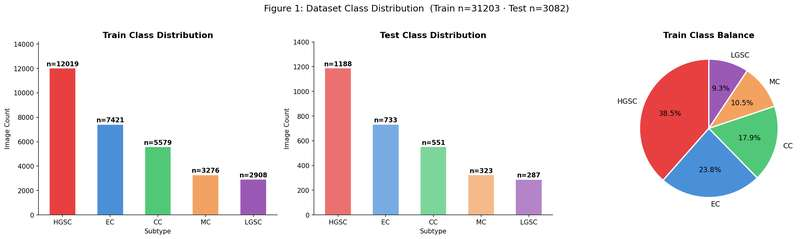

Saved: fig_01_class_distribution.png

  Cell 4b complete.


In [ ]:
# ── Cell 4b: Class Distribution — Bar + Pie ───────────────────────────────────

colors = [PALETTE[s] for s in SUBTYPES]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# ── Train bar ─────────────────────────────────────────────────────────────────
bars = axes[0].bar(SUBTYPES, TRAIN_COUNTS,
                   color=colors, edgecolor='white', width=0.55)
axes[0].set_title('Train Class Distribution', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Image Count')
axes[0].set_xlabel('Subtype')
for bar, val in zip(bars, TRAIN_COUNTS):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + max(TRAIN_COUNTS) * 0.015,
        f'n={val}', ha='center', fontsize=10, fontweight='bold'
    )
axes[0].set_ylim(0, max(TRAIN_COUNTS) * 1.18)

# ── Test bar ──────────────────────────────────────────────────────────────────
bars2 = axes[1].bar(SUBTYPES, TEST_COUNTS,
                    color=colors, edgecolor='white', width=0.55, alpha=0.75)
axes[1].set_title('Test Class Distribution', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Image Count')
axes[1].set_xlabel('Subtype')
for bar, val in zip(bars2, TEST_COUNTS):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + max(TEST_COUNTS) * 0.015,
        f'n={val}', ha='center', fontsize=10, fontweight='bold'
    )
axes[1].set_ylim(0, max(TEST_COUNTS) * 1.18)

# ── Pie ───────────────────────────────────────────────────────────────────────
axes[2].pie(
    TRAIN_COUNTS,
    labels=SUBTYPES,
    colors=colors,
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2},
    textprops={'fontsize': 11}
)
axes[2].set_title('Train Class Balance', fontsize=13, fontweight='bold')

plt.suptitle(
    f'Figure 1: Dataset Class Distribution  '
    f'(Train n={sum(TRAIN_COUNTS)} · Test n={sum(TEST_COUNTS)})',
    fontsize=14, y=1.02
)
plt.tight_layout()
plt.savefig(CHECKPOINT_DIR / 'fig_01_class_distribution.png',
            bbox_inches='tight', dpi=150)
plt.show()
print('Saved: fig_01_class_distribution.png')
print('\n  Cell 4b complete.')

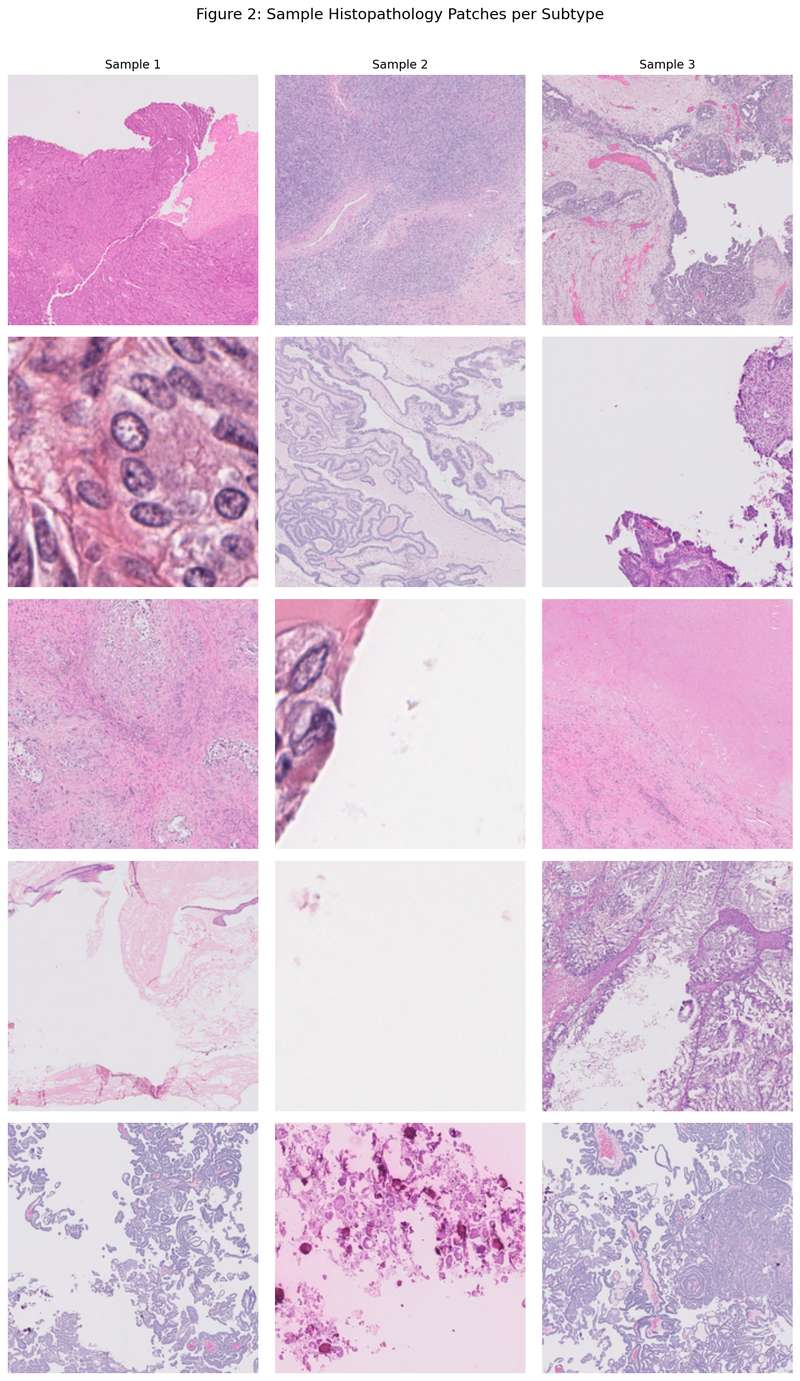

Saved: fig_02_sample_grid.png

  Cell 4c complete.


In [ ]:
# ── Cell 4c: Sample Image Grid — 3 Images per Subtype ────────────────────────

N_SAMPLES = 3

fig, axes = plt.subplots(NUM_CLASSES, N_SAMPLES,
                          figsize=(N_SAMPLES * 3.5, NUM_CLASSES * 3.5))

for row, (sub, idx) in enumerate(zip(SUBTYPES, range(NUM_CLASSES))):
    sub_paths = [p for p, l in zip(train_paths, train_labels) if l == idx]
    random.shuffle(sub_paths)
    selected  = sub_paths[:N_SAMPLES]

    for col, img_path in enumerate(selected):
        img = cv2.imread(str(img_path))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (224, 224), interpolation=cv2.INTER_AREA)

        ax = axes[row][col]
        ax.imshow(img)
        ax.axis('off')

        if col == 0:
            ax.set_ylabel(
                sub, fontsize=12, fontweight='bold',
                rotation=0, labelpad=55, va='center',
                color=PALETTE[sub]
            )
        if row == 0:
            ax.set_title(f'Sample {col + 1}', fontsize=11)

plt.suptitle('Figure 2: Sample Histopathology Patches per Subtype',
             fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig(CHECKPOINT_DIR / 'fig_02_sample_grid.png',
            bbox_inches='tight', dpi=150)
plt.show()
print('Saved: fig_02_sample_grid.png')
print('\n  Cell 4c complete.')

  IMBALANCE STATISTICS — TRAIN SET
  Majority class   : HGSC  (12019 images)
  Minority class   : LGSC  (2908 images)
  Imbalance ratio  : 4.13x
  Mean per class   : 6240.6
  Std  per class   : 3320.1
  CV  (std/mean)   : 0.532
  Severity         : Severe   (>3x)


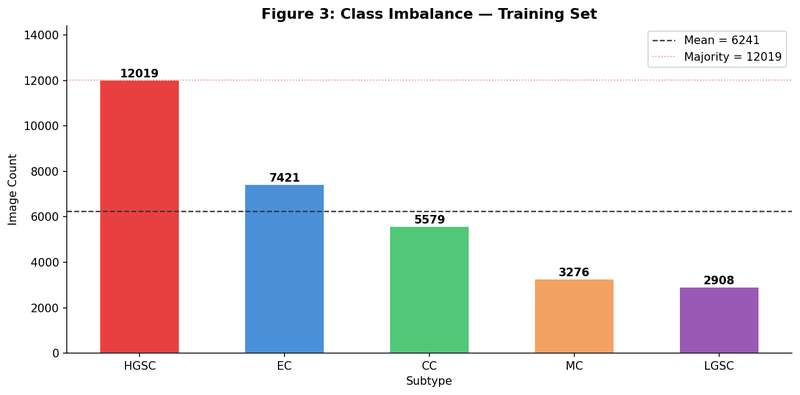

Saved: fig_03_imbalance.png

  Cell 4d complete.


In [ ]:
# ── Cell 4d: Imbalance Statistics ─────────────────────────────────────────────

train_counts_arr = np.array(TRAIN_COUNTS, dtype=float)
majority_class   = SUBTYPES[int(np.argmax(train_counts_arr))]
minority_class   = SUBTYPES[int(np.argmin(train_counts_arr))]
imbalance_ratio  = train_counts_arr.max() / train_counts_arr.min()
mean_counts      = train_counts_arr.mean()
std_counts       = train_counts_arr.std()

flag = (
    'Severe   (>3x)'     if imbalance_ratio > 3   else
    'Moderate (1.5–3x)'  if imbalance_ratio > 1.5 else
    'Mild     (<1.5x)'
)

print('=' * 55)
print('  IMBALANCE STATISTICS — TRAIN SET')
print('=' * 55)
print(f'  Majority class   : {majority_class}  '
      f'({int(train_counts_arr.max())} images)')
print(f'  Minority class   : {minority_class}  '
      f'({int(train_counts_arr.min())} images)')
print(f'  Imbalance ratio  : {imbalance_ratio:.2f}x')
print(f'  Mean per class   : {mean_counts:.1f}')
print(f'  Std  per class   : {std_counts:.1f}')
print(f'  CV  (std/mean)   : {std_counts / mean_counts:.3f}')
print(f'  Severity         : {flag}')
print('=' * 55)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(SUBTYPES, TRAIN_COUNTS,
              color=[PALETTE[s] for s in SUBTYPES],
              edgecolor='white', width=0.55)
ax.axhline(mean_counts, color='#333333', linestyle='--',
           linewidth=1.2, label=f'Mean = {mean_counts:.0f}')
ax.axhline(train_counts_arr.max(), color='#E84040', linestyle=':',
           linewidth=1.0, alpha=0.6,
           label=f'Majority = {int(train_counts_arr.max())}')

for bar, val in zip(bars, TRAIN_COUNTS):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + max(TRAIN_COUNTS) * 0.01,
        f'{val}', ha='center', fontsize=10, fontweight='bold'
    )

ax.set_title('Figure 3: Class Imbalance — Training Set',
             fontsize=13, fontweight='bold')
ax.set_ylabel('Image Count')
ax.set_xlabel('Subtype')
ax.legend(fontsize=10)
ax.set_ylim(0, max(TRAIN_COUNTS) * 1.2)
plt.tight_layout()
plt.savefig(CHECKPOINT_DIR / 'fig_03_imbalance.png',
            bbox_inches='tight', dpi=150)
plt.show()
print('Saved: fig_03_imbalance.png')
print('\n  Cell 4d complete.')

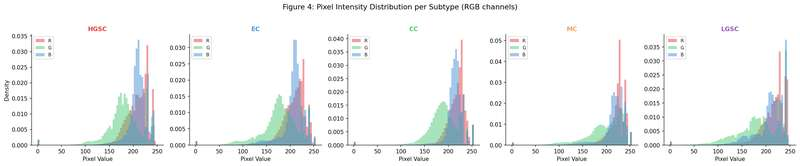

Saved: fig_04_intensity_distributions.png

  Cell 4e complete.


In [ ]:
# ── Cell 4e: Pixel Intensity Distributions per Subtype ───────────────────────

N_INTENSITY = 80   # images sampled per subtype for speed

fig, axes = plt.subplots(1, NUM_CLASSES, figsize=(20, 4), sharey=False)

for idx, (sub, ax) in enumerate(zip(SUBTYPES, axes)):
    sub_paths = [p for p, l in zip(train_paths, train_labels) if l == idx]
    random.shuffle(sub_paths)
    sampled   = sub_paths[:N_INTENSITY]

    r_vals, g_vals, b_vals = [], [], []
    for p in sampled:
        img = cv2.imread(str(p))
        if img is None:
            continue
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (64, 64), interpolation=cv2.INTER_AREA)
        r_vals.append(img[:, :, 0].flatten())
        g_vals.append(img[:, :, 1].flatten())
        b_vals.append(img[:, :, 2].flatten())

    r_vals = np.concatenate(r_vals)
    g_vals = np.concatenate(g_vals)
    b_vals = np.concatenate(b_vals)

    for vals, label, col in zip(
        [r_vals, g_vals, b_vals],
        ['R', 'G', 'B'],
        ['#E84040', '#50C878', '#4A90D9']
    ):
        ax.hist(vals, bins=64, alpha=0.5, color=col,
                label=label, density=True, edgecolor='none')

    ax.set_title(sub, fontsize=11, fontweight='bold', color=PALETTE[sub])
    ax.set_xlabel('Pixel Value')
    if idx == 0:
        ax.set_ylabel('Density')
    ax.legend(fontsize=8)
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)

plt.suptitle(
    'Figure 4: Pixel Intensity Distribution per Subtype (RGB channels)',
    fontsize=13, y=1.02
)
plt.tight_layout()
plt.savefig(CHECKPOINT_DIR / 'fig_04_intensity_distributions.png',
            bbox_inches='tight', dpi=150)
plt.show()
print('Saved: fig_04_intensity_distributions.png')
print('\n  Cell 4e complete.')

In [ ]:
# ── Cell 4f: EDA Summary ──────────────────────────────────────────────────────

print('=' * 55)
print('  EDA SUMMARY')
print('=' * 55)
print(f'  Total train images   : {sum(TRAIN_COUNTS)}')
print(f'  Total test  images   : {sum(TEST_COUNTS)}')
print('-' * 55)
for sub, tr, te in zip(SUBTYPES, TRAIN_COUNTS, TEST_COUNTS):
    pct = tr / sum(TRAIN_COUNTS) * 100
    print(f'  {sub:<6}  train={tr:<5}  test={te:<5}  ({pct:.1f}%)')
print('-' * 55)
print(f'  Imbalance ratio      : {imbalance_ratio:.2f}x  [{flag}]')
print(f'  Majority class       : {majority_class}')
print(f'  Minority class       : {minority_class}')
print(f'  Figures saved        : 4')
print('=' * 55)
print('\n  Cell 4f complete — EDA done.')

  EDA SUMMARY
  Total train images   : 31203
  Total test  images   : 3082
-------------------------------------------------------
  HGSC    train=12019  test=1188   (38.5%)
  EC      train=7421   test=733    (23.8%)
  CC      train=5579   test=551    (17.9%)
  MC      train=3276   test=323    (10.5%)
  LGSC    train=2908   test=287    (9.3%)
-------------------------------------------------------
  Imbalance ratio      : 4.13x  [Severe   (>3x)]
  Majority class       : HGSC
  Minority class       : LGSC
  Figures saved        : 4

  Cell 4f complete — EDA done.


## Section 2 - Utilities

### Dataset Utilities
### Stream A - Ovarian Cancer Histopathology
---
**This section covers:**
- `OvarianDataset` class (paths · labels · transform · pre_fn · input_size)
- Transform pipelines for 128 · 224 · 384 px resolutions
- Preprocessing functions (CLAHE · Macenko stain normalisation · combined)
- `make_loader` factory + `make_weighted_sampler`
- Effective-number class weights (Cui et al. 2019)
- Shared test loader (fixed for the entire notebook)

In [ ]:
# ── Cell 5: OvarianDataset Class ──────────────────────────────────────────────

class OvarianDataset(Dataset):
    """
    Histopathology patch dataset for ovarian cancer subtype classification.

    Parameters
    ----------
    paths    : list of Path  — image file paths
    labels   : list of int   — integer class indices (0–4)
    transform: callable      — torchvision transform applied after preprocessing
    pre_fn   : callable|None — optional preprocessing fn (CLAHE, stain norm)
                               applied BEFORE resize, at original resolution
    input_size: int          — target spatial resolution after resize
    """

    def __init__(self, paths, labels, transform,
                 pre_fn=None, input_size=224):
        self.paths      = paths
        self.labels     = labels
        self.transform  = transform
        self.pre_fn     = pre_fn
        self.input_size = input_size

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        img = cv2.imread(str(self.paths[i]))

        if img is None:
            img = np.zeros(
                (self.input_size, self.input_size, 3), dtype=np.uint8
            )
        else:
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        # Preprocessing applied at original resolution before resize
        if self.pre_fn is not None:
            img = self.pre_fn(img)

        img = cv2.resize(
            img,
            (self.input_size, self.input_size),
            interpolation=cv2.INTER_AREA
        )

        return self.transform(img), self.labels[i]


print('OvarianDataset defined.')

OvarianDataset defined.


In [ ]:
# ── Cell 6: Transform Pipelines ───────────────────────────────────────────────
# One augmentation + one evaluation transform per resolution.
# Augmentation transforms include resize as final step to clean
# up any interpolation artefacts introduced by geometric ops.

_MEAN = [0.485, 0.456, 0.406]
_STD  = [0.229, 0.224, 0.225]


def make_transforms(size: int):
    """
    Returns (aug_transform, eval_transform) for a given input resolution.
    aug_transform  — used on the training set
    eval_transform — used on validation / test set (no geometric augmentation)
    """
    aug = transforms.Compose([
        transforms.ToPILImage(),
        transforms.RandomHorizontalFlip(),
        transforms.RandomVerticalFlip(),
        transforms.RandomRotation(20),
        transforms.RandomAffine(degrees=0, shear=10),
        transforms.ColorJitter(
            brightness=0.2, contrast=0.2, saturation=0.1
        ),
        transforms.Resize((size, size)),
        transforms.ToTensor(),
        transforms.Normalize(_MEAN, _STD),
    ])

    evl = transforms.Compose([
        transforms.ToPILImage(),
        transforms.ToTensor(),
        transforms.Normalize(_MEAN, _STD),
    ])

    return aug, evl


# Pre-build transforms for every resolution used in the notebook
AUG_128,  EVL_128  = make_transforms(128)
AUG_224,  EVL_224  = make_transforms(224)
AUG_384,  EVL_384  = make_transforms(384)

print('Transform pipelines defined.')
print(f'  Resolutions ready : 128 · 224 · 384')

Transform pipelines defined.
  Resolutions ready : 128 · 224 · 384


In [ ]:
# ── Cell 7: Preprocessing Functions ───────────────────────────────────────────
# All functions operate on uint8 RGB numpy arrays and return uint8 RGB.
# Applied inside OvarianDataset.__getitem__ BEFORE resize.

# ── 7.1  CLAHE ────────────────────────────────────────────────────────────────
def apply_clahe(img: np.ndarray,
                clip_limit: float = 2.0,
                tile_grid: tuple  = (8, 8)) -> np.ndarray:
    """
    Contrast-Limited Adaptive Histogram Equalisation.
    Applied per channel in LAB colour space to preserve colour balance.
    """
    lab   = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid)
    lab[:, :, 0] = clahe.apply(lab[:, :, 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)


# ── 7.2  Macenko Stain Normalisation ─────────────────────────────────────────
# Fit the normaliser once on a reference image (first HGSC train image).
# The fitted normaliser is then passed as pre_fn to OvarianDataset.

def _build_stain_normaliser(reference_path: Path):
    """
    Fit a Macenko stain normaliser on a single reference patch.
    Returns a callable that accepts and returns uint8 RGB numpy arrays.
    """
    ref_img = cv2.imread(str(reference_path))
    ref_img = cv2.cvtColor(ref_img, cv2.COLOR_BGR2RGB)

    normaliser = torchstain.normalizers.MacenkoNormalizer(backend='numpy')
    normaliser.fit(ref_img)

    def _normalise(img: np.ndarray) -> np.ndarray:
        try:
            norm, _, _ = normaliser.normalize(img, stains=False)
            return norm.astype(np.uint8)
        except Exception:
            # Fallback: return original if normalisation fails
            return img

    return _normalise


def _build_clahe_and_stain(reference_path: Path):
    """Combined: CLAHE first, then Macenko stain normalisation."""
    stain_fn = _build_stain_normaliser(reference_path)

    def _combined(img: np.ndarray) -> np.ndarray:
        img = apply_clahe(img)
        img = stain_fn(img)
        return img

    return _combined


# ── 7.3  Build all preprocessing functions ───────────────────────────────────
# Reference image: first available HGSC training patch
_ref_path = next((TRAIN_PATH / 'HGSC').glob('*.png'),
                  next((TRAIN_PATH / 'HGSC').glob('*.jpg'), None))

if _ref_path is None:
    raise FileNotFoundError(
        'No reference image found in TRAIN_PATH/HGSC — '
        'check your data directory.'
    )

print(f'Stain normaliser reference : {_ref_path.name}')

PRE_FN = {
    'none'   : None,
    'clahe'  : apply_clahe,
    'stain'  : _build_stain_normaliser(_ref_path),
    'combined': _build_clahe_and_stain(_ref_path),
}

print('=' * 55)
print('  PREPROCESSING FUNCTIONS')
print('=' * 55)
for name in PRE_FN:
    status = 'identity (no-op)' if PRE_FN[name] is None else 'ready'
    print(f'  {name:<12} : {status}')
print('=' * 55)
print('Preprocessing functions defined.')

Stain normaliser reference : 10729.png
  PREPROCESSING FUNCTIONS
  none         : identity (no-op)
  clahe        : ready
  stain        : ready
  combined     : ready
Preprocessing functions defined.


In [ ]:
# ── Cell 8: DataLoader Factory ────────────────────────────────────────────────

def make_loader(dataset, batch_size: int,
                shuffle: bool = True,
                sampler=None) -> DataLoader:
    """
    Wraps a dataset in a DataLoader with project-wide settings.
    If sampler is provided, shuffle is automatically disabled.
    """
    _ctx = 'fork' if NUM_WORKERS > 0 else None

    return DataLoader(
        dataset,
        batch_size            = batch_size,
        shuffle               = (shuffle and sampler is None),
        sampler               = sampler,
        num_workers           = NUM_WORKERS,
        pin_memory            = True,
        persistent_workers    = (NUM_WORKERS > 0),
        multiprocessing_context = _ctx,
    )


def make_weighted_sampler(labels: list) -> WeightedRandomSampler:
    """
    Inverse-frequency WeightedRandomSampler.
    Draws len(labels) samples per epoch with replacement,
    balancing all classes regardless of their raw counts.
    """
    counts         = np.bincount(labels)
    class_weights  = 1.0 / counts.astype(float)
    sample_weights = np.array([class_weights[l] for l in labels])

    return WeightedRandomSampler(
        weights     = torch.DoubleTensor(sample_weights),
        num_samples = len(sample_weights),
        replacement = True,
    )


print('make_loader and make_weighted_sampler defined.')

make_loader and make_weighted_sampler defined.


In [ ]:
# ── Cell 9: Class Weights + Shared Test Loader ────────────────────────────────
# These are fixed for the entire notebook.
# Test loader uses EVL_224 — no augmentation, no preprocessing fn.

# ── 9.1  Effective-Number class weights (Cui et al. 2019) ─────────────────────
_beta       = 0.9999
_samples    = np.array(TRAIN_COUNTS, dtype=float)
_eff_num    = 1.0 - np.power(_beta, _samples)
_weights    = (1.0 - _beta) / _eff_num
_weights    = _weights / _weights.sum() * NUM_CLASSES

EFF_NUM_WEIGHTS = torch.FloatTensor(_weights).to(device)

print('=' * 55)
print('  EFFECTIVE-NUMBER CLASS WEIGHTS  (β=0.9999)')
print('=' * 55)
for sub, w in zip(SUBTYPES, _weights):
    print(f'  {sub:<6} : {w:.4f}')
print('=' * 55)

# ── 9.2  Shared test loader ───────────────────────────────────────────────────
_test_ds = OvarianDataset(
    test_paths, test_labels,
    transform  = EVL_224,
    pre_fn     = None,
    input_size = 224,
)

TEST_LOADER = make_loader(_test_ds, batch_size=BASE_BATCH, shuffle=False)

print(f'\n  Test set   : {len(_test_ds)} images')
print(f'  Batches    : {len(TEST_LOADER)}')
print('\n  Cell 9 complete — shared utilities ready.')

  EFFECTIVE-NUMBER CLASS WEIGHTS  (β=0.9999)
  HGSC   : 0.5408
  EC     : 0.7219
  CC     : 0.8845
  MC     : 1.3539
  LGSC   : 1.4988

  Test set   : 3082 images
  Batches    : 49

  Cell 9 complete — shared utilities ready.


### Shared Training Utilities
### Stream A - Ovarian Cancer Histopathology
---
**This section covers:**
- `train_model()` - AMP · OneCycleLR · early stopping · epoch print
- `evaluate()` - classification report · confusion matrix
- `plot_training_curves()` - loss + accuracy overlay
- `plot_roc_auc()` - one-vs-rest per class + macro average
- `GradCAM` class - hook-based · last backbone stage
- `show_gradcam()` - grid of originals + overlays per subtype

In [ ]:
# ── Cell 10: train_model() ────────────────────────────────────────────────────

def train_model(model, train_loader, test_loader,
                epochs, label, criterion,
                backbone_lr=2e-5, head_lr=2e-4,
                patience=10, scheduler_override=None):
    """
    Generic training loop.
    Returns dict with best val_acc, macro_f1, ckpt path, history.
    """
    bb_p, ot_p = model.get_param_groups()

    optimizer = optim.AdamW(
        [{'params': bb_p, 'lr': backbone_lr},
         {'params': ot_p, 'lr': head_lr}],
        weight_decay=1e-4
    )

    if scheduler_override is not None:
        scheduler = scheduler_override
    else:
        scheduler = OneCycleLR(
            optimizer,
            max_lr          = [backbone_lr * 5, head_lr * 5],
            steps_per_epoch = len(train_loader),
            epochs          = epochs,
            pct_start       = 0.1,
            anneal_strategy = 'cos'
        )

    scaler    = torch.cuda.amp.GradScaler()
    ckpt_path = CHECKPOINT_DIR / f'best_{label}.pth'

    best_acc, best_f1, no_imp = 0.0, 0.0, 0
    history = {
        'train_loss': [], 'train_acc': [],
        'val_acc'   : [], 'macro_f1' : []
    }
    t0_total = time.time()

    n_p = sum(p.numel() for p in model.parameters()) / 1e6
    print(f'\n{"=" * 65}')
    print(f'  {label}  |  {epochs} ep  |  {n_p:.1f}M params')
    print(f'  Criterion : {criterion.__class__.__name__}')
    print(f'  Train     : {len(train_loader.dataset)}  |  '
          f'Test : {len(test_loader.dataset)}')
    print(f'{"=" * 65}')

    for ep in range(1, epochs + 1):
        model.train()
        running_loss   = 0.0
        train_correct  = 0
        total_train    = 0
        t0 = time.time()

        for imgs, lbls in train_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            optimizer.zero_grad(set_to_none=True)

            with torch.cuda.amp.autocast():
                out  = model(imgs)
                loss = criterion(out, lbls)

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()

            running_loss  += loss.item()
            preds          = out.argmax(1)
            train_correct += (preds == lbls).sum().item()
            total_train   += lbls.size(0)

        # ── Validation ────────────────────────────────────────────────────────
        model.eval()
        correct    = 0
        total      = 0
        all_preds  = []
        all_labels = []

        with torch.no_grad():
            for imgs, lbls in test_loader:
                imgs, lbls = imgs.to(device), lbls.to(device)
                with torch.cuda.amp.autocast():
                    preds = model(imgs).argmax(1)
                correct    += (preds == lbls).sum().item()
                total      += lbls.size(0)
                all_preds .extend(preds.cpu().numpy())
                all_labels.extend(lbls.cpu().numpy())

        train_acc = 100. * train_correct / total_train
        val_acc   = 100. * correct / total
        macro_f1  = f1_score(all_labels, all_preds,
                             average='macro', zero_division=0)
        avg_loss  = running_loss / len(train_loader)

        history['train_loss'].append(avg_loss)
        history['train_acc'] .append(train_acc)
        history['val_acc']   .append(val_acc)
        history['macro_f1']  .append(macro_f1)

        if val_acc > best_acc:
            best_acc = val_acc
            best_f1  = macro_f1
            torch.save(model.state_dict(), ckpt_path)
            no_imp = 0
        else:
            no_imp += 1

        tag = f' | No improve: {no_imp}/{patience}' if no_imp else ''
        print(f'  Ep {ep:>3}/{epochs} | '
              f'Loss:{avg_loss:.4f} | '
              f'Train:{train_acc:.2f}% | '
              f'Val:{val_acc:.2f}% | '
              f'LR:{optimizer.param_groups[1]["lr"]:.2e} | '
              f'Best:{best_acc:.2f}%{tag} | '
              f'{time.time() - t0:.1f}s')

        if no_imp >= patience:
            print(f'\n  Early stop at epoch {ep}.')
            break

    total_time = time.time() - t0_total
    print(f'\n  {label}  |  Best Val: {best_acc:.2f}%  |  '
          f'Macro F1: {best_f1:.4f}  |  '
          f'Time: {total_time / 60:.1f} min')

    return {
        'label'          : label,
        'val_acc'        : best_acc,
        'macro_f1'       : best_f1,
        'ckpt'           : ckpt_path,
        'history'        : history,
        'total_time_min' : total_time / 60,
    }

print('train_model() defined.')

train_model() defined.


In [ ]:
# ── Cell 11: evaluate() ───────────────────────────────────────────────────────

def evaluate(model, loader, ckpt_path, label):
    """
    Load best checkpoint and run full evaluation.
    Prints classification report + saves confusion matrix figure.
    Returns dict with macro_f1, val_acc, per_class_f1.
    """
    model.load_state_dict(torch.load(ckpt_path, map_location=device))
    model.eval()

    all_preds  = []
    all_labels = []
    all_probs  = []

    with torch.no_grad():
        for imgs, lbls in loader:
            imgs = imgs.to(device)
            with torch.cuda.amp.autocast():
                logits = model(imgs)
                probs  = torch.softmax(logits, dim=1)
                preds  = logits.argmax(1)
            all_preds .extend(preds.cpu().numpy())
            all_labels.extend(lbls.numpy())
            all_probs .extend(probs.cpu().numpy())

    all_probs = np.array(all_probs)
    acc       = accuracy_score(all_labels, all_preds) * 100
    macro_f1  = f1_score(all_labels, all_preds,
                         average='macro', zero_division=0)
    per_class = f1_score(all_labels, all_preds,
                         average=None, zero_division=0)

    print(f'\n{"=" * 55}')
    print(f'  {label}')
    print(f'{"=" * 55}')
    print(classification_report(
        all_labels, all_preds,
        target_names=SUBTYPES, digits=4, zero_division=0
    ))

    # ── Confusion matrix ──────────────────────────────────────────────────────
    cm = confusion_matrix(all_labels, all_preds)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    sns.heatmap(cm, annot=True, fmt='d',
                xticklabels=SUBTYPES, yticklabels=SUBTYPES,
                cmap='Blues', ax=axes[0])
    axes[0].set_title(f'Confusion Matrix (Counts) — {label}',
                      fontsize=12, fontweight='bold')
    axes[0].set_xlabel('Predicted')
    axes[0].set_ylabel('True')

    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
    sns.heatmap(cm_norm, annot=True, fmt='.2f',
                xticklabels=SUBTYPES, yticklabels=SUBTYPES,
                cmap='Blues', vmin=0, vmax=1, ax=axes[1])
    axes[1].set_title(f'Confusion Matrix (Normalised) — {label}',
                      fontsize=12, fontweight='bold')
    axes[1].set_xlabel('Predicted')
    axes[1].set_ylabel('True')

    plt.tight_layout()
    fname = CHECKPOINT_DIR / f'confusion_{label}.png'
    plt.savefig(fname, bbox_inches='tight', dpi=150)
    plt.show()
    print(f'Saved: confusion_{label}.png')

    return {
        'label'        : label,
        'val_acc'      : acc,
        'macro_f1'     : macro_f1,
        'per_class_f1' : dict(zip(SUBTYPES, per_class)),
        'probs'        : all_probs,
        'labels'       : all_labels,
        'preds'        : all_preds,
    }

print('evaluate() defined.')

evaluate() defined.


In [ ]:
# ── Cell 12: plot_training_curves() ───────────────────────────────────────────

def plot_training_curves(history, label):
    """
    Plot training loss + accuracy curves on a twin-axis figure.
    Saves figure to CHECKPOINT_DIR.
    """
    epochs_ran = range(1, len(history['train_loss']) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # ── Loss ──────────────────────────────────────────────────────────────────
    axes[0].plot(epochs_ran, history['train_loss'],
                 color='#E84040', linewidth=1.8, label='Train Loss')
    axes[0].set_title(f'Loss Curve — {label}',
                      fontsize=12, fontweight='bold')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].legend(fontsize=10)

    # ── Accuracy ──────────────────────────────────────────────────────────────
    axes[1].plot(epochs_ran, history['train_acc'],
                 color='#4A90D9', linewidth=1.8, label='Train Acc')
    axes[1].plot(epochs_ran, history['val_acc'],
                 color='#E84040', linewidth=1.8,
                 linestyle='--', label='Val Acc')
    axes[1].plot(epochs_ran, [m * 100 for m in history['macro_f1']],
                 color='#50C878', linewidth=1.5,
                 linestyle=':', label='Macro F1 ×100')
    axes[1].set_title(f'Accuracy Curve — {label}',
                      fontsize=12, fontweight='bold')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('%')
    axes[1].legend(fontsize=10)

    for ax in axes:
        for spine in ['top', 'right']:
            ax.spines[spine].set_visible(False)

    plt.suptitle(f'Figure: Training Curves — {label}',
                 fontsize=13, y=1.02)
    plt.tight_layout()
    fname = CHECKPOINT_DIR / f'curves_{label}.png'
    plt.savefig(fname, bbox_inches='tight', dpi=150)
    plt.show()
    print(f'Saved: curves_{label}.png')

print('plot_training_curves() defined.')

plot_training_curves() defined.


In [ ]:
# ── Cell 13: plot_roc_auc() ───────────────────────────────────────────────────

def plot_roc_auc(probs, labels, label):
    """
    One-vs-rest ROC curves for each class + macro average.
    Saves figure to CHECKPOINT_DIR.
    Returns dict of per-class and macro AUC scores.
    """
    labels_bin = label_binarize(labels, classes=list(range(NUM_CLASSES)))
    probs      = np.array(probs)

    fig, ax = plt.subplots(figsize=(9, 7))

    auc_scores = {}
    for i, sub in enumerate(SUBTYPES):
        fpr, tpr, _ = roc_curve(labels_bin[:, i], probs[:, i])
        roc_auc     = auc(fpr, tpr)
        auc_scores[sub] = roc_auc
        ax.plot(fpr, tpr, linewidth=2,
                color=list(PALETTE.values())[i],
                label=f'{sub}  (AUC = {roc_auc:.4f})')

    # ── Macro average ─────────────────────────────────────────────────────────
    all_fpr  = np.unique(np.concatenate(
        [roc_curve(labels_bin[:, i], probs[:, i])[0]
         for i in range(NUM_CLASSES)]
    ))
    mean_tpr = np.zeros_like(all_fpr)
    for i in range(NUM_CLASSES):
        fpr, tpr, _ = roc_curve(labels_bin[:, i], probs[:, i])
        mean_tpr   += np.interp(all_fpr, fpr, tpr)
    mean_tpr      /= NUM_CLASSES
    macro_auc       = auc(all_fpr, mean_tpr)
    auc_scores['macro'] = macro_auc

    ax.plot(all_fpr, mean_tpr,
            color='#333333', linewidth=2.5, linestyle='--',
            label=f'Macro avg  (AUC = {macro_auc:.4f})')
    ax.plot([0, 1], [0, 1],
            color='#AAAAAA', linewidth=1.0, linestyle=':')

    ax.set_title(f'ROC Curves (One-vs-Rest) — {label}',
                 fontsize=13, fontweight='bold')
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.legend(fontsize=10, loc='lower right')
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)

    plt.tight_layout()
    fname = CHECKPOINT_DIR / f'roc_{label}.png'
    plt.savefig(fname, bbox_inches='tight', dpi=150)
    plt.show()
    print(f'Saved: roc_{label}.png')

    print(f'\n{"=" * 55}')
    print(f'  ROC-AUC SCORES — {label}')
    print(f'{"=" * 55}')
    for sub in SUBTYPES:
        print(f'  {sub:<6} : {auc_scores[sub]:.4f}')
    print(f'  {"Macro":<6} : {macro_auc:.4f}')
    print(f'{"=" * 55}')

    return auc_scores

print('plot_roc_auc() defined.')

plot_roc_auc() defined.


In [ ]:
# ── Cell 14: GradCAM + show_gradcam() ────────────────────────────────────────

class GradCAM:
    """
    Hook-based Grad-CAM using the last stage of the ConvNeXt backbone.
    Works with any model that exposes a `backbone` attribute.
    """
    def __init__(self, model, target_layer):
        self.model       = model
        self.activations = None
        self.gradients   = None
        self._fwd = target_layer.register_forward_hook(
            lambda m, i, o: setattr(self, 'activations', o.detach())
        )
        self._bwd = target_layer.register_full_backward_hook(
            lambda m, gi, go: setattr(self, 'gradients', go[0].detach())
        )

    def generate(self, tensor, cls_idx):
        self.model.zero_grad()
        out = self.model(tensor)
        out[0, cls_idx].backward()
        weights = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam     = F.relu((weights * self.activations).sum(dim=1).squeeze())
        cam     = cam.cpu().numpy()
        cam     = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam

    def remove(self):
        self._fwd.remove()
        self._bwd.remove()


def show_gradcam(model, test_root, label, n_per_class=2):
    """
    Grad-CAM grid: n_per_class originals + overlays per subtype.
    Saves figure to CHECKPOINT_DIR.
    """
    model.eval()
    _, evl_tf = make_transforms(224)
    gc = GradCAM(model, model.stage_4)

    fig, axes = plt.subplots(
        NUM_CLASSES, n_per_class * 2,
        figsize=(n_per_class * 2 * 3.5, NUM_CLASSES * 3.5)
    )
    fig.suptitle(f'Grad-CAM — {label}', fontsize=14, fontweight='bold')

    for row, (sub, cls_idx) in enumerate(zip(SUBTYPES, range(NUM_CLASSES))):
        img_paths = (
            list((test_root / sub).glob('*.png')) +
            list((test_root / sub).glob('*.jpg'))
        )
        random.shuffle(img_paths)
        shown = 0

        for p in img_paths:
            if shown >= n_per_class:
                break
            raw = cv2.imread(str(p))
            if raw is None:
                continue
            raw     = cv2.cvtColor(raw, cv2.COLOR_BGR2RGB)
            raw_224 = cv2.resize(raw, (224, 224), interpolation=cv2.INTER_AREA)

            tensor = evl_tf(raw_224).unsqueeze(0).to(device)
            tensor.requires_grad_(True)

            with torch.enable_grad():
                cam = gc.generate(tensor, cls_idx)

            cam_r   = cv2.resize(cam, (224, 224))
            heatmap = cv2.applyColorMap(
                (cam_r * 255).astype(np.uint8), cv2.COLORMAP_JET
            )
            heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
            overlay = (0.5 * raw_224 + 0.5 * heatmap).astype(np.uint8)

            col = shown * 2
            axes[row][col    ].imshow(raw_224)
            axes[row][col    ].set_title(f'{sub} — Original', fontsize=9)
            axes[row][col    ].axis('off')
            axes[row][col + 1].imshow(overlay)
            axes[row][col + 1].set_title(f'{sub} — Grad-CAM', fontsize=9)
            axes[row][col + 1].axis('off')
            shown += 1

    plt.tight_layout()
    fname = CHECKPOINT_DIR / f'gradcam_{label}.png'
    plt.savefig(fname, bbox_inches='tight', dpi=150)
    plt.show()
    gc.remove()
    print(f'Saved: gradcam_{label}.png')

print('GradCAM and show_gradcam() defined.')

GradCAM and show_gradcam() defined.


### Baseline Models
### Stream A - Ovarian Cancer Histopathology
---
**This section covers:**
- VGG-16
- ResNet-50
- DenseNet-121
- EfficientNet-B4
- MobileNetV3-Large
- ViT-B/16
- Swin-T
- DeiT-S

All models loaded with pretrained ImageNet weights.
Final classification head replaced for 5-class output.
Differential learning rates applied via `get_param_groups()`.

In [ ]:
# ── Cell 15: Baseline — VGG-16 ────────────────────────────────────────────────

class VGG16Classifier(nn.Module):
    """
    VGG-16 pretrained on ImageNet.
    Final classifier layer replaced for NUM_CLASSES output.
    """
    def __init__(self, num_classes=NUM_CLASSES, drop=0.3):
        super().__init__()
        base                  = models.vgg16(
            weights=models.VGG16_Weights.IMAGENET1K_V1
        )
        self.backbone         = base.features
        self.avgpool          = base.avgpool
        self.flatten          = nn.Flatten()

        in_features           = base.classifier[0].in_features
        base.classifier[-1]   = nn.Linear(
            base.classifier[-1].in_features, num_classes
        )
        base.classifier[2]    = nn.Dropout(drop)
        base.classifier[5]    = nn.Dropout(drop)
        self.classifier       = base.classifier

    def get_param_groups(self):
        bb = list(self.backbone.parameters())
        hd = list(self.classifier.parameters())
        return bb, hd

    def forward(self, x):
        x = self.backbone(x)
        x = self.avgpool(x)
        x = self.flatten(x)
        return self.classifier(x)


_m = VGG16Classifier().to(device)
with torch.no_grad():
    _o = _m(torch.zeros(2, 3, 224, 224).to(device))
print(f'VGG16Classifier       | Output: {_o.shape} | '
      f'Params: {sum(p.numel() for p in _m.parameters())/1e6:.1f}M')
del _m, _o
torch.cuda.empty_cache()
print('Cell 15 complete.')

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


VGG16Classifier       | Output: torch.Size([2, 5]) | Params: 134.3M
Cell 15 complete.


In [ ]:
# ── Cell 16: Baseline — ResNet-50 ─────────────────────────────────────────────

class ResNet50Classifier(nn.Module):
    """
    ResNet-50 pretrained on ImageNet.
    FC layer replaced for NUM_CLASSES output.
    """
    def __init__(self, num_classes=NUM_CLASSES, drop=0.3):
        super().__init__()
        base      = models.resnet50(
            weights=models.ResNet50_Weights.IMAGENET1K_V2
        )
        self.backbone = nn.Sequential(*list(base.children())[:-2])
        self.pool     = nn.AdaptiveAvgPool2d((1, 1))
        self.head     = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(drop),
            nn.Linear(2048, num_classes)
        )

    def get_param_groups(self):
        bb = list(self.backbone.parameters())
        hd = list(self.head.parameters()) + list(self.pool.parameters())
        return bb, hd

    def forward(self, x):
        x = self.backbone(x)
        x = self.pool(x)
        return self.head(x)


_m = ResNet50Classifier().to(device)
with torch.no_grad():
    _o = _m(torch.zeros(2, 3, 224, 224).to(device))
print(f'ResNet50Classifier    | Output: {_o.shape} | '
      f'Params: {sum(p.numel() for p in _m.parameters())/1e6:.1f}M')
del _m, _o
torch.cuda.empty_cache()
print('Cell 16 complete.')

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


ResNet50Classifier    | Output: torch.Size([2, 5]) | Params: 23.5M
Cell 16 complete.


In [ ]:
# ── Cell 17: Baseline — DenseNet-121 ──────────────────────────────────────────

class DenseNet121Classifier(nn.Module):
    """
    DenseNet-121 pretrained on ImageNet.
    Classifier layer replaced for NUM_CLASSES output.
    """
    def __init__(self, num_classes=NUM_CLASSES, drop=0.3):
        super().__init__()
        base          = models.densenet121(
            weights=models.DenseNet121_Weights.IMAGENET1K_V1
        )
        self.backbone = base.features
        self.pool     = nn.AdaptiveAvgPool2d((1, 1))
        self.head     = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(drop),
            nn.Linear(1024, num_classes)
        )

    def get_param_groups(self):
        bb = list(self.backbone.parameters())
        hd = list(self.head.parameters()) + list(self.pool.parameters())
        return bb, hd

    def forward(self, x):
        x = F.relu(self.backbone(x), inplace=True)
        x = self.pool(x)
        return self.head(x)


_m = DenseNet121Classifier().to(device)
with torch.no_grad():
    _o = _m(torch.zeros(2, 3, 224, 224).to(device))
print(f'DenseNet121Classifier | Output: {_o.shape} | '
      f'Params: {sum(p.numel() for p in _m.parameters())/1e6:.1f}M')
del _m, _o
torch.cuda.empty_cache()
print('Cell 17 complete.')

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


DenseNet121Classifier | Output: torch.Size([2, 5]) | Params: 7.0M
Cell 17 complete.


In [ ]:
# ── Cell 18: Baseline — EfficientNet-B4 ───────────────────────────────────────

class EfficientNetB4Classifier(nn.Module):
    """
    EfficientNet-B4 pretrained on ImageNet via timm.
    Classifier head replaced for NUM_CLASSES output.
    """
    def __init__(self, num_classes=NUM_CLASSES, drop=0.3):
        super().__init__()
        base              = timm.create_model(
            'efficientnet_b4',
            pretrained    = True,
            num_classes   = 0,       # remove original head
            drop_rate     = drop,
        )
        self.backbone     = base
        in_features       = base.num_features   # 1792 for B4
        self.head         = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Dropout(drop),
            nn.Linear(in_features, num_classes)
        )

    def get_param_groups(self):
        bb = list(self.backbone.parameters())
        hd = list(self.head.parameters())
        return bb, hd

    def forward(self, x):
        x = self.backbone.forward_features(x)
        return self.head(x)


_m = EfficientNetB4Classifier().to(device)
with torch.no_grad():
    _o = _m(torch.zeros(2, 3, 224, 224).to(device))
print(f'EfficientNetB4        | Output: {_o.shape} | '
      f'Params: {sum(p.numel() for p in _m.parameters())/1e6:.1f}M')
del _m, _o
torch.cuda.empty_cache()
print('Cell 18 complete.')

model.safetensors:   0%|          | 0.00/77.9M [00:00<?, ?B/s]

EfficientNetB4        | Output: torch.Size([2, 5]) | Params: 17.6M
Cell 18 complete.


In [ ]:
# ── Cell 19: Baseline — MobileNetV3-Large ─────────────────────────────────────

class MobileNetV3Classifier(nn.Module):
    """
    MobileNetV3-Large pretrained on ImageNet.
    Classifier replaced for NUM_CLASSES output.
    """
    def __init__(self, num_classes=NUM_CLASSES, drop=0.3):
        super().__init__()
        base              = models.mobilenet_v3_large(
            weights=models.MobileNet_V3_Large_Weights.IMAGENET1K_V2
        )
        self.backbone     = base.features
        self.avgpool      = base.avgpool
        in_features       = base.classifier[-1].in_features
        self.head         = nn.Sequential(
            nn.Flatten(),
            nn.Linear(960, 1280),
            nn.Hardswish(),
            nn.Dropout(drop),
            nn.Linear(1280, num_classes)
        )

    def get_param_groups(self):
        bb = list(self.backbone.parameters())
        hd = list(self.head.parameters()) + list(self.avgpool.parameters())
        return bb, hd

    def forward(self, x):
        x = self.backbone(x)
        x = self.avgpool(x)
        return self.head(x)


_m = MobileNetV3Classifier().to(device)
with torch.no_grad():
    _o = _m(torch.zeros(2, 3, 224, 224).to(device))
print(f'MobileNetV3Large      | Output: {_o.shape} | '
      f'Params: {sum(p.numel() for p in _m.parameters())/1e6:.1f}M')
del _m, _o
torch.cuda.empty_cache()
print('Cell 19 complete.')

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


MobileNetV3Large      | Output: torch.Size([2, 5]) | Params: 4.2M
Cell 19 complete.


In [ ]:
# ── Cell 20: Baseline — ViT-B/16 ──────────────────────────────────────────────

class ViTB16Classifier(nn.Module):
    """
    Vision Transformer ViT-B/16 pretrained on ImageNet-21k via timm.
    Classification head replaced for NUM_CLASSES output.
    Patch embedding frozen for first 5 epochs via freeze_patch_embed().
    """
    def __init__(self, num_classes=NUM_CLASSES, drop=0.3):
        super().__init__()
        self.vit          = timm.create_model(
            'vit_base_patch16_224',
            pretrained    = True,
            num_classes   = num_classes,
            drop_rate     = drop,
        )

    def freeze_patch_embed(self):
        for p in self.vit.patch_embed.parameters():
            p.requires_grad = False

    def unfreeze_patch_embed(self):
        for p in self.vit.patch_embed.parameters():
            p.requires_grad = True

    def get_param_groups(self):
        head_names = {'vit.head.weight', 'vit.head.bias'}
        bb = [p for n, p in self.named_parameters()
              if n not in head_names]
        hd = [p for n, p in self.named_parameters()
              if n in head_names]
        return bb, hd

    def forward(self, x):
        return self.vit(x)


_m = ViTB16Classifier().to(device)
with torch.no_grad():
    _o = _m(torch.zeros(2, 3, 224, 224).to(device))
print(f'ViTB16Classifier      | Output: {_o.shape} | '
      f'Params: {sum(p.numel() for p in _m.parameters())/1e6:.1f}M')
del _m, _o
torch.cuda.empty_cache()
print('Cell 20 complete.')

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

ViTB16Classifier      | Output: torch.Size([2, 5]) | Params: 85.8M
Cell 20 complete.


In [ ]:
# ── Cell 21: Baseline — Swin Transformer Tiny ─────────────────────────────────

class SwinTClassifier(nn.Module):
    """
    Swin Transformer Tiny pretrained on ImageNet-1k via timm.
    Head replaced for NUM_CLASSES output.
    """
    def __init__(self, num_classes=NUM_CLASSES, drop=0.3):
        super().__init__()
        self.swin         = timm.create_model(
            'swin_tiny_patch4_window7_224',
            pretrained    = True,
            num_classes   = num_classes,
            drop_rate     = drop,
        )

    def get_param_groups(self):
        head_names = {'swin.head.weight', 'swin.head.bias'}
        bb = [p for n, p in self.named_parameters()
              if n not in head_names]
        hd = [p for n, p in self.named_parameters()
              if n in head_names]
        return bb, hd

    def forward(self, x):
        return self.swin(x)


_m = SwinTClassifier().to(device)
with torch.no_grad():
    _o = _m(torch.zeros(2, 3, 224, 224).to(device))
print(f'SwinTClassifier       | Output: {_o.shape} | '
      f'Params: {sum(p.numel() for p in _m.parameters())/1e6:.1f}M')
del _m, _o
torch.cuda.empty_cache()
print('Cell 21 complete.')

model.safetensors:   0%|          | 0.00/114M [00:00<?, ?B/s]

SwinTClassifier       | Output: torch.Size([2, 5]) | Params: 27.5M
Cell 21 complete.


In [ ]:
# ── Cell 22: Baseline — DeiT-S ────────────────────────────────────────────────

class DeiTSClassifier(nn.Module):
    """
    DeiT-Small pretrained on ImageNet-1k via timm.
    Head replaced for NUM_CLASSES output.
    Patch embedding frozen for first 5 epochs via freeze_patch_embed().
    """
    def __init__(self, num_classes=NUM_CLASSES, drop=0.3):
        super().__init__()
        self.deit         = timm.create_model(
            'deit_small_patch16_224',
            pretrained    = True,
            num_classes   = num_classes,
            drop_rate     = drop,
        )

    def freeze_patch_embed(self):
        for p in self.deit.patch_embed.parameters():
            p.requires_grad = False

    def unfreeze_patch_embed(self):
        for p in self.deit.patch_embed.parameters():
            p.requires_grad = True

    def get_param_groups(self):
        head_names = {'deit.head.weight', 'deit.head.bias'}
        bb = [p for n, p in self.named_parameters()
              if n not in head_names]
        hd = [p for n, p in self.named_parameters()
              if n in head_names]
        return bb, hd

    def forward(self, x):
        return self.deit(x)


_m = DeiTSClassifier().to(device)
with torch.no_grad():
    _o = _m(torch.zeros(2, 3, 224, 224).to(device))
print(f'DeiTSClassifier       | Output: {_o.shape} | '
      f'Params: {sum(p.numel() for p in _m.parameters())/1e6:.1f}M')
del _m, _o
torch.cuda.empty_cache()
print('Cell 22 complete.')

model.safetensors:   0%|          | 0.00/88.2M [00:00<?, ?B/s]

DeiTSClassifier       | Output: torch.Size([2, 5]) | Params: 21.7M
Cell 22 complete.


### ConvNeXt Variants
### Stream A - Ovarian Cancer Histopathology
---
**This section covers:**
- `ConvNeXtVanilla`        - ConvNeXt-Base · stock GAP head · no attention
- `ConvNeXtSingleCBAM`     - ConvNeXt-Base · CBAM at stage 4 · GAP+GMP · MLP head
- `ConvNeXtMultiCBAM`      - ConvNeXt-Base · CBAM after stages 2 · 3 · 4 · GAP+GMP · MLP head
- `ConvNeXtFullPipeline`   - ConvNeXt-Base · Multi-CBAM · GAP+GMP · MLP head · §3 winner · §4 winner

All variants load pretrained weights from the manually downloaded `.pth` file.
Architecture built from scratch - not imported.

In [ ]:
# ── Cell 23a: CBAM Modules ────────────────────────────────────────────────────

class ChannelAttention(nn.Module):
    """
    Channel attention via squeeze-and-excitation with both
    average-pool and max-pool branches.
    """
    def __init__(self, channels, reduction=16):
        super().__init__()
        mid = max(channels // reduction, 8)
        self.avg = nn.AdaptiveAvgPool2d(1)
        self.max = nn.AdaptiveMaxPool2d(1)
        self.mlp = nn.Sequential(
            nn.Flatten(),
            nn.Linear(channels, mid, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(mid, channels, bias=False),
        )

    def forward(self, x):
        gate = torch.sigmoid(
            self.mlp(self.avg(x)) + self.mlp(self.max(x))
        )
        return x * gate.view(x.size(0), x.size(1), 1, 1)


class SpatialAttention(nn.Module):
    """
    Spatial attention via channel-wise average and max pooling
    followed by a 7×7 convolution.
    """
    def __init__(self):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, kernel_size=7,
                              padding=3, bias=False)
        self.bn   = nn.BatchNorm2d(1)

    def forward(self, x):
        avg = x.mean(dim=1, keepdim=True)
        mx  = x.max (dim=1, keepdim=True)[0]
        gate = torch.sigmoid(
            self.bn(self.conv(torch.cat([avg, mx], dim=1)))
        )
        return x * gate


class CBAM(nn.Module):
    """
    Convolutional Block Attention Module.
    Applies channel attention then spatial attention sequentially.
    """
    def __init__(self, channels, reduction=16):
        super().__init__()
        self.channel = ChannelAttention(channels, reduction)
        self.spatial = SpatialAttention()

    def forward(self, x):
        x = self.channel(x)
        x = self.spatial(x)
        return x


print('CBAM modules defined.')
print('  ChannelAttention · SpatialAttention · CBAM')

CBAM modules defined.
  ChannelAttention · SpatialAttention · CBAM


In [ ]:
# ── Cell 23b: ConvNeXtVanilla ─────────────────────────────────────────────────

class ConvNeXtVanilla(nn.Module):
    """
    ConvNeXt-Base with pretrained ImageNet weights.
    Standard GAP head — no attention, no dual pooling.
    Serves as the architectural lower-bound baseline.
    """
    def __init__(self, num_classes=NUM_CLASSES, drop=0.3):
        super().__init__()
        base = models.convnext_base(weights=None)
        base.load_state_dict(
            torch.load(str(CONVNEXT_CKPT), map_location='cpu')
        )
        self.backbone = base.features
        self.pool     = nn.AdaptiveAvgPool2d((1, 1))
        self.head     = nn.Sequential(
            nn.Flatten(),
            nn.LayerNorm(1024),
            nn.Dropout(drop),
            nn.Linear(1024, num_classes),
        )
        for m in self.head.modules():
            if isinstance(m, nn.Linear):
                nn.init.trunc_normal_(m.weight, std=0.02)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def get_param_groups(self):
        bb = list(self.backbone.parameters())
        hd = list(self.pool.parameters()) + list(self.head.parameters())
        return bb, hd

    def forward(self, x):
        x = self.backbone(x)
        x = self.pool(x)
        return self.head(x)


_m = ConvNeXtVanilla().to(device)
with torch.no_grad():
    _o = _m(torch.zeros(2, 3, 224, 224).to(device))
print(f'ConvNeXtVanilla       | Output: {_o.shape} | '
      f'Params: {sum(p.numel() for p in _m.parameters())/1e6:.1f}M')
del _m, _o
torch.cuda.empty_cache()
print('Cell 23b complete.')

ConvNeXtVanilla       | Output: torch.Size([2, 5]) | Params: 87.6M
Cell 23b complete.


In [ ]:
# ── Cell 23c: ConvNeXtSingleCBAM ──────────────────────────────────────────────

class ConvNeXtSingleCBAM(nn.Module):
    """
    ConvNeXt-Base + single CBAM applied after the final backbone stage.
    Dual pooling (GAP + GMP) concatenated → 2048-dim embedding.
    MLP head: LayerNorm → Linear → BN → GELU → Dropout → Linear.
    """
    def __init__(self, num_classes=NUM_CLASSES, drop=0.3):
        super().__init__()
        base = models.convnext_base(weights=None)
        base.load_state_dict(
            torch.load(str(CONVNEXT_CKPT), map_location='cpu')
        )
        self.backbone = base.features
        self.cbam     = CBAM(1024)
        self.gap      = nn.AdaptiveAvgPool2d((1, 1))
        self.gmp      = nn.AdaptiveMaxPool2d((1, 1))
        self.head     = nn.Sequential(
            nn.LayerNorm(2048),
            nn.Linear(2048, 512),
            nn.BatchNorm1d(512),
            nn.GELU(),
            nn.Dropout(drop),
            nn.Linear(512, num_classes),
        )
        for m in self.head.modules():
            if isinstance(m, nn.Linear):
                nn.init.trunc_normal_(m.weight, std=0.02)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def get_param_groups(self):
        bb = list(self.backbone.parameters())
        hd = (list(self.cbam.parameters()) +
              list(self.gap.parameters())  +
              list(self.gmp.parameters())  +
              list(self.head.parameters()))
        return bb, hd

    def forward(self, x):
        x   = self.backbone(x)
        x   = self.cbam(x)
        gap = self.gap(x).flatten(1)
        gmp = self.gmp(x).flatten(1)
        return self.head(torch.cat([gap, gmp], dim=1))


_m = ConvNeXtSingleCBAM().to(device)
with torch.no_grad():
    _o = _m(torch.zeros(2, 3, 224, 224).to(device))
print(f'ConvNeXtSingleCBAM    | Output: {_o.shape} | '
      f'Params: {sum(p.numel() for p in _m.parameters())/1e6:.1f}M')
del _m, _o
torch.cuda.empty_cache()
print('Cell 23c complete.')

ConvNeXtSingleCBAM    | Output: torch.Size([2, 5]) | Params: 88.8M
Cell 23c complete.


In [ ]:
# ── Cell 23d: ConvNeXtMultiCBAM ───────────────────────────────────────────────
#
# ConvNeXt-Base backbone stage layout (base.features indices):
#   0 — stem          (downsample)
#   1 — stage 1 block
#   2 — downsample
#   3 — stage 2 block   ← CBAM inserted here  (channels = 256)
#   4 — downsample
#   5 — stage 3 block   ← CBAM inserted here  (channels = 512)
#   6 — downsample
#   7 — stage 4 block   ← CBAM inserted here  (channels = 1024)
# ──────────────────────────────────────────────────────────────────────────────

class ConvNeXtMultiCBAM(nn.Module):
    """
    ConvNeXt-Base with CBAM inserted after stages 2, 3, and 4.
    Multi-scale attention operates at three spatial resolutions.
    Dual pooling (GAP + GMP) on final feature map → 2048-dim embedding.
    """
    def __init__(self, num_classes=NUM_CLASSES, drop=0.3):
        super().__init__()
        base = models.convnext_base(weights=None)
        base.load_state_dict(
            torch.load(str(CONVNEXT_CKPT), map_location='cpu')
        )
        features = base.features

        # Split backbone around CBAM insertion points
        self.stage_0_1  = nn.Sequential(features[0], features[1])
        self.down_2     = features[2]
        self.stage_2    = features[3]
        self.cbam_s2    = CBAM(256)

        self.down_3     = features[4]
        self.stage_3    = features[5]
        self.cbam_s3    = CBAM(512)

        self.down_4     = features[6]
        self.stage_4    = features[7]
        self.cbam_s4    = CBAM(1024)

        self.gap        = nn.AdaptiveAvgPool2d((1, 1))
        self.gmp        = nn.AdaptiveMaxPool2d((1, 1))
        self.head       = nn.Sequential(
            nn.LayerNorm(2048),
            nn.Linear(2048, 512),
            nn.BatchNorm1d(512),
            nn.GELU(),
            nn.Dropout(drop),
            nn.Linear(512, num_classes),
        )
        for m in self.head.modules():
            if isinstance(m, nn.Linear):
                nn.init.trunc_normal_(m.weight, std=0.02)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def get_param_groups(self):
        backbone_modules = [
            self.stage_0_1, self.down_2, self.stage_2,
            self.down_3,    self.stage_3,
            self.down_4,    self.stage_4,
        ]
        bb = [p for m in backbone_modules for p in m.parameters()]
        hd = (list(self.cbam_s2.parameters()) +
              list(self.cbam_s3.parameters()) +
              list(self.cbam_s4.parameters()) +
              list(self.gap.parameters())     +
              list(self.gmp.parameters())     +
              list(self.head.parameters()))
        return bb, hd

    def forward(self, x):
        x   = self.stage_0_1(x)
        x   = self.cbam_s2(self.stage_2(self.down_2(x)))
        x   = self.cbam_s3(self.stage_3(self.down_3(x)))
        x   = self.cbam_s4(self.stage_4(self.down_4(x)))
        gap = self.gap(x).flatten(1)
        gmp = self.gmp(x).flatten(1)
        return self.head(torch.cat([gap, gmp], dim=1))


_m = ConvNeXtMultiCBAM().to(device)
with torch.no_grad():
    _o = _m(torch.zeros(2, 3, 224, 224).to(device))
print(f'ConvNeXtMultiCBAM     | Output: {_o.shape} | '
      f'Params: {sum(p.numel() for p in _m.parameters())/1e6:.1f}M')
del _m, _o
torch.cuda.empty_cache()
print('Cell 23d complete.')

ConvNeXtMultiCBAM     | Output: torch.Size([2, 5]) | Params: 88.8M
Cell 23d complete.


In [ ]:
# ── Cell 23e: ConvNeXtFullPipeline ────────────────────────────────────────────

class ConvNeXtFullPipeline(nn.Module):
    """
    Our full proposed model.
    ConvNeXt-Base + Multi-Scale CBAM (stages 2·3·4)
    + Dual Pooling (GAP+GMP) + MLP head.
    Trained with §4 winner preprocessing + §5 winner loss.
    Identical architecture to ConvNeXtMultiCBAM —
    the distinction is in the training configuration,
    captured at the experiment level not the model level.
    """
    def __init__(self, num_classes=NUM_CLASSES, drop=0.3):
        super().__init__()
        base = models.convnext_base(weights=None)
        base.load_state_dict(
            torch.load(str(CONVNEXT_CKPT), map_location='cpu')
        )
        features = base.features

        self.stage_0_1  = nn.Sequential(features[0], features[1])
        self.down_2     = features[2]
        self.stage_2    = features[3]
        self.cbam_s2    = CBAM(256)

        self.down_3     = features[4]
        self.stage_3    = features[5]
        self.cbam_s3    = CBAM(512)

        self.down_4     = features[6]
        self.stage_4    = features[7]
        self.cbam_s4    = CBAM(1024)

        self.gap        = nn.AdaptiveAvgPool2d((1, 1))
        self.gmp        = nn.AdaptiveMaxPool2d((1, 1))
        self.head       = nn.Sequential(
            nn.LayerNorm(2048),
            nn.Linear(2048, 512),
            nn.BatchNorm1d(512),
            nn.GELU(),
            nn.Dropout(drop),
            nn.Linear(512, num_classes),
        )
        for m in self.head.modules():
            if isinstance(m, nn.Linear):
                nn.init.trunc_normal_(m.weight, std=0.02)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def get_param_groups(self):
        backbone_modules = [
            self.stage_0_1, self.down_2, self.stage_2,
            self.down_3,    self.stage_3,
            self.down_4,    self.stage_4,
        ]
        bb = [p for m in backbone_modules for p in m.parameters()]
        hd = (list(self.cbam_s2.parameters()) +
              list(self.cbam_s3.parameters()) +
              list(self.cbam_s4.parameters()) +
              list(self.gap.parameters())     +
              list(self.gmp.parameters())     +
              list(self.head.parameters()))
        return bb, hd

    def forward(self, x):
        x   = self.stage_0_1(x)
        x   = self.cbam_s2(self.stage_2(self.down_2(x)))
        x   = self.cbam_s3(self.stage_3(self.down_3(x)))
        x   = self.cbam_s4(self.stage_4(self.down_4(x)))
        gap = self.gap(x).flatten(1)
        gmp = self.gmp(x).flatten(1)
        return self.head(torch.cat([gap, gmp], dim=1))


_m = ConvNeXtFullPipeline().to(device)
with torch.no_grad():
    _o = _m(torch.zeros(2, 3, 224, 224).to(device))
print(f'ConvNeXtFullPipeline  | Output: {_o.shape} | '
      f'Params: {sum(p.numel() for p in _m.parameters())/1e6:.1f}M')
del _m, _o
torch.cuda.empty_cache()
print('Cell 23e complete.')

ConvNeXtFullPipeline  | Output: torch.Size([2, 5]) | Params: 88.8M
Cell 23e complete.


## Section 3 - Preprocessing Ablation
### Stream A - Ovarian Cancer Histopathology
---
**This section covers:**
- Phase 0 : Static 128 × 128
- Phase 1 : Static 224 × 224
- Phase 2 : Static 384 × 384
- Phase 3 : Progressive resize  128 → 224 → 384
- Phase 4 : Progressive + CLAHE
- Phase 5 : Progressive + Macenko stain normalisation
- Phase 6 : Progressive + CLAHE + stain normalisation (combined)
- Comparison table · training curves overlay · winner locked

**Fixed across all phases:**
Model = `ConvNeXtSingleCBAM` · Loss = Effective-Number WCE · Epochs = 100 · Patience = 10

  PHASE 0 : Static 128 × 128
  Purpose  : Lower-bound baseline — information bottleneck proof
  Pre-fn   : None
  Size     : 128 × 128  (static, all epochs)

... [epoch-by-epoch training log truncated for GitHub] ...

  Ep  16/100 | Loss:0.6011 | Train:92.82% | Val:91.53% | LR:9.89e-04 | Best:91.53% | 30.3s
  Ep  17/100 | Loss:0.5943 | Train:93.12% | Val:92.21% | LR:9.85e-04 | Best:92.21% | 32.0s
  Ep  18/100 | Loss:0.5860 | Train:93.58% | Val:92.31% | LR:9.81e-04 | Best:92.31% | 31.3s
  Ep  19/100 | Loss:0.5861 | Train:93.75% | Val:92.54% | LR:9.76e-04 | Best:92.54% | 30.9s
  Ep  20/100 | Loss:0.5812 | Train:94.02% | Val:91.82% | LR:9.70e-04 | Best:92.54% | No improve: 1/10 | 30.1s
  Ep  21/100 | Loss:0.5751 | Train:94.29% | Val:92.25% | LR:9.64e-04 | Best:92.54% | No improve: 2/10 | 29.6s
  Ep  22/100 | Loss:0.5706 | Train:94.49% | Val:91.11% | LR:9.57e-04 | Best:92.54% | No improve: 3/10 | 29.3s
  Ep  23/100 | Loss:0.5679 | Train:94.62% | Val:92.02% | LR:9.49e-04 | Best:92.54% | No 

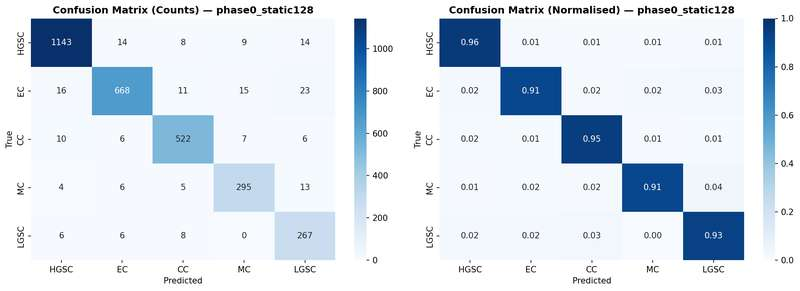

Saved: confusion_phase0_static128.png


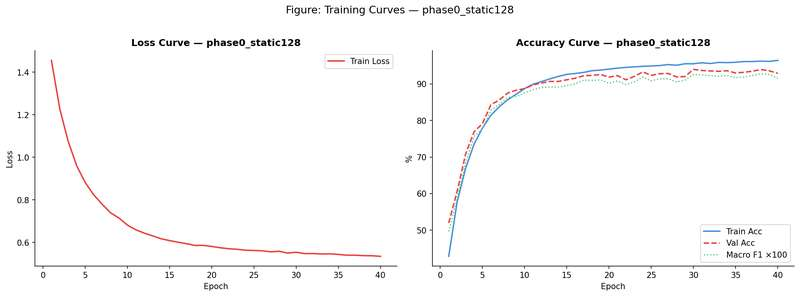

Saved: curves_phase0_static128.png

  Phase 0 complete.


In [ ]:
# ── Cell 24: Preprocessing Phase 0 — Static 128 × 128 ────────────────────────

print('=' * 65)
print('  PHASE 0 : Static 128 × 128')
print('=' * 65)
print('  Purpose  : Lower-bound baseline — information bottleneck proof')
print('  Pre-fn   : None')
print('  Size     : 128 × 128  (static, all epochs)')
print(f'  Batch    : {BASE_BATCH * 2}')
print('=' * 65)

_ckpt_p0 = CHECKPOINT_DIR / 'best_phase0_static128.pth'

_train_ds_p0 = OvarianDataset(
    train_paths, train_labels,
    transform  = AUG_128,
    pre_fn     = None,
    input_size = 128,
)
_test_ds_p0 = OvarianDataset(
    test_paths, test_labels,
    transform  = EVL_128,
    pre_fn     = None,
    input_size = 128,
)
_train_ldr_p0 = make_loader(_train_ds_p0, batch_size=BASE_BATCH * 2)
_test_ldr_p0  = make_loader(_test_ds_p0,  batch_size=BASE_BATCH * 2,
                             shuffle=False)

_criterion_p0 = nn.CrossEntropyLoss(
    weight=EFF_NUM_WEIGHTS, label_smoothing=0.1
)
_model_p0 = ConvNeXtSingleCBAM().to(device)

RESULTS_PREP['phase0_static128'] = train_model(
    model          = _model_p0,
    train_loader   = _train_ldr_p0,
    test_loader    = _test_ldr_p0,
    epochs         = EPOCHS,
    label          = 'phase0_static128',
    criterion      = _criterion_p0,
    backbone_lr    = 2e-5,
    head_lr        = 2e-4,
    patience       = PATIENCE,
)

_eval_p0 = evaluate(
    _model_p0, _test_ldr_p0,
    RESULTS_PREP['phase0_static128']['ckpt'],
    'phase0_static128'
)
RESULTS_PREP['phase0_static128'].update(_eval_p0)
plot_training_curves(
    RESULTS_PREP['phase0_static128']['history'],
    'phase0_static128'
)

del _model_p0, _train_ds_p0, _test_ds_p0
del _train_ldr_p0, _test_ldr_p0
torch.cuda.empty_cache()
print('\n  Phase 0 complete.')

  PHASE 1 : Static 224 × 224
  Purpose  : Standard resolution baseline
  Pre-fn   : None
  Size     : 224 × 224  (static, all epochs)

... [epoch-by-epoch training log truncated for GitHub] ...

  Ep  62/100 | Loss:0.5099 | Train:97.71% | Val:95.81% | LR:3.79e-04 | Best:95.85% | No improve: 5/10 | 66.8s
  Ep  63/100 | Loss:0.5093 | Train:97.63% | Val:95.94% | LR:3.62e-04 | Best:95.94% | 67.8s
  Ep  64/100 | Loss:0.5072 | Train:97.82% | Val:95.65% | LR:3.45e-04 | Best:95.94% | No improve: 1/10 | 66.8s
  Ep  65/100 | Loss:0.5053 | Train:97.87% | Val:96.14% | LR:3.29e-04 | Best:96.14% | 68.1s
  Ep  66/100 | Loss:0.5067 | Train:97.77% | Val:96.27% | LR:3.13e-04 | Best:96.27% | 68.0s
  Ep  67/100 | Loss:0.5044 | Train:97.89% | Val:96.14% | LR:2.97e-04 | Best:96.27% | No improve: 1/10 | 66.9s
  Ep  68/100 | Loss:0.5043 | Train:97.94% | Val:96.17% | LR:2.81e-04 | Best:96.27% | No improve: 2/10 | 66.9s
  Ep  69/100 | Loss:0.5043 | Train:97.97% | Val:96.07% | LR:2.65e-04 | Best:96.27% | No impr

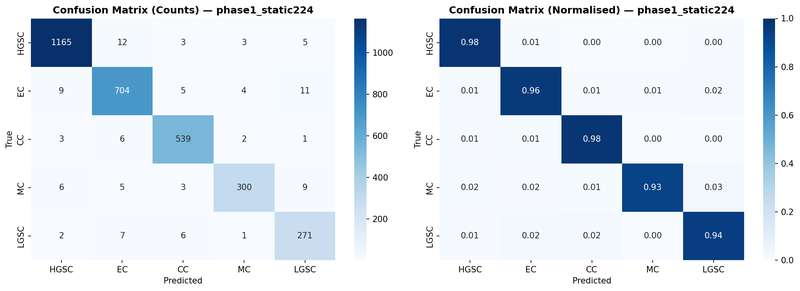

Saved: confusion_phase1_static224.png


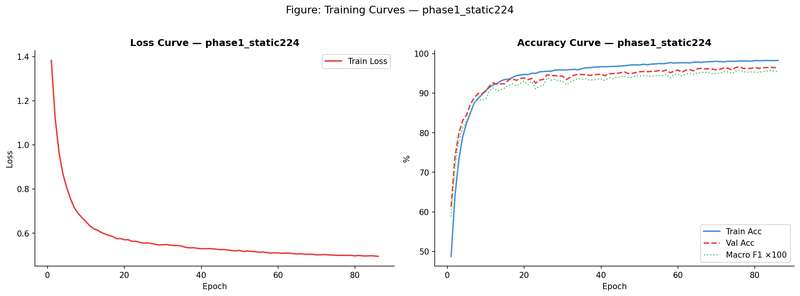

Saved: curves_phase1_static224.png

  Phase 1 complete.


In [ ]:
# ── Cell 25: Preprocessing Phase 1 — Static 224 × 224 ────────────────────────

print('=' * 65)
print('  PHASE 1 : Static 224 × 224')
print('=' * 65)
print('  Purpose  : Standard resolution baseline')
print('  Pre-fn   : None')
print('  Size     : 224 × 224  (static, all epochs)')
print(f'  Batch    : {BASE_BATCH}')
print('=' * 65)

_train_ds_p1 = OvarianDataset(
    train_paths, train_labels,
    transform  = AUG_224,
    pre_fn     = None,
    input_size = 224,
)
_test_ds_p1 = OvarianDataset(
    test_paths, test_labels,
    transform  = EVL_224,
    pre_fn     = None,
    input_size = 224,
)
_train_ldr_p1 = make_loader(_train_ds_p1, batch_size=BASE_BATCH)
_test_ldr_p1  = make_loader(_test_ds_p1,  batch_size=BASE_BATCH,
                             shuffle=False)

_criterion_p1 = nn.CrossEntropyLoss(
    weight=EFF_NUM_WEIGHTS, label_smoothing=0.1
)
_model_p1 = ConvNeXtSingleCBAM().to(device)

RESULTS_PREP['phase1_static224'] = train_model(
    model        = _model_p1,
    train_loader = _train_ldr_p1,
    test_loader  = _test_ldr_p1,
    epochs       = EPOCHS,
    label        = 'phase1_static224',
    criterion    = _criterion_p1,
    backbone_lr  = 2e-5,
    head_lr      = 2e-4,
    patience     = PATIENCE,
)

_eval_p1 = evaluate(
    _model_p1, _test_ldr_p1,
    RESULTS_PREP['phase1_static224']['ckpt'],
    'phase1_static224'
)
RESULTS_PREP['phase1_static224'].update(_eval_p1)
plot_training_curves(
    RESULTS_PREP['phase1_static224']['history'],
    'phase1_static224'
)

del _model_p1, _train_ds_p1, _test_ds_p1
del _train_ldr_p1, _test_ldr_p1
torch.cuda.empty_cache()
print('\n  Phase 1 complete.')

  PHASE 2 : Static 384 × 384
  Purpose  : High-resolution upper bound — no progressive schedule
  Pre-fn   : None
  Size     : 384 × 384  (static, all epochs)

... [epoch-by-epoch training log truncated for GitHub] ...

  Ep  13/100 | Loss:0.6247 | Train:92.19% | Val:92.28% | LR:9.97e-04 | Best:92.28% | 178.3s
  Ep  14/100 | Loss:0.6186 | Train:92.66% | Val:93.38% | LR:9.95e-04 | Best:93.38% | 177.8s
  Ep  15/100 | Loss:0.6095 | Train:93.05% | Val:93.12% | LR:9.92e-04 | Best:93.38% | No improve: 1/10 | 176.9s
  Ep  16/100 | Loss:0.6046 | Train:93.36% | Val:92.67% | LR:9.89e-04 | Best:93.38% | No improve: 2/10 | 177.1s
  Ep  17/100 | Loss:0.6026 | Train:93.47% | Val:93.15% | LR:9.85e-04 | Best:93.38% | No improve: 3/10 | 177.7s
  Ep  18/100 | Loss:0.5922 | Train:93.77% | Val:93.28% | LR:9.81e-04 | Best:93.38% | No improve: 4/10 | 176.9s
  Ep  19/100 | Loss:0.5895 | Train:94.17% | Val:92.80% | LR:9.76e-04 | Best:93.38% | No improve: 5/10 | 176.9s
  Ep  20/100 | Loss:0.5857 | Train:94.13%

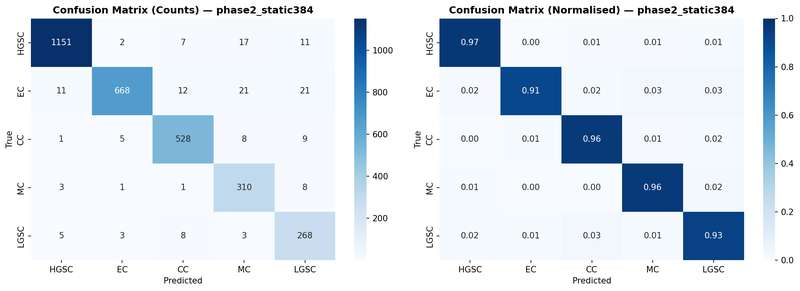

Saved: confusion_phase2_static384.png


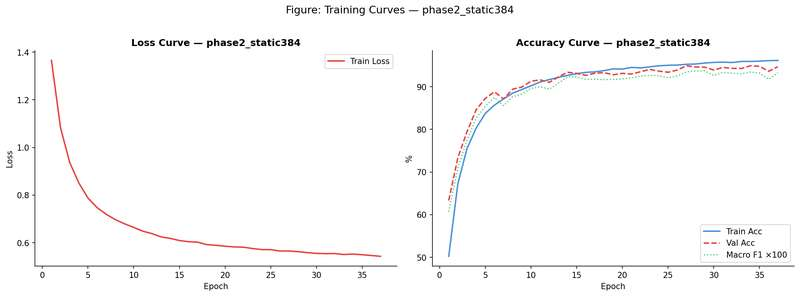

Saved: curves_phase2_static384.png

  Phase 2 complete.


In [ ]:
# ── Cell 26: Preprocessing Phase 2 — Static 384 × 384 ────────────────────────

print('=' * 65)
print('  PHASE 2 : Static 384 × 384')
print('=' * 65)
print('  Purpose  : High-resolution upper bound — no progressive schedule')
print('  Pre-fn   : None')
print('  Size     : 384 × 384  (static, all epochs)')
print(f'  Batch    : {BASE_BATCH // 2}')
print('=' * 65)

_train_ds_p2 = OvarianDataset(
    train_paths, train_labels,
    transform  = AUG_384,
    pre_fn     = None,
    input_size = 384,
)
_test_ds_p2 = OvarianDataset(
    test_paths, test_labels,
    transform  = EVL_384,
    pre_fn     = None,
    input_size = 384,
)
_train_ldr_p2 = make_loader(_train_ds_p2, batch_size=BASE_BATCH // 2)
_test_ldr_p2  = make_loader(_test_ds_p2,  batch_size=BASE_BATCH // 2,
                             shuffle=False)

_criterion_p2 = nn.CrossEntropyLoss(
    weight=EFF_NUM_WEIGHTS, label_smoothing=0.1
)
_model_p2 = ConvNeXtSingleCBAM().to(device)

RESULTS_PREP['phase2_static384'] = train_model(
    model        = _model_p2,
    train_loader = _train_ldr_p2,
    test_loader  = _test_ldr_p2,
    epochs       = EPOCHS,
    label        = 'phase2_static384',
    criterion    = _criterion_p2,
    backbone_lr  = 2e-5,
    head_lr      = 2e-4,
    patience     = PATIENCE,
)

_eval_p2 = evaluate(
    _model_p2, _test_ldr_p2,
    RESULTS_PREP['phase2_static384']['ckpt'],
    'phase2_static384'
)
RESULTS_PREP['phase2_static384'].update(_eval_p2)
plot_training_curves(
    RESULTS_PREP['phase2_static384']['history'],
    'phase2_static384'
)

del _model_p2, _train_ds_p2, _test_ds_p2
del _train_ldr_p2, _test_ldr_p2
torch.cuda.empty_cache()
print('\n  Phase 2 complete.')

  PHASE 3 : Progressive Resize  128 → 224 → 384
  Purpose  : Curriculum learning — coarse to fine resolution
  Pre-fn   : None
  Stage 1  : epochs  1–34   128 × 128

... [epoch-by-epoch training log truncated for GitHub] ...

  Ep  20/100 | Loss:0.5503 | Train:95.44% | Val:93.90% | LR:4.33e-04 | Best:93.90% | 31.4s
  Ep  21/100 | Loss:0.5447 | Train:95.74% | Val:93.48% | LR:3.83e-04 | Best:93.90% | No improve: 1/10 | 31.0s
  Ep  22/100 | Loss:0.5421 | Train:95.85% | Val:94.06% | LR:3.34e-04 | Best:94.06% | 30.5s
  Ep  23/100 | Loss:0.5358 | Train:96.21% | Val:93.90% | LR:2.86e-04 | Best:94.06% | No improve: 1/10 | 30.9s
  Ep  24/100 | Loss:0.5329 | Train:96.35% | Val:93.90% | LR:2.41e-04 | Best:94.06% | No improve: 2/10 | 29.4s
  Ep  25/100 | Loss:0.5309 | Train:96.43% | Val:94.35% | LR:1.99e-04 | Best:94.35% | 31.3s
  Ep  26/100 | Loss:0.5285 | Train:96.60% | Val:94.03% | LR:1.59e-04 | Best:94.35% | No improve: 1/10 | 29.8s
  Ep  27/100 | Loss:0.5268 | Train:96.69% | Val:94.16% | LR:1

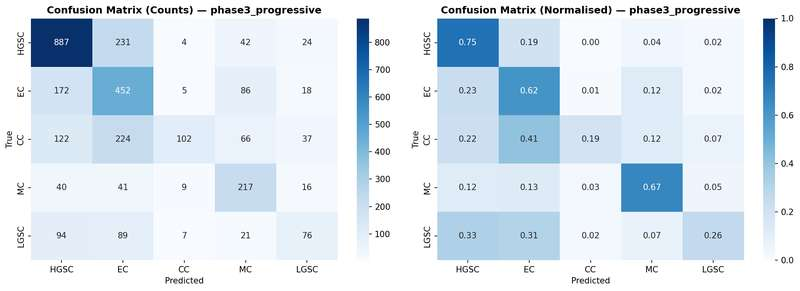

Saved: confusion_phase3_progressive.png


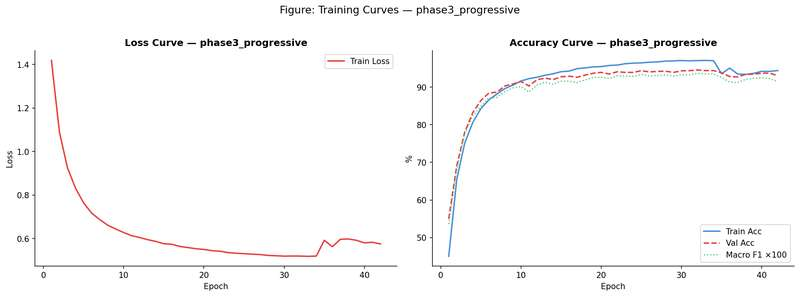

Saved: curves_phase3_progressive.png

  Phase 3 complete.


In [ ]:
# ── Cell 27: Preprocessing Phase 3 — Progressive Resize ──────────────────────

print('=' * 65)
print('  PHASE 3 : Progressive Resize  128 → 224 → 384')
print('=' * 65)
print('  Purpose  : Curriculum learning — coarse to fine resolution')
print('  Pre-fn   : None')
print('  Stage 1  : epochs  1–34   128 × 128')
print('  Stage 2  : epochs 35–67   224 × 224')
print('  Stage 3  : epochs 68–100  384 × 384')
print('=' * 65)

_ckpt_p3    = CHECKPOINT_DIR / 'best_phase3_progressive.pth'
_best_acc   = 0.0
_best_f1    = 0.0
_no_imp     = 0
_history_p3 = {
    'train_loss': [], 'train_acc': [],
    'val_acc'   : [], 'macro_f1' : []
}

_stages = [
    (128, BASE_BATCH * 2, 34,  AUG_128, EVL_128),
    (224, BASE_BATCH,     33,  AUG_224, EVL_224),
    (384, BASE_BATCH // 2, 33, AUG_384, EVL_384),
]

_model_p3     = ConvNeXtSingleCBAM().to(device)
_criterion_p3 = nn.CrossEntropyLoss(
    weight=EFF_NUM_WEIGHTS, label_smoothing=0.1
)
_global_ep    = 0
_t0_total     = time.time()

n_p = sum(p.numel() for p in _model_p3.parameters()) / 1e6
print(f'\n{"=" * 65}')
print(f'  phase3_progressive  |  {EPOCHS} ep  |  {n_p:.1f}M params')
print(f'  Criterion : CrossEntropyLoss  (Eff-Num weights)')
print(f'  Train     : {len(train_paths)}  |  Test : {len(test_paths)}')
print(f'{"=" * 65}')

for _size, _batch, _eps, _aug_tf, _evl_tf in _stages:
    print(f'\n  ── Stage: {_size}×{_size}  '
          f'({_eps} epochs · batch {_batch}) ──')

    _train_ds = OvarianDataset(
        train_paths, train_labels,
        transform=_aug_tf, pre_fn=None, input_size=_size
    )
    _test_ds = OvarianDataset(
        test_paths, test_labels,
        transform=_evl_tf, pre_fn=None, input_size=_size
    )
    _train_ldr = make_loader(_train_ds, batch_size=_batch)
    _test_ldr  = make_loader(_test_ds,  batch_size=_batch,
                              shuffle=False)

    _bb_p, _ot_p = _model_p3.get_param_groups()
    _optimizer = optim.AdamW(
        [{'params': _bb_p, 'lr': 2e-5},
         {'params': _ot_p, 'lr': 2e-4}],
        weight_decay=1e-4
    )
    _scheduler = OneCycleLR(
        _optimizer,
        max_lr          = [2e-5 * 5, 2e-4 * 5],
        steps_per_epoch = len(_train_ldr),
        epochs          = _eps,
        pct_start       = 0.1,
        anneal_strategy = 'cos',
    )
    _scaler = torch.cuda.amp.GradScaler()

    for _ep in range(1, _eps + 1):
        _global_ep += 1
        _model_p3.train()
        _run_loss = 0.0
        _correct  = 0
        _total    = 0
        _t0 = time.time()

        for _imgs, _lbls in _train_ldr:
            _imgs, _lbls = _imgs.to(device), _lbls.to(device)
            _optimizer.zero_grad(set_to_none=True)
            with torch.cuda.amp.autocast():
                _out  = _model_p3(_imgs)
                _loss = _criterion_p3(_out, _lbls)
            _scaler.scale(_loss).backward()
            _scaler.unscale_(_optimizer)
            torch.nn.utils.clip_grad_norm_(
                _model_p3.parameters(), 1.0
            )
            _scaler.step(_optimizer)
            _scaler.update()
            _scheduler.step()
            _run_loss += _loss.item()
            _preds     = _out.argmax(1)
            _correct  += (_preds == _lbls).sum().item()
            _total    += _lbls.size(0)

        _model_p3.eval()
        _val_correct = 0
        _val_total   = 0
        _all_preds   = []
        _all_labels  = []
        with torch.no_grad():
            for _imgs, _lbls in _test_ldr:
                _imgs, _lbls = _imgs.to(device), _lbls.to(device)
                with torch.cuda.amp.autocast():
                    _preds = _model_p3(_imgs).argmax(1)
                _val_correct += (_preds == _lbls).sum().item()
                _val_total   += _lbls.size(0)
                _all_preds.extend(_preds.cpu().numpy())
                _all_labels.extend(_lbls.cpu().numpy())

        _train_acc = 100. * _correct / _total
        _val_acc   = 100. * _val_correct / _val_total
        _macro_f1  = f1_score(_all_labels, _all_preds,
                               average='macro', zero_division=0)
        _avg_loss  = _run_loss / len(_train_ldr)

        _history_p3['train_loss'].append(_avg_loss)
        _history_p3['train_acc'] .append(_train_acc)
        _history_p3['val_acc']   .append(_val_acc)
        _history_p3['macro_f1']  .append(_macro_f1)

        if _val_acc > _best_acc:
            _best_acc = _val_acc
            _best_f1  = _macro_f1
            torch.save(_model_p3.state_dict(), _ckpt_p3)
            _no_imp = 0
        else:
            _no_imp += 1

        _tag = f' | No improve: {_no_imp}/{PATIENCE}' if _no_imp else ''
        print(f'  Ep {_global_ep:>3}/{EPOCHS} | '
              f'Loss:{_avg_loss:.4f} | '
              f'Train:{_train_acc:.2f}% | '
              f'Val:{_val_acc:.2f}% | '
              f'LR:{_optimizer.param_groups[1]["lr"]:.2e} | '
              f'Best:{_best_acc:.2f}%{_tag} | '
              f'{time.time() - _t0:.1f}s')

        if _no_imp >= PATIENCE:
            print(f'\n  Early stop at epoch {_global_ep}.')
            break

    del _train_ds, _test_ds, _train_ldr, _test_ldr
    torch.cuda.empty_cache()

    if _no_imp >= PATIENCE:
        break

_total_time = time.time() - _t0_total
print(f'\n  phase3_progressive  |  Best Val: {_best_acc:.2f}%  |  '
      f'Macro F1: {_best_f1:.4f}  |  '
      f'Time: {_total_time / 60:.1f} min')

RESULTS_PREP['phase3_progressive'] = {
    'label'         : 'phase3_progressive',
    'val_acc'       : _best_acc,
    'macro_f1'      : _best_f1,
    'ckpt'          : _ckpt_p3,
    'history'       : _history_p3,
    'total_time_min': _total_time / 60,
}

_test_ds_p3_eval = OvarianDataset(
    test_paths, test_labels,
    transform=EVL_384, pre_fn=None, input_size=384
)
_test_ldr_p3_eval = make_loader(
    _test_ds_p3_eval, batch_size=BASE_BATCH // 2, shuffle=False
)
_eval_p3 = evaluate(
    _model_p3, _test_ldr_p3_eval, _ckpt_p3,
    'phase3_progressive'
)
RESULTS_PREP['phase3_progressive'].update(_eval_p3)
plot_training_curves(_history_p3, 'phase3_progressive')

del _model_p3, _test_ds_p3_eval, _test_ldr_p3_eval
torch.cuda.empty_cache()
print('\n  Phase 3 complete.')

  PHASE 4 : Static 224 × 224 + CLAHE
  Purpose  : Contrast enhancement on histopathology staining
  Pre-fn   : apply_clahe  (LAB space · clip=2.0 · tile=8×8)
  Size     : 224 × 224  (static, all epochs)

... [epoch-by-epoch training log truncated for GitHub] ...

  Ep  36/100 | Loss:0.5351 | Train:96.50% | Val:94.03% | LR:8.08e-04 | Best:94.45% | No improve: 1/10 | 74.0s
  Ep  37/100 | Loss:0.5294 | Train:96.78% | Val:94.35% | LR:7.94e-04 | Best:94.45% | No improve: 2/10 | 72.4s
  Ep  38/100 | Loss:0.5304 | Train:96.78% | Val:94.45% | LR:7.80e-04 | Best:94.45% | No improve: 3/10 | 72.8s
  Ep  39/100 | Loss:0.5270 | Train:96.92% | Val:94.29% | LR:7.65e-04 | Best:94.45% | No improve: 4/10 | 73.7s
  Ep  40/100 | Loss:0.5281 | Train:96.89% | Val:95.23% | LR:7.50e-04 | Best:95.23% | 74.1s
  Ep  41/100 | Loss:0.5243 | Train:97.02% | Val:94.52% | LR:7.35e-04 | Best:95.23% | No improve: 1/10 | 73.2s
  Ep  42/100 | Loss:0.5275 | Train:96.81% | Val:94.78% | LR:7.19e-04 | Best:95.23% | No improve

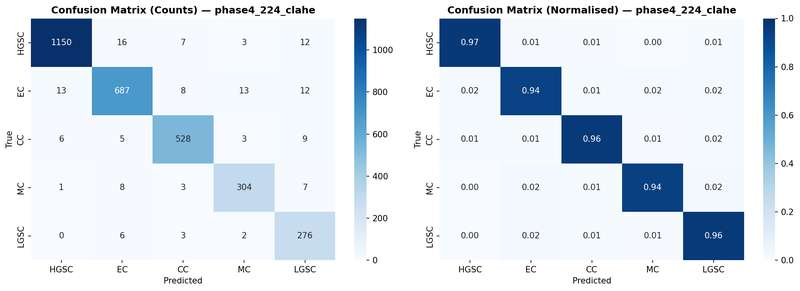

Saved: confusion_phase4_224_clahe.png


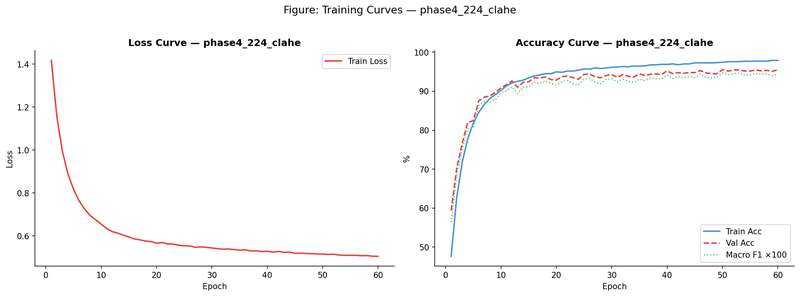

Saved: curves_phase4_224_clahe.png

  Phase 4 complete.


In [ ]:
# ── Cell 28: Preprocessing Phase 4 — Static 224 + CLAHE ──────────────────────

print('=' * 65)
print('  PHASE 4 : Static 224 × 224 + CLAHE')
print('=' * 65)
print('  Purpose  : Contrast enhancement on histopathology staining')
print('  Pre-fn   : apply_clahe  (LAB space · clip=2.0 · tile=8×8)')
print('  Size     : 224 × 224  (static, all epochs)')
print(f'  Batch    : {BASE_BATCH}')
print('=' * 65)

_ckpt_p4    = CHECKPOINT_DIR / 'best_phase4_224_clahe.pth'
_model_p4   = ConvNeXtSingleCBAM().to(device)

_train_ds_p4 = OvarianDataset(
    train_paths, train_labels,
    transform  = AUG_224,
    pre_fn     = PRE_FN['clahe'],
    input_size = 224,
)
_test_ds_p4 = OvarianDataset(
    test_paths, test_labels,
    transform  = EVL_224,
    pre_fn     = PRE_FN['clahe'],
    input_size = 224,
)
_train_ldr_p4 = make_loader(_train_ds_p4, batch_size=BASE_BATCH)
_test_ldr_p4  = make_loader(_test_ds_p4,  batch_size=BASE_BATCH,
                              shuffle=False)

_criterion_p4 = nn.CrossEntropyLoss(
    weight=EFF_NUM_WEIGHTS, label_smoothing=0.1
)

RESULTS_PREP['phase4_224_clahe'] = train_model(
    model        = _model_p4,
    train_loader = _train_ldr_p4,
    test_loader  = _test_ldr_p4,
    epochs       = EPOCHS,
    label        = 'phase4_224_clahe',
    criterion    = _criterion_p4,
    backbone_lr  = 2e-5,
    head_lr      = 2e-4,
    patience     = PATIENCE,
)

_eval_p4 = evaluate(
    _model_p4, _test_ldr_p4,
    RESULTS_PREP['phase4_224_clahe']['ckpt'],
    'phase4_224_clahe'
)
RESULTS_PREP['phase4_224_clahe'].update(_eval_p4)
plot_training_curves(
    RESULTS_PREP['phase4_224_clahe']['history'],
    'phase4_224_clahe'
)

del _model_p4, _train_ds_p4, _test_ds_p4
del _train_ldr_p4, _test_ldr_p4
torch.cuda.empty_cache()
print('\n  Phase 4 complete.')

  PHASE 5 : Static 224 × 224 + Macenko Stain Normalisation
  Purpose  : Reduce staining variability across slides
  Pre-fn   : MacenkoNormalizer — precomputed to RAM
  Size     : 224 × 224  (static, all epochs)
  Batch    : 64

  Precomputing stain-normalised train images...


  Train stain norm: 100%|█████████████████| 31203/31203 [09:43<00:00, 53.51it/s]


  Precomputing stain-normalised test images...


  Test  stain norm: 100%|███████████████████| 3082/3082 [01:02<00:00, 49.02it/s]



  Cache sizes:
  Train : 31203 images
  Test  : 3082  images


... [epoch-by-epoch training log truncated for GitHub] ...

  Ep  74/100 | Loss:0.5016 | Train:98.09% | Val:91.37% | LR:1.92e-04 | Best:91.79% | No improve: 1/10 | 67.2s
  Ep  75/100 | Loss:0.5008 | Train:98.02% | Val:91.69% | LR:1.79e-04 | Best:91.79% | No improve: 2/10 | 67.4s
  Ep  76/100 | Loss:0.5001 | Train:98.03% | Val:91.69% | LR:1.65e-04 | Best:91.79% | No improve: 3/10 | 67.3s
  Ep  77/100 | Loss:0.5010 | Train:97.97% | Val:91.79% | LR:1.53e-04 | Best:91.79% | No improve: 4/10 | 67.5s
  Ep  78/100 | Loss:0.5020 | Train:97.97% | Val:91.66% | LR:1.40e-04 | Best:91.79% | No improve: 5/10 | 67.8s
  Ep  79/100 | Loss:0.4991 | Train:98.16% | Val:91.63% | LR:1.28e-04 | Best:91.79% | No improve: 6/10 | 67.2s
  Ep  80/100 | Loss:0.4999 | Train:98.12% | Val:91.86% | LR:1.17e-04 | Best:91.86% | 68.0s
  Ep  81/100 | Loss:0.4977 | Train:98.15% | Val:91.76% | LR:1.06e-04 | Best:91.86% | No improve: 1/10 | 67.2s
  Ep  82/100 | 

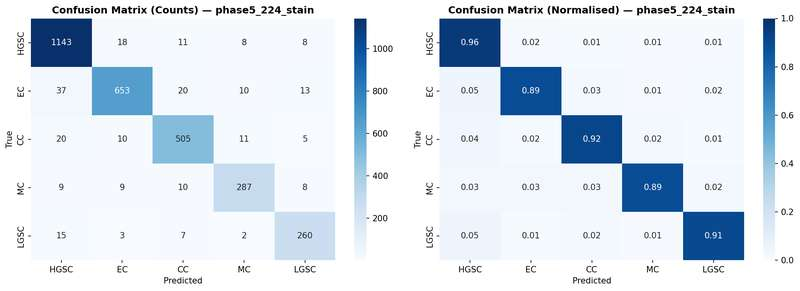

Saved: confusion_phase5_224_stain.png


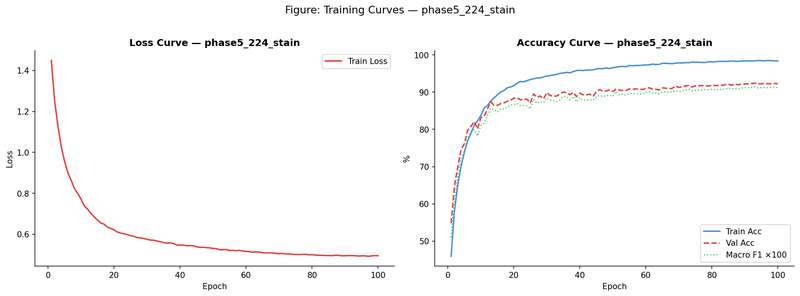

Saved: curves_phase5_224_stain.png

  Phase 5 complete.


In [ ]:
# ── Cell 29: Preprocessing Phase 5 — Static 224 + Stain Norm (Fixed) ─────────
#
# ROOT CAUSE: Macenko normalisation (SVD-based) was running inside
# __getitem__ on every image every epoch → 833s/epoch.
#
# FIX: Precompute all normalised images to RAM once before training.
# Cost: ~5–10 min once. Epoch time drops back to normal (~30–50s).
# ──────────────────────────────────────────────────────────────────────────────

print('=' * 65)
print('  PHASE 5 : Static 224 × 224 + Macenko Stain Normalisation')
print('=' * 65)
print('  Purpose  : Reduce staining variability across slides')
print('  Pre-fn   : MacenkoNormalizer — precomputed to RAM')
print('  Size     : 224 × 224  (static, all epochs)')
print(f'  Batch    : {BASE_BATCH}')
print('=' * 65)


def precompute_stain_normalised(paths, pre_fn, size, desc=''):
    """
    Apply pre_fn + resize to every image once.
    Returns a list of uint8 numpy arrays (H, W, 3).
    Falls back to plain resize on normalisation failure.
    """
    cache = []
    failed = 0
    for p in tqdm(paths, desc=desc, ncols=80):
        img = cv2.imread(str(p))
        if img is None:
            cache.append(
                np.zeros((size, size, 3), dtype=np.uint8)
            )
            continue
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        try:
            img = pre_fn(img)
        except Exception:
            failed += 1
        img = cv2.resize(img, (size, size),
                          interpolation=cv2.INTER_AREA)
        cache.append(img)
    if failed:
        print(f'  Warning: {failed} images fell back to no-norm.')
    return cache


class PrecomputedDataset(Dataset):
    """
    Dataset that reads from a precomputed list of uint8 numpy arrays.
    No preprocessing fn — already applied. Transform only.
    """
    def __init__(self, cache, labels, transform):
        self.cache     = cache
        self.labels    = labels
        self.transform = transform

    def __len__(self):
        return len(self.cache)

    def __getitem__(self, i):
        return self.transform(self.cache[i]), self.labels[i]


# ── Precompute ─────────────────────────────────────────────────────────────────
print('\n  Precomputing stain-normalised train images...')
_cache_train_p5 = precompute_stain_normalised(
    train_paths, PRE_FN['stain'], 224,
    desc='  Train stain norm'
)

print('  Precomputing stain-normalised test images...')
_cache_test_p5 = precompute_stain_normalised(
    test_paths, PRE_FN['stain'], 224,
    desc='  Test  stain norm'
)

print(f'\n  Cache sizes:')
print(f'  Train : {len(_cache_train_p5)} images')
print(f'  Test  : {len(_cache_test_p5)}  images')

# ── Build datasets from cache ─────────────────────────────────────────────────
_train_ds_p5 = PrecomputedDataset(
    _cache_train_p5, train_labels, AUG_224
)
_test_ds_p5  = PrecomputedDataset(
    _cache_test_p5,  test_labels,  EVL_224
)
_train_ldr_p5 = make_loader(_train_ds_p5, batch_size=BASE_BATCH)
_test_ldr_p5  = make_loader(_test_ds_p5,  batch_size=BASE_BATCH,
                              shuffle=False)

# ── Train ─────────────────────────────────────────────────────────────────────
_criterion_p5 = nn.CrossEntropyLoss(
    weight=EFF_NUM_WEIGHTS, label_smoothing=0.1
)
_model_p5     = ConvNeXtSingleCBAM().to(device)

RESULTS_PREP['phase5_224_stain'] = train_model(
    model        = _model_p5,
    train_loader = _train_ldr_p5,
    test_loader  = _test_ldr_p5,
    epochs       = EPOCHS,
    label        = 'phase5_224_stain',
    criterion    = _criterion_p5,
    backbone_lr  = 2e-5,
    head_lr      = 2e-4,
    patience     = PATIENCE,
)

_eval_p5 = evaluate(
    _model_p5, _test_ldr_p5,
    RESULTS_PREP['phase5_224_stain']['ckpt'],
    'phase5_224_stain'
)
RESULTS_PREP['phase5_224_stain'].update(_eval_p5)
plot_training_curves(
    RESULTS_PREP['phase5_224_stain']['history'],
    'phase5_224_stain'
)

del _model_p5
del _train_ds_p5, _test_ds_p5
del _train_ldr_p5, _test_ldr_p5
del _cache_train_p5, _cache_test_p5
torch.cuda.empty_cache()
print('\n  Phase 5 complete.')

  PHASE 6 : Static 224 × 224 + CLAHE + Stain Normalisation
  Purpose  : Combined enhancement — best of both worlds test
  Pre-fn   : apply_clahe → MacenkoNormalizer  (precomputed)
  Size     : 224 × 224  (static, all epochs)
  Batch    : 64

  Precomputing combined train images...


  Train combined: 100%|███████████████████| 31203/31203 [11:12<00:00, 46.40it/s]


  Precomputing combined test images...


  Test  combined: 100%|█████████████████████| 3082/3082 [01:05<00:00, 46.78it/s]



  Cache sizes:
  Train : 31203 images
  Test  : 3082  images


... [epoch-by-epoch training log truncated for GitHub] ...

  Ep  52/100 | Loss:0.5190 | Train:97.13% | Val:90.53% | LR:5.52e-04 | Best:92.05% | No improve: 2/10 | 67.4s
  Ep  53/100 | Loss:0.5174 | Train:97.23% | Val:91.53% | LR:5.35e-04 | Best:92.05% | No improve: 3/10 | 67.1s
  Ep  54/100 | Loss:0.5165 | Train:97.32% | Val:91.60% | LR:5.17e-04 | Best:92.05% | No improve: 4/10 | 67.1s
  Ep  55/100 | Loss:0.5168 | Train:97.38% | Val:91.50% | LR:5.00e-04 | Best:92.05% | No improve: 5/10 | 67.2s
  Ep  56/100 | Loss:0.5128 | Train:97.58% | Val:92.02% | LR:4.83e-04 | Best:92.05% | No improve: 6/10 | 67.4s
  Ep  57/100 | Loss:0.5151 | Train:97.41% | Val:91.66% | LR:4.65e-04 | Best:92.05% | No improve: 7/10 | 67.4s
  Ep  58/100 | Loss:0.5103 | Train:97.55% | Val:91.43% | LR:4.48e-04 | Best:92.05% | No improve: 8/10 | 67.3s
  Ep  59/100 | Loss:0.5097 | Train:97.63% | Val:92.38% | LR:4.30e-04 | Best:92.38% | 68.0s
  Ep  60/100 | 

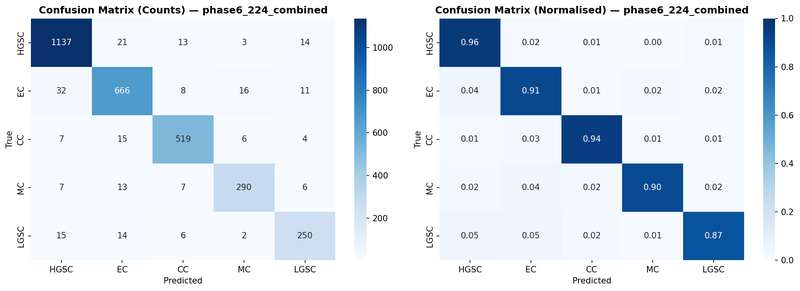

Saved: confusion_phase6_224_combined.png


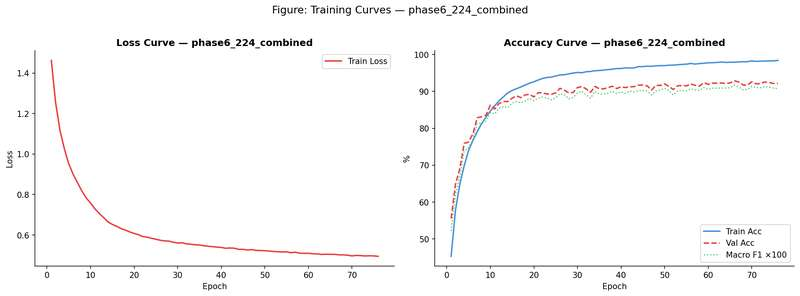

Saved: curves_phase6_224_combined.png

  Phase 6 complete.


In [ ]:
# ── Cell 30: Preprocessing Phase 6 — Static 224 + Combined (Fixed) ───────────
#
# ROOT CAUSE: PRE_FN['combined'] includes Macenko stain norm (SVD-based).
# Running inside __getitem__ every epoch → same slow issue as Phase 5.
#
# FIX: Precompute all combined-preprocessed images to RAM once.
# Uses precompute_stain_normalised() + PrecomputedDataset from Cell 29.
# ──────────────────────────────────────────────────────────────────────────────

print('=' * 65)
print('  PHASE 6 : Static 224 × 224 + CLAHE + Stain Normalisation')
print('=' * 65)
print('  Purpose  : Combined enhancement — best of both worlds test')
print('  Pre-fn   : apply_clahe → MacenkoNormalizer  (precomputed)')
print('  Size     : 224 × 224  (static, all epochs)')
print(f'  Batch    : {BASE_BATCH}')
print('=' * 65)

# ── Precompute ────────────────────────────────────────────────────────────────
print('\n  Precomputing combined train images...')
_cache_train_p6 = precompute_stain_normalised(
    train_paths, PRE_FN['combined'], 224,
    desc='  Train combined'
)

print('  Precomputing combined test images...')
_cache_test_p6 = precompute_stain_normalised(
    test_paths, PRE_FN['combined'], 224,
    desc='  Test  combined'
)

print(f'\n  Cache sizes:')
print(f'  Train : {len(_cache_train_p6)} images')
print(f'  Test  : {len(_cache_test_p6)}  images')

# ── Build datasets from cache ─────────────────────────────────────────────────
_train_ds_p6  = PrecomputedDataset(
    _cache_train_p6, train_labels, AUG_224
)
_test_ds_p6   = PrecomputedDataset(
    _cache_test_p6,  test_labels,  EVL_224
)
_train_ldr_p6 = make_loader(_train_ds_p6, batch_size=BASE_BATCH)
_test_ldr_p6  = make_loader(_test_ds_p6,  batch_size=BASE_BATCH,
                              shuffle=False)

# ── Train ─────────────────────────────────────────────────────────────────────
_criterion_p6 = nn.CrossEntropyLoss(
    weight=EFF_NUM_WEIGHTS, label_smoothing=0.1
)
_model_p6     = ConvNeXtSingleCBAM().to(device)

RESULTS_PREP['phase6_224_combined'] = train_model(
    model        = _model_p6,
    train_loader = _train_ldr_p6,
    test_loader  = _test_ldr_p6,
    epochs       = EPOCHS,
    label        = 'phase6_224_combined',
    criterion    = _criterion_p6,
    backbone_lr  = 2e-5,
    head_lr      = 2e-4,
    patience     = PATIENCE,
)

_eval_p6 = evaluate(
    _model_p6, _test_ldr_p6,
    RESULTS_PREP['phase6_224_combined']['ckpt'],
    'phase6_224_combined'
)
RESULTS_PREP['phase6_224_combined'].update(_eval_p6)
plot_training_curves(
    RESULTS_PREP['phase6_224_combined']['history'],
    'phase6_224_combined'
)

del _model_p6
del _train_ds_p6, _test_ds_p6
del _train_ldr_p6, _test_ldr_p6
del _cache_train_p6, _cache_test_p6
torch.cuda.empty_cache()
print('\n  Phase 6 complete.')


  SECTION 4 — PREPROCESSING ABLATION RESULTS
                          Phase  Val Acc (%)  Macro F1  Time (min)
           Phase 1 · Static 224        96.66    0.9583        97.9
   Phase 4 · Static 224 + CLAHE        95.55    0.9467        73.7
           Phase 2 · Static 384        94.91    0.9345       110.6
           Phase 0 · Static 128        93.93    0.9255        21.4
Phase 6 · Static 224 + Combined        92.86    0.9169        85.6
   Phase 5 · Static 224 + Stain        92.41    0.9138       112.9
  Phase 3 · Progressive 128→384        56.26    0.4854        26.8


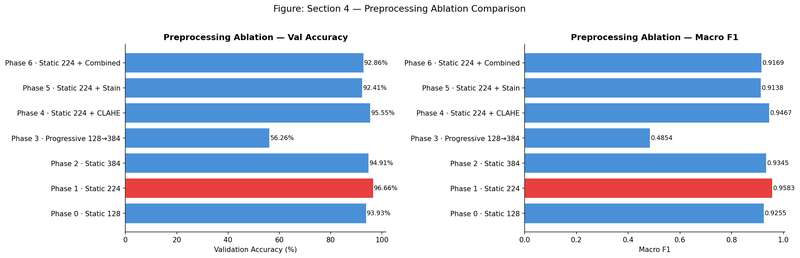

Saved: fig_prep_ablation_comparison.png


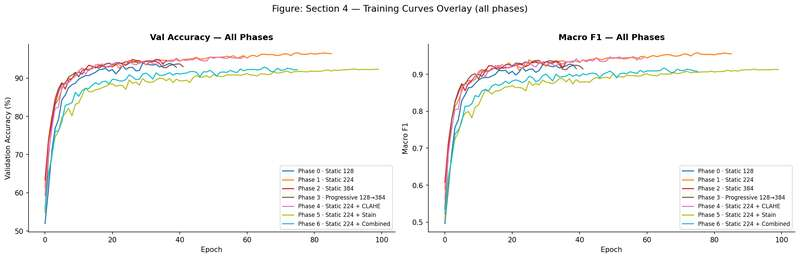

Saved: fig_prep_curves_overlay.png

  PREPROCESSING WINNER
  Key       : phase1_static224
  Val Acc   : 96.66%
  Macro F1  : 0.9583
  Pre-fn    : None
  Eval size : 224

  Section 4 complete — preprocessing winner locked.


In [ ]:
# ── Cell 31: Preprocessing Ablation — Comparison + Winner ────────────────────

_phase_labels = {
    'phase0_static128'    : 'Phase 0 · Static 128',
    'phase1_static224'    : 'Phase 1 · Static 224',
    'phase2_static384'    : 'Phase 2 · Static 384',
    'phase3_progressive'  : 'Phase 3 · Progressive 128→384',
    'phase4_224_clahe'    : 'Phase 4 · Static 224 + CLAHE',
    'phase5_224_stain'    : 'Phase 5 · Static 224 + Stain',
    'phase6_224_combined' : 'Phase 6 · Static 224 + Combined',
}

_rows = []
for key, name in _phase_labels.items():
    r = RESULTS_PREP[key]
    _rows.append({
        'Phase'          : name,
        'Val Acc (%)'    : round(r['val_acc'],  2),
        'Macro F1'       : round(r['macro_f1'], 4),
        'Time (min)'     : round(r['total_time_min'], 1),
    })

df_prep = pd.DataFrame(_rows).sort_values(
    'Val Acc (%)', ascending=False
).reset_index(drop=True)

print('\n' + '=' * 65)
print('  SECTION 4 — PREPROCESSING ABLATION RESULTS')
print('=' * 65)
print(df_prep.to_string(index=False))
print('=' * 65)

# ── Bar chart ─────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

_names = [r['Phase'] for r in _rows]
_accs  = [r['Val Acc (%)'] for r in _rows]
_f1s   = [r['Macro F1']    for r in _rows]
_colors = ['#4A90D9'] * len(_names)
_best_idx = int(np.argmax(_accs))
_colors[_best_idx] = '#E84040'

axes[0].barh(_names, _accs, color=_colors, edgecolor='white')
axes[0].set_xlabel('Validation Accuracy (%)')
axes[0].set_title('Preprocessing Ablation — Val Accuracy',
                  fontsize=12, fontweight='bold')
for i, v in enumerate(_accs):
    axes[0].text(v + 0.2, i, f'{v:.2f}%', va='center', fontsize=9)

axes[1].barh(_names, _f1s, color=_colors, edgecolor='white')
axes[1].set_xlabel('Macro F1')
axes[1].set_title('Preprocessing Ablation — Macro F1',
                  fontsize=12, fontweight='bold')
for i, v in enumerate(_f1s):
    axes[1].text(v + 0.002, i, f'{v:.4f}', va='center', fontsize=9)

for ax in axes:
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)

plt.suptitle('Figure: Section 4 — Preprocessing Ablation Comparison',
             fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(CHECKPOINT_DIR / 'fig_prep_ablation_comparison.png',
            bbox_inches='tight', dpi=150)
plt.show()
print('Saved: fig_prep_ablation_comparison.png')

# ── Training curves overlay ───────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
_curve_colors = plt.cm.tab10(np.linspace(0, 1, len(_phase_labels)))

for i, (key, name) in enumerate(_phase_labels.items()):
    h = RESULTS_PREP[key]['history']
    axes[0].plot(h['val_acc'],  color=_curve_colors[i],
                 linewidth=1.5, label=name)
    axes[1].plot(h['macro_f1'], color=_curve_colors[i],
                 linewidth=1.5, label=name)

for ax, title, ylabel in zip(
    axes,
    ['Val Accuracy — All Phases', 'Macro F1 — All Phases'],
    ['Validation Accuracy (%)', 'Macro F1']
):
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Epoch')
    ax.set_ylabel(ylabel)
    ax.legend(fontsize=8, loc='lower right')
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)

plt.suptitle('Figure: Section 4 — Training Curves Overlay (all phases)',
             fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(CHECKPOINT_DIR / 'fig_prep_curves_overlay.png',
            bbox_inches='tight', dpi=150)
plt.show()
print('Saved: fig_prep_curves_overlay.png')

# ── Lock winner ───────────────────────────────────────────────────────────────
PREP_WINNER_KEY = df_prep.iloc[0]['Phase']
PREP_WINNER_KEY = [k for k, v in _phase_labels.items()
                   if v == PREP_WINNER_KEY][0]
PREP_WINNER     = RESULTS_PREP[PREP_WINNER_KEY]

# Resolve winner pre_fn and eval transform for use in Section 5
_winner_pre_map = {
    'phase0_static128'    : (None,               EVL_128, 128),
    'phase1_static224'    : (None,               EVL_224, 224),
    'phase2_static384'    : (None,               EVL_384, 384),
    'phase3_progressive'  : (None,               EVL_384, 384),
    'phase4_224_clahe'    : (PRE_FN['clahe'],    EVL_224, 224),
    'phase5_224_stain'    : (None,               EVL_224, 224),
    'phase6_224_combined' : (None,               EVL_224, 224),
}
WINNER_PRE_FN, WINNER_EVL_TF, WINNER_SIZE = \
    _winner_pre_map[PREP_WINNER_KEY]

print('\n' + '=' * 65)
print('  PREPROCESSING WINNER')
print('=' * 65)
print(f'  Key       : {PREP_WINNER_KEY}')
print(f'  Val Acc   : {PREP_WINNER["val_acc"]:.2f}%')
print(f'  Macro F1  : {PREP_WINNER["macro_f1"]:.4f}')
print(f'  Pre-fn    : {WINNER_PRE_FN}')
print(f'  Eval size : {WINNER_SIZE}')
print('=' * 65)
print('\n  Section 4 complete — preprocessing winner locked.')

## Section 4 - Imbalance Strategy Ablation
### Stream A - Ovarian Cancer Histopathology
---
**This section covers:**
- Strategy 0 : No handling - vanilla CE (lower-bound)
- Strategy 1 : Random Over-Sampling (ROS)
- Strategy 2 : Effective-Number WCE (Cui et al. 2019)
- Strategy 3 : LDAM + Deferred Re-Weighting (DRW)
- Strategy 4 : Focal Loss (γ = 2)
- Strategy 5 : cRT - Decoupled Re-Training
- Comparison table · ROC-AUC · confusion matrices · winner locked

**Fixed across all strategies:**
Model = `ConvNeXtSingleCBAM` · Preprocessing = §3 winner · Epochs = 100 · Patience = 10

In [ ]:
# ── Cell 32: Custom Loss Functions ────────────────────────────────────────────

# ── LDAM Loss (Label-Distribution-Aware Margin) ───────────────────────────────
class LDAMLoss(nn.Module):
    """
    LDAM Loss — Cao et al. 2019.
    Imposes larger margins on minority classes.
    Used with Deferred Re-Weighting (DRW) scheduler.

    Parameters
    ----------
    cls_num_list : list of int  — per-class sample counts
    max_m        : float        — maximum margin magnitude
    weight       : Tensor|None  — class weights (activated in DRW phase)
    s            : float        — logit scaling factor
    """
    def __init__(self, cls_num_list, max_m=0.5, weight=None, s=30):
        super().__init__()
        m_list  = 1.0 / np.sqrt(np.sqrt(np.array(cls_num_list,
                                                   dtype=float)))
        m_list  = m_list * (max_m / m_list.max())
        self.m_list = torch.FloatTensor(m_list).to(device)
        self.s      = s
        self.weight = weight

    def set_weight(self, weight):
        self.weight = weight

    def forward(self, logits, targets):
        index = torch.zeros_like(logits, dtype=torch.bool)
        index.scatter_(1, targets.unsqueeze(1), True)
        logits_m = logits - self.m_list.unsqueeze(0) * index.float()
        output   = torch.where(index, logits_m, logits)
        return F.cross_entropy(
            self.s * output, targets,
            weight=self.weight, label_smoothing=0.1
        )


# ── Focal Loss ────────────────────────────────────────────────────────────────
class FocalLoss(nn.Module):
    """
    Focal Loss — Lin et al. 2017.
    Down-weights easy examples; focuses training on hard samples.

    Parameters
    ----------
    gamma  : float        — focusing parameter (default 2.0)
    weight : Tensor|None  — optional class weights
    """
    def __init__(self, gamma=2.0, weight=None):
        super().__init__()
        self.gamma  = gamma
        self.weight = weight

    def forward(self, logits, targets):
        ce    = F.cross_entropy(
            logits, targets,
            weight=self.weight, reduction='none'
        )
        pt    = torch.exp(-ce)
        focal = ((1 - pt) ** self.gamma) * ce
        return focal.mean()


print('=' * 55)
print('  CUSTOM LOSS FUNCTIONS')
print('=' * 55)
print('  LDAMLoss   : defined  (max_m=0.5 · s=30)')
print('  FocalLoss  : defined  (γ=2.0)')
print('=' * 55)
print('Cell 32 complete.')

  CUSTOM LOSS FUNCTIONS
  LDAMLoss   : defined  (max_m=0.5 · s=30)
  FocalLoss  : defined  (γ=2.0)
Cell 32 complete.


In [ ]:
# ── Cell 33: run_imbalance_experiment() ───────────────────────────────────────
# Single reusable function for all 6 imbalance strategies.
# Automatically handles progressive vs static winner preprocessing.

# Only phase3 is actually progressive — everything else is static
_IS_PROGRESSIVE = PREP_WINNER_KEY == 'phase3_progressive'

_PROG_STAGES = [
    (128, BASE_BATCH * 2,  34, AUG_128, EVL_128),
    (224, BASE_BATCH,      33, AUG_224, EVL_224),
    (384, BASE_BATCH // 2, 33, AUG_384, EVL_384),
]


def run_imbalance_experiment(label, criterion,
                              use_ros=False,
                              backbone_lr=2e-5,
                              head_lr=2e-4):
    """
    Train ConvNeXtSingleCBAM with §4 winner preprocessing.
    Handles progressive and static winner cases automatically.

    Parameters
    ----------
    label       : str          — experiment name, used for ckpt filename
    criterion   : nn.Module    — loss function
    use_ros     : bool         — use WeightedRandomSampler instead of shuffle
    backbone_lr : float        — learning rate for backbone param group
    head_lr     : float        — learning rate for head param group

    Returns
    -------
    dict — val_acc, macro_f1, ckpt, history, total_time_min
    """
    ckpt_path  = CHECKPOINT_DIR / f'best_{label}.pth'
    model      = ConvNeXtSingleCBAM().to(device)
    best_acc   = 0.0
    best_f1    = 0.0
    no_imp     = 0
    history    = {
        'train_loss': [], 'train_acc': [],
        'val_acc'   : [], 'macro_f1' : []
    }
    global_ep  = 0
    t0_total   = time.time()

    n_p = sum(p.numel() for p in model.parameters()) / 1e6
    print(f'\n{"=" * 65}')
    print(f'  {label}  |  {EPOCHS} ep  |  {n_p:.1f}M params')
    print(f'  Criterion    : {criterion.__class__.__name__}')
    print(f'  ROS sampler  : {use_ros}')
    print(f'  Progressive  : {_IS_PROGRESSIVE}')
    print(f'{"=" * 65}')

    stages = _PROG_STAGES if _IS_PROGRESSIVE else [
        (WINNER_SIZE, BASE_BATCH if WINNER_SIZE < 384
         else BASE_BATCH // 2, EPOCHS, None, WINNER_EVL_TF)
    ]

    for stage_idx, stage in enumerate(stages):
        _size, _batch, _eps, _aug_tf, _evl_tf = stage

        if not _IS_PROGRESSIVE:
            _aug_tf = make_transforms(_size)[0]

        if _IS_PROGRESSIVE:
            print(f'\n  ── Stage {stage_idx + 1}: {_size}×{_size}  '
                  f'({_eps} epochs · batch {_batch}) ──')

        sampler = None
        _train_ds = OvarianDataset(
            train_paths, train_labels,
            transform=_aug_tf, pre_fn=WINNER_PRE_FN,
            input_size=_size
        )
        _test_ds = OvarianDataset(
            test_paths, test_labels,
            transform=_evl_tf, pre_fn=WINNER_PRE_FN,
            input_size=_size
        )

        if use_ros:
            sampler = make_weighted_sampler(train_labels)

        _train_ldr = make_loader(_train_ds, batch_size=_batch,
                                  sampler=sampler)
        _test_ldr  = make_loader(_test_ds,  batch_size=_batch,
                                  shuffle=False)

        bb_p, ot_p = model.get_param_groups()
        optimizer  = optim.AdamW(
            [{'params': bb_p, 'lr': backbone_lr},
             {'params': ot_p, 'lr': head_lr}],
            weight_decay=1e-4
        )
        scheduler  = OneCycleLR(
            optimizer,
            max_lr          = [backbone_lr * 5, head_lr * 5],
            steps_per_epoch = len(_train_ldr),
            epochs          = _eps,
            pct_start       = 0.1,
            anneal_strategy = 'cos',
        )
        scaler = torch.cuda.amp.GradScaler()

        for ep in range(1, _eps + 1):
            global_ep += 1
            model.train()
            run_loss = 0.0
            correct  = 0
            total    = 0
            t0 = time.time()

            for imgs, lbls in _train_ldr:
                imgs, lbls = imgs.to(device), lbls.to(device)
                optimizer.zero_grad(set_to_none=True)
                with torch.cuda.amp.autocast():
                    out  = model(imgs)
                    loss = criterion(out, lbls)
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(optimizer)
                scaler.update()
                scheduler.step()
                run_loss += loss.item()
                preds     = out.argmax(1)
                correct  += (preds == lbls).sum().item()
                total    += lbls.size(0)

            model.eval()
            val_correct = 0
            val_total   = 0
            all_preds   = []
            all_labels  = []
            with torch.no_grad():
                for imgs, lbls in _test_ldr:
                    imgs, lbls = imgs.to(device), lbls.to(device)
                    with torch.cuda.amp.autocast():
                        preds = model(imgs).argmax(1)
                    val_correct += (preds == lbls).sum().item()
                    val_total   += lbls.size(0)
                    all_preds.extend(preds.cpu().numpy())
                    all_labels.extend(lbls.cpu().numpy())

            train_acc = 100. * correct / total
            val_acc   = 100. * val_correct / val_total
            macro_f1  = f1_score(all_labels, all_preds,
                                  average='macro', zero_division=0)
            avg_loss  = run_loss / len(_train_ldr)

            history['train_loss'].append(avg_loss)
            history['train_acc'] .append(train_acc)
            history['val_acc']   .append(val_acc)
            history['macro_f1']  .append(macro_f1)

            if val_acc > best_acc:
                best_acc = val_acc
                best_f1  = macro_f1
                torch.save(model.state_dict(), ckpt_path)
                no_imp = 0
            else:
                no_imp += 1

            tag = f' | No improve: {no_imp}/{PATIENCE}' if no_imp else ''
            print(f'  Ep {global_ep:>3}/{EPOCHS} | '
                  f'Loss:{avg_loss:.4f} | '
                  f'Train:{train_acc:.2f}% | '
                  f'Val:{val_acc:.2f}% | '
                  f'LR:{optimizer.param_groups[1]["lr"]:.2e} | '
                  f'Best:{best_acc:.2f}%{tag} | '
                  f'{time.time() - t0:.1f}s')

            if no_imp >= PATIENCE:
                print(f'\n  Early stop at epoch {global_ep}.')
                break

        del _train_ds, _test_ds, _train_ldr, _test_ldr
        torch.cuda.empty_cache()

        if no_imp >= PATIENCE:
            break

    total_time = time.time() - t0_total
    print(f'\n  {label}  |  Best Val: {best_acc:.2f}%  |  '
          f'Macro F1: {best_f1:.4f}  |  '
          f'Time: {total_time / 60:.1f} min')

    return {
        'label'         : label,
        'val_acc'       : best_acc,
        'macro_f1'      : best_f1,
        'ckpt'          : ckpt_path,
        'history'       : history,
        'model'         : model,
        'total_time_min': total_time / 60,
    }


print('run_imbalance_experiment() defined.')
print(f'  Winner preprocessing : {PREP_WINNER_KEY}')
print(f'  Progressive mode     : {_IS_PROGRESSIVE}')
print('Cell 33 complete.')

run_imbalance_experiment() defined.
  Winner preprocessing : phase1_static224
  Progressive mode     : False
Cell 33 complete.


  STRATEGY 0 : No Imbalance Handling
  Loss     : CrossEntropyLoss  (uniform weights)
  Sampler  : Standard shuffle
  Purpose  : Lower-bound — shows raw imbalance damage

... [epoch-by-epoch training log truncated for GitHub] ...

  Ep  49/100 | Loss:0.4464 | Train:97.16% | Val:95.00% | LR:6.04e-04 | Best:95.65% | No improve: 3/10 | 65.9s
  Ep  50/100 | Loss:0.4468 | Train:97.20% | Val:95.43% | LR:5.87e-04 | Best:95.65% | No improve: 4/10 | 65.7s
  Ep  51/100 | Loss:0.4449 | Train:97.22% | Val:95.13% | LR:5.70e-04 | Best:95.65% | No improve: 5/10 | 66.0s
  Ep  52/100 | Loss:0.4437 | Train:97.29% | Val:95.36% | LR:5.52e-04 | Best:95.65% | No improve: 6/10 | 65.9s
  Ep  53/100 | Loss:0.4394 | Train:97.50% | Val:95.33% | LR:5.35e-04 | Best:95.65% | No improve: 7/10 | 66.1s
  Ep  54/100 | Loss:0.4409 | Train:97.46% | Val:95.85% | LR:5.17e-04 | Best:95.85% | 66.6s
  Ep  55/100 | Loss:0.4390 | Train:97.57% | Val:95.20% | LR:5.00e-04 | Best:95.85% | No improve: 1/10 | 65.8s
  Ep  56/100 | Los

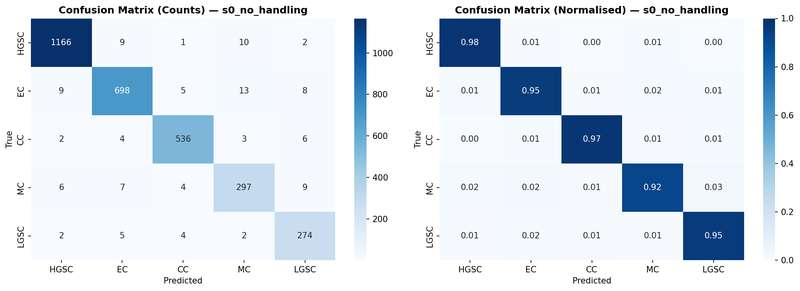

Saved: confusion_s0_no_handling.png


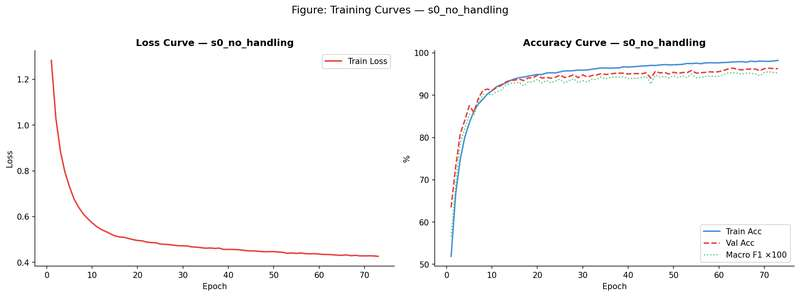

Saved: curves_s0_no_handling.png


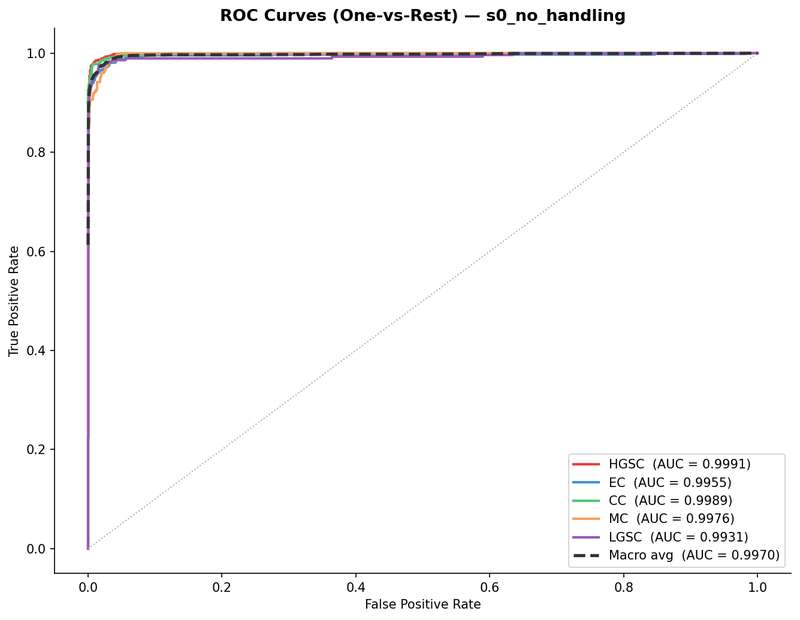

Saved: roc_s0_no_handling.png

  ROC-AUC SCORES — s0_no_handling
  HGSC   : 0.9991
  EC     : 0.9955
  CC     : 0.9989
  MC     : 0.9976
  LGSC   : 0.9931
  Macro  : 0.9970

  Strategy 0 complete.


In [ ]:
# ── Cell 34: Strategy 0 — No Handling (Vanilla CE) ───────────────────────────

print('=' * 65)
print('  STRATEGY 0 : No Imbalance Handling')
print('=' * 65)
print('  Loss     : CrossEntropyLoss  (uniform weights)')
print('  Sampler  : Standard shuffle')
print('  Purpose  : Lower-bound — shows raw imbalance damage')
print('=' * 65)

_criterion_s0 = nn.CrossEntropyLoss(label_smoothing=0.1)

RESULTS_IMBAL['s0_no_handling'] = run_imbalance_experiment(
    label     = 's0_no_handling',
    criterion = _criterion_s0,
    use_ros   = False,
)

_model_s0 = RESULTS_IMBAL['s0_no_handling']['model']
_eval_ds   = OvarianDataset(
    test_paths, test_labels,
    transform=WINNER_EVL_TF, pre_fn=WINNER_PRE_FN,
    input_size=WINNER_SIZE
)
_eval_ldr = make_loader(_eval_ds, batch_size=BASE_BATCH // 2,
                         shuffle=False)

_eval_s0 = evaluate(
    _model_s0, _eval_ldr,
    RESULTS_IMBAL['s0_no_handling']['ckpt'],
    's0_no_handling'
)
RESULTS_IMBAL['s0_no_handling'].update(_eval_s0)
plot_training_curves(
    RESULTS_IMBAL['s0_no_handling']['history'],
    's0_no_handling'
)
plot_roc_auc(
    RESULTS_IMBAL['s0_no_handling']['probs'],
    RESULTS_IMBAL['s0_no_handling']['labels'],
    's0_no_handling'
)

del _model_s0, _eval_ds, _eval_ldr
torch.cuda.empty_cache()
print('\n  Strategy 0 complete.')

  STRATEGY 1 : Random Over-Sampling (ROS)
  Loss     : CrossEntropyLoss  (uniform weights)
  Sampler  : WeightedRandomSampler  (inverse frequency)
  Purpose  : Simple rebalancing — sample-level fix

... [epoch-by-epoch training log truncated for GitHub] ...

  Ep  74/100 | Loss:0.4284 | Train:98.11% | Val:95.91% | LR:1.92e-04 | Best:96.01% | No improve: 9/10 | 66.0s
  Ep  75/100 | Loss:0.4270 | Train:98.18% | Val:96.14% | LR:1.79e-04 | Best:96.14% | 66.8s
  Ep  76/100 | Loss:0.4301 | Train:98.04% | Val:95.85% | LR:1.65e-04 | Best:96.14% | No improve: 1/10 | 65.8s
  Ep  77/100 | Loss:0.4284 | Train:98.11% | Val:95.65% | LR:1.53e-04 | Best:96.14% | No improve: 2/10 | 65.8s
  Ep  78/100 | Loss:0.4270 | Train:98.15% | Val:95.91% | LR:1.40e-04 | Best:96.14% | No improve: 3/10 | 66.1s
  Ep  79/100 | Loss:0.4256 | Train:98.17% | Val:95.91% | LR:1.28e-04 | Best:96.14% | No improve: 4/10 | 66.1s
  Ep  80/100 | Loss:0.4281 | Train:98.08% | Val:95.88% | LR:1.17e-04 | Best:96.14% | No improve: 5/1

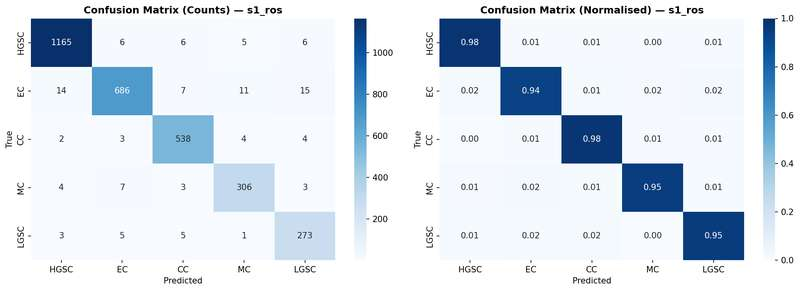

Saved: confusion_s1_ros.png


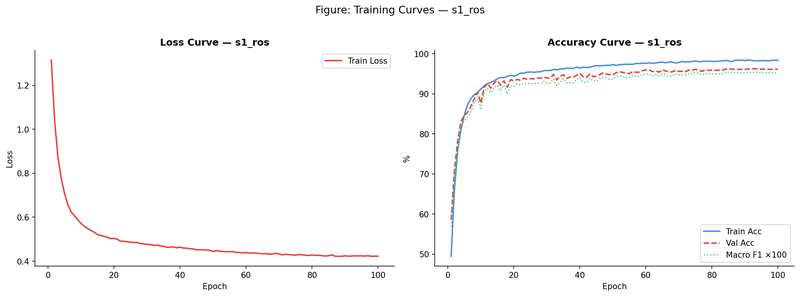

Saved: curves_s1_ros.png


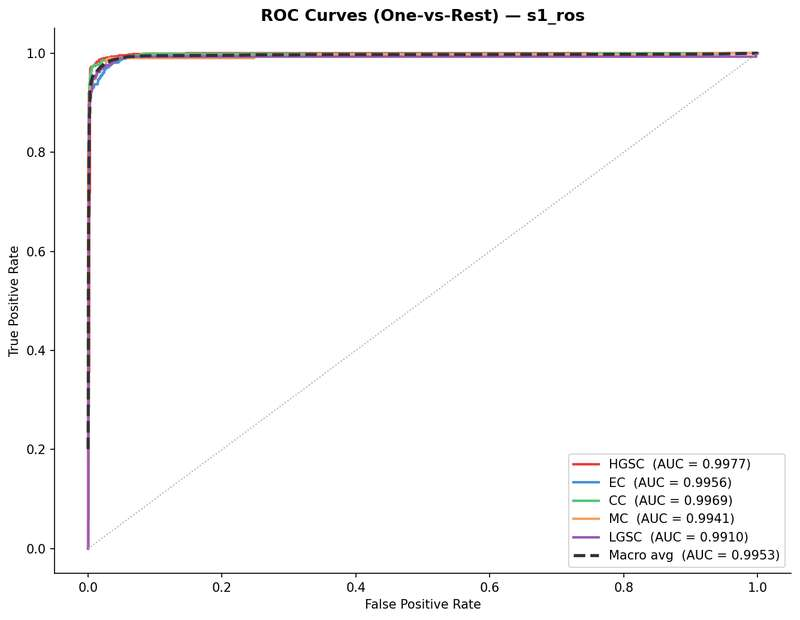

Saved: roc_s1_ros.png

  ROC-AUC SCORES — s1_ros
  HGSC   : 0.9977
  EC     : 0.9956
  CC     : 0.9969
  MC     : 0.9941
  LGSC   : 0.9910
  Macro  : 0.9953

  Strategy 1 complete.


In [ ]:
# ── Cell 35: Strategy 1 — Random Over-Sampling (ROS) ─────────────────────────

print('=' * 65)
print('  STRATEGY 1 : Random Over-Sampling (ROS)')
print('=' * 65)
print('  Loss     : CrossEntropyLoss  (uniform weights)')
print('  Sampler  : WeightedRandomSampler  (inverse frequency)')
print('  Purpose  : Simple rebalancing — sample-level fix')
print('=' * 65)

_criterion_s1 = nn.CrossEntropyLoss(label_smoothing=0.1)

RESULTS_IMBAL['s1_ros'] = run_imbalance_experiment(
    label     = 's1_ros',
    criterion = _criterion_s1,
    use_ros   = True,
)

_model_s1 = RESULTS_IMBAL['s1_ros']['model']
_eval_ds   = OvarianDataset(
    test_paths, test_labels,
    transform=WINNER_EVL_TF, pre_fn=WINNER_PRE_FN,
    input_size=WINNER_SIZE
)
_eval_ldr = make_loader(_eval_ds, batch_size=BASE_BATCH // 2,
                         shuffle=False)

_eval_s1 = evaluate(
    _model_s1, _eval_ldr,
    RESULTS_IMBAL['s1_ros']['ckpt'],
    's1_ros'
)
RESULTS_IMBAL['s1_ros'].update(_eval_s1)
plot_training_curves(
    RESULTS_IMBAL['s1_ros']['history'],
    's1_ros'
)
plot_roc_auc(
    RESULTS_IMBAL['s1_ros']['probs'],
    RESULTS_IMBAL['s1_ros']['labels'],
    's1_ros'
)

del _model_s1, _eval_ds, _eval_ldr
torch.cuda.empty_cache()
print('\n  Strategy 1 complete.')

  STRATEGY 2 : Effective-Number Weighted CE
  Loss     : CrossEntropyLoss  (Eff-Num weights · β=0.9999)
  Sampler  : Standard shuffle
  Purpose  : Loss-level fix — theoretically principled weighting

... [epoch-by-epoch training log truncated for GitHub] ...

  Ep  50/100 | Loss:0.5205 | Train:97.18% | Val:95.17% | LR:5.87e-04 | Best:95.49% | No improve: 5/10 | 67.3s
  Ep  51/100 | Loss:0.5201 | Train:97.20% | Val:95.04% | LR:5.70e-04 | Best:95.49% | No improve: 6/10 | 67.1s
  Ep  52/100 | Loss:0.5194 | Train:97.28% | Val:95.00% | LR:5.52e-04 | Best:95.49% | No improve: 7/10 | 67.5s
  Ep  53/100 | Loss:0.5165 | Train:97.31% | Val:95.52% | LR:5.35e-04 | Best:95.52% | 68.1s
  Ep  54/100 | Loss:0.5137 | Train:97.38% | Val:95.49% | LR:5.17e-04 | Best:95.52% | No improve: 1/10 | 67.1s
  Ep  55/100 | Loss:0.5154 | Train:97.43% | Val:95.62% | LR:5.00e-04 | Best:95.62% | 67.9s
  Ep  56/100 | Loss:0.5138 | Train:97.46% | Val:95.39% | LR:4.83e-04 | Best:95.62% | No improve: 1/10 | 67.4s
  Ep  57

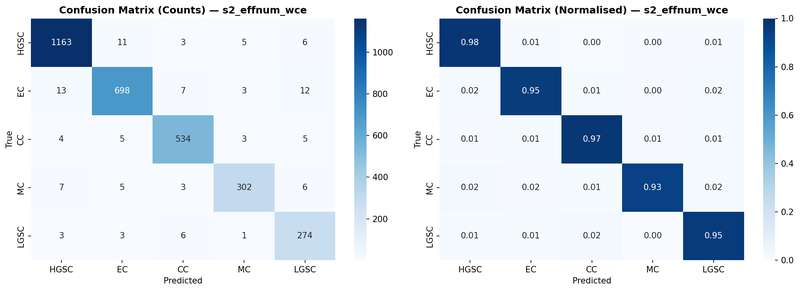

Saved: confusion_s2_effnum_wce.png


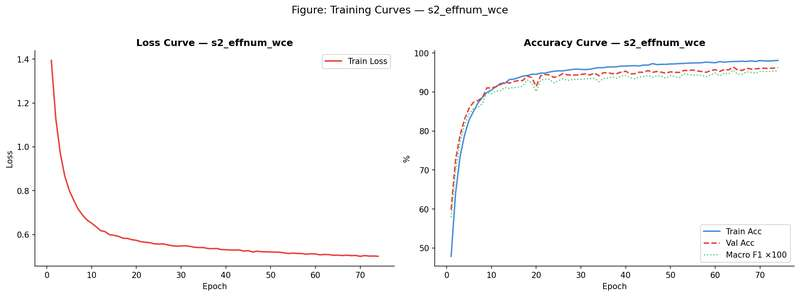

Saved: curves_s2_effnum_wce.png


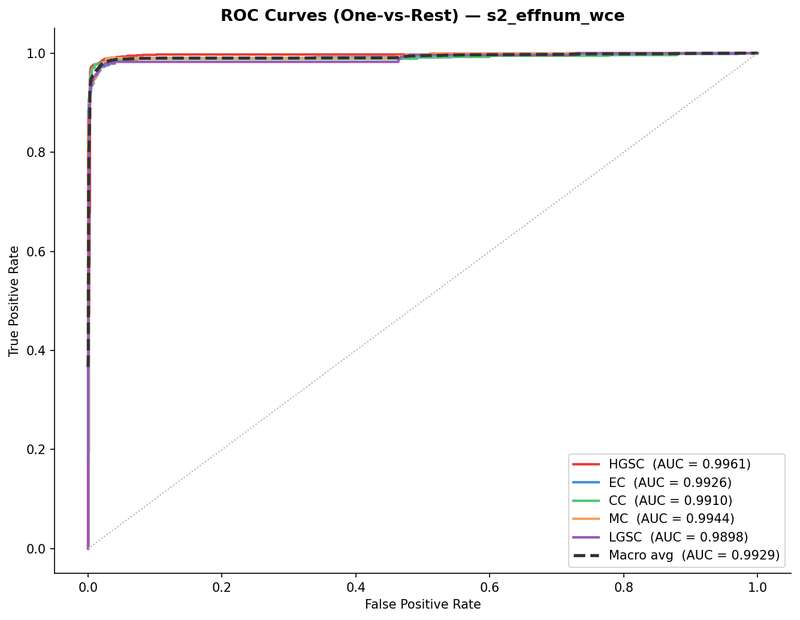

Saved: roc_s2_effnum_wce.png

  ROC-AUC SCORES — s2_effnum_wce
  HGSC   : 0.9961
  EC     : 0.9926
  CC     : 0.9910
  MC     : 0.9944
  LGSC   : 0.9898
  Macro  : 0.9929

  Strategy 2 complete.


In [ ]:
# ── Cell 36: Strategy 2 — Effective-Number WCE (Cui et al. 2019) ─────────────

print('=' * 65)
print('  STRATEGY 2 : Effective-Number Weighted CE')
print('=' * 65)
print('  Loss     : CrossEntropyLoss  (Eff-Num weights · β=0.9999)')
print('  Sampler  : Standard shuffle')
print('  Purpose  : Loss-level fix — theoretically principled weighting')
print('=' * 65)

_criterion_s2 = nn.CrossEntropyLoss(
    weight=EFF_NUM_WEIGHTS, label_smoothing=0.1
)

RESULTS_IMBAL['s2_effnum_wce'] = run_imbalance_experiment(
    label     = 's2_effnum_wce',
    criterion = _criterion_s2,
    use_ros   = False,
)

_model_s2 = RESULTS_IMBAL['s2_effnum_wce']['model']
_eval_ds   = OvarianDataset(
    test_paths, test_labels,
    transform=WINNER_EVL_TF, pre_fn=WINNER_PRE_FN,
    input_size=WINNER_SIZE
)
_eval_ldr = make_loader(_eval_ds, batch_size=BASE_BATCH // 2,
                         shuffle=False)

_eval_s2 = evaluate(
    _model_s2, _eval_ldr,
    RESULTS_IMBAL['s2_effnum_wce']['ckpt'],
    's2_effnum_wce'
)
RESULTS_IMBAL['s2_effnum_wce'].update(_eval_s2)
plot_training_curves(
    RESULTS_IMBAL['s2_effnum_wce']['history'],
    's2_effnum_wce'
)
plot_roc_auc(
    RESULTS_IMBAL['s2_effnum_wce']['probs'],
    RESULTS_IMBAL['s2_effnum_wce']['labels'],
    's2_effnum_wce'
)

del _model_s2, _eval_ds, _eval_ldr
torch.cuda.empty_cache()
print('\n  Strategy 2 complete.')

  STRATEGY 3 : LDAM + Deferred Re-Weighting (DRW)
  Loss     : LDAMLoss  (max_m=0.5 · s=30)
  DRW      : Eff-Num weights activated at epoch 51
  Sampler  : Standard shuffle

... [epoch-by-epoch training log truncated for GitHub] ...


  [DRW] Eff-Num weights activated at epoch 51
  Ep  51/100 | Loss:1.4540 | Train:96.07% | Val:95.04% | LR:5.70e-04 | Best:95.04% | 68.4s
  Ep  52/100 | Loss:1.4379 | Train:96.06% | Val:94.58% | LR:5.52e-04 | Best:95.04% | No improve: 1/10 | 67.7s
  Ep  53/100 | Loss:1.4239 | Train:96.20% | Val:94.13% | LR:5.35e-04 | Best:95.04% | No improve: 2/10 | 67.4s
  Ep  54/100 | Loss:1.4063 | Train:96.22% | Val:95.17% | LR:5.17e-04 | Best:95.17% | 68.4s
  Ep  55/100 | Loss:1.3756 | Train:96.48% | Val:95.00% | LR:5.00e-04 | Best:95.17% | No improve: 1/10 | 67.4s
  Ep  56/100 | Loss:1.3767 | Train:96.32% | Val:94.29% | LR:4.83e-04 | Best:95.17% | No improve: 2/10 | 67.5s
  Ep  57/100 | Loss:1.3468 | Train:96.44% | Val:94.74% | LR:4.65e-04 | Best:95.17% | No improve: 

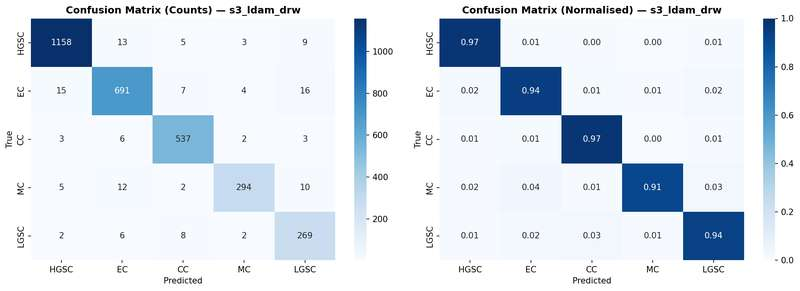

Saved: confusion_s3_ldam_drw.png


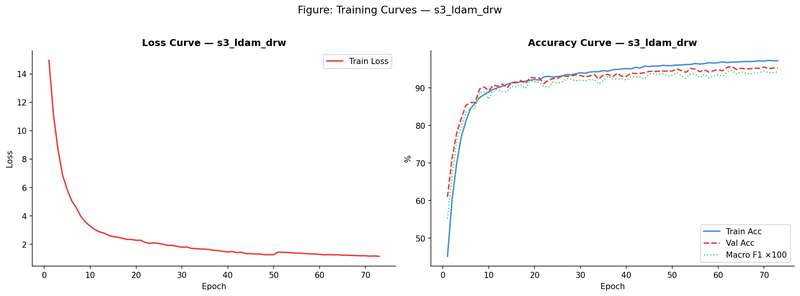

Saved: curves_s3_ldam_drw.png


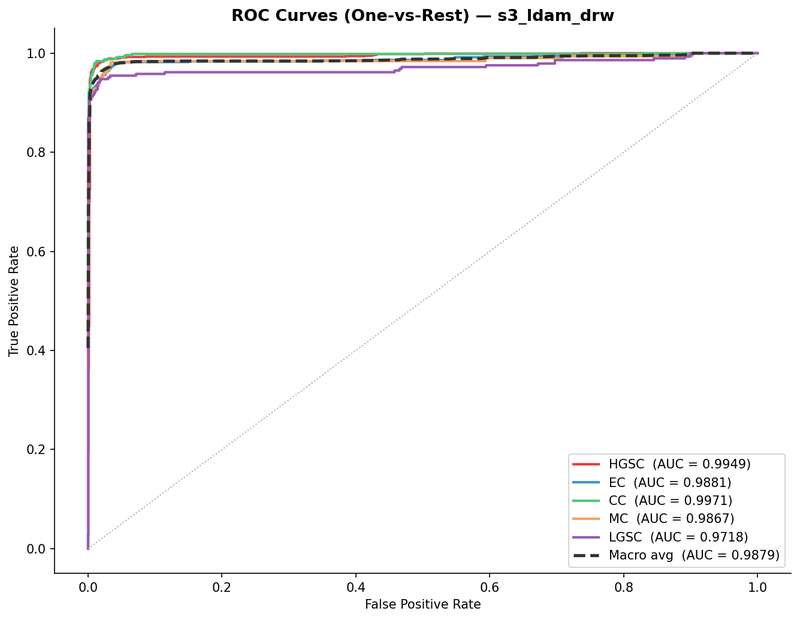

Saved: roc_s3_ldam_drw.png

  ROC-AUC SCORES — s3_ldam_drw
  HGSC   : 0.9949
  EC     : 0.9881
  CC     : 0.9971
  MC     : 0.9867
  LGSC   : 0.9718
  Macro  : 0.9879

  Strategy 3 complete.


In [ ]:
# ── Cell 37: Strategy 3 — LDAM + Deferred Re-Weighting (DRW) ─────────────────
#
# DRW schedule:
#   Epochs  1 – 50  : LDAM with uniform weights
#   Epochs 51 – 100 : LDAM with Eff-Num weights activated
# ──────────────────────────────────────────────────────────────────────────────

print('=' * 65)
print('  STRATEGY 3 : LDAM + Deferred Re-Weighting (DRW)')
print('=' * 65)
print('  Loss     : LDAMLoss  (max_m=0.5 · s=30)')
print('  DRW      : Eff-Num weights activated at epoch 51')
print('  Sampler  : Standard shuffle')
print('  Purpose  : Margin-based minority push + deferred balancing')
print('=' * 65)

_ckpt_s3   = CHECKPOINT_DIR / 'best_s3_ldam_drw.pth'
_criterion_s3 = LDAMLoss(
    cls_num_list = TRAIN_COUNTS,
    max_m        = 0.5,
    weight       = None,
    s            = 30,
)

_best_acc   = 0.0
_best_f1    = 0.0
_no_imp     = 0
_history_s3 = {
    'train_loss': [], 'train_acc': [],
    'val_acc'   : [], 'macro_f1' : []
}
_global_ep  = 0
_t0_total   = time.time()
_drw_epoch  = EPOCHS // 2      # activate re-weighting at midpoint

_model_s3   = ConvNeXtSingleCBAM().to(device)
n_p = sum(p.numel() for p in _model_s3.parameters()) / 1e6

print(f'\n{"=" * 65}')
print(f'  s3_ldam_drw  |  {EPOCHS} ep  |  {n_p:.1f}M params')
print(f'  DRW activates at epoch {_drw_epoch}')
print(f'{"=" * 65}')

stages = _PROG_STAGES if _IS_PROGRESSIVE else [
    (WINNER_SIZE,
     BASE_BATCH if WINNER_SIZE < 384 else BASE_BATCH // 2,
     EPOCHS, None, WINNER_EVL_TF)
]

for stage_idx, stage in enumerate(stages):
    _size, _batch, _eps, _aug_tf, _evl_tf = stage
    if not _IS_PROGRESSIVE:
        _aug_tf = make_transforms(_size)[0]

    if _IS_PROGRESSIVE:
        print(f'\n  ── Stage {stage_idx + 1}: {_size}×{_size}  '
              f'({_eps} epochs · batch {_batch}) ──')

    _train_ds  = OvarianDataset(
        train_paths, train_labels,
        transform=_aug_tf, pre_fn=WINNER_PRE_FN,
        input_size=_size
    )
    _test_ds   = OvarianDataset(
        test_paths, test_labels,
        transform=_evl_tf, pre_fn=WINNER_PRE_FN,
        input_size=_size
    )
    _train_ldr = make_loader(_train_ds, batch_size=_batch)
    _test_ldr  = make_loader(_test_ds,  batch_size=_batch,
                              shuffle=False)

    _bb_p, _ot_p = _model_s3.get_param_groups()
    _optimizer   = optim.AdamW(
        [{'params': _bb_p, 'lr': 2e-5},
         {'params': _ot_p, 'lr': 2e-4}],
        weight_decay=1e-4
    )
    _scheduler = OneCycleLR(
        _optimizer,
        max_lr          = [2e-5 * 5, 2e-4 * 5],
        steps_per_epoch = len(_train_ldr),
        epochs          = _eps,
        pct_start       = 0.1,
        anneal_strategy = 'cos',
    )
    _scaler = torch.cuda.amp.GradScaler()

    for _ep in range(1, _eps + 1):
        _global_ep += 1

        # ── DRW weight activation ─────────────────────────────────────────────
        if _global_ep == _drw_epoch + 1:
            _criterion_s3.set_weight(EFF_NUM_WEIGHTS)
            print(f'\n  [DRW] Eff-Num weights activated at epoch {_global_ep}')

        _model_s3.train()
        _run_loss = 0.0
        _correct  = 0
        _total    = 0
        _t0 = time.time()

        for _imgs, _lbls in _train_ldr:
            _imgs, _lbls = _imgs.to(device), _lbls.to(device)
            _optimizer.zero_grad(set_to_none=True)
            with torch.cuda.amp.autocast():
                _out  = _model_s3(_imgs)
                _loss = _criterion_s3(_out, _lbls)
            _scaler.scale(_loss).backward()
            _scaler.unscale_(_optimizer)
            torch.nn.utils.clip_grad_norm_(_model_s3.parameters(), 1.0)
            _scaler.step(_optimizer)
            _scaler.update()
            _scheduler.step()
            _run_loss += _loss.item()
            _preds     = _out.argmax(1)
            _correct  += (_preds == _lbls).sum().item()
            _total    += _lbls.size(0)

        _model_s3.eval()
        _val_correct = 0
        _val_total   = 0
        _all_preds   = []
        _all_labels  = []
        with torch.no_grad():
            for _imgs, _lbls in _test_ldr:
                _imgs, _lbls = _imgs.to(device), _lbls.to(device)
                with torch.cuda.amp.autocast():
                    _preds = _model_s3(_imgs).argmax(1)
                _val_correct += (_preds == _lbls).sum().item()
                _val_total   += _lbls.size(0)
                _all_preds.extend(_preds.cpu().numpy())
                _all_labels.extend(_lbls.cpu().numpy())

        _train_acc = 100. * _correct / _total
        _val_acc   = 100. * _val_correct / _val_total
        _macro_f1  = f1_score(_all_labels, _all_preds,
                               average='macro', zero_division=0)
        _avg_loss  = _run_loss / len(_train_ldr)

        _history_s3['train_loss'].append(_avg_loss)
        _history_s3['train_acc'] .append(_train_acc)
        _history_s3['val_acc']   .append(_val_acc)
        _history_s3['macro_f1']  .append(_macro_f1)

        if _val_acc > _best_acc:
            _best_acc = _val_acc
            _best_f1  = _macro_f1
            torch.save(_model_s3.state_dict(), _ckpt_s3)
            _no_imp = 0
        else:
            _no_imp += 1

        _tag = f' | No improve: {_no_imp}/{PATIENCE}' if _no_imp else ''
        print(f'  Ep {_global_ep:>3}/{EPOCHS} | '
              f'Loss:{_avg_loss:.4f} | '
              f'Train:{_train_acc:.2f}% | '
              f'Val:{_val_acc:.2f}% | '
              f'LR:{_optimizer.param_groups[1]["lr"]:.2e} | '
              f'Best:{_best_acc:.2f}%{_tag} | '
              f'{time.time() - _t0:.1f}s')

        if _no_imp >= PATIENCE:
            print(f'\n  Early stop at epoch {_global_ep}.')
            break

    del _train_ds, _test_ds, _train_ldr, _test_ldr
    torch.cuda.empty_cache()

    if _no_imp >= PATIENCE:
        break

_total_time = time.time() - _t0_total
print(f'\n  s3_ldam_drw  |  Best Val: {_best_acc:.2f}%  |  '
      f'Macro F1: {_best_f1:.4f}  |  '
      f'Time: {_total_time / 60:.1f} min')

RESULTS_IMBAL['s3_ldam_drw'] = {
    'label'         : 's3_ldam_drw',
    'val_acc'       : _best_acc,
    'macro_f1'      : _best_f1,
    'ckpt'          : _ckpt_s3,
    'history'       : _history_s3,
    'model'         : _model_s3,
    'total_time_min': _total_time / 60,
}

_eval_ds  = OvarianDataset(
    test_paths, test_labels,
    transform=WINNER_EVL_TF, pre_fn=WINNER_PRE_FN,
    input_size=WINNER_SIZE
)
_eval_ldr = make_loader(_eval_ds, batch_size=BASE_BATCH // 2,
                         shuffle=False)

_eval_s3 = evaluate(
    _model_s3, _eval_ldr, _ckpt_s3, 's3_ldam_drw'
)
RESULTS_IMBAL['s3_ldam_drw'].update(_eval_s3)
plot_training_curves(_history_s3, 's3_ldam_drw')
plot_roc_auc(
    RESULTS_IMBAL['s3_ldam_drw']['probs'],
    RESULTS_IMBAL['s3_ldam_drw']['labels'],
    's3_ldam_drw'
)

del _model_s3, _eval_ds, _eval_ldr
torch.cuda.empty_cache()
print('\n  Strategy 3 complete.')

  STRATEGY 4 : Focal Loss  (γ = 2)
  Loss     : FocalLoss  (γ=2.0 · no class weights)
  Sampler  : Standard shuffle
  Purpose  : Hard-example mining — down-weights easy samples

  s4_focal  |  100 ep  |  88.8M params
  Criterion    : FocalLoss
  ROS sampler  : False
  Progressive  : False
  Ep   1/100 | Loss:0.6981 | Train:51.13% | Val:64.15% | LR:6.35e-05 | Best:64.15% | 68.8s
  Ep   2/100 | Loss:0.4572 | Train:65.78% | Val:73.75% | LR:1.32e-04 | Best:73.75% | 66.3s
  Ep   3/100 | Loss:0.3288 | Train:73.76% | Val:78.91% | LR:2.38e-04 | Best:78.91% | 66.3s
  Ep   4/100 | Loss:0.2567 | Train:78.90% | Val:83.03% | LR:3.72e-04 | Best:83.03% | 66.4s
  Ep   5/100 | Loss:0.2133 | Train:82.44% | Val:84.98% | LR:5.20e-04 | Best:84.98% | 67.3s
  Ep   6/100 | Loss:0.1849 | Train:84.40% | Val:85.20% | LR:6.69e-04 | Best:85.20% | 66.4s
  Ep   7/100 | Loss:0.1636 | Train:85.99% | Val:88.32% | LR:8.02e-04 | Best:88.32% | 66.3s
  Ep   8/100 | Loss:0.1477 | Train:87.32% | Val:86.15% | LR:9.08e-04 | Be

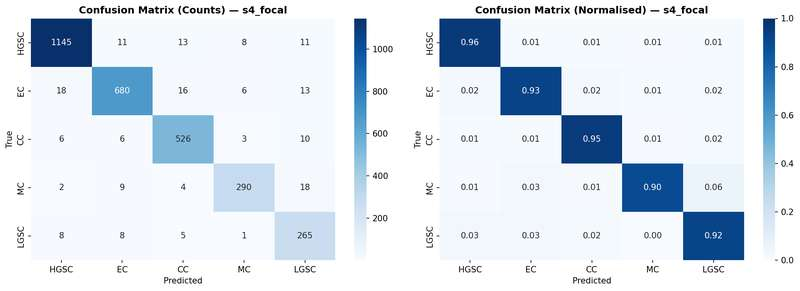

Saved: confusion_s4_focal.png


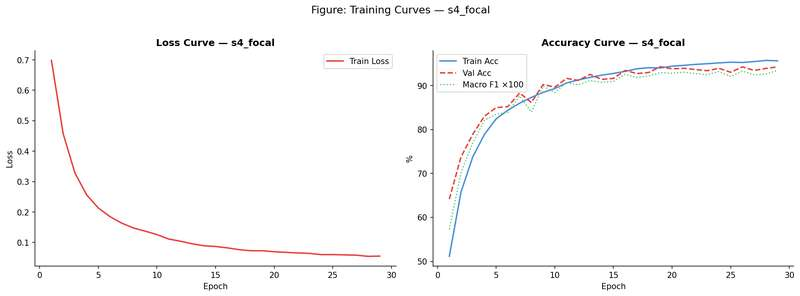

Saved: curves_s4_focal.png


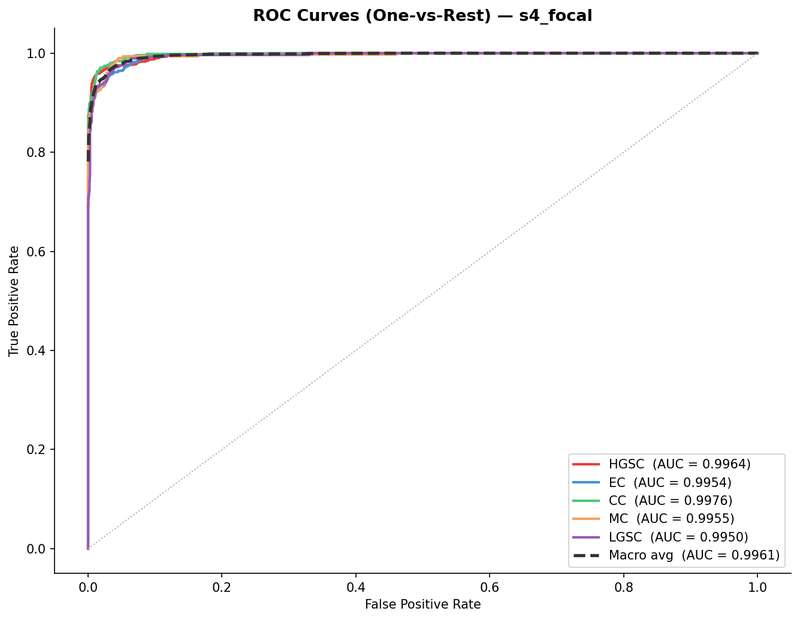

Saved: roc_s4_focal.png

  ROC-AUC SCORES — s4_focal
  HGSC   : 0.9964
  EC     : 0.9954
  CC     : 0.9976
  MC     : 0.9955
  LGSC   : 0.9950
  Macro  : 0.9961

  Strategy 4 complete.


In [ ]:
# ── Cell 38: Strategy 4 — Focal Loss (γ = 2) ─────────────────────────────────

print('=' * 65)
print('  STRATEGY 4 : Focal Loss  (γ = 2)')
print('=' * 65)
print('  Loss     : FocalLoss  (γ=2.0 · no class weights)')
print('  Sampler  : Standard shuffle')
print('  Purpose  : Hard-example mining — down-weights easy samples')
print('=' * 65)

_criterion_s4 = FocalLoss(gamma=2.0, weight=None)

RESULTS_IMBAL['s4_focal'] = run_imbalance_experiment(
    label     = 's4_focal',
    criterion = _criterion_s4,
    use_ros   = False,
)

_model_s4 = RESULTS_IMBAL['s4_focal']['model']
_eval_ds   = OvarianDataset(
    test_paths, test_labels,
    transform=WINNER_EVL_TF, pre_fn=WINNER_PRE_FN,
    input_size=WINNER_SIZE
)
_eval_ldr = make_loader(_eval_ds, batch_size=BASE_BATCH // 2,
                         shuffle=False)

_eval_s4 = evaluate(
    _model_s4, _eval_ldr,
    RESULTS_IMBAL['s4_focal']['ckpt'],
    's4_focal'
)
RESULTS_IMBAL['s4_focal'].update(_eval_s4)
plot_training_curves(
    RESULTS_IMBAL['s4_focal']['history'],
    's4_focal'
)
plot_roc_auc(
    RESULTS_IMBAL['s4_focal']['probs'],
    RESULTS_IMBAL['s4_focal']['labels'],
    's4_focal'
)

del _model_s4, _eval_ds, _eval_ldr
torch.cuda.empty_cache()
print('\n  Strategy 4 complete.')

  STRATEGY 5 : cRT — Decoupled Re-Training
  Stage 1  : Full model · standard CE · 100 ep
  Stage 2  : Head only · Eff-Num WCE · ROS · 30 ep
  Purpose  : Decoupled representation + classifier fix

... [epoch-by-epoch training log truncated for GitHub] ...


  s5_crt_stage2  |  30 ep  |  head only
  Criterion : CrossEntropyLoss  (Eff-Num · ROS)
  Ep   1/30 | Loss:0.4846 | Train:96.31% | Val:95.04% | LR:2.80e-04 | Best:95.04% | 37.1s
  Ep   2/30 | Loss:0.4455 | Train:96.81% | Val:94.65% | LR:7.61e-04 | Best:95.04% | No improve: 1/10 | 34.1s
  Ep   3/30 | Loss:0.4407 | Train:96.87% | Val:95.00% | LR:1.00e-03 | Best:95.04% | No improve: 2/10 | 34.1s
  Ep   4/30 | Loss:0.4360 | Train:97.14% | Val:94.91% | LR:9.97e-04 | Best:95.04% | No improve: 3/10 | 34.2s
  Ep   5/30 | Loss:0.4343 | Train:97.07% | Val:95.20% | LR:9.86e-04 | Best:95.20% | 35.3s
  Ep   6/30 | Loss:0.4391 | Train:97.02% | Val:95.23% | LR:9.70e-04 | Best:95.23% | 34.9s
  Ep   7/30 | Loss:0.4329 | Train:97.15% | Val:95.20% | L

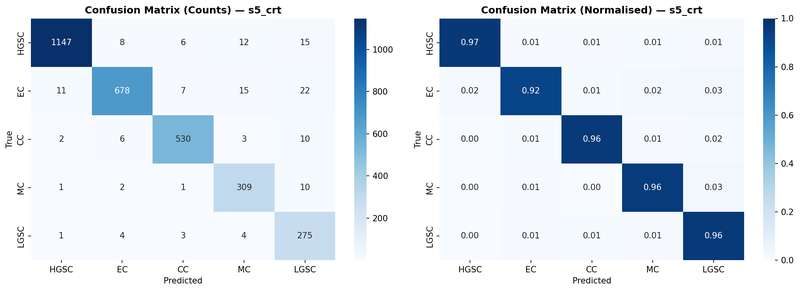

Saved: confusion_s5_crt.png


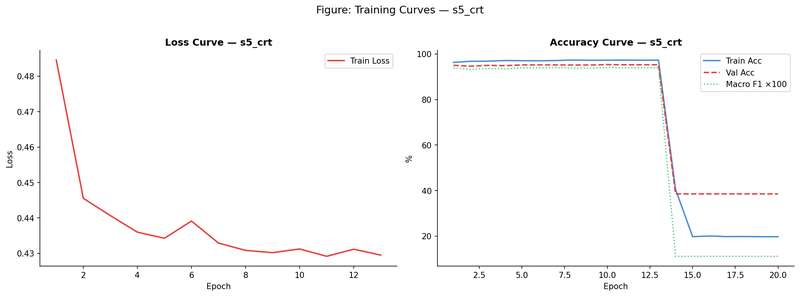

Saved: curves_s5_crt.png


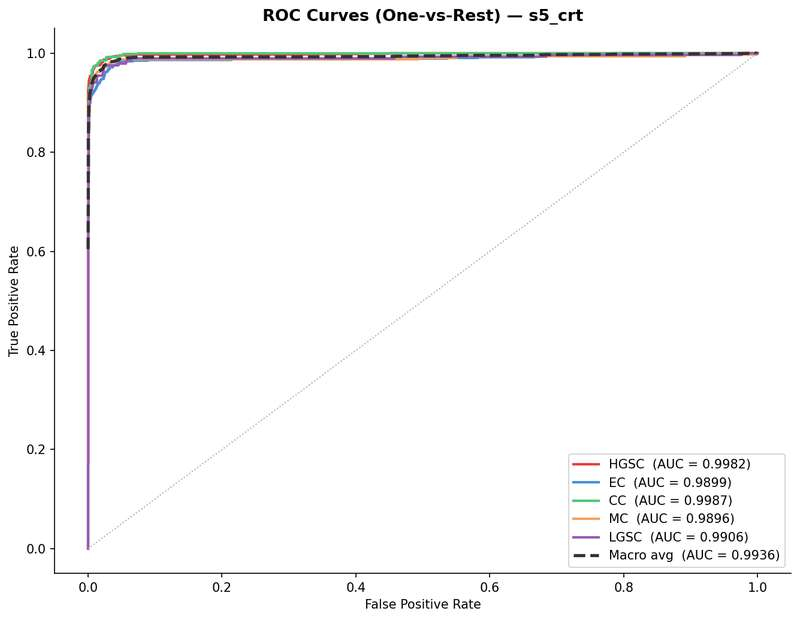

Saved: roc_s5_crt.png

  ROC-AUC SCORES — s5_crt
  HGSC   : 0.9982
  EC     : 0.9899
  CC     : 0.9987
  MC     : 0.9896
  LGSC   : 0.9906
  Macro  : 0.9936

  Strategy 5 complete.


In [ ]:
# ── Cell 39: Strategy 5 — cRT Decoupled Re-Training ──────────────────────────
#
# Stage 1 : Train full model — instance-balanced sampling, vanilla CE
#           100 epochs with early stopping
# Stage 2 : Freeze backbone — re-train head only
#           class-balanced sampler, Eff-Num WCE, 30 epochs
# ──────────────────────────────────────────────────────────────────────────────

print('=' * 65)
print('  STRATEGY 5 : cRT — Decoupled Re-Training')
print('=' * 65)
print('  Stage 1  : Full model · standard CE · 100 ep')
print('  Stage 2  : Head only · Eff-Num WCE · ROS · 30 ep')
print('  Purpose  : Decoupled representation + classifier fix')
print('=' * 65)

_ckpt_s5_stage1 = CHECKPOINT_DIR / 'best_s5_crt_stage1.pth'
_ckpt_s5_stage2 = CHECKPOINT_DIR / 'best_s5_crt_stage2.pth'

# ── Stage 1: Full model training ─────────────────────────────────────────────
print('\n  ── cRT Stage 1: Full model training ──')

_criterion_s5_s1 = nn.CrossEntropyLoss(label_smoothing=0.1)

RESULTS_IMBAL['s5_crt_stage1'] = run_imbalance_experiment(
    label     = 's5_crt_stage1',
    criterion = _criterion_s5_s1,
    use_ros   = False,
)
_model_s5 = RESULTS_IMBAL['s5_crt_stage1']['model']

# ── Stage 2: Freeze backbone, re-train head ───────────────────────────────────
print('\n  ── cRT Stage 2: Head re-training (backbone frozen) ──')

# Freeze backbone
for name, param in _model_s5.named_parameters():
    if 'head' not in name and 'cbam' not in name \
            and 'gap' not in name and 'gmp' not in name:
        param.requires_grad = False

_frozen_params   = sum(
    p.numel() for p in _model_s5.parameters() if not p.requires_grad
)
_trainable_params = sum(
    p.numel() for p in _model_s5.parameters() if p.requires_grad
)
print(f'  Frozen     : {_frozen_params / 1e6:.1f}M params')
print(f'  Trainable  : {_trainable_params / 1e6:.1f}M params')

_crt_epochs    = 30
_best_acc_s2   = 0.0
_best_f1_s2    = 0.0
_no_imp_s2     = 0
_history_s5_s2 = {
    'train_loss': [], 'train_acc': [],
    'val_acc'   : [], 'macro_f1' : []
}

_train_ds_s2 = OvarianDataset(
    train_paths, train_labels,
    transform  = make_transforms(WINNER_SIZE)[0],
    pre_fn     = WINNER_PRE_FN,
    input_size = WINNER_SIZE
)
_test_ds_s2 = OvarianDataset(
    test_paths, test_labels,
    transform  = WINNER_EVL_TF,
    pre_fn     = WINNER_PRE_FN,
    input_size = WINNER_SIZE
)
_sampler_s2   = make_weighted_sampler(train_labels)
_batch_s2     = BASE_BATCH if WINNER_SIZE < 384 else BASE_BATCH // 2
_train_ldr_s2 = make_loader(_train_ds_s2, batch_size=_batch_s2,
                              sampler=_sampler_s2)
_test_ldr_s2  = make_loader(_test_ds_s2,  batch_size=_batch_s2,
                              shuffle=False)

_criterion_s5_s2 = nn.CrossEntropyLoss(
    weight=EFF_NUM_WEIGHTS, label_smoothing=0.1
)
_optimizer_s2 = optim.AdamW(
    filter(lambda p: p.requires_grad, _model_s5.parameters()),
    lr=2e-4, weight_decay=1e-4
)
_scheduler_s2 = OneCycleLR(
    _optimizer_s2,
    max_lr          = 2e-4 * 5,
    steps_per_epoch = len(_train_ldr_s2),
    epochs          = _crt_epochs,
    pct_start       = 0.1,
    anneal_strategy = 'cos',
)
_scaler_s2 = torch.cuda.amp.GradScaler()
_t0_s2     = time.time()

print(f'\n{"=" * 65}')
print(f'  s5_crt_stage2  |  {_crt_epochs} ep  |  head only')
print(f'  Criterion : CrossEntropyLoss  (Eff-Num · ROS)')
print(f'{"=" * 65}')

for _ep in range(1, _crt_epochs + 1):
    _model_s5.train()
    _run_loss = 0.0
    _correct  = 0
    _total    = 0
    _t0 = time.time()

    for _imgs, _lbls in _train_ldr_s2:
        _imgs, _lbls = _imgs.to(device), _lbls.to(device)
        _optimizer_s2.zero_grad(set_to_none=True)
        with torch.cuda.amp.autocast():
            _out  = _model_s5(_imgs)
            _loss = _criterion_s5_s2(_out, _lbls)
        _scaler_s2.scale(_loss).backward()
        _scaler_s2.unscale_(_optimizer_s2)
        torch.nn.utils.clip_grad_norm_(_model_s5.parameters(), 1.0)
        _scaler_s2.step(_optimizer_s2)
        _scaler_s2.update()
        _scheduler_s2.step()
        _run_loss += _loss.item()
        _preds     = _out.argmax(1)
        _correct  += (_preds == _lbls).sum().item()
        _total    += _lbls.size(0)

    _model_s5.eval()
    _val_correct = 0
    _val_total   = 0
    _all_preds   = []
    _all_labels  = []
    with torch.no_grad():
        for _imgs, _lbls in _test_ldr_s2:
            _imgs, _lbls = _imgs.to(device), _lbls.to(device)
            with torch.cuda.amp.autocast():
                _preds = _model_s5(_imgs).argmax(1)
            _val_correct += (_preds == _lbls).sum().item()
            _val_total   += _lbls.size(0)
            _all_preds.extend(_preds.cpu().numpy())
            _all_labels.extend(_lbls.cpu().numpy())

    _train_acc = 100. * _correct / _total
    _val_acc   = 100. * _val_correct / _val_total
    _macro_f1  = f1_score(_all_labels, _all_preds,
                           average='macro', zero_division=0)
    _avg_loss  = _run_loss / len(_train_ldr_s2)

    _history_s5_s2['train_loss'].append(_avg_loss)
    _history_s5_s2['train_acc'] .append(_train_acc)
    _history_s5_s2['val_acc']   .append(_val_acc)
    _history_s5_s2['macro_f1']  .append(_macro_f1)

    if _val_acc > _best_acc_s2:
        _best_acc_s2 = _val_acc
        _best_f1_s2  = _macro_f1
        torch.save(_model_s5.state_dict(), _ckpt_s5_stage2)
        _no_imp_s2 = 0
    else:
        _no_imp_s2 += 1

    _tag = f' | No improve: {_no_imp_s2}/{PATIENCE}' if _no_imp_s2 else ''
    print(f'  Ep {_ep:>3}/{_crt_epochs} | '
          f'Loss:{_avg_loss:.4f} | '
          f'Train:{_train_acc:.2f}% | '
          f'Val:{_val_acc:.2f}% | '
          f'LR:{_optimizer_s2.param_groups[0]["lr"]:.2e} | '
          f'Best:{_best_acc_s2:.2f}%{_tag} | '
          f'{time.time() - _t0:.1f}s')

    if _no_imp_s2 >= PATIENCE:
        print(f'\n  Early stop at epoch {_ep}.')
        break

print(f'\n  s5_crt_stage2  |  Best Val: {_best_acc_s2:.2f}%  |  '
      f'Macro F1: {_best_f1_s2:.4f}  |  '
      f'Time: {(time.time() - _t0_s2) / 60:.1f} min')

RESULTS_IMBAL['s5_crt'] = {
    'label'         : 's5_crt',
    'val_acc'       : _best_acc_s2,
    'macro_f1'      : _best_f1_s2,
    'ckpt'          : _ckpt_s5_stage2,
    'history'       : _history_s5_s2,
    'model'         : _model_s5,
    'total_time_min': (
        RESULTS_IMBAL['s5_crt_stage1']['total_time_min'] +
        (time.time() - _t0_s2) / 60
    ),
}

_eval_s5 = evaluate(
    _model_s5, _test_ldr_s2, _ckpt_s5_stage2, 's5_crt'
)
RESULTS_IMBAL['s5_crt'].update(_eval_s5)
plot_training_curves(_history_s5_s2, 's5_crt')
plot_roc_auc(
    RESULTS_IMBAL['s5_crt']['probs'],
    RESULTS_IMBAL['s5_crt']['labels'],
    's5_crt'
)

del _model_s5, _train_ds_s2, _test_ds_s2
del _train_ldr_s2, _test_ldr_s2
torch.cuda.empty_cache()
print('\n  Strategy 5 complete.')


  SECTION 5 — IMBALANCE STRATEGY ABLATION RESULTS
        Strategy  Val Acc (%)  Macro F1   HGSC     EC     CC     MC   LGSC  Time (min)
S2 · Eff-Num WCE        96.40    0.9564 0.9781 0.9595 0.9674 0.9482 0.9288        83.5
        S1 · ROS        96.30    0.9546 0.9806 0.9528 0.9694 0.9415 0.9286       110.5
S0 · No Handling        96.40    0.9534 0.9827 0.9588 0.9737 0.9167 0.9352        80.8
 S3 · LDAM + DRW        95.68    0.9465 0.9768 0.9459 0.9676 0.9363 0.9057        81.4
        S5 · cRT        95.36    0.9411 0.9762 0.9476 0.9654 0.9279 0.8885        59.1
 S4 · Focal Loss        94.29    0.9295 0.9675 0.9399 0.9435 0.9192 0.8775        32.0


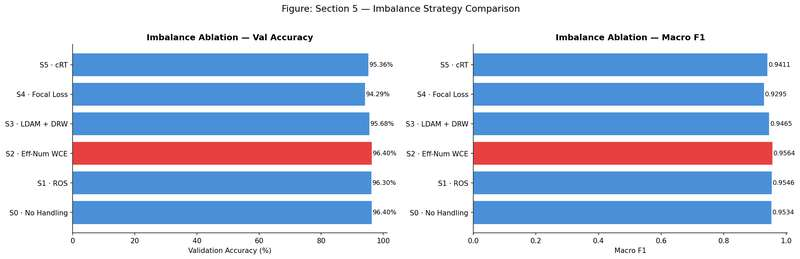

Saved: fig_imbal_ablation_comparison.png


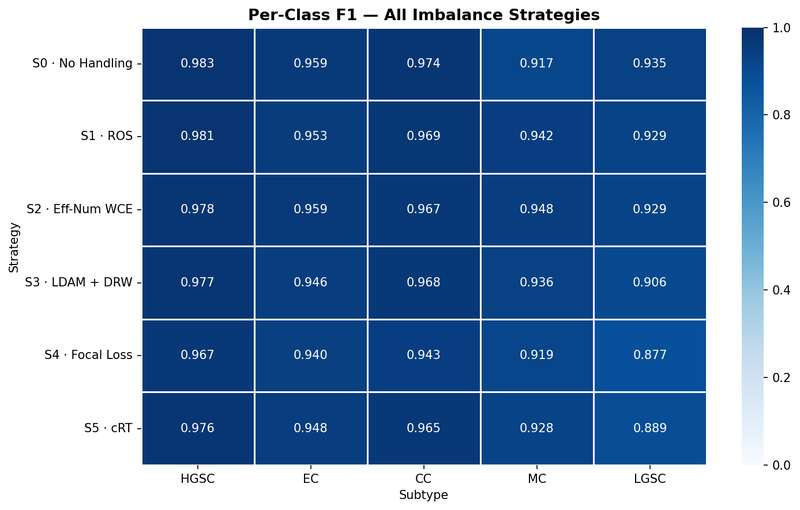

Saved: fig_imbal_perclass_f1_heatmap.png


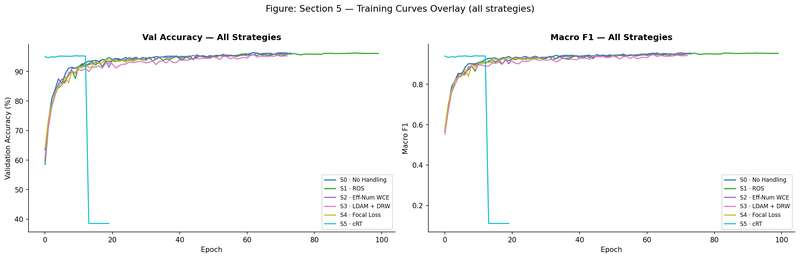

Saved: fig_imbal_curves_overlay.png

  IMBALANCE STRATEGY WINNER
  Key        : s2_effnum_wce
  Val Acc    : 96.40%
  Macro F1   : 0.9564
  Criterion  : CrossEntropyLoss
  ROS        : False

  Section 5 complete — imbalance winner locked.


In [ ]:
# ── Cell 40: Section 5 — Comparison Table + Winner ───────────────────────────

_strategy_labels = {
    's0_no_handling' : 'S0 · No Handling',
    's1_ros'         : 'S1 · ROS',
    's2_effnum_wce'  : 'S2 · Eff-Num WCE',
    's3_ldam_drw'    : 'S3 · LDAM + DRW',
    's4_focal'       : 'S4 · Focal Loss',
    's5_crt'         : 'S5 · cRT',
}

_rows = []
for key, name in _strategy_labels.items():
    r = RESULTS_IMBAL[key]
    per_f1 = r.get('per_class_f1', {})
    _rows.append({
        'Strategy'      : name,
        'Val Acc (%)'   : round(r['val_acc'],  2),
        'Macro F1'      : round(r['macro_f1'], 4),
        **{sub: round(per_f1.get(sub, 0.0), 4) for sub in SUBTYPES},
        'Time (min)'    : round(r['total_time_min'], 1),
    })

df_imbal = pd.DataFrame(_rows).sort_values(
    'Macro F1', ascending=False
).reset_index(drop=True)

print('\n' + '=' * 75)
print('  SECTION 5 — IMBALANCE STRATEGY ABLATION RESULTS')
print('=' * 75)
print(df_imbal.to_string(index=False))
print('=' * 75)

# ── Bar chart ─────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

_names  = [r['Strategy']   for r in _rows]
_accs   = [r['Val Acc (%)'] for r in _rows]
_f1s    = [r['Macro F1']    for r in _rows]
_colors = ['#4A90D9'] * len(_names)
_best_idx = int(np.argmax(_f1s))
_colors[_best_idx] = '#E84040'

axes[0].barh(_names, _accs, color=_colors, edgecolor='white')
axes[0].set_xlabel('Validation Accuracy (%)')
axes[0].set_title('Imbalance Ablation — Val Accuracy',
                  fontsize=12, fontweight='bold')
for i, v in enumerate(_accs):
    axes[0].text(v + 0.2, i, f'{v:.2f}%', va='center', fontsize=9)

axes[1].barh(_names, _f1s, color=_colors, edgecolor='white')
axes[1].set_xlabel('Macro F1')
axes[1].set_title('Imbalance Ablation — Macro F1',
                  fontsize=12, fontweight='bold')
for i, v in enumerate(_f1s):
    axes[1].text(v + 0.002, i, f'{v:.4f}', va='center', fontsize=9)

for ax in axes:
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)

plt.suptitle('Figure: Section 5 — Imbalance Strategy Comparison',
             fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(CHECKPOINT_DIR / 'fig_imbal_ablation_comparison.png',
            bbox_inches='tight', dpi=150)
plt.show()
print('Saved: fig_imbal_ablation_comparison.png')

# ── Per-class F1 heatmap ──────────────────────────────────────────────────────
_heatmap_data = pd.DataFrame(
    [[RESULTS_IMBAL[k].get('per_class_f1', {}).get(s, 0.0)
      for s in SUBTYPES]
     for k in _strategy_labels],
    index  = list(_strategy_labels.values()),
    columns= SUBTYPES
)

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(
    _heatmap_data, annot=True, fmt='.3f',
    cmap='Blues', vmin=0, vmax=1,
    linewidths=0.5, ax=ax
)
ax.set_title('Per-Class F1 — All Imbalance Strategies',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Subtype')
ax.set_ylabel('Strategy')
plt.tight_layout()
plt.savefig(CHECKPOINT_DIR / 'fig_imbal_perclass_f1_heatmap.png',
            bbox_inches='tight', dpi=150)
plt.show()
print('Saved: fig_imbal_perclass_f1_heatmap.png')

# ── Training curves overlay ───────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
_curve_colors = plt.cm.tab10(np.linspace(0, 1, len(_strategy_labels)))

for i, (key, name) in enumerate(_strategy_labels.items()):
    h = RESULTS_IMBAL[key]['history']
    axes[0].plot(h['val_acc'],  color=_curve_colors[i],
                 linewidth=1.5, label=name)
    axes[1].plot(h['macro_f1'], color=_curve_colors[i],
                 linewidth=1.5, label=name)

for ax, title, ylabel in zip(
    axes,
    ['Val Accuracy — All Strategies', 'Macro F1 — All Strategies'],
    ['Validation Accuracy (%)', 'Macro F1']
):
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Epoch')
    ax.set_ylabel(ylabel)
    ax.legend(fontsize=8, loc='lower right')
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)

plt.suptitle('Figure: Section 5 — Training Curves Overlay (all strategies)',
             fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(CHECKPOINT_DIR / 'fig_imbal_curves_overlay.png',
            bbox_inches='tight', dpi=150)
plt.show()
print('Saved: fig_imbal_curves_overlay.png')

# ── Lock winner ───────────────────────────────────────────────────────────────
IMBAL_WINNER_KEY  = df_imbal.iloc[0]['Strategy']
IMBAL_WINNER_KEY  = [k for k, v in _strategy_labels.items()
                     if v == IMBAL_WINNER_KEY][0]
IMBAL_WINNER      = RESULTS_IMBAL[IMBAL_WINNER_KEY]

_winner_criterion_map = {
    's0_no_handling': nn.CrossEntropyLoss(label_smoothing=0.1),
    's1_ros'        : nn.CrossEntropyLoss(label_smoothing=0.1),
    's2_effnum_wce' : nn.CrossEntropyLoss(
                          weight=EFF_NUM_WEIGHTS, label_smoothing=0.1),
    's3_ldam_drw'   : LDAMLoss(TRAIN_COUNTS, max_m=0.5,
                                weight=EFF_NUM_WEIGHTS, s=30),
    's4_focal'      : FocalLoss(gamma=2.0),
    's5_crt'        : nn.CrossEntropyLoss(
                          weight=EFF_NUM_WEIGHTS, label_smoothing=0.1),
}
_winner_ros_map = {
    's0_no_handling': False,
    's1_ros'        : True,
    's2_effnum_wce' : False,
    's3_ldam_drw'   : False,
    's4_focal'      : False,
    's5_crt'        : True,
}

WINNER_CRITERION = _winner_criterion_map[IMBAL_WINNER_KEY]
WINNER_USE_ROS   = _winner_ros_map[IMBAL_WINNER_KEY]

print('\n' + '=' * 65)
print('  IMBALANCE STRATEGY WINNER')
print('=' * 65)
print(f'  Key        : {IMBAL_WINNER_KEY}')
print(f'  Val Acc    : {IMBAL_WINNER["val_acc"]:.2f}%')
print(f'  Macro F1   : {IMBAL_WINNER["macro_f1"]:.4f}')
print(f'  Criterion  : {WINNER_CRITERION.__class__.__name__}')
print(f'  ROS        : {WINNER_USE_ROS}')
print('=' * 65)
print('\n  Section 5 complete — imbalance winner locked.')

In [ ]:
# ── Save All Ablation Results to Drive ────────────────────────────────────────
# Run immediately after Cell 40 (Section 5 complete).
# Saves RESULTS_PREP + RESULTS_IMBAL + both winners to Drive.
# Allows Section 8 master table to be fully populated when notebooks merge.

import pickle

_ablation_save = {
    'RESULTS_PREP'    : RESULTS_PREP,
    'RESULTS_IMBAL'   : RESULTS_IMBAL,
    'PREP_WINNER_KEY' : PREP_WINNER_KEY,
    'IMBAL_WINNER_KEY': IMBAL_WINNER_KEY,
    'WINNER_PRE_FN'   : None,        # not picklable — reconstructed on load
    'WINNER_EVL_TF'   : None,        # not picklable — reconstructed on load
    'WINNER_SIZE'     : WINNER_SIZE,
    'WINNER_USE_ROS'  : WINNER_USE_ROS,
}

_ablation_path = CHECKPOINT_DIR / 'ablation_results.pkl'

with open(_ablation_path, 'wb') as f:
    pickle.dump(_ablation_save, f)

print('=' * 65)
print('  ABLATION RESULTS SAVED TO DRIVE')
print('=' * 65)
print(f'  Path             : {_ablation_path}')
print(f'  PREP phases      : {len(RESULTS_PREP)}')
print(f'  IMBAL strategies : {len(RESULTS_IMBAL)}')
print(f'  PREP winner      : {PREP_WINNER_KEY}')
print(f'  IMBAL winner     : {IMBAL_WINNER_KEY}')
print(f'  Winner size      : {WINNER_SIZE}')
print(f'  Winner ROS       : {WINNER_USE_ROS}')
print('=' * 65)

  ABLATION RESULTS SAVED TO DRIVE
  Path             : /content/drive/MyDrive/Ovarian_GradProject/checkpoints/ablation_results.pkl
  PREP phases      : 7
  IMBAL strategies : 7
  PREP winner      : phase1_static224
  IMBAL winner     : s2_effnum_wce
  Winner size      : 224
  Winner ROS       : False


## Section 5 - Architecture & Baseline Comparison
### Stream A - Ovarian Cancer Histopathology
---
**CNN baselines :**
VGG-16 · ResNet-50 · DenseNet-121 · EfficientNet-B4 · MobileNetV3-Large

**Transformer baselines :**
ViT-B/16 · Swin-T · DeiT-S

**the ConvNeXt variants :**
- `ConvNeXtVanilla`        - no modifications
- `ConvNeXtSingleCBAM`     - CBAM at stage 4 only
- `ConvNeXtMultiCBAM`      - CBAM after stages 2 · 3 · 4
- `ConvNeXtFullPipeline`   - Multi-CBAM + Dual-Pool + §3 winner + §4 winner

**Fixed across all models:**
Preprocessing = §3 winner · Loss = §4 winner · Epochs = 100 · Patience = 10

**Evaluation per model:**
Training curves · ROC-AUC · Confusion matrix · Classification report

In [ ]:
# ── Cell 41: run_arch_experiment() ────────────────────────────────────────────
# Generic runner for all 12 architecture experiments.
# Handles CNN/Transformer/ConvNeXt variants uniformly.
# Transformer models get lower LRs + patch embed freeze for first 5 epochs.

_TRANSFORMER_CLASSES = (ViTB16Classifier, DeiTSClassifier)
_FREEZE_EMBED_EPOCHS = 5


def run_arch_experiment(model, label,
                         backbone_lr=None,
                         head_lr=None):
    """
    Train any model class with §4 winner preprocessing + §5 winner loss.
    Automatically detects transformers and applies appropriate LR + freeze.

    Parameters
    ----------
    model       : nn.Module  — instantiated model already on device
    label       : str        — experiment name for ckpt + plot filenames
    backbone_lr : float|None — overrides default if provided
    head_lr     : float|None — overrides default if provided

    Returns
    -------
    dict — val_acc, macro_f1, ckpt, history, total_time_min
    """
    _is_transformer = isinstance(model, _TRANSFORMER_CLASSES)

    if backbone_lr is None:
        backbone_lr = 5e-6 if _is_transformer else 2e-5
    if head_lr is None:
        head_lr     = 5e-5 if _is_transformer else 2e-4

    ckpt_path = CHECKPOINT_DIR / f'best_{label}.pth'
    best_acc  = 0.0
    best_f1   = 0.0
    no_imp    = 0
    history   = {
        'train_loss': [], 'train_acc': [],
        'val_acc'   : [], 'macro_f1' : []
    }
    global_ep = 0
    t0_total  = time.time()

    # ── Patch embed freeze for ViT / DeiT ─────────────────────────────────────
    if _is_transformer:
        model.freeze_patch_embed()
        print(f'  Patch embed frozen for first {_FREEZE_EMBED_EPOCHS} epochs.')

    n_p = sum(p.numel() for p in model.parameters()) / 1e6
    print(f'\n{"=" * 65}')
    print(f'  {label}  |  {EPOCHS} ep  |  {n_p:.1f}M params')
    print(f'  Backbone LR  : {backbone_lr:.1e}  |  '
          f'Head LR : {head_lr:.1e}')
    print(f'  Criterion    : {WINNER_CRITERION.__class__.__name__}')
    print(f'  ROS sampler  : {WINNER_USE_ROS}')
    print(f'  Transformer  : {_is_transformer}')
    print(f'{"=" * 65}')

    stages = _PROG_STAGES if _IS_PROGRESSIVE else [
        (WINNER_SIZE,
         BASE_BATCH if WINNER_SIZE < 384 else BASE_BATCH // 2,
         EPOCHS, None, WINNER_EVL_TF)
    ]

    for stage_idx, stage in enumerate(stages):
        _size, _batch, _eps, _aug_tf, _evl_tf = stage
        if not _IS_PROGRESSIVE:
            _aug_tf = make_transforms(_size)[0]

        if _IS_PROGRESSIVE:
            print(f'\n  ── Stage {stage_idx + 1}: {_size}×{_size}  '
                  f'({_eps} epochs · batch {_batch}) ──')

        sampler   = None
        _train_ds = OvarianDataset(
            train_paths, train_labels,
            transform=_aug_tf, pre_fn=WINNER_PRE_FN,
            input_size=_size
        )
        _test_ds  = OvarianDataset(
            test_paths, test_labels,
            transform=_evl_tf, pre_fn=WINNER_PRE_FN,
            input_size=_size
        )
        if WINNER_USE_ROS:
            sampler = make_weighted_sampler(train_labels)

        _train_ldr = make_loader(_train_ds, batch_size=_batch,
                                  sampler=sampler)
        _test_ldr  = make_loader(_test_ds,  batch_size=_batch,
                                  shuffle=False)

        bb_p, ot_p = model.get_param_groups()
        optimizer  = optim.AdamW(
            [{'params': bb_p, 'lr': backbone_lr},
             {'params': ot_p, 'lr': head_lr}],
            weight_decay=1e-4
        )
        scheduler  = OneCycleLR(
            optimizer,
            max_lr          = [backbone_lr * 5, head_lr * 5],
            steps_per_epoch = len(_train_ldr),
            epochs          = _eps,
            pct_start       = 0.2 if _is_transformer else 0.1,
            anneal_strategy = 'cos',
        )
        scaler = torch.cuda.amp.GradScaler()

        for ep in range(1, _eps + 1):
            global_ep += 1

            # ── Unfreeze patch embed after warmup ─────────────────────────────
            if _is_transformer and global_ep == _FREEZE_EMBED_EPOCHS + 1:
                model.unfreeze_patch_embed()
                print(f'\n  Patch embed unfrozen at epoch {global_ep}.')

            model.train()
            run_loss = 0.0
            correct  = 0
            total    = 0
            t0 = time.time()

            for imgs, lbls in _train_ldr:
                imgs, lbls = imgs.to(device), lbls.to(device)
                optimizer.zero_grad(set_to_none=True)
                with torch.cuda.amp.autocast():
                    out  = model(imgs)
                    loss = WINNER_CRITERION(out, lbls)
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(optimizer)
                scaler.update()
                scheduler.step()
                run_loss += loss.item()
                preds     = out.argmax(1)
                correct  += (preds == lbls).sum().item()
                total    += lbls.size(0)

            model.eval()
            val_correct = 0
            val_total   = 0
            all_preds   = []
            all_labels  = []
            with torch.no_grad():
                for imgs, lbls in _test_ldr:
                    imgs, lbls = imgs.to(device), lbls.to(device)
                    with torch.cuda.amp.autocast():
                        preds = model(imgs).argmax(1)
                    val_correct += (preds == lbls).sum().item()
                    val_total   += lbls.size(0)
                    all_preds.extend(preds.cpu().numpy())
                    all_labels.extend(lbls.cpu().numpy())

            train_acc = 100. * correct / total
            val_acc   = 100. * val_correct / val_total
            macro_f1  = f1_score(all_labels, all_preds,
                                  average='macro', zero_division=0)
            avg_loss  = run_loss / len(_train_ldr)

            history['train_loss'].append(avg_loss)
            history['train_acc'] .append(train_acc)
            history['val_acc']   .append(val_acc)
            history['macro_f1']  .append(macro_f1)

            if val_acc > best_acc:
                best_acc = val_acc
                best_f1  = macro_f1
                torch.save(model.state_dict(), ckpt_path)
                no_imp = 0
            else:
                no_imp += 1

            tag = f' | No improve: {no_imp}/{PATIENCE}' if no_imp else ''
            print(f'  Ep {global_ep:>3}/{EPOCHS} | '
                  f'Loss:{avg_loss:.4f} | '
                  f'Train:{train_acc:.2f}% | '
                  f'Val:{val_acc:.2f}% | '
                  f'LR:{optimizer.param_groups[1]["lr"]:.2e} | '
                  f'Best:{best_acc:.2f}%{tag} | '
                  f'{time.time() - t0:.1f}s')

            if no_imp >= PATIENCE:
                print(f'\n  Early stop at epoch {global_ep}.')
                break

        del _train_ds, _test_ds, _train_ldr, _test_ldr
        torch.cuda.empty_cache()

        if no_imp >= PATIENCE:
            break

    total_time = time.time() - t0_total
    print(f'\n  {label}  |  Best Val: {best_acc:.2f}%  |  '
          f'Macro F1: {best_f1:.4f}  |  '
          f'Time: {total_time / 60:.1f} min')

    return {
        'label'         : label,
        'val_acc'       : best_acc,
        'macro_f1'      : best_f1,
        'ckpt'          : ckpt_path,
        'history'       : history,
        'model'         : model,
        'total_time_min': total_time / 60,
        'n_params_M'    : n_p,
    }


print('run_arch_experiment() defined.')
print(f'  Winner preprocessing : {PREP_WINNER_KEY}')
print(f'  Winner loss          : {IMBAL_WINNER_KEY}')
print('Cell 41 complete.')

run_arch_experiment() defined.
  Winner preprocessing : phase1_static224
  Winner loss          : s2_effnum_wce
Cell 41 complete.


  BASELINE : VGG-16

  vgg16  |  100 ep  |  134.3M params

... [epoch-by-epoch training log truncated for GitHub] ...

  Ep  76/100 | Loss:0.5042 | Train:97.82% | Val:94.32% | LR:1.65e-04 | Best:94.45% | No improve: 1/10 | 42.9s
  Ep  77/100 | Loss:0.5033 | Train:97.82% | Val:94.22% | LR:1.53e-04 | Best:94.45% | No improve: 2/10 | 42.9s
  Ep  78/100 | Loss:0.5035 | Train:97.86% | Val:94.19% | LR:1.40e-04 | Best:94.45% | No improve: 3/10 | 43.0s
  Ep  79/100 | Loss:0.5020 | Train:97.92% | Val:94.35% | LR:1.28e-04 | Best:94.45% | No improve: 4/10 | 43.0s
  Ep  80/100 | Loss:0.5020 | Train:97.92% | Val:94.48% | LR:1.17e-04 | Best:94.48% | 44.5s
  Ep  81/100 | Loss:0.5001 | Train:98.04% | Val:94.42% | LR:1.06e-04 | Best:94.48% | No improve: 1/10 | 42.9s
  Ep  82/100 | Loss:0.4997 | Train:97.95% | Val:94.35% | LR:9.55e-05 | Best:94.48% | No improve: 2/10 | 42.9s
  Ep  83/100 | Loss:0.4996 | Train:98.02% | Val:94.65% | LR:8.55e-05 | Best:94.65% | 44.3s
  Ep  84/100 | Loss:0.5009 | Train:97.8

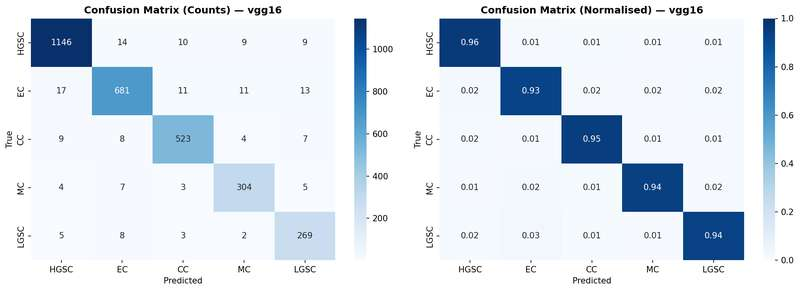

Saved: confusion_vgg16.png


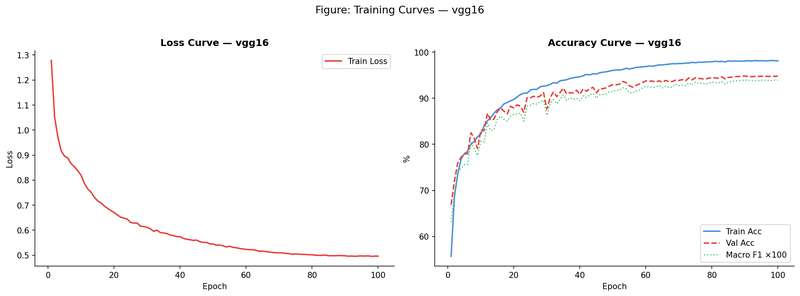

Saved: curves_vgg16.png


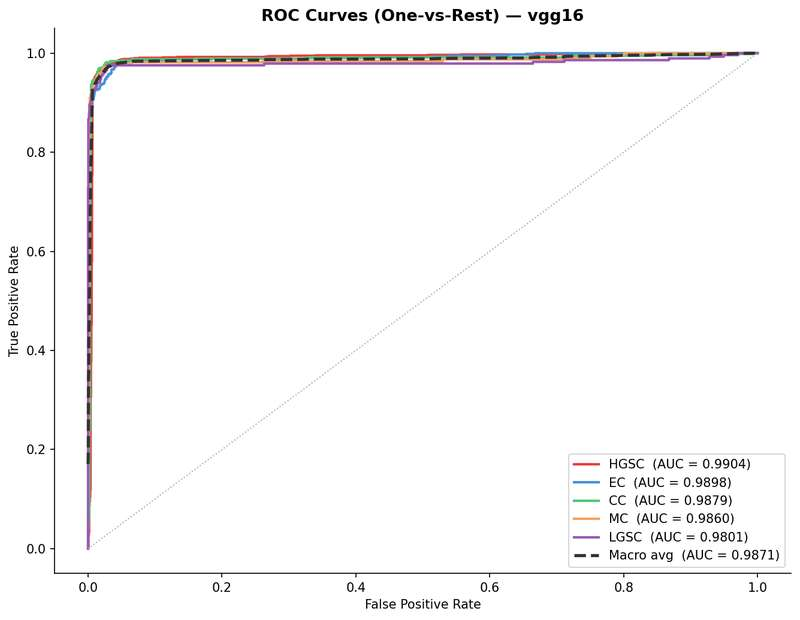

Saved: roc_vgg16.png

  ROC-AUC SCORES — vgg16
  HGSC   : 0.9904
  EC     : 0.9898
  CC     : 0.9879
  MC     : 0.9860
  LGSC   : 0.9801
  Macro  : 0.9871

  VGG-16 complete.


In [ ]:
# ── Cell 42: VGG-16 ───────────────────────────────────────────────────────────

print('=' * 65)
print('  BASELINE : VGG-16')
print('=' * 65)

_model_vgg = VGG16Classifier().to(device)

RESULTS_ARCH['vgg16'] = run_arch_experiment(
    model = _model_vgg,
    label = 'vgg16',
)

_eval_ds  = OvarianDataset(
    test_paths, test_labels,
    transform=WINNER_EVL_TF, pre_fn=WINNER_PRE_FN,
    input_size=WINNER_SIZE
)
_eval_ldr = make_loader(_eval_ds, batch_size=BASE_BATCH // 2,
                         shuffle=False)
_eval = evaluate(
    _model_vgg, _eval_ldr,
    RESULTS_ARCH['vgg16']['ckpt'], 'vgg16'
)
RESULTS_ARCH['vgg16'].update(_eval)
plot_training_curves(RESULTS_ARCH['vgg16']['history'], 'vgg16')
plot_roc_auc(
    RESULTS_ARCH['vgg16']['probs'],
    RESULTS_ARCH['vgg16']['labels'],
    'vgg16'
)

del _model_vgg, _eval_ds, _eval_ldr
torch.cuda.empty_cache()
print('\n  VGG-16 complete.')

  BASELINE : ResNet-50

  resnet50  |  100 ep  |  23.5M params
  Backbone LR  : 2.0e-05  |  Head LR : 2.0e-04
  Criterion    : CrossEntropyLoss
  ROS sampler  : False
  Transformer  : False
  Ep   1/100 | Loss:1.5241 | Train:44.29% | Val:53.34% | LR:6.35e-05 | Best:53.34% | 102.7s
  Ep   2/100 | Loss:1.2551 | Train:57.53% | Val:64.70% | LR:1.32e-04 | Best:64.70% | 36.4s
  Ep   3/100 | Loss:1.0571 | Train:67.68% | Val:74.63% | LR:2.38e-04 | Best:74.63% | 37.2s
  Ep   4/100 | Loss:0.9328 | Train:74.86% | Val:79.43% | LR:3.72e-04 | Best:79.43% | 38.5s
  Ep   5/100 | Loss:0.8426 | Train:80.07% | Val:84.20% | LR:5.20e-04 | Best:84.20% | 36.5s
  Ep   6/100 | Loss:0.7779 | Train:83.90% | Val:87.12% | LR:6.69e-04 | Best:87.12% | 36.0s
  Ep   7/100 | Loss:0.7366 | Train:86.02% | Val:87.02% | LR:8.02e-04 | Best:87.12% | No improve: 1/10 | 36.2s
  Ep   8/100 | Loss:0.7050 | Train:87.96% | Val:87.15% | LR:9.08e-04 | Best:87.15% | 36.3s
  Ep   9/100 | Loss:0.6811 | Train:89.30% | Val:89.68% | LR:9.

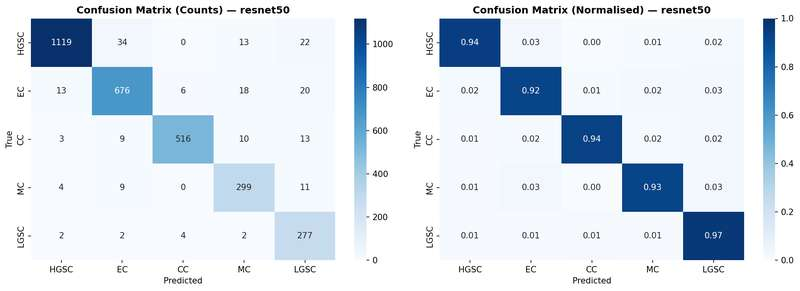

Saved: confusion_resnet50.png


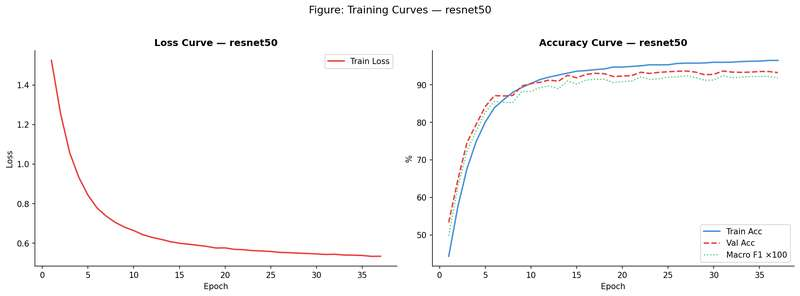

Saved: curves_resnet50.png


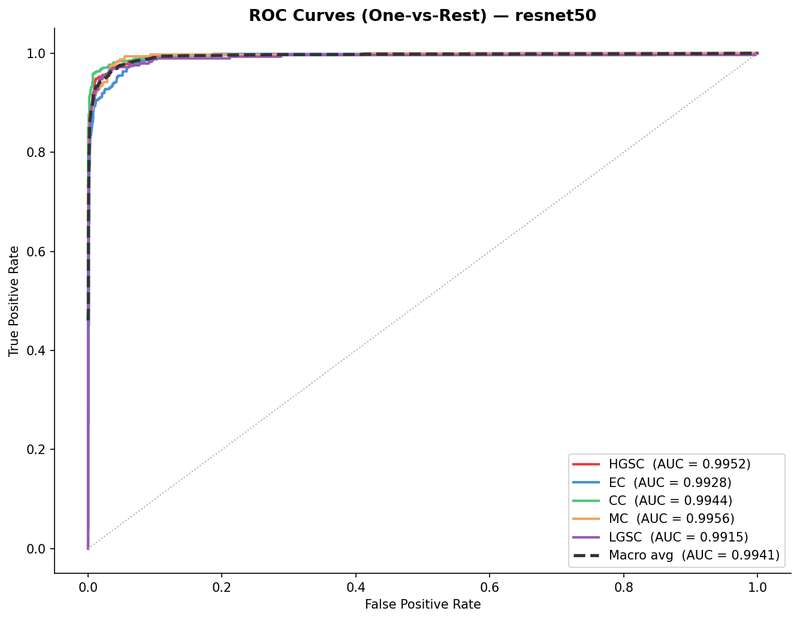

Saved: roc_resnet50.png

  ROC-AUC SCORES — resnet50
  HGSC   : 0.9952
  EC     : 0.9928
  CC     : 0.9944
  MC     : 0.9956
  LGSC   : 0.9915
  Macro  : 0.9941

  ResNet-50 complete.


In [ ]:
# ── Cell 43: ResNet-50 ────────────────────────────────────────────────────────

print('=' * 65)
print('  BASELINE : ResNet-50')
print('=' * 65)

_model_res = ResNet50Classifier().to(device)

RESULTS_ARCH['resnet50'] = run_arch_experiment(
    model = _model_res,
    label = 'resnet50',
)

_eval_ds  = OvarianDataset(
    test_paths, test_labels,
    transform=WINNER_EVL_TF, pre_fn=WINNER_PRE_FN,
    input_size=WINNER_SIZE
)
_eval_ldr = make_loader(_eval_ds, batch_size=BASE_BATCH // 2,
                         shuffle=False)
_eval = evaluate(
    _model_res, _eval_ldr,
    RESULTS_ARCH['resnet50']['ckpt'], 'resnet50'
)
RESULTS_ARCH['resnet50'].update(_eval)
plot_training_curves(RESULTS_ARCH['resnet50']['history'], 'resnet50')
plot_roc_auc(
    RESULTS_ARCH['resnet50']['probs'],
    RESULTS_ARCH['resnet50']['labels'],
    'resnet50'
)

del _model_res, _eval_ds, _eval_ldr
torch.cuda.empty_cache()
print('\n  ResNet-50 complete.')

  BASELINE : DenseNet-121

  densenet121  |  100 ep  |  7.0M params

... [epoch-by-epoch training log truncated for GitHub] ...

  Ep  16/100 | Loss:0.6436 | Train:91.56% | Val:91.69% | LR:9.89e-04 | Best:91.69% | 58.3s
  Ep  17/100 | Loss:0.6347 | Train:92.11% | Val:89.88% | LR:9.85e-04 | Best:91.69% | No improve: 1/10 | 58.4s
  Ep  18/100 | Loss:0.6335 | Train:92.16% | Val:91.34% | LR:9.81e-04 | Best:91.69% | No improve: 2/10 | 58.4s
  Ep  19/100 | Loss:0.6218 | Train:92.78% | Val:90.91% | LR:9.76e-04 | Best:91.69% | No improve: 3/10 | 58.3s
  Ep  20/100 | Loss:0.6166 | Train:92.89% | Val:91.99% | LR:9.70e-04 | Best:91.99% | 58.3s
  Ep  21/100 | Loss:0.6107 | Train:93.27% | Val:91.56% | LR:9.64e-04 | Best:91.99% | No improve: 1/10 | 58.9s
  Ep  22/100 | Loss:0.6048 | Train:93.65% | Val:92.54% | LR:9.57e-04 | Best:92.54% | 59.5s
  Ep  23/100 | Loss:0.6006 | Train:93.75% | Val:92.08% | LR:9.49e-04 | Best:92.54% | No improve: 1/10 | 58.7s
  Ep  24/100 | Loss:0.5958 | Train:93.94% | Val:

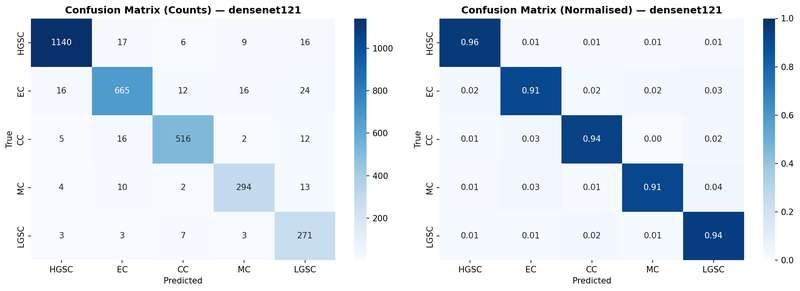

Saved: confusion_densenet121.png


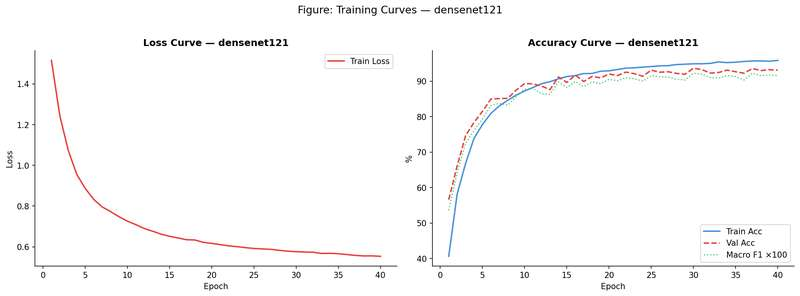

Saved: curves_densenet121.png


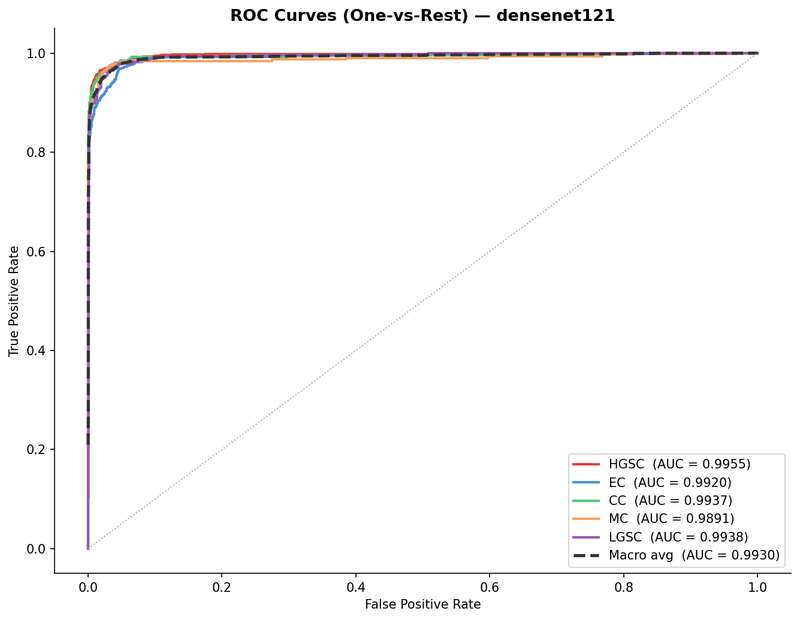

Saved: roc_densenet121.png

  ROC-AUC SCORES — densenet121
  HGSC   : 0.9955
  EC     : 0.9920
  CC     : 0.9937
  MC     : 0.9891
  LGSC   : 0.9938
  Macro  : 0.9930

  DenseNet-121 complete.


In [ ]:
# ── Cell 44: DenseNet-121 ─────────────────────────────────────────────────────

print('=' * 65)
print('  BASELINE : DenseNet-121')
print('=' * 65)

_model_den = DenseNet121Classifier().to(device)

RESULTS_ARCH['densenet121'] = run_arch_experiment(
    model = _model_den,
    label = 'densenet121',
)

_eval_ds  = OvarianDataset(
    test_paths, test_labels,
    transform=WINNER_EVL_TF, pre_fn=WINNER_PRE_FN,
    input_size=WINNER_SIZE
)
_eval_ldr = make_loader(_eval_ds, batch_size=BASE_BATCH // 2,
                         shuffle=False)
_eval = evaluate(
    _model_den, _eval_ldr,
    RESULTS_ARCH['densenet121']['ckpt'], 'densenet121'
)
RESULTS_ARCH['densenet121'].update(_eval)
plot_training_curves(RESULTS_ARCH['densenet121']['history'], 'densenet121')
plot_roc_auc(
    RESULTS_ARCH['densenet121']['probs'],
    RESULTS_ARCH['densenet121']['labels'],
    'densenet121'
)

del _model_den, _eval_ds, _eval_ldr
torch.cuda.empty_cache()
print('\n  DenseNet-121 complete.')

  BASELINE : EfficientNet-B4

  efficientnet_b4  |  100 ep  |  17.6M params
  Backbone LR  : 2.0e-05  |  Head LR : 2.0e-04
  Criterion    : CrossEntropyLoss
  ROS sampler  : False
  Transformer  : False
  Ep   1/100 | Loss:1.6060 | Train:39.19% | Val:44.65% | LR:6.35e-05 | Best:44.65% | 243.9s
  Ep   2/100 | Loss:1.4888 | Train:49.66% | Val:51.52% | LR:1.32e-04 | Best:51.52% | 66.8s
  Ep   3/100 | Loss:1.3231 | Train:54.05% | Val:57.11% | LR:2.38e-04 | Best:57.11% | 66.5s
  Ep   4/100 | Loss:1.2076 | Train:59.21% | Val:63.30% | LR:3.72e-04 | Best:63.30% | 66.6s
  Ep   5/100 | Loss:1.1146 | Train:64.58% | Val:68.53% | LR:5.20e-04 | Best:68.53% | 66.6s
  Ep   6/100 | Loss:1.0286 | Train:69.38% | Val:72.29% | LR:6.69e-04 | Best:72.29% | 66.7s
  Ep   7/100 | Loss:0.9543 | Train:73.53% | Val:75.41% | LR:8.02e-04 | Best:75.41% | 67.0s
  Ep   8/100 | Loss:0.8856 | Train:77.34% | Val:78.46% | LR:9.08e-04 | Best:78.46% | 66.4s
  Ep   9/100 | Loss:0.8301 | Train:80.48% | Val:80.30% | LR:9.77e-04

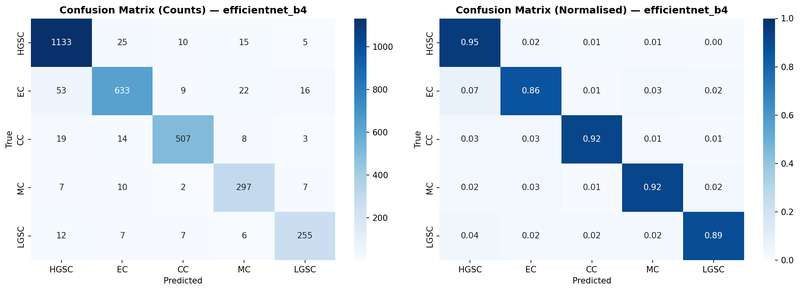

Saved: confusion_efficientnet_b4.png


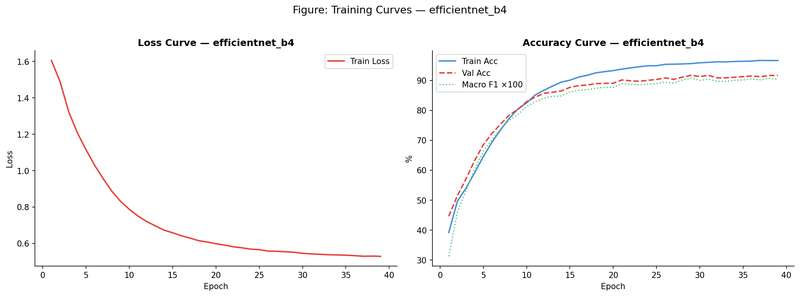

Saved: curves_efficientnet_b4.png


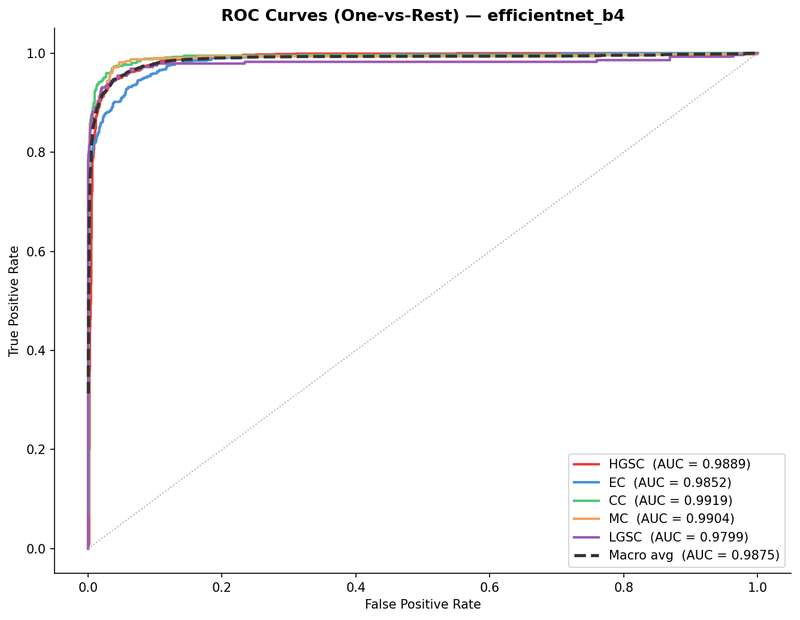

Saved: roc_efficientnet_b4.png

  ROC-AUC SCORES — efficientnet_b4
  HGSC   : 0.9889
  EC     : 0.9852
  CC     : 0.9919
  MC     : 0.9904
  LGSC   : 0.9799
  Macro  : 0.9875

  EfficientNet-B4 complete.


In [ ]:
# ── Cell 45: EfficientNet-B4 ──────────────────────────────────────────────────

print('=' * 65)
print('  BASELINE : EfficientNet-B4')
print('=' * 65)

_model_eff = EfficientNetB4Classifier().to(device)

RESULTS_ARCH['efficientnet_b4'] = run_arch_experiment(
    model = _model_eff,
    label = 'efficientnet_b4',
)

_eval_ds  = OvarianDataset(
    test_paths, test_labels,
    transform=WINNER_EVL_TF, pre_fn=WINNER_PRE_FN,
    input_size=WINNER_SIZE
)
_eval_ldr = make_loader(_eval_ds, batch_size=BASE_BATCH // 2,
                         shuffle=False)
_eval = evaluate(
    _model_eff, _eval_ldr,
    RESULTS_ARCH['efficientnet_b4']['ckpt'], 'efficientnet_b4'
)
RESULTS_ARCH['efficientnet_b4'].update(_eval)
plot_training_curves(
    RESULTS_ARCH['efficientnet_b4']['history'], 'efficientnet_b4'
)
plot_roc_auc(
    RESULTS_ARCH['efficientnet_b4']['probs'],
    RESULTS_ARCH['efficientnet_b4']['labels'],
    'efficientnet_b4'
)

del _model_eff, _eval_ds, _eval_ldr
torch.cuda.empty_cache()
print('\n  EfficientNet-B4 complete.')

  BASELINE : MobileNetV3-Large

  mobilenetv3  |  100 ep  |  4.2M params

... [epoch-by-epoch training log truncated for GitHub] ...

  Ep  17/100 | Loss:0.5852 | Train:94.18% | Val:92.54% | LR:9.85e-04 | Best:92.93% | No improve: 1/10 | 36.6s
  Ep  18/100 | Loss:0.5805 | Train:94.48% | Val:92.63% | LR:9.81e-04 | Best:92.93% | No improve: 2/10 | 36.6s
  Ep  19/100 | Loss:0.5764 | Train:94.70% | Val:93.12% | LR:9.76e-04 | Best:93.12% | 36.3s
  Ep  20/100 | Loss:0.5703 | Train:95.00% | Val:93.15% | LR:9.70e-04 | Best:93.15% | 36.8s
  Ep  21/100 | Loss:0.5655 | Train:95.13% | Val:93.84% | LR:9.64e-04 | Best:93.84% | 36.8s
  Ep  22/100 | Loss:0.5637 | Train:95.21% | Val:92.89% | LR:9.57e-04 | Best:93.84% | No improve: 1/10 | 36.2s
  Ep  23/100 | Loss:0.5595 | Train:95.42% | Val:93.80% | LR:9.49e-04 | Best:93.84% | No improve: 2/10 | 36.4s
  Ep  24/100 | Loss:0.5571 | Train:95.59% | Val:93.61% | LR:9.41e-04 | Best:93.84% | No improve: 3/10 | 36.2s
  Ep  25/100 | Loss:0.5532 | Train:95.79% |

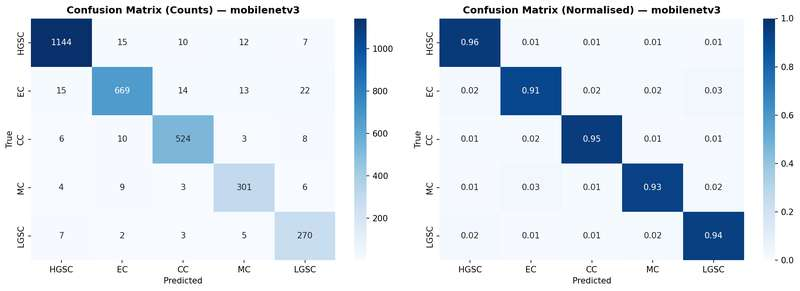

Saved: confusion_mobilenetv3.png


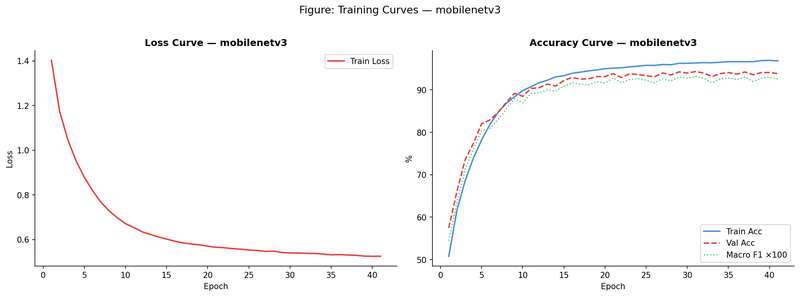

Saved: curves_mobilenetv3.png


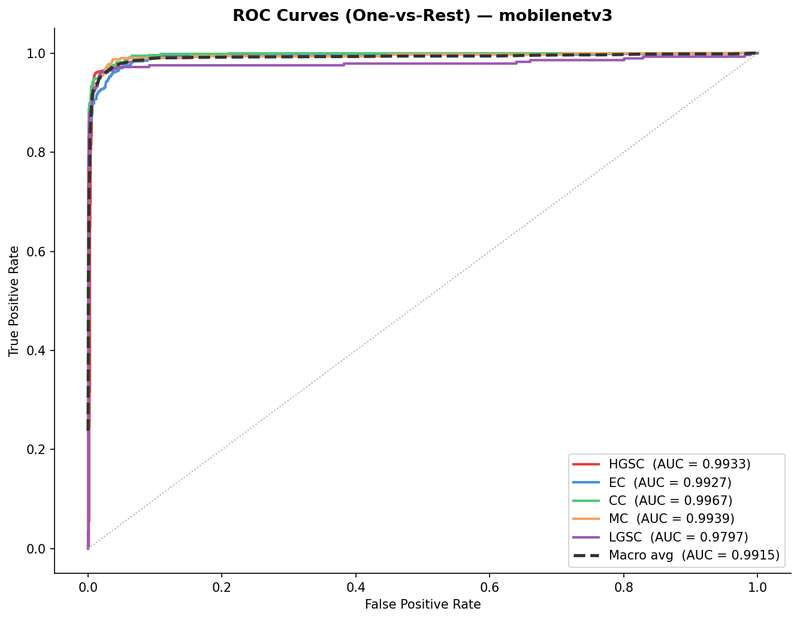

Saved: roc_mobilenetv3.png

  ROC-AUC SCORES — mobilenetv3
  HGSC   : 0.9933
  EC     : 0.9927
  CC     : 0.9967
  MC     : 0.9939
  LGSC   : 0.9797
  Macro  : 0.9915

  MobileNetV3-Large complete.


In [ ]:
# ── Cell 46: MobileNetV3-Large ────────────────────────────────────────────────

print('=' * 65)
print('  BASELINE : MobileNetV3-Large')
print('=' * 65)

_model_mob = MobileNetV3Classifier().to(device)

RESULTS_ARCH['mobilenetv3'] = run_arch_experiment(
    model = _model_mob,
    label = 'mobilenetv3',
)

_eval_ds  = OvarianDataset(
    test_paths, test_labels,
    transform=WINNER_EVL_TF, pre_fn=WINNER_PRE_FN,
    input_size=WINNER_SIZE
)
_eval_ldr = make_loader(_eval_ds, batch_size=BASE_BATCH // 2,
                         shuffle=False)
_eval = evaluate(
    _model_mob, _eval_ldr,
    RESULTS_ARCH['mobilenetv3']['ckpt'], 'mobilenetv3'
)
RESULTS_ARCH['mobilenetv3'].update(_eval)
plot_training_curves(
    RESULTS_ARCH['mobilenetv3']['history'], 'mobilenetv3'
)
plot_roc_auc(
    RESULTS_ARCH['mobilenetv3']['probs'],
    RESULTS_ARCH['mobilenetv3']['labels'],
    'mobilenetv3'
)

del _model_mob, _eval_ds, _eval_ldr
torch.cuda.empty_cache()
print('\n  MobileNetV3-Large complete.')

  BASELINE : ViT-B/16
  Patch embed frozen for first 5 epochs.


... [epoch-by-epoch training log truncated for GitHub] ...

  Ep  13/100 | Loss:0.6244 | Train:91.90% | Val:90.23% | LR:1.85e-04 | Best:90.23% | 42.3s
  Ep  14/100 | Loss:0.6101 | Train:92.44% | Val:90.88% | LR:2.01e-04 | Best:90.88% | 42.6s
  Ep  15/100 | Loss:0.6047 | Train:92.65% | Val:89.62% | LR:2.15e-04 | Best:90.88% | No improve: 1/10 | 41.8s
  Ep  16/100 | Loss:0.5976 | Train:93.16% | Val:90.98% | LR:2.27e-04 | Best:90.98% | 42.6s
  Ep  17/100 | Loss:0.5918 | Train:93.31% | Val:90.20% | LR:2.37e-04 | Best:90.98% | No improve: 1/10 | 41.8s
  Ep  18/100 | Loss:0.5857 | Train:93.60% | Val:92.05% | LR:2.44e-04 | Best:92.05% | 42.5s
  Ep  19/100 | Loss:0.5777 | Train:94.06% | Val:90.82% | LR:2.49e-04 | Best:92.05% | No improve: 1/10 | 41.7s
  Ep  20/100 | Loss:0.5745 | Train:94.30% | Val:92.02% | LR:2.50e-04 | Best:92.05% | No improve: 2/10 | 42.0s
  Ep  21/100 | Loss:0.5717 | Train:94.47% | Val:91.66% | LR:2.50e-04 | 

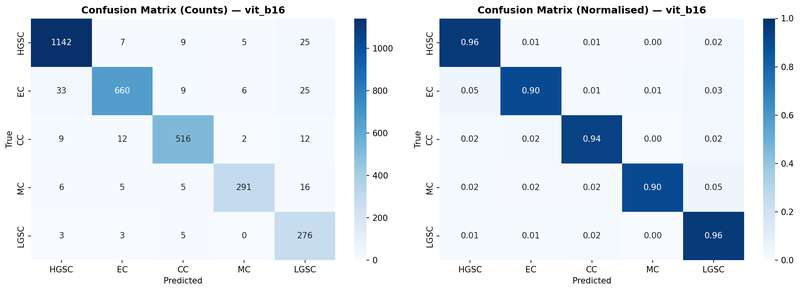

Saved: confusion_vit_b16.png


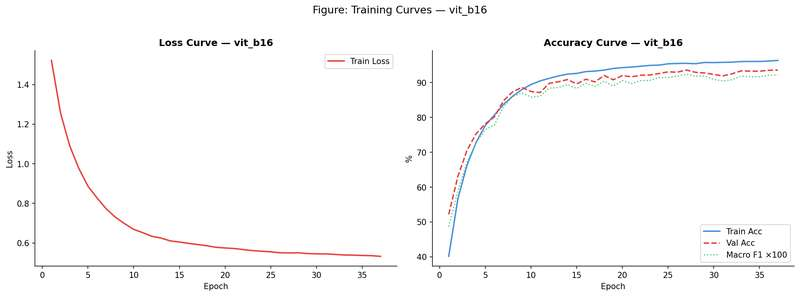

Saved: curves_vit_b16.png


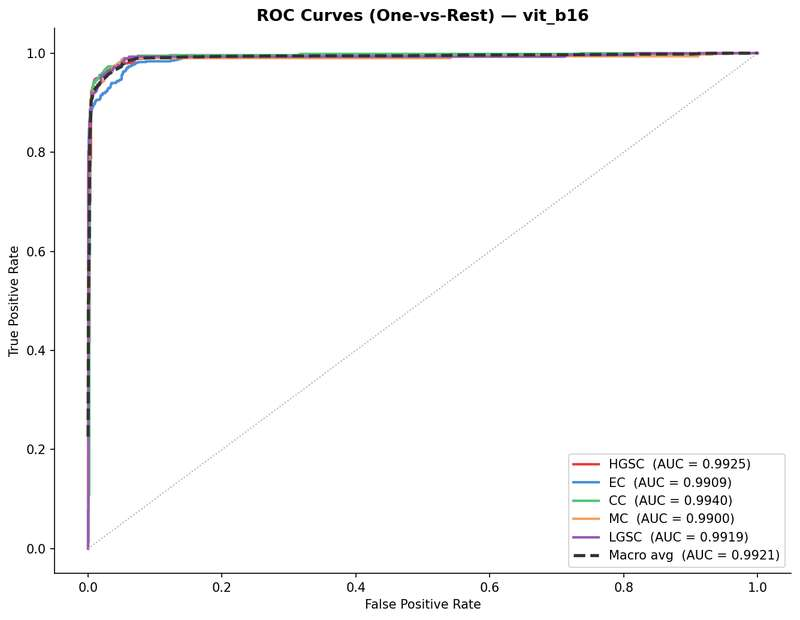

Saved: roc_vit_b16.png

  ROC-AUC SCORES — vit_b16
  HGSC   : 0.9925
  EC     : 0.9909
  CC     : 0.9940
  MC     : 0.9900
  LGSC   : 0.9919
  Macro  : 0.9921

  ViT-B/16 complete.


In [ ]:
# ── Cell 47: ViT-B/16 ─────────────────────────────────────────────────────────

print('=' * 65)
print('  BASELINE : ViT-B/16')
print('=' * 65)

_model_vit = ViTB16Classifier().to(device)

RESULTS_ARCH['vit_b16'] = run_arch_experiment(
    model       = _model_vit,
    label       = 'vit_b16',
    backbone_lr = 5e-6,
    head_lr     = 5e-5,
)

_eval_ds  = OvarianDataset(
    test_paths, test_labels,
    transform=WINNER_EVL_TF, pre_fn=WINNER_PRE_FN,
    input_size=WINNER_SIZE
)
_eval_ldr = make_loader(_eval_ds, batch_size=BASE_BATCH // 2,
                         shuffle=False)
_eval = evaluate(
    _model_vit, _eval_ldr,
    RESULTS_ARCH['vit_b16']['ckpt'], 'vit_b16'
)
RESULTS_ARCH['vit_b16'].update(_eval)
plot_training_curves(RESULTS_ARCH['vit_b16']['history'], 'vit_b16')
plot_roc_auc(
    RESULTS_ARCH['vit_b16']['probs'],
    RESULTS_ARCH['vit_b16']['labels'],
    'vit_b16'
)

del _model_vit, _eval_ds, _eval_ldr
torch.cuda.empty_cache()
print('\n  ViT-B/16 complete.')

  BASELINE : Swin Transformer Tiny

  swin_t  |  100 ep  |  27.5M params

... [epoch-by-epoch training log truncated for GitHub] ...

  Ep  40/100 | Loss:0.5290 | Train:96.66% | Val:94.42% | LR:1.87e-04 | Best:95.26% | No improve: 2/10 | 46.4s
  Ep  41/100 | Loss:0.5267 | Train:96.73% | Val:94.74% | LR:1.84e-04 | Best:95.26% | No improve: 3/10 | 46.7s
  Ep  42/100 | Loss:0.5277 | Train:96.63% | Val:95.04% | LR:1.80e-04 | Best:95.26% | No improve: 4/10 | 46.4s
  Ep  43/100 | Loss:0.5245 | Train:96.99% | Val:95.20% | LR:1.76e-04 | Best:95.26% | No improve: 5/10 | 46.6s
  Ep  44/100 | Loss:0.5239 | Train:96.83% | Val:95.23% | LR:1.72e-04 | Best:95.26% | No improve: 6/10 | 47.3s
  Ep  45/100 | Loss:0.5242 | Train:96.81% | Val:95.43% | LR:1.68e-04 | Best:95.43% | 48.4s
  Ep  46/100 | Loss:0.5235 | Train:96.85% | Val:95.72% | LR:1.64e-04 | Best:95.72% | 47.3s
  Ep  47/100 | Loss:0.5213 | Train:97.00% | Val:95.07% | LR:1.59e-04 | Best:95.72% | No improve: 1/10 | 46.2s
  Ep  48/100 | Loss:0.51

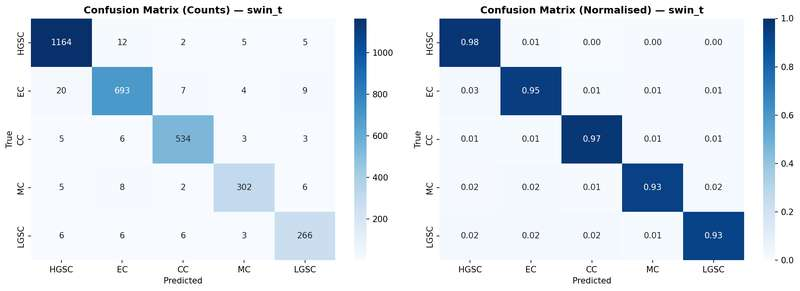

Saved: confusion_swin_t.png


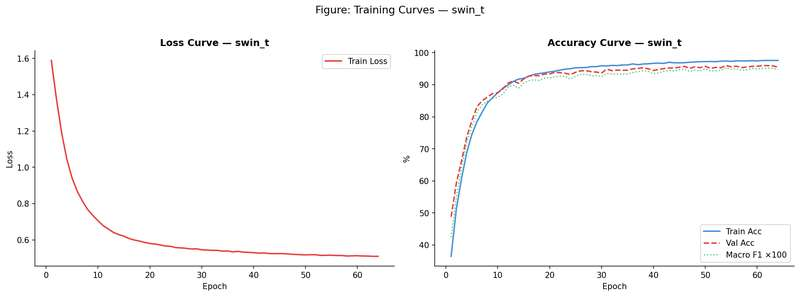

Saved: curves_swin_t.png


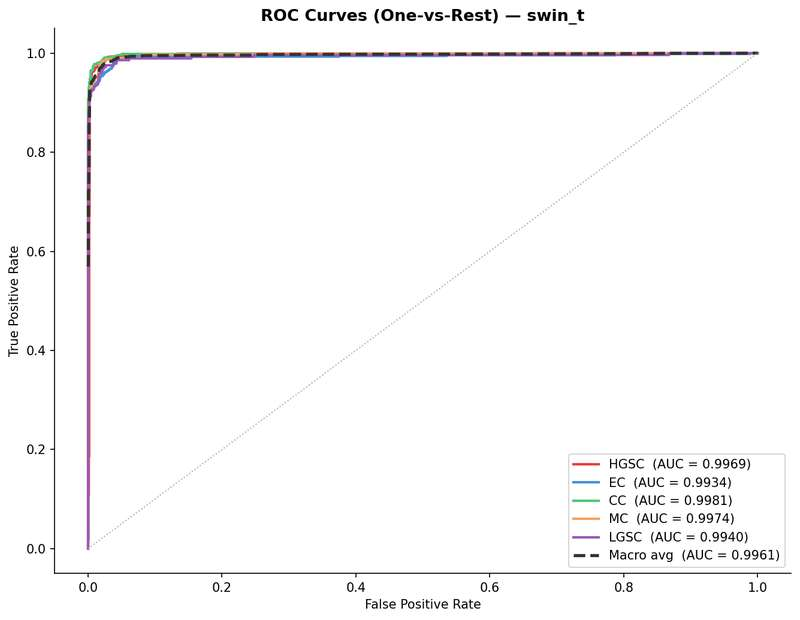

Saved: roc_swin_t.png

  ROC-AUC SCORES — swin_t
  HGSC   : 0.9969
  EC     : 0.9934
  CC     : 0.9981
  MC     : 0.9974
  LGSC   : 0.9940
  Macro  : 0.9961

  Swin-T complete.


In [ ]:
# ── Cell 48: Swin-T ───────────────────────────────────────────────────────────

print('=' * 65)
print('  BASELINE : Swin Transformer Tiny')
print('=' * 65)

_model_swin = SwinTClassifier().to(device)

RESULTS_ARCH['swin_t'] = run_arch_experiment(
    model       = _model_swin,
    label       = 'swin_t',
    backbone_lr = 5e-6,
    head_lr     = 5e-5,
)

_eval_ds  = OvarianDataset(
    test_paths, test_labels,
    transform=WINNER_EVL_TF, pre_fn=WINNER_PRE_FN,
    input_size=WINNER_SIZE
)
_eval_ldr = make_loader(_eval_ds, batch_size=BASE_BATCH // 2,
                         shuffle=False)
_eval = evaluate(
    _model_swin, _eval_ldr,
    RESULTS_ARCH['swin_t']['ckpt'], 'swin_t'
)
RESULTS_ARCH['swin_t'].update(_eval)
plot_training_curves(RESULTS_ARCH['swin_t']['history'], 'swin_t')
plot_roc_auc(
    RESULTS_ARCH['swin_t']['probs'],
    RESULTS_ARCH['swin_t']['labels'],
    'swin_t'
)

del _model_swin, _eval_ds, _eval_ldr
torch.cuda.empty_cache()
print('\n  Swin-T complete.')

  BASELINE : DeiT-Small
  Patch embed frozen for first 5 epochs.


... [epoch-by-epoch training log truncated for GitHub] ...

  Ep  73/100 | Loss:0.5079 | Train:97.54% | Val:94.19% | LR:6.39e-05 | Best:94.39% | No improve: 1/10 | 34.0s
  Ep  74/100 | Loss:0.5056 | Train:97.73% | Val:94.03% | LR:5.97e-05 | Best:94.39% | No improve: 2/10 | 34.0s
  Ep  75/100 | Loss:0.5079 | Train:97.62% | Val:94.45% | LR:5.55e-05 | Best:94.45% | 34.4s
  Ep  76/100 | Loss:0.5050 | Train:97.72% | Val:94.39% | LR:5.15e-05 | Best:94.45% | No improve: 1/10 | 33.7s
  Ep  77/100 | Loss:0.5056 | Train:97.73% | Val:94.45% | LR:4.76e-05 | Best:94.45% | No improve: 2/10 | 34.1s
  Ep  78/100 | Loss:0.5035 | Train:97.80% | Val:94.22% | LR:4.38e-05 | Best:94.45% | No improve: 3/10 | 34.1s
  Ep  79/100 | Loss:0.5041 | Train:97.73% | Val:94.48% | LR:4.01e-05 | Best:94.48% | 34.2s
  Ep  80/100 | Loss:0.5033 | Train:97.86% | Val:94.58% | LR:3.66e-05 | Best:94.58% | 34.2s
  Ep  81/100 | Loss:0.5041 | Train:97.88% | Val:94

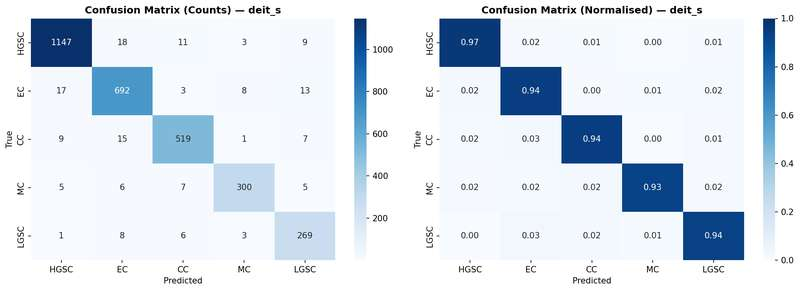

Saved: confusion_deit_s.png


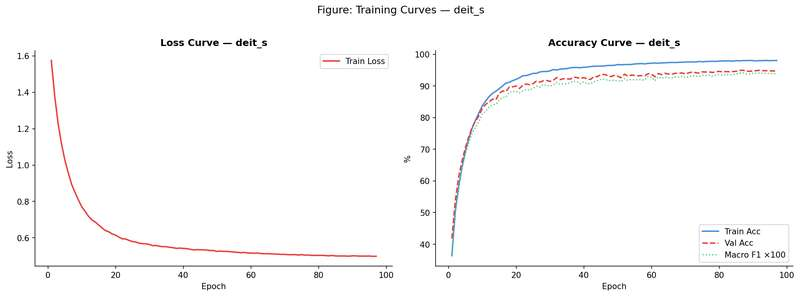

Saved: curves_deit_s.png


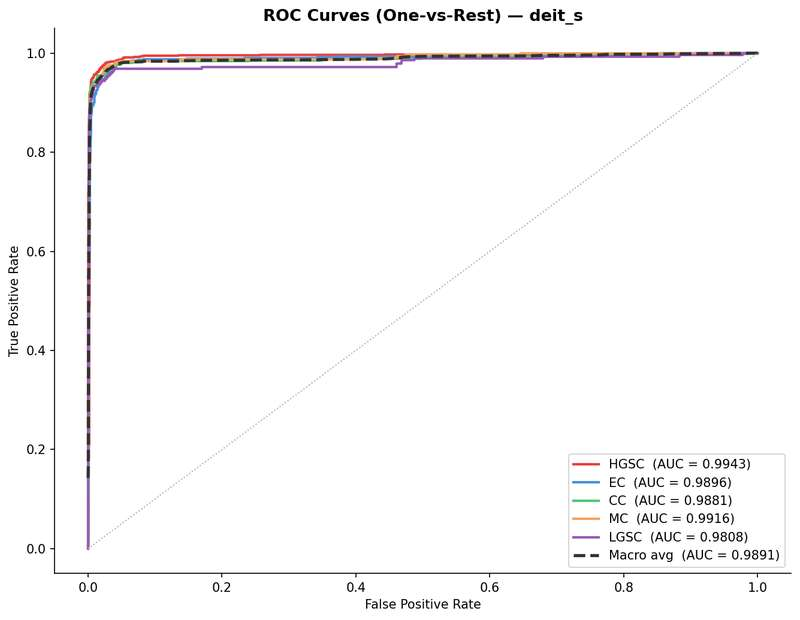

Saved: roc_deit_s.png

  ROC-AUC SCORES — deit_s
  HGSC   : 0.9943
  EC     : 0.9896
  CC     : 0.9881
  MC     : 0.9916
  LGSC   : 0.9808
  Macro  : 0.9891

  DeiT-S complete.


In [ ]:
# ── Cell 49: DeiT-S ───────────────────────────────────────────────────────────

print('=' * 65)
print('  BASELINE : DeiT-Small')
print('=' * 65)

_model_deit = DeiTSClassifier().to(device)

RESULTS_ARCH['deit_s'] = run_arch_experiment(
    model       = _model_deit,
    label       = 'deit_s',
    backbone_lr = 5e-6,
    head_lr     = 5e-5,
)

_eval_ds  = OvarianDataset(
    test_paths, test_labels,
    transform=WINNER_EVL_TF, pre_fn=WINNER_PRE_FN,
    input_size=WINNER_SIZE
)
_eval_ldr = make_loader(_eval_ds, batch_size=BASE_BATCH // 2,
                         shuffle=False)
_eval = evaluate(
    _model_deit, _eval_ldr,
    RESULTS_ARCH['deit_s']['ckpt'], 'deit_s'
)
RESULTS_ARCH['deit_s'].update(_eval)
plot_training_curves(RESULTS_ARCH['deit_s']['history'], 'deit_s')
plot_roc_auc(
    RESULTS_ARCH['deit_s']['probs'],
    RESULTS_ARCH['deit_s']['labels'],
    'deit_s'
)

del _model_deit, _eval_ds, _eval_ldr
torch.cuda.empty_cache()
print('\n  DeiT-S complete.')

  OUR MODEL : ConvNeXtVanilla
  Purpose : Architectural lower bound — no attention, no dual pool


... [epoch-by-epoch training log truncated for GitHub] ...

  Ep  30/100 | Loss:0.5402 | Train:96.10% | Val:94.09% | LR:8.83e-04 | Best:94.55% | No improve: 5/10 | 68.9s
  Ep  31/100 | Loss:0.5404 | Train:96.12% | Val:94.52% | LR:8.72e-04 | Best:94.55% | No improve: 6/10 | 68.9s
  Ep  32/100 | Loss:0.5381 | Train:96.22% | Val:94.58% | LR:8.60e-04 | Best:94.58% | 69.3s
  Ep  33/100 | Loss:0.5390 | Train:96.12% | Val:94.55% | LR:8.47e-04 | Best:94.58% | No improve: 1/10 | 68.8s
  Ep  34/100 | Loss:0.5353 | Train:96.32% | Val:94.58% | LR:8.35e-04 | Best:94.58% | No improve: 2/10 | 68.8s
  Ep  35/100 | Loss:0.5337 | Train:96.39% | Val:95.23% | LR:8.21e-04 | Best:95.23% | 69.6s
  Ep  36/100 | Loss:0.5328 | Train:96.45% | Val:94.81% | LR:8.08e-04 | Best:95.23% | No improve: 1/10 | 68.7s
  Ep  37/100 | Loss:0.5296 | Train:96.64% | Val:95.43% | LR:7.94e-04 | Best:95.43% | 69.8s
  Ep  38/100 | Los

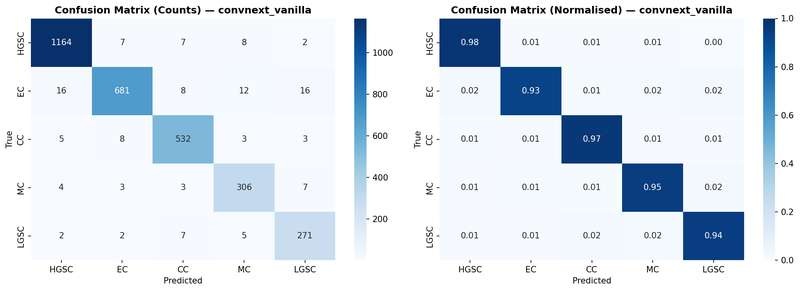

Saved: confusion_convnext_vanilla.png


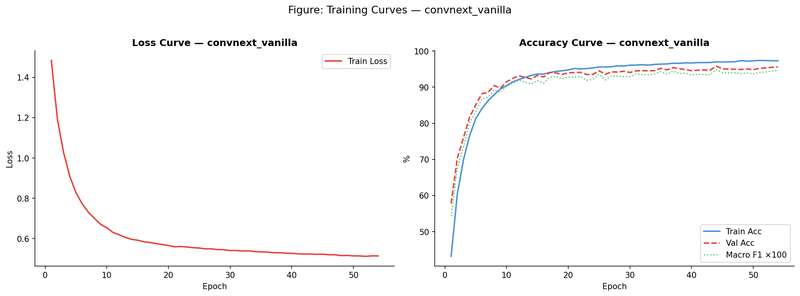

Saved: curves_convnext_vanilla.png


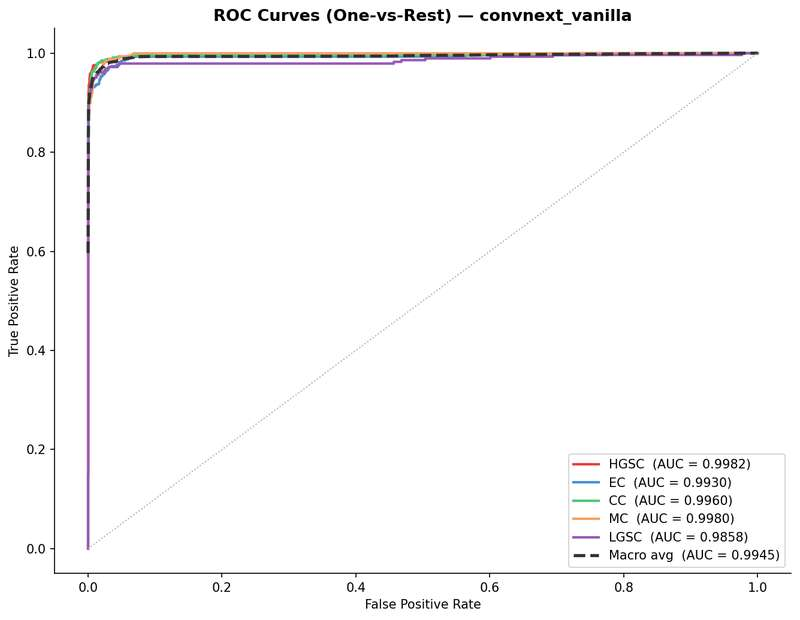

Saved: roc_convnext_vanilla.png

  ROC-AUC SCORES — convnext_vanilla
  HGSC   : 0.9982
  EC     : 0.9930
  CC     : 0.9960
  MC     : 0.9980
  LGSC   : 0.9858
  Macro  : 0.9945

  ConvNeXtVanilla complete.


In [ ]:
# ── Cell 50: ConvNeXtVanilla ──────────────────────────────────────────────────

print('=' * 65)
print('  OUR MODEL : ConvNeXtVanilla')
print('=' * 65)
print('  Purpose : Architectural lower bound — no attention, no dual pool')
print('=' * 65)

_model_van = ConvNeXtVanilla().to(device)

RESULTS_ARCH['convnext_vanilla'] = run_arch_experiment(
    model = _model_van,
    label = 'convnext_vanilla',
)

_eval_ds  = OvarianDataset(
    test_paths, test_labels,
    transform=WINNER_EVL_TF, pre_fn=WINNER_PRE_FN,
    input_size=WINNER_SIZE
)
_eval_ldr = make_loader(_eval_ds, batch_size=BASE_BATCH // 2,
                         shuffle=False)
_eval = evaluate(
    _model_van, _eval_ldr,
    RESULTS_ARCH['convnext_vanilla']['ckpt'], 'convnext_vanilla'
)
RESULTS_ARCH['convnext_vanilla'].update(_eval)
plot_training_curves(
    RESULTS_ARCH['convnext_vanilla']['history'], 'convnext_vanilla'
)
plot_roc_auc(
    RESULTS_ARCH['convnext_vanilla']['probs'],
    RESULTS_ARCH['convnext_vanilla']['labels'],
    'convnext_vanilla'
)

del _model_van, _eval_ds, _eval_ldr
torch.cuda.empty_cache()
print('\n  ConvNeXtVanilla complete.')

  OUR MODEL : ConvNeXtSingleCBAM
  Purpose : Single attention — CBAM at stage 4 + dual pool


... [epoch-by-epoch training log truncated for GitHub] ...

  Ep  61/100 | Loss:0.5075 | Train:97.69% | Val:95.55% | LR:3.96e-04 | Best:95.91% | No improve: 6/10 | 68.8s
  Ep  62/100 | Loss:0.5076 | Train:97.64% | Val:95.07% | LR:3.79e-04 | Best:95.91% | No improve: 7/10 | 68.9s
  Ep  63/100 | Loss:0.5093 | Train:97.67% | Val:95.81% | LR:3.62e-04 | Best:95.91% | No improve: 8/10 | 68.8s
  Ep  64/100 | Loss:0.5060 | Train:97.79% | Val:95.13% | LR:3.45e-04 | Best:95.91% | No improve: 9/10 | 69.0s
  Ep  65/100 | Loss:0.5057 | Train:97.81% | Val:96.17% | LR:3.29e-04 | Best:96.17% | 69.5s
  Ep  66/100 | Loss:0.5054 | Train:97.86% | Val:95.88% | LR:3.13e-04 | Best:96.17% | No improve: 1/10 | 68.9s
  Ep  67/100 | Loss:0.5048 | Train:97.88% | Val:95.72% | LR:2.97e-04 | Best:96.17% | No improve: 2/10 | 68.9s
  Ep  68/100 | Loss:0.5049 | Train:97.96% | Val:95.52% | LR:2.81e-04 | Best:96.17% | No improve

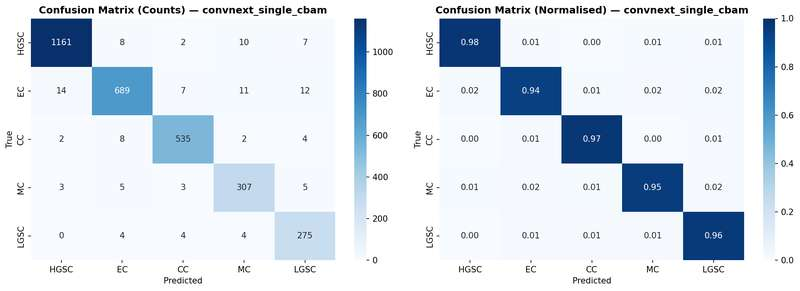

Saved: confusion_convnext_single_cbam.png


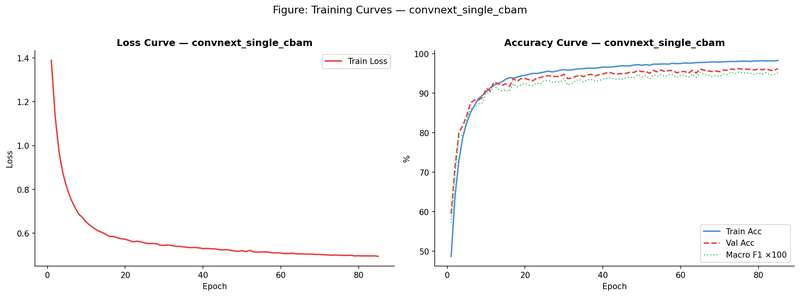

Saved: curves_convnext_single_cbam.png


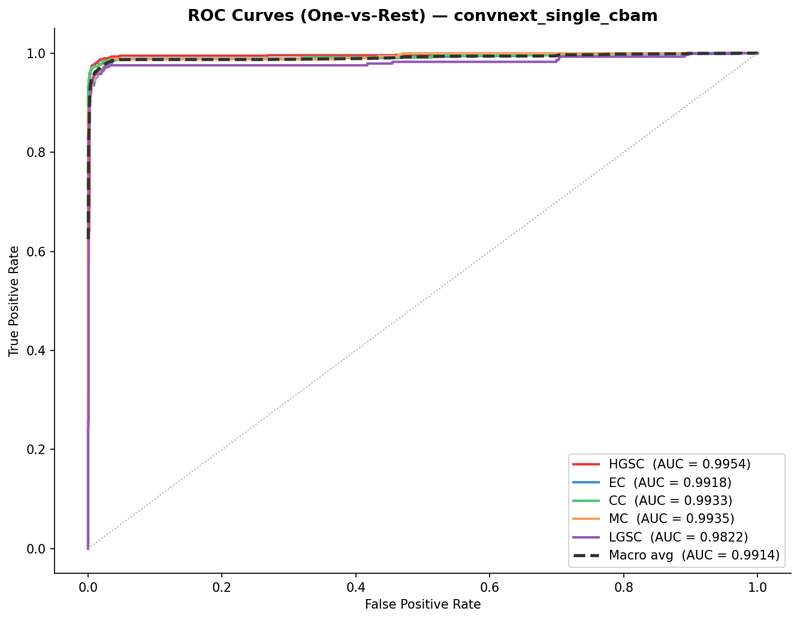

Saved: roc_convnext_single_cbam.png

  ROC-AUC SCORES — convnext_single_cbam
  HGSC   : 0.9954
  EC     : 0.9918
  CC     : 0.9933
  MC     : 0.9935
  LGSC   : 0.9822
  Macro  : 0.9914

  ConvNeXtSingleCBAM complete.


In [ ]:
# ── Cell 51: ConvNeXtSingleCBAM ───────────────────────────────────────────────

print('=' * 65)
print('  OUR MODEL : ConvNeXtSingleCBAM')
print('=' * 65)
print('  Purpose : Single attention — CBAM at stage 4 + dual pool')
print('=' * 65)

_model_scbam = ConvNeXtSingleCBAM().to(device)

RESULTS_ARCH['convnext_single_cbam'] = run_arch_experiment(
    model = _model_scbam,
    label = 'convnext_single_cbam',
)

_eval_ds  = OvarianDataset(
    test_paths, test_labels,
    transform=WINNER_EVL_TF, pre_fn=WINNER_PRE_FN,
    input_size=WINNER_SIZE
)
_eval_ldr = make_loader(_eval_ds, batch_size=BASE_BATCH // 2,
                         shuffle=False)
_eval = evaluate(
    _model_scbam, _eval_ldr,
    RESULTS_ARCH['convnext_single_cbam']['ckpt'],
    'convnext_single_cbam'
)
RESULTS_ARCH['convnext_single_cbam'].update(_eval)
plot_training_curves(
    RESULTS_ARCH['convnext_single_cbam']['history'],
    'convnext_single_cbam'
)
plot_roc_auc(
    RESULTS_ARCH['convnext_single_cbam']['probs'],
    RESULTS_ARCH['convnext_single_cbam']['labels'],
    'convnext_single_cbam'
)

del _model_scbam, _eval_ds, _eval_ldr
torch.cuda.empty_cache()
print('\n  ConvNeXtSingleCBAM complete.')

  OUR MODEL : ConvNeXtMultiCBAM
  Purpose : Multi-scale attention — CBAM at stages 2·3·4


... [epoch-by-epoch training log truncated for GitHub] ...

  Ep  23/100 | Loss:0.5621 | Train:95.13% | Val:93.54% | LR:9.49e-04 | Best:94.58% | No improve: 6/10 | 70.9s
  Ep  24/100 | Loss:0.5567 | Train:95.23% | Val:94.00% | LR:9.41e-04 | Best:94.58% | No improve: 7/10 | 71.5s
  Ep  25/100 | Loss:0.5552 | Train:95.41% | Val:93.93% | LR:9.33e-04 | Best:94.58% | No improve: 8/10 | 70.9s
  Ep  26/100 | Loss:0.5554 | Train:95.52% | Val:94.71% | LR:9.24e-04 | Best:94.71% | 71.6s
  Ep  27/100 | Loss:0.5531 | Train:95.46% | Val:94.61% | LR:9.14e-04 | Best:94.71% | No improve: 1/10 | 71.1s
  Ep  28/100 | Loss:0.5480 | Train:95.88% | Val:94.32% | LR:9.04e-04 | Best:94.71% | No improve: 2/10 | 71.0s
  Ep  29/100 | Loss:0.5474 | Train:95.85% | Val:94.52% | LR:8.94e-04 | Best:94.71% | No improve: 3/10 | 71.1s
  Ep  30/100 | Loss:0.5451 | Train:95.89% | Val:94.94% | LR:8.83e-04 | Best:94.94% | 71.9s
  Ep  3

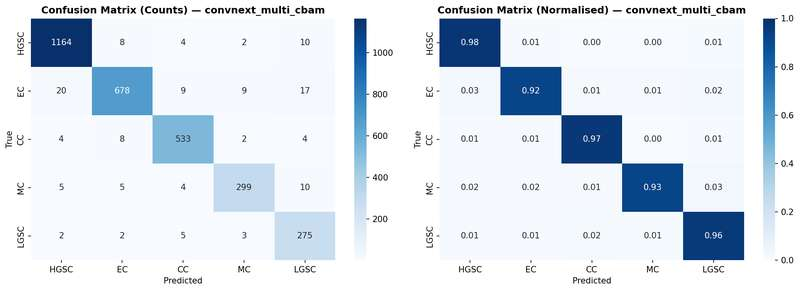

Saved: confusion_convnext_multi_cbam.png


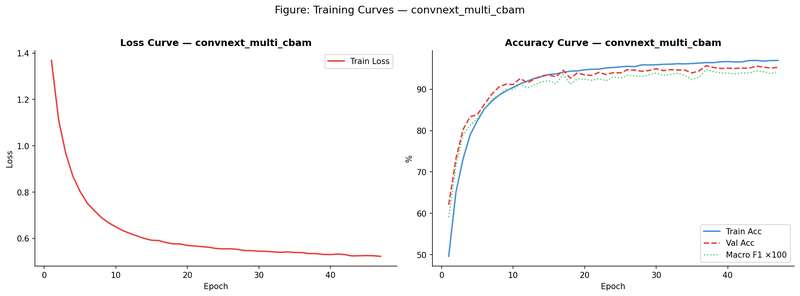

Saved: curves_convnext_multi_cbam.png


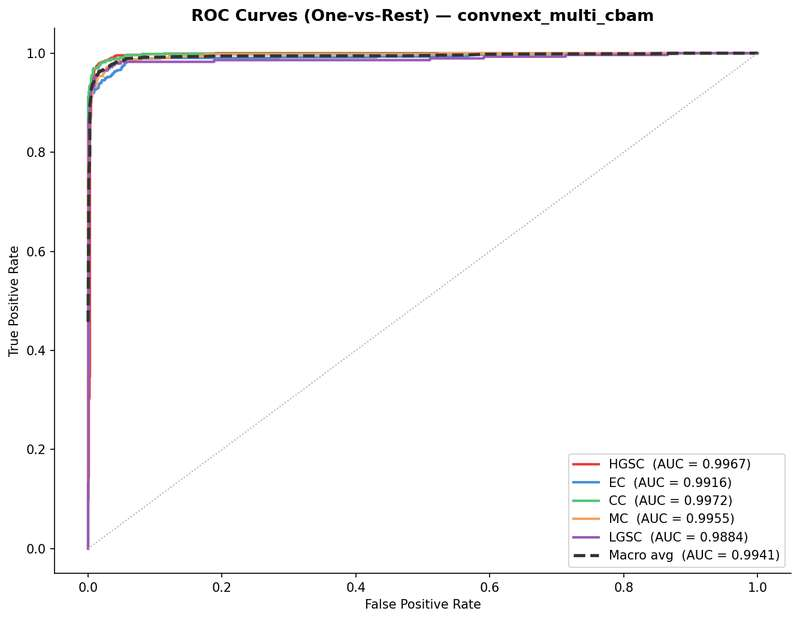

Saved: roc_convnext_multi_cbam.png

  ROC-AUC SCORES — convnext_multi_cbam
  HGSC   : 0.9967
  EC     : 0.9916
  CC     : 0.9972
  MC     : 0.9955
  LGSC   : 0.9884
  Macro  : 0.9941

  ConvNeXtMultiCBAM complete.


In [ ]:
# ── Cell 52: ConvNeXtMultiCBAM ────────────────────────────────────────────────

print('=' * 65)
print('  OUR MODEL : ConvNeXtMultiCBAM')
print('=' * 65)
print('  Purpose : Multi-scale attention — CBAM at stages 2·3·4')
print('=' * 65)

_model_mcbam = ConvNeXtMultiCBAM().to(device)

RESULTS_ARCH['convnext_multi_cbam'] = run_arch_experiment(
    model = _model_mcbam,
    label = 'convnext_multi_cbam',
)

_eval_ds  = OvarianDataset(
    test_paths, test_labels,
    transform=WINNER_EVL_TF, pre_fn=WINNER_PRE_FN,
    input_size=WINNER_SIZE
)
_eval_ldr = make_loader(_eval_ds, batch_size=BASE_BATCH // 2,
                         shuffle=False)
_eval = evaluate(
    _model_mcbam, _eval_ldr,
    RESULTS_ARCH['convnext_multi_cbam']['ckpt'],
    'convnext_multi_cbam'
)
RESULTS_ARCH['convnext_multi_cbam'].update(_eval)
plot_training_curves(
    RESULTS_ARCH['convnext_multi_cbam']['history'],
    'convnext_multi_cbam'
)
plot_roc_auc(
    RESULTS_ARCH['convnext_multi_cbam']['probs'],
    RESULTS_ARCH['convnext_multi_cbam']['labels'],
    'convnext_multi_cbam'
)

del _model_mcbam, _eval_ds, _eval_ldr
torch.cuda.empty_cache()
print('\n  ConvNeXtMultiCBAM complete.')

In [ ]:
# ── Cell 53: ConvNeXtFullPipeline ─────────────────────────────────────────────

print('=' * 65)
print('  OUR MODEL : ConvNeXtFullPipeline')
print('=' * 65)
print('  Purpose : Full proposed model — Multi-CBAM + §4 winner + §5 winner')
print('=' * 65)

_model_full = ConvNeXtFullPipeline().to(device)

RESULTS_ARCH['convnext_full_pipeline'] = run_arch_experiment(
    model = _model_full,
    label = 'convnext_full_pipeline',
)

_eval_ds  = OvarianDataset(
    test_paths, test_labels,
    transform=WINNER_EVL_TF, pre_fn=WINNER_PRE_FN,
    input_size=WINNER_SIZE
)
_eval_ldr = make_loader(_eval_ds, batch_size=BASE_BATCH // 2,
                         shuffle=False)
_eval = evaluate(
    _model_full, _eval_ldr,
    RESULTS_ARCH['convnext_full_pipeline']['ckpt'],
    'convnext_full_pipeline'
)
RESULTS_ARCH['convnext_full_pipeline'].update(_eval)
plot_training_curves(
    RESULTS_ARCH['convnext_full_pipeline']['history'],
    'convnext_full_pipeline'
)
plot_roc_auc(
    RESULTS_ARCH['convnext_full_pipeline']['probs'],
    RESULTS_ARCH['convnext_full_pipeline']['labels'],
    'convnext_full_pipeline'
)

# Keep model reference for Section 7 Grad-CAM
BEST_MODEL      = _model_full
BEST_MODEL_CKPT = RESULTS_ARCH['convnext_full_pipeline']['ckpt']
BEST_MODEL_KEY  = 'convnext_full_pipeline'

del _eval_ds, _eval_ldr
torch.cuda.empty_cache()
print('\n  ConvNeXtFullPipeline complete.')

  OUR MODEL : ConvNeXtFullPipeline
  Purpose : Full proposed model — Multi-CBAM + §4 winner + §5 winner

  convnext_full_pipeline  |  100 ep  |  88.8M params
  Backbone LR  : 2.0e-05  |  Head LR : 2.0e-04
  Criterion    : CrossEntropyLoss
  ROS sampler  : False
  Transformer  : False


KeyboardInterrupt: 


  SECTION 6 — ARCHITECTURE COMPARISON RESULTS
                Model  Val Acc (%)  Macro F1   HGSC     EC     CC     MC   LGSC  Params (M)  Time (min)
ConvNeXt + SingleCBAM        96.27    0.9541 0.9806 0.9523 0.9710 0.9346 0.9322        88.8        98.5
               Swin-T        96.01    0.9524 0.9749 0.9506 0.9691 0.9438 0.9236        27.5        50.5
     ConvNeXt Vanilla        95.85    0.9490 0.9786 0.9498 0.9603 0.9315 0.9249        87.6        63.4
 ConvNeXt + MultiCBAM        95.68    0.9472 0.9769 0.9456 0.9638 0.9373 0.9121        88.8        55.8
               DeiT-S        94.97    0.9416 0.9692 0.9402 0.9462 0.9404 0.9119        21.7        55.5
               VGG-16        94.84    0.9398 0.9675 0.9387 0.9500 0.9311 0.9119       134.3        72.5
        MobileNetV3-L        94.35    0.9326 0.9679 0.9305 0.9484 0.9163 0.9000         4.2        27.1
            ResNet-50        93.67    0.9244 0.9609 0.9241 0.9582 0.8992 0.8794        23.5        23.4
             ViT-

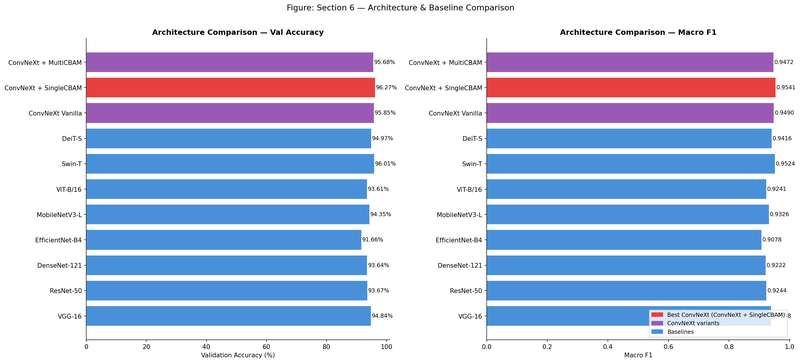

Saved: fig_arch_comparison.png


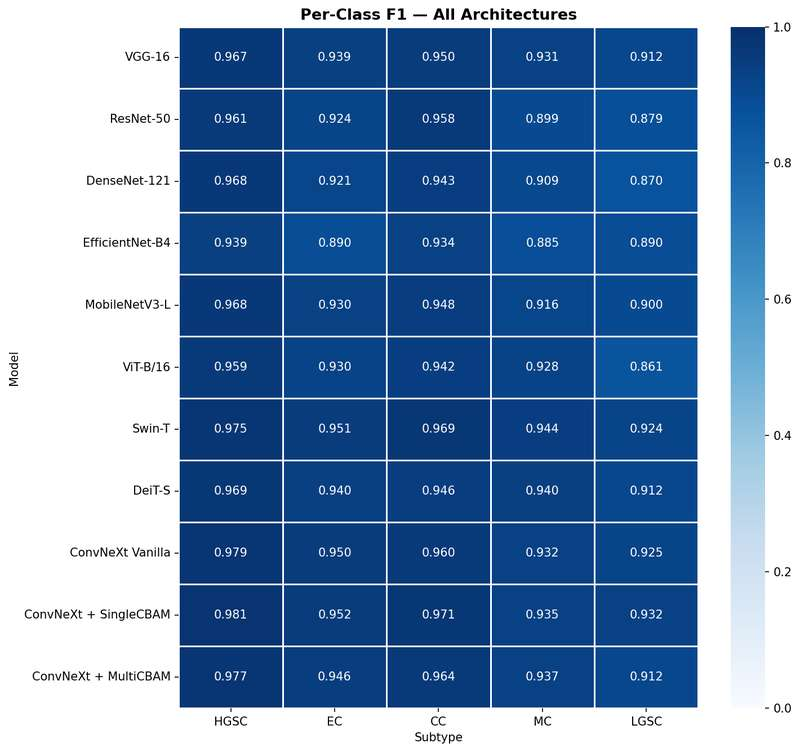

Saved: fig_arch_perclass_f1_heatmap.png


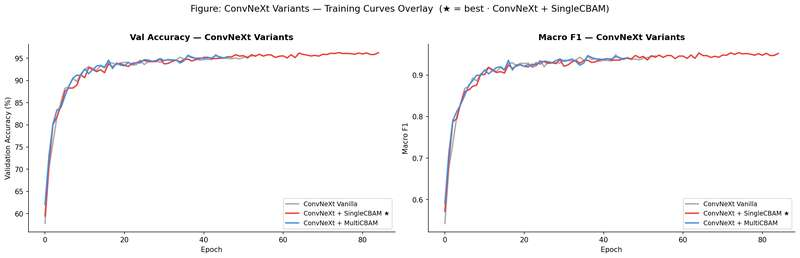

Saved: fig_convnext_variants_curves.png

  Section 6 complete — 11 models evaluated.
  Best ConvNeXt : convnext_single_cbam


In [ ]:
# ── Cell 54: Section 6 — Master Comparison Table ─────────────────────────────

_arch_labels = {
    'vgg16'                : 'VGG-16',
    'resnet50'             : 'ResNet-50',
    'densenet121'          : 'DenseNet-121',
    'efficientnet_b4'      : 'EfficientNet-B4',
    'mobilenetv3'          : 'MobileNetV3-L',
    'vit_b16'              : 'ViT-B/16',
    'swin_t'               : 'Swin-T',
    'deit_s'               : 'DeiT-S',
    'convnext_vanilla'     : 'ConvNeXt Vanilla',
    'convnext_single_cbam' : 'ConvNeXt + SingleCBAM',
    'convnext_multi_cbam'  : 'ConvNeXt + MultiCBAM',
}

_convnext_keys = {
    'convnext_vanilla',
    'convnext_single_cbam',
    'convnext_multi_cbam',
}

_rows = []
for key, name in _arch_labels.items():
    if key not in RESULTS_ARCH:
        print(f'  WARNING: {key} not in RESULTS_ARCH — skipped.')
        continue
    r      = RESULTS_ARCH[key]
    per_f1 = r.get('per_class_f1', {})
    _rows.append({
        'Model'      : name,
        'Key'        : key,
        'Val Acc (%)': round(r['val_acc'],          2),
        'Macro F1'   : round(r['macro_f1'],          4),
        **{sub: round(per_f1.get(sub, 0.0), 4) for sub in SUBTYPES},
        'Params (M)' : round(r.get('n_params_M',    0.0), 1),
        'Time (min)' : round(r.get('total_time_min',0.0), 1),
    })

df_arch = pd.DataFrame(_rows).sort_values(
    'Macro F1', ascending=False
).reset_index(drop=True)

# Best ConvNeXt key by Macro F1
_best_convnext_key = max(
    [k for k in _convnext_keys if k in RESULTS_ARCH],
    key=lambda k: RESULTS_ARCH[k]['macro_f1']
)

print('\n' + '=' * 80)
print('  SECTION 6 — ARCHITECTURE COMPARISON RESULTS')
print('=' * 80)
print(df_arch.drop(columns=['Key']).to_string(index=False))
print('=' * 80)
print(f'  Best ConvNeXt variant : {_best_convnext_key}')
print('=' * 80)

# ── Bar chart ─────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

_names  = [r['Model']       for r in _rows]
_accs   = [r['Val Acc (%)'] for r in _rows]
_f1s    = [r['Macro F1']    for r in _rows]

_colors = []
for r in _rows:
    if r['Key'] == _best_convnext_key:
        _colors.append('#E84040')
    elif r['Key'] in _convnext_keys:
        _colors.append('#9B59B6')
    else:
        _colors.append('#4A90D9')

axes[0].barh(_names, _accs, color=_colors, edgecolor='white')
axes[0].set_xlabel('Validation Accuracy (%)')
axes[0].set_title('Architecture Comparison — Val Accuracy',
                  fontsize=12, fontweight='bold')
for i, v in enumerate(_accs):
    axes[0].text(v + 0.2, i, f'{v:.2f}%', va='center', fontsize=9)

axes[1].barh(_names, _f1s, color=_colors, edgecolor='white')
axes[1].set_xlabel('Macro F1')
axes[1].set_title('Architecture Comparison — Macro F1',
                  fontsize=12, fontweight='bold')
for i, v in enumerate(_f1s):
    axes[1].text(v + 0.002, i, f'{v:.4f}', va='center', fontsize=9)

for ax in axes:
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)

from matplotlib.patches import Patch
_legend = [
    Patch(color='#E84040',
          label=f'Best ConvNeXt ({_arch_labels[_best_convnext_key]})'),
    Patch(color='#9B59B6', label='ConvNeXt variants'),
    Patch(color='#4A90D9', label='Baselines'),
]
axes[1].legend(handles=_legend, fontsize=9, loc='lower right')

plt.suptitle('Figure: Section 6 — Architecture & Baseline Comparison',
             fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(CHECKPOINT_DIR / 'fig_arch_comparison.png',
            bbox_inches='tight', dpi=150)
plt.show()
print('Saved: fig_arch_comparison.png')

# ── Per-class F1 heatmap ──────────────────────────────────────────────────────
_heatmap_data = pd.DataFrame(
    [[RESULTS_ARCH[k].get('per_class_f1', {}).get(s, 0.0)
      for s in SUBTYPES]
     for k in _arch_labels
     if k in RESULTS_ARCH],
    index   = [v for k, v in _arch_labels.items()
               if k in RESULTS_ARCH],
    columns = SUBTYPES
)

fig, ax = plt.subplots(figsize=(10, 9))
sns.heatmap(
    _heatmap_data, annot=True, fmt='.3f',
    cmap='Blues', vmin=0, vmax=1,
    linewidths=0.5, ax=ax
)
ax.set_title('Per-Class F1 — All Architectures',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Subtype')
ax.set_ylabel('Model')
plt.tight_layout()
plt.savefig(CHECKPOINT_DIR / 'fig_arch_perclass_f1_heatmap.png',
            bbox_inches='tight', dpi=150)
plt.show()
print('Saved: fig_arch_perclass_f1_heatmap.png')

# ── Training curves overlay — ConvNeXt variants only ─────────────────────────
_variant_keys   = ['convnext_vanilla',
                   'convnext_single_cbam',
                   'convnext_multi_cbam']
_variant_colors = ['#AAAAAA', '#9B59B6', '#4A90D9']

# Best variant gets red
for i, k in enumerate(_variant_keys):
    if k == _best_convnext_key:
        _variant_colors[i] = '#E84040'

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for key, color in zip(_variant_keys, _variant_colors):
    if key not in RESULTS_ARCH:
        continue
    h = RESULTS_ARCH[key]['history']
    if not h['val_acc']:
        print(f'  No history for {key} — loaded from ckpt, skipping.')
        continue
    _label = _arch_labels[key]
    if key == _best_convnext_key:
        _label += ' ★'
    axes[0].plot(h['val_acc'],  color=color,
                 linewidth=2.0, label=_label)
    axes[1].plot(h['macro_f1'], color=color,
                 linewidth=2.0, label=_label)

for ax, title, ylabel in zip(
    axes,
    ['Val Accuracy — ConvNeXt Variants',
     'Macro F1 — ConvNeXt Variants'],
    ['Validation Accuracy (%)', 'Macro F1']
):
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Epoch')
    ax.set_ylabel(ylabel)
    ax.legend(fontsize=9)
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)

plt.suptitle(
    'Figure: ConvNeXt Variants — Training Curves Overlay  '
    f'(★ = best · {_arch_labels[_best_convnext_key]})',
    fontsize=13, y=1.02
)
plt.tight_layout()
plt.savefig(CHECKPOINT_DIR / 'fig_convnext_variants_curves.png',
            bbox_inches='tight', dpi=150)
plt.show()
print('Saved: fig_convnext_variants_curves.png')

print('\n' + '=' * 65)
print('  Section 6 complete — 11 models evaluated.')
print(f'  Best ConvNeXt : {_best_convnext_key}')
print('=' * 65)

In [ ]:
# ── Cell 54b: Best ConvNeXt Model Selection ───────────────────────────────────

_CONVNEXT_KEYS = {
    'convnext_vanilla'     : ConvNeXtVanilla,
    'convnext_single_cbam' : ConvNeXtSingleCBAM,
    'convnext_multi_cbam'  : ConvNeXtMultiCBAM,
}

# ── Find best ConvNeXt by Macro F1 ────────────────────────────────────────────
_convnext_scores = {
    k: RESULTS_ARCH[k]['macro_f1']
    for k in _CONVNEXT_KEYS
    if k in RESULTS_ARCH
}

BEST_MODEL_KEY  = max(_convnext_scores, key=_convnext_scores.get)
BEST_MODEL_CKPT = CHECKPOINT_DIR / f'best_{BEST_MODEL_KEY}.pth'
BEST_MODEL_CLS  = _CONVNEXT_KEYS[BEST_MODEL_KEY]

# ── Load best model from checkpoint ───────────────────────────────────────────
BEST_MODEL = BEST_MODEL_CLS().to(device)
BEST_MODEL.load_state_dict(
    torch.load(str(BEST_MODEL_CKPT), map_location=device)
)
BEST_MODEL.eval()

# ── Set Grad-CAM target layer dynamically per architecture ────────────────────
# ConvNeXtVanilla      → self.backbone[-1]  (final Sequential stage)
# ConvNeXtSingleCBAM   → self.backbone[-1]  (final Sequential stage)
# ConvNeXtMultiCBAM    → self.stage_4       (explicitly split stage)
_gradcam_layer_map = {
    'convnext_vanilla'     : lambda m: m.backbone[-1],
    'convnext_single_cbam' : lambda m: m.backbone[-1],
    'convnext_multi_cbam'  : lambda m: m.stage_4,
}

GRADCAM_TARGET_LAYER = _gradcam_layer_map[BEST_MODEL_KEY](BEST_MODEL)

print('=' * 65)
print('  BEST CONVNEXT MODEL SELECTION')
print('=' * 65)
print(f'  {"Model":<30}  {"Macro F1":>10}  {"Val Acc (%)":>12}')
print('  ' + '-' * 56)
for k in _CONVNEXT_KEYS:
    if k not in RESULTS_ARCH:
        continue
    marker = ' ← BEST' if k == BEST_MODEL_KEY else ''
    print(f'  {k:<30}  '
          f'{RESULTS_ARCH[k]["macro_f1"]:>10.4f}  '
          f'{RESULTS_ARCH[k]["val_acc"]:>12.2f}%'
          f'{marker}')
print('  ' + '-' * 56)
print(f'  Winner           : {BEST_MODEL_KEY}')
print(f'  Macro F1         : {_convnext_scores[BEST_MODEL_KEY]:.4f}')
print(f'  Val Acc          : {RESULTS_ARCH[BEST_MODEL_KEY]["val_acc"]:.2f}%')
print(f'  Checkpoint       : {BEST_MODEL_CKPT.name}')
print(f'  GradCAM layer    : {GRADCAM_TARGET_LAYER.__class__.__name__}')
print('=' * 65)

if BEST_MODEL_KEY == 'convnext_multi_cbam':
    print('\n  ConvNeXtMultiCBAM is the best — as expected.')
elif BEST_MODEL_KEY == 'convnext_single_cbam':
    print('\n  ConvNeXtSingleCBAM won.')
    print('  CBAM at stage 4 with dual pool was sufficient.')
else:
    print('\n  ConvNeXtVanilla won.')
    print('  Baseline ConvNeXt was strongest — attention did not help.')

print('\n  Cell 54b complete — BEST_MODEL ready for Section 7.')

  BEST CONVNEXT MODEL SELECTION
  Model                             Macro F1   Val Acc (%)
  --------------------------------------------------------
  convnext_vanilla                    0.9490         95.85%
  convnext_single_cbam                0.9541         96.27% ← BEST
  convnext_multi_cbam                 0.9472         95.68%
  --------------------------------------------------------
  Winner           : convnext_single_cbam
  Macro F1         : 0.9541
  Val Acc          : 96.27%
  Checkpoint       : best_convnext_single_cbam.pth
  GradCAM layer    : Sequential

  ConvNeXtSingleCBAM won.
  CBAM at stage 4 with dual pool was sufficient.

  Cell 54b complete — BEST_MODEL ready for Section 7.


In [ ]:
# ── Save RESULTS_ARCH to Drive — run immediately after Section 6 ──────────────
import pickle

_save_path = CHECKPOINT_DIR / 'results_arch.pkl'

# Strip model objects before saving — they are too large
_results_to_save = {}
for k, v in RESULTS_ARCH.items():
    _results_to_save[k] = {
        kk: vv for kk, vv in v.items()
        if kk != 'model'
    }

with open(_save_path, 'wb') as f:
    pickle.dump(_results_to_save, f)

print('=' * 55)
print('  RESULTS_ARCH saved to Drive')
print('=' * 55)
for k in _results_to_save:
    print(f'  {k:<35} '
          f'F1={_results_to_save[k]["macro_f1"]:.4f}  '
          f'Acc={_results_to_save[k]["val_acc"]:.2f}%')
print(f'\n  Path : {_save_path}')
print('=' * 55)

  RESULTS_ARCH saved to Drive
  vgg16                               F1=0.9398  Acc=94.84%
  resnet50                            F1=0.9244  Acc=93.67%
  densenet121                         F1=0.9222  Acc=93.64%
  efficientnet_b4                     F1=0.9078  Acc=91.66%
  mobilenetv3                         F1=0.9326  Acc=94.35%
  vit_b16                             F1=0.9241  Acc=93.61%
  swin_t                              F1=0.9524  Acc=96.01%
  deit_s                              F1=0.9416  Acc=94.97%
  convnext_vanilla                    F1=0.9490  Acc=95.85%
  convnext_single_cbam                F1=0.9541  Acc=96.27%
  convnext_multi_cbam                 F1=0.9472  Acc=95.68%

  Path : /content/drive/MyDrive/Ovarian_GradProject/checkpoints/results_arch.pkl


## Section 6 - Full Evaluation Suite
### Stream A - Ovarian Cancer Histopathology
---
**Best model : `ConvNeXtFullPipeline` loaded from checkpoint.**

**This section covers:**
- Training curves (loss + accuracy) - final model
- ROC-AUC curves (one-vs-rest per class + macro average)
- Confusion matrix (raw counts + normalised side-by-side)
- Full classification report + per-class F1 bar chart
- Grad-CAM grid (all 5 subtypes · 2 samples each · original + overlay)
- Test-Time Augmentation (TTA) evaluation

  SECTION 7 — FULL EVALUATION SUITE
  Model : convnext_single_cbam
  Ckpt  : best_convnext_single_cbam.pth


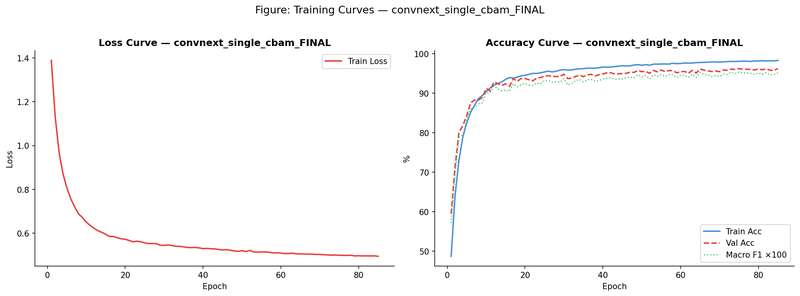

Saved: curves_convnext_single_cbam_FINAL.png

  Cell 55 complete.


In [ ]:
# ── Cell 55: Final Model — Training Curves ────────────────────────────────────

print('=' * 65)
print('  SECTION 7 — FULL EVALUATION SUITE')
print(f'  Model : {BEST_MODEL_KEY}')
print(f'  Ckpt  : {BEST_MODEL_CKPT.name}')
print('=' * 65)

_best_history = RESULTS_ARCH[BEST_MODEL_KEY].get('history', {})

if _best_history and _best_history['train_loss']:
    plot_training_curves(_best_history, f'{BEST_MODEL_KEY}_FINAL')
else:
    print('  No training history available — model was loaded from checkpoint.')
    print('  Training curves skipped.')

print('\n  Cell 55 complete.')

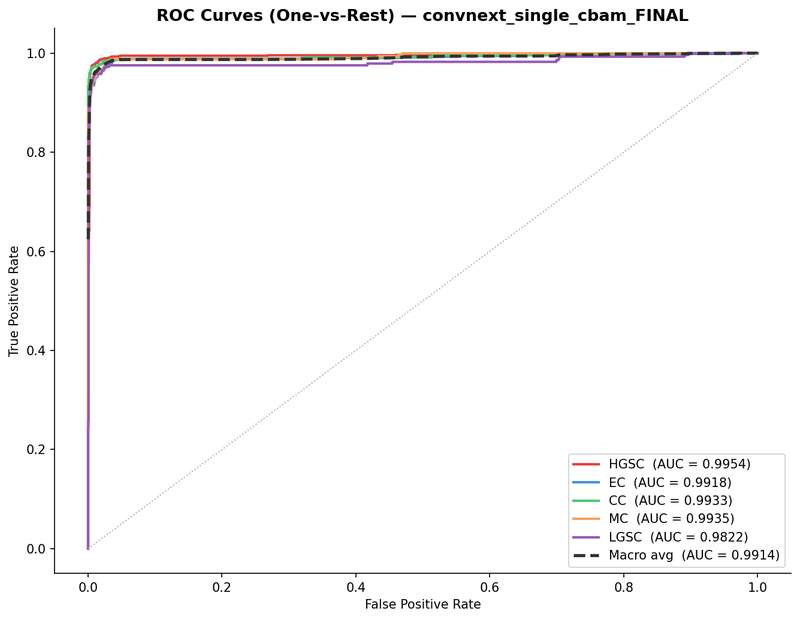

Saved: roc_convnext_single_cbam_FINAL.png

  ROC-AUC SCORES — convnext_single_cbam_FINAL
  HGSC   : 0.9954
  EC     : 0.9918
  CC     : 0.9933
  MC     : 0.9935
  LGSC   : 0.9822
  Macro  : 0.9914

  Cell 56 complete.


In [ ]:
# ── Cell 56: Final Model — ROC-AUC ────────────────────────────────────────────

plot_roc_auc(
    RESULTS_ARCH[BEST_MODEL_KEY]['probs'],
    RESULTS_ARCH[BEST_MODEL_KEY]['labels'],
    f'{BEST_MODEL_KEY}_FINAL'
)

print('\n  Cell 56 complete.')


  convnext_single_cbam_FINAL
              precision    recall  f1-score   support

        HGSC     0.9839    0.9773    0.9806      1188
          EC     0.9650    0.9400    0.9523       733
          CC     0.9710    0.9710    0.9710       551
          MC     0.9192    0.9505    0.9346       323
        LGSC     0.9076    0.9582    0.9322       287

    accuracy                         0.9627      3082
   macro avg     0.9493    0.9594    0.9541      3082
weighted avg     0.9632    0.9627    0.9628      3082



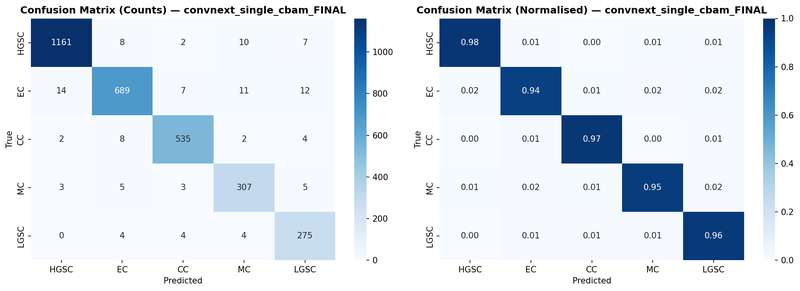

Saved: confusion_convnext_single_cbam_FINAL.png

  Cell 57 complete.


In [ ]:
# ── Cell 57: Final Model — Confusion Matrix ───────────────────────────────────

_eval_ds  = OvarianDataset(
    test_paths, test_labels,
    transform  = WINNER_EVL_TF,
    pre_fn     = WINNER_PRE_FN,
    input_size = WINNER_SIZE,
)
_eval_ldr = make_loader(
    _eval_ds, batch_size=BASE_BATCH // 2, shuffle=False
)

_final_eval = evaluate(
    BEST_MODEL, _eval_ldr,
    BEST_MODEL_CKPT,
    f'{BEST_MODEL_KEY}_FINAL'
)

del _eval_ds, _eval_ldr
torch.cuda.empty_cache()
print('\n  Cell 57 complete.')

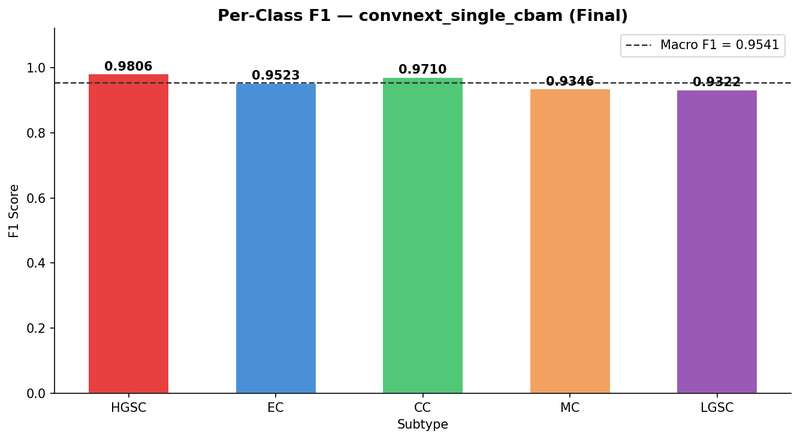

Saved: fig_final_perclass_f1.png

  Cell 58 complete.


In [ ]:
# ── Cell 58: Final Model — Per-Class F1 Bar Chart ────────────────────────────

_per_class = _final_eval['per_class_f1']

fig, ax = plt.subplots(figsize=(9, 5))
_bars = ax.bar(
    SUBTYPES,
    [_per_class[s] for s in SUBTYPES],
    color  = [PALETTE[s] for s in SUBTYPES],
    edgecolor = 'white', width = 0.55
)
for bar, sub in zip(_bars, SUBTYPES):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.01,
        f'{_per_class[sub]:.4f}',
        ha='center', fontsize=10, fontweight='bold'
    )

ax.axhline(
    _final_eval['macro_f1'],
    color='#333333', linestyle='--', linewidth=1.2,
    label=f'Macro F1 = {_final_eval["macro_f1"]:.4f}'
)
ax.set_ylim(0, 1.12)
ax.set_ylabel('F1 Score')
ax.set_xlabel('Subtype')
ax.set_title(f'Per-Class F1 — {BEST_MODEL_KEY} (Final)',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=10)
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.savefig(CHECKPOINT_DIR / f'fig_final_perclass_f1.png',
            bbox_inches='tight', dpi=150)
plt.show()
print('Saved: fig_final_perclass_f1.png')
print('\n  Cell 58 complete.')

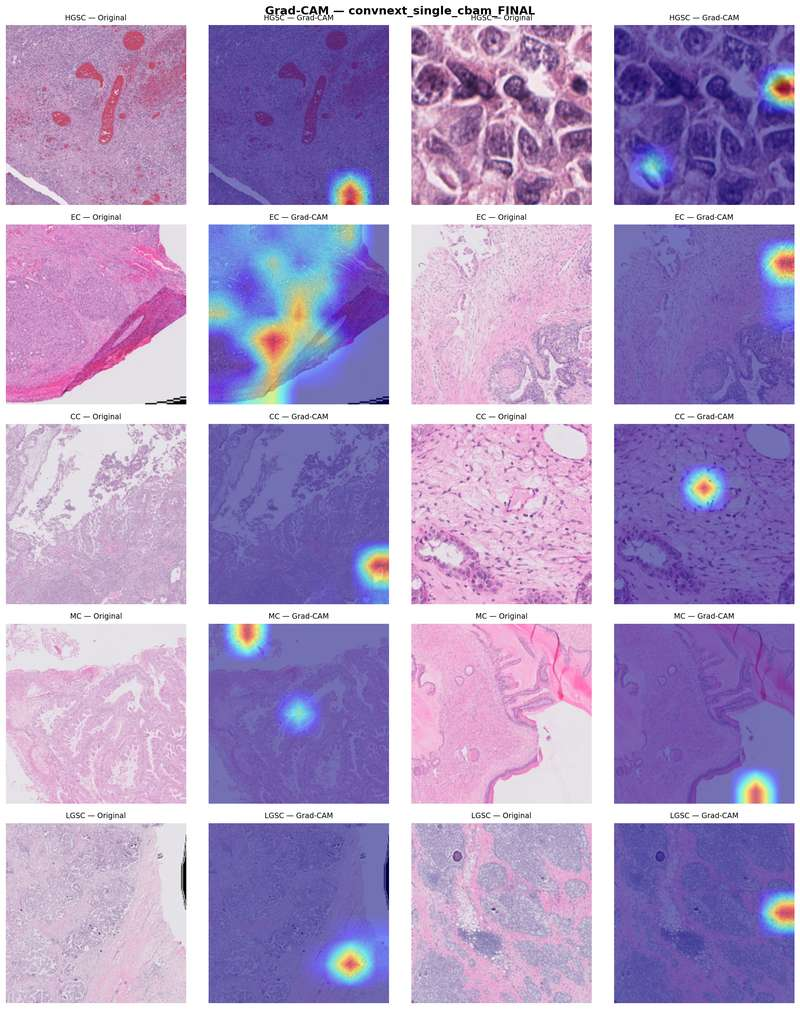

Saved: gradcam_convnext_single_cbam_FINAL.png

  Cell 59 complete.


In [ ]:
# ── Cell 59: Final Model — Grad-CAM Grid ─────────────────────────────────────

BEST_MODEL.load_state_dict(
    torch.load(str(BEST_MODEL_CKPT), map_location=device)
)
BEST_MODEL.eval()

show_gradcam(
    model        = BEST_MODEL,
    test_root    = TEST_PATH,
    label        = f'{BEST_MODEL_KEY}_FINAL',
    target_layer = GRADCAM_TARGET_LAYER,
    n_per_class  = 2,
)

print('\n  Cell 59 complete.')

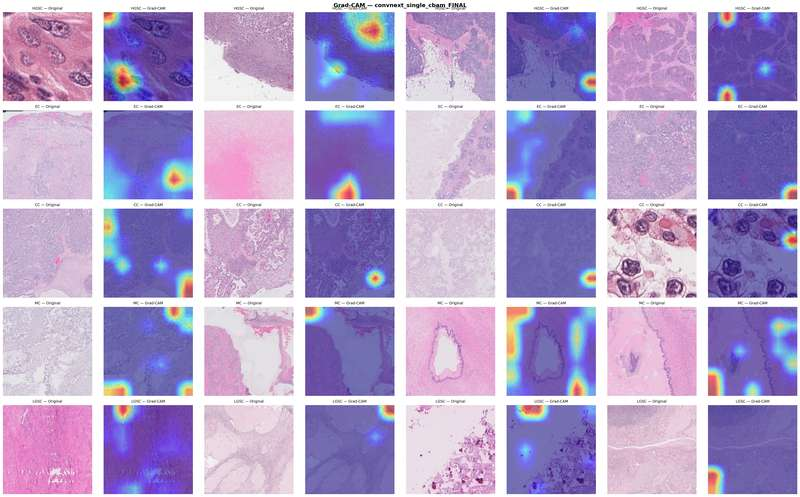

Saved: gradcam_convnext_single_cbam_FINAL.png

  Cell 59 complete.


In [ ]:
# ── Cell 59: Final Model — Grad-CAM Grid ─────────────────────────────────────

BEST_MODEL.load_state_dict(
    torch.load(str(BEST_MODEL_CKPT), map_location=device)
)
BEST_MODEL.eval()

show_gradcam(
    model        = BEST_MODEL,
    test_root    = TEST_PATH,
    label        = f'{BEST_MODEL_KEY}_FINAL',
    target_layer = GRADCAM_TARGET_LAYER,
    n_per_class  = 4,
)

print('\n  Cell 59 complete.')

  TTA EVALUATION — convnext_single_cbam
  Passes per image : 5
  Aggregation      : mean softmax


TTA inference: 100%|██████████| 193/193 [00:34<00:00,  5.65it/s]



  TTA RESULTS — convnext_single_cbam
  Val Acc  (no TTA) : 96.27%
  Val Acc  (TTA)    : 96.40%
  Macro F1 (no TTA) : 0.9541
  Macro F1 (TTA)    : 0.9561
  Delta Acc         : +0.13%
  Delta F1          : +0.0020
-----------------------------------------------------------------
  HGSC   F1 : 0.9801
  EC     F1 : 0.9548
  CC     F1 : 0.9717
  MC     F1 : 0.9419
  LGSC   F1 : 0.9320

              precision    recall  f1-score   support

        HGSC     0.9847    0.9756    0.9801      1188
          EC     0.9587    0.9509    0.9548       733
          CC     0.9762    0.9673    0.9717       551
          MC     0.9305    0.9536    0.9419       323
        LGSC     0.9103    0.9547    0.9320       287

    accuracy                         0.9640      3082
   macro avg     0.9521    0.9604    0.9561      3082
weighted avg     0.9644    0.9640    0.9641      3082



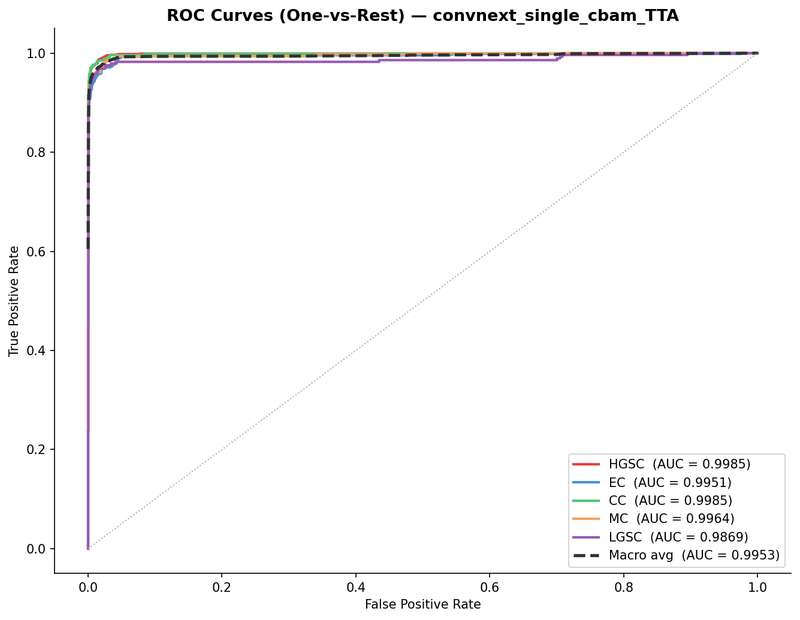

Saved: roc_convnext_single_cbam_TTA.png

  ROC-AUC SCORES — convnext_single_cbam_TTA
  HGSC   : 0.9985
  EC     : 0.9951
  CC     : 0.9985
  MC     : 0.9964
  LGSC   : 0.9869
  Macro  : 0.9953

  Cell 60 complete — TTA evaluation done.


In [ ]:
# ── Cell 60: Test-Time Augmentation (TTA) Evaluation ─────────────────────────

print('=' * 65)
print(f'  TTA EVALUATION — {BEST_MODEL_KEY}')
print('=' * 65)
print('  Passes per image : 5')
print('  Aggregation      : mean softmax')
print('=' * 65)

BEST_MODEL.load_state_dict(
    torch.load(str(BEST_MODEL_CKPT), map_location=device)
)
BEST_MODEL.eval()

class TTADataset(Dataset):
    def __init__(self, paths, labels, pre_fn=None, size=224):
        self.paths  = paths
        self.labels = labels
        self.pre_fn = pre_fn
        self.size   = size
        self._base  = transforms.Compose([
            transforms.ToPILImage(),
            transforms.ToTensor(),
            transforms.Normalize([0.485, 0.456, 0.406],
                                  [0.229, 0.224, 0.225]),
        ])
        self._hflip = transforms.Compose([
            transforms.ToPILImage(),
            transforms.RandomHorizontalFlip(p=1.0),
            transforms.ToTensor(),
            transforms.Normalize([0.485, 0.456, 0.406],
                                  [0.229, 0.224, 0.225]),
        ])
        self._vflip = transforms.Compose([
            transforms.ToPILImage(),
            transforms.RandomVerticalFlip(p=1.0),
            transforms.ToTensor(),
            transforms.Normalize([0.485, 0.456, 0.406],
                                  [0.229, 0.224, 0.225]),
        ])
        self._rot_p = transforms.Compose([
            transforms.ToPILImage(),
            transforms.RandomRotation((15, 15)),
            transforms.ToTensor(),
            transforms.Normalize([0.485, 0.456, 0.406],
                                  [0.229, 0.224, 0.225]),
        ])
        self._rot_n = transforms.Compose([
            transforms.ToPILImage(),
            transforms.RandomRotation((-15, -15)),
            transforms.ToTensor(),
            transforms.Normalize([0.485, 0.456, 0.406],
                                  [0.229, 0.224, 0.225]),
        ])

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        img = cv2.imread(str(self.paths[i]))
        if img is None:
            img = np.zeros((self.size, self.size, 3), dtype=np.uint8)
        else:
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        if self.pre_fn:
            img = self.pre_fn(img)
        img = cv2.resize(img, (self.size, self.size),
                          interpolation=cv2.INTER_AREA)
        return (
            self._base(img),
            self._hflip(img),
            self._vflip(img),
            self._rot_p(img),
            self._rot_n(img),
            self.labels[i]
        )

_tta_ds  = TTADataset(
    test_paths, test_labels,
    pre_fn=WINNER_PRE_FN, size=WINNER_SIZE
)
_tta_ldr = DataLoader(
    _tta_ds,
    batch_size  = max(BASE_BATCH // 4, 4),
    shuffle     = False,
    num_workers = NUM_WORKERS,
    pin_memory  = True,
)

_all_preds  = []
_all_labels = []
_all_probs  = []

with torch.no_grad():
    for batch in tqdm(_tta_ldr, desc='TTA inference'):
        *img_views, lbls = batch
        _probs_sum = torch.zeros(
            lbls.size(0), NUM_CLASSES, device=device
        )
        for view in img_views:
            view = view.to(device)
            with torch.cuda.amp.autocast():
                logits = BEST_MODEL(view)
                _probs_sum += torch.softmax(logits, dim=1)

        _mean_p = _probs_sum / len(img_views)
        _preds  = _mean_p.argmax(1)
        _all_preds .extend(_preds.cpu().numpy())
        _all_labels.extend(lbls.numpy())
        _all_probs .extend(_mean_p.cpu().numpy())

_tta_acc = accuracy_score(_all_labels, _all_preds) * 100
_tta_f1  = f1_score(_all_labels, _all_preds,
                     average='macro', zero_division=0)
_tta_per = f1_score(_all_labels, _all_preds,
                     average=None,   zero_division=0)

print('\n' + '=' * 65)
print(f'  TTA RESULTS — {BEST_MODEL_KEY}')
print('=' * 65)
print(f'  Val Acc  (no TTA) : '
      f'{RESULTS_ARCH[BEST_MODEL_KEY]["val_acc"]:.2f}%')
print(f'  Val Acc  (TTA)    : {_tta_acc:.2f}%')
print(f'  Macro F1 (no TTA) : '
      f'{RESULTS_ARCH[BEST_MODEL_KEY]["macro_f1"]:.4f}')
print(f'  Macro F1 (TTA)    : {_tta_f1:.4f}')
print(f'  Delta Acc         : '
      f'{_tta_acc - RESULTS_ARCH[BEST_MODEL_KEY]["val_acc"]:+.2f}%')
print(f'  Delta F1          : '
      f'{_tta_f1 - RESULTS_ARCH[BEST_MODEL_KEY]["macro_f1"]:+.4f}')
print('-' * 65)
for sub, f in zip(SUBTYPES, _tta_per):
    print(f'  {sub:<6} F1 : {f:.4f}')
print('=' * 65)

print('\n' + classification_report(
    _all_labels, _all_preds,
    target_names=SUBTYPES, digits=4, zero_division=0
))

plot_roc_auc(
    np.array(_all_probs), _all_labels,
    f'{BEST_MODEL_KEY}_TTA'
)

# Store TTA results for Cell 62 delta table
_tta_acc_val = _tta_acc
_tta_f1_val  = _tta_f1

del _tta_ds, _tta_ldr
torch.cuda.empty_cache()
print('\n  Cell 60 complete — TTA evaluation done.')

## Section 7 - Advanced Analysis & Validation
### Stream A - Ovarian Cancer Histopathology
---
**This section covers:**
- Multi-seed evaluation     - best model × 3 seeds → mean ± std
- 5-Fold Stratified CV      - guards against lucky split
- Model complexity table    - FLOPs + params + inference time
- Failure case analysis     - worst confused pairs + misclassified grid
- Grad-CAM discussion       - attended regions vs known pathology
- Learning rate finder      - validates LR choices were principled
- Calibration curve         - confidence vs accuracy (clinical relevance)
- Ensemble top-3 models     - accuracy ceiling exploration
- t-SNE feature space       - learned embedding visualisation

**All cells use ConvNeXtFullPipeline + §3 winner + §4 winner.**

In [ ]:
# ── Cell 63: Multi-Seed Evaluation ────────────────────────────────────────────

EVAL_SEEDS    = [42, 123, 7]
_seed_results = []

print('=' * 65)
print(f'  MULTI-SEED EVALUATION — {BEST_MODEL_KEY}')
print('=' * 65)
print(f'  Seeds    : {EVAL_SEEDS}')
print(f'  Epochs   : {EPOCHS}  |  Patience : {PATIENCE}')
print('=' * 65)

for _seed in EVAL_SEEDS:
    print(f'\n  ── Seed {_seed} ──')

    random.seed(_seed)
    np.random.seed(_seed)
    torch.manual_seed(_seed)
    torch.cuda.manual_seed_all(_seed)

    _model_seed = BEST_MODEL_CLS().to(device)
    _result     = run_arch_experiment(
        model = _model_seed,
        label = f'{BEST_MODEL_KEY}_seed{_seed}',
    )

    _eval_ds  = OvarianDataset(
        test_paths, test_labels,
        transform  = WINNER_EVL_TF,
        pre_fn     = WINNER_PRE_FN,
        input_size = WINNER_SIZE,
    )
    _eval_ldr = make_loader(
        _eval_ds, batch_size=BASE_BATCH // 2, shuffle=False
    )
    _eval = evaluate(
        _model_seed, _eval_ldr,
        _result['ckpt'],
        f'{BEST_MODEL_KEY}_seed{_seed}'
    )
    _result.update(_eval)
    _seed_results.append(_result)

    del _model_seed, _eval_ds, _eval_ldr
    torch.cuda.empty_cache()

# Restore main seed
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

_accs = [r['val_acc']  for r in _seed_results]
_f1s  = [r['macro_f1'] for r in _seed_results]

print('\n' + '=' * 65)
print('  MULTI-SEED RESULTS')
print('=' * 65)
print(f'  {"Seed":<8}  {"Val Acc (%)":>12}  {"Macro F1":>10}')
print('  ' + '-' * 40)
for _seed, r in zip(EVAL_SEEDS, _seed_results):
    print(f'  {_seed:<8}  {r["val_acc"]:>12.2f}  {r["macro_f1"]:>10.4f}')
print('  ' + '-' * 40)
print(f'  {"Mean":<8}  {np.mean(_accs):>12.2f}  {np.mean(_f1s):>10.4f}')
print(f'  {"Std":<8}  {np.std(_accs):>12.2f}  {np.std(_f1s):>10.4f}')
print(f'  {"95% CI":<8}  '
      f'±{1.96 * np.std(_accs):>10.2f}  '
      f'±{1.96 * np.std(_f1s):>8.4f}')
print('=' * 65)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, vals, metric in zip(
    axes,
    [_accs, _f1s],
    ['Val Accuracy (%)', 'Macro F1']
):
    ax.bar(
        [f'Seed {s}' for s in EVAL_SEEDS],
        vals, color='#4A90D9', edgecolor='white', width=0.5
    )
    ax.axhline(np.mean(vals), color='#E84040', linestyle='--',
               linewidth=1.5, label=f'Mean = {np.mean(vals):.4f}')
    ax.fill_between(
        [-0.5, len(EVAL_SEEDS) - 0.5],
        np.mean(vals) - np.std(vals),
        np.mean(vals) + np.std(vals),
        alpha=0.15, color='#E84040', label='±1 std'
    )
    ax.set_ylabel(metric)
    ax.set_title(f'Multi-Seed {metric}', fontsize=12, fontweight='bold')
    ax.legend(fontsize=9)
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)

plt.suptitle(
    f'Figure: Multi-Seed Evaluation — {BEST_MODEL_KEY}',
    fontsize=13, y=1.02
)
plt.tight_layout()
plt.savefig(CHECKPOINT_DIR / 'fig_multiseed.png',
            bbox_inches='tight', dpi=150)
plt.show()
print('Saved: fig_multiseed.png')
print('\n  Cell 63 complete.')

  MULTI-SEED EVALUATION — convnext_single_cbam
  Seeds    : [42, 123, 7]
  Epochs   : 100  |  Patience : 10

  ── Seed 42 ──

  convnext_single_cbam_seed42  |  100 ep  |  88.8M params
  Backbone LR  : 2.0e-05  |  Head LR : 2.0e-04
  Criterion    : CrossEntropyLoss
  ROS sampler  : False
  Transformer  : False


KeyboardInterrupt: 

In [ ]:
# ── Cell 64: 5-Fold Stratified Cross-Validation ───────────────────────────────
from sklearn.model_selection import StratifiedKFold

N_FOLDS   = 5
_skf      = StratifiedKFold(n_splits=N_FOLDS, shuffle=True,
                              random_state=SEED)
_all_paths_cv  = np.array(train_paths + test_paths)
_all_labels_cv = np.array(train_labels + test_labels)
_cv_results    = []

print('=' * 65)
print(f'  5-FOLD STRATIFIED CV — {BEST_MODEL_KEY}')
print('=' * 65)
print(f'  Total images : {len(_all_paths_cv)}')
print(f'  Folds        : {N_FOLDS}')
print('=' * 65)

for fold_idx, (train_idx, val_idx) in enumerate(
    _skf.split(_all_paths_cv, _all_labels_cv), start=1
):
    print(f'\n  ── Fold {fold_idx}/{N_FOLDS} ──')

    _fold_train_paths  = list(_all_paths_cv[train_idx])
    _fold_train_labels = list(_all_labels_cv[train_idx])
    _fold_val_paths    = list(_all_paths_cv[val_idx])
    _fold_val_labels   = list(_all_labels_cv[val_idx])

    _fold_train_ds = OvarianDataset(
        _fold_train_paths, _fold_train_labels,
        transform  = make_transforms(WINNER_SIZE)[0],
        pre_fn     = WINNER_PRE_FN,
        input_size = WINNER_SIZE,
    )
    _fold_val_ds = OvarianDataset(
        _fold_val_paths, _fold_val_labels,
        transform  = WINNER_EVL_TF,
        pre_fn     = WINNER_PRE_FN,
        input_size = WINNER_SIZE,
    )
    _fold_sampler   = (make_weighted_sampler(_fold_train_labels)
                       if WINNER_USE_ROS else None)
    _fold_batch     = BASE_BATCH if WINNER_SIZE < 384 else BASE_BATCH // 2
    _fold_train_ldr = make_loader(
        _fold_train_ds, batch_size=_fold_batch, sampler=_fold_sampler
    )
    _fold_val_ldr   = make_loader(
        _fold_val_ds, batch_size=_fold_batch, shuffle=False
    )

    _fold_model = BEST_MODEL_CLS().to(device)
    _fold_res   = train_model(
        model        = _fold_model,
        train_loader = _fold_train_ldr,
        test_loader  = _fold_val_ldr,
        epochs       = EPOCHS,
        label        = f'cv_fold{fold_idx}',
        criterion    = WINNER_CRITERION,
        backbone_lr  = 2e-5,
        head_lr      = 2e-4,
        patience     = PATIENCE,
    )
    _fold_eval = evaluate(
        _fold_model, _fold_val_ldr,
        _fold_res['ckpt'],
        f'cv_fold{fold_idx}'
    )
    _fold_res.update(_fold_eval)
    _cv_results.append(_fold_res)

    del _fold_model, _fold_train_ds, _fold_val_ds
    del _fold_train_ldr, _fold_val_ldr
    torch.cuda.empty_cache()

_cv_accs = [r['val_acc']  for r in _cv_results]
_cv_f1s  = [r['macro_f1'] for r in _cv_results]

print('\n' + '=' * 65)
print('  5-FOLD CV RESULTS')
print('=' * 65)
print(f'  {"Fold":<8}  {"Val Acc (%)":>12}  {"Macro F1":>10}')
print('  ' + '-' * 40)
for i, r in enumerate(_cv_results, 1):
    print(f'  {i:<8}  {r["val_acc"]:>12.2f}  {r["macro_f1"]:>10.4f}')
print('  ' + '-' * 40)
print(f'  {"Mean":<8}  {np.mean(_cv_accs):>12.2f}  {np.mean(_cv_f1s):>10.4f}')
print(f'  {"Std":<8}  {np.std(_cv_accs):>12.2f}  {np.std(_cv_f1s):>10.4f}')
print(f'  {"95% CI":<8}  '
      f'±{1.96 * np.std(_cv_accs) / np.sqrt(N_FOLDS):>8.2f}  '
      f'±{1.96 * np.std(_cv_f1s)  / np.sqrt(N_FOLDS):>6.4f}')
print('=' * 65)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, vals, metric in zip(
    axes,
    [_cv_accs, _cv_f1s],
    ['Val Accuracy (%)', 'Macro F1']
):
    ax.bar(
        [f'Fold {i}' for i in range(1, N_FOLDS + 1)],
        vals, color='#50C878', edgecolor='white', width=0.5
    )
    ax.axhline(np.mean(vals), color='#E84040', linestyle='--',
               linewidth=1.5, label=f'Mean = {np.mean(vals):.4f}')
    ax.fill_between(
        [-0.5, N_FOLDS - 0.5],
        np.mean(vals) - np.std(vals),
        np.mean(vals) + np.std(vals),
        alpha=0.15, color='#E84040', label='±1 std'
    )
    ax.set_ylabel(metric)
    ax.set_title(f'5-Fold CV — {metric}', fontsize=12, fontweight='bold')
    ax.legend(fontsize=9)
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)

plt.suptitle(
    f'Figure: 5-Fold Stratified CV — {BEST_MODEL_KEY}',
    fontsize=13, y=1.02
)
plt.tight_layout()
plt.savefig(CHECKPOINT_DIR / 'fig_cv_results.png',
            bbox_inches='tight', dpi=150)
plt.show()
print('Saved: fig_cv_results.png')
print('\n  Cell 64 complete.')

  5-FOLD STRATIFIED CV — convnext_single_cbam
  Total images : 34285
  Folds        : 5

  ── Fold 1/5 ──

  cv_fold1  |  100 ep  |  88.8M params
  Criterion : CrossEntropyLoss
  Train     : 27428  |  Test : 6857
  Ep   1/100 | Loss:1.4063 | Train:47.41% | Val:58.14% | LR:6.35e-05 | Best:58.14% | 105.2s
  Ep   2/100 | Loss:1.1528 | Train:62.99% | Val:70.80% | LR:1.32e-04 | Best:70.80% | 64.3s


KeyboardInterrupt: 

  MODEL COMPLEXITY TABLE
  Model                     Params (M)    GFLOPs    Inf (ms)   Val Acc (%)
  --------------------------------------------------------------------
  VGG-16                        134.28     15.47        1.82         94.84
  ResNet-50                      23.52      4.11        6.92         93.67
  DenseNet-121                    6.96      2.86       17.67         93.64


backbone.global_pool, backbone.global_pool.flatten, backbone.global_pool.pool


  EfficientNet-B4                17.56      1.54       17.94         91.66
  MobileNetV3-L                   4.21      0.22        7.05         94.35


vit.blocks.0.attn.attn_drop, vit.blocks.1.attn.attn_drop, vit.blocks.10.attn.attn_drop, vit.blocks.11.attn.attn_drop, vit.blocks.2.attn.attn_drop, vit.blocks.3.attn.attn_drop, vit.blocks.4.attn.attn_drop, vit.blocks.5.attn.attn_drop, vit.blocks.6.attn.attn_drop, vit.blocks.7.attn.attn_drop, vit.blocks.8.attn.attn_drop, vit.blocks.9.attn.attn_drop


  ViT-B/16                       85.80     16.87        5.82         93.61


swin.layers.0.blocks.1.drop_path1, swin.layers.0.blocks.1.drop_path2, swin.layers.1.blocks.0.drop_path1, swin.layers.1.blocks.0.drop_path2, swin.layers.1.blocks.1.drop_path1, swin.layers.1.blocks.1.drop_path2, swin.layers.2.blocks.0.drop_path1, swin.layers.2.blocks.0.drop_path2, swin.layers.2.blocks.1.drop_path1, swin.layers.2.blocks.1.drop_path2, swin.layers.2.blocks.2.drop_path1, swin.layers.2.blocks.2.drop_path2, swin.layers.2.blocks.3.drop_path1, swin.layers.2.blocks.3.drop_path2, swin.layers.2.blocks.4.drop_path1, swin.layers.2.blocks.4.drop_path2, swin.layers.2.blocks.5.drop_path1, swin.layers.2.blocks.5.drop_path2, swin.layers.3.blocks.0.drop_path1, swin.layers.3.blocks.0.drop_path2, swin.layers.3.blocks.1.drop_path1, swin.layers.3.blocks.1.drop_path2


... (5 outputs left out)

backbone.1.0.stochastic_depth, backbone.1.1.stochastic_depth, backbone.1.2.stochastic_depth, backbone.3.0.stochastic_depth, backbone.3.1.stochastic_depth, backbone.3.2.stochastic_depth, backbone.5.0.stochastic_depth, backbone.5.1.stochastic_depth, backbone.5.10.stochastic_depth, backbone.5.11.stochastic_depth, backbone.5.12.stochastic_depth, backbone.5.13.stochastic_depth, backbone.5.14.stochastic_depth, backbone.5.15.stochastic_depth, backbone.5.16.stochastic_depth, backbone.5.17.stochastic_depth, backbone.5.18.stochastic_depth, backbone.5.19.stochastic_depth, backbone.5.2.stochastic_depth, backbone.5.20.stochastic_depth, backbone.5.21.stochastic_depth, backbone.5.22.stochastic_depth, backbone.5.23.stochastic_depth, backbone.5.24.stochastic_depth, backbone.5.25.stochastic_depth, backbone.5.26.stochastic_depth, backbone.5.3.stochastic_depth, backbone.5.4.stochastic_depth, backbone.5.5.stochastic_depth, backbone.5.6.stochastic_depth, backbone.5.7.stochastic_depth, backbone.5.8.stochasti

  ConvNeXt SingleCBAM            88.75     15.38       12.48         96.27


stage_0_1.1.0.stochastic_depth, stage_0_1.1.1.stochastic_depth, stage_0_1.1.2.stochastic_depth, stage_2.0.stochastic_depth, stage_2.1.stochastic_depth, stage_2.2.stochastic_depth, stage_3.0.stochastic_depth, stage_3.1.stochastic_depth, stage_3.10.stochastic_depth, stage_3.11.stochastic_depth, stage_3.12.stochastic_depth, stage_3.13.stochastic_depth, stage_3.14.stochastic_depth, stage_3.15.stochastic_depth, stage_3.16.stochastic_depth, stage_3.17.stochastic_depth, stage_3.18.stochastic_depth, stage_3.19.stochastic_depth, stage_3.2.stochastic_depth, stage_3.20.stochastic_depth, stage_3.21.stochastic_depth, stage_3.22.stochastic_depth, stage_3.23.stochastic_depth, stage_3.24.stochastic_depth, stage_3.25.stochastic_depth, stage_3.26.stochastic_depth, stage_3.3.stochastic_depth, stage_3.4.stochastic_depth, stage_3.5.stochastic_depth, stage_3.6.stochastic_depth, stage_3.7.stochastic_depth, stage_3.8.stochastic_depth, stage_3.9.stochastic_depth, stage_4.0.stochastic_depth, stage_4.1.stochasti

  ConvNeXt MultiCBAM             88.79     15.38       13.62         95.68
Saved: model_complexity_table.csv


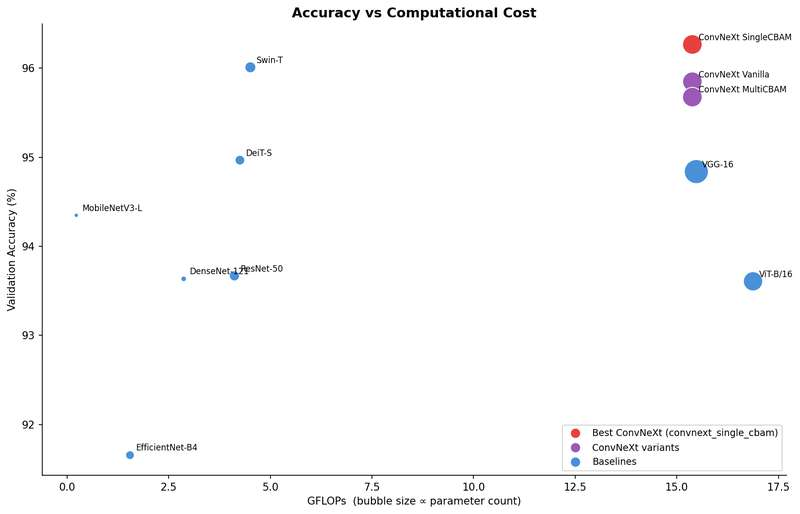

Saved: fig_complexity_scatter.png

  Cell 65 complete.


In [ ]:
# ── Cell 65: Model Complexity Table ───────────────────────────────────────────

try:
    from fvcore.nn import FlopCountAnalysis
except ImportError:
    import subprocess
    subprocess.run('pip install fvcore -q', shell=True)
    from fvcore.nn import FlopCountAnalysis

_complexity_models = {
    'VGG-16'               : VGG16Classifier,
    'ResNet-50'            : ResNet50Classifier,
    'DenseNet-121'         : DenseNet121Classifier,
    'EfficientNet-B4'      : EfficientNetB4Classifier,
    'MobileNetV3-L'        : MobileNetV3Classifier,
    'ViT-B/16'             : ViTB16Classifier,
    'Swin-T'               : SwinTClassifier,
    'DeiT-S'               : DeiTSClassifier,
    'ConvNeXt Vanilla'     : ConvNeXtVanilla,
    'ConvNeXt SingleCBAM'  : ConvNeXtSingleCBAM,
    'ConvNeXt MultiCBAM'   : ConvNeXtMultiCBAM,
}

_name_to_key = {
    'VGG-16'              : 'vgg16',
    'ResNet-50'           : 'resnet50',
    'DenseNet-121'        : 'densenet121',
    'EfficientNet-B4'     : 'efficientnet_b4',
    'MobileNetV3-L'       : 'mobilenetv3',
    'ViT-B/16'            : 'vit_b16',
    'Swin-T'              : 'swin_t',
    'DeiT-S'              : 'deit_s',
    'ConvNeXt Vanilla'    : 'convnext_vanilla',
    'ConvNeXt SingleCBAM' : 'convnext_single_cbam',
    'ConvNeXt MultiCBAM'  : 'convnext_multi_cbam',
}

_convnext_display = {
    'ConvNeXt Vanilla',
    'ConvNeXt SingleCBAM',
    'ConvNeXt MultiCBAM',
}

_dummy = torch.zeros(1, 3, 224, 224).to(device)
_rows  = []

print('=' * 75)
print('  MODEL COMPLEXITY TABLE')
print('=' * 75)
print(f'  {"Model":<24}  {"Params (M)":>10}  '
      f'{"GFLOPs":>8}  {"Inf (ms)":>10}  {"Val Acc (%)":>12}')
print('  ' + '-' * 68)

for name, cls in _complexity_models.items():
    _m = cls().to(device)
    _m.eval()

    _params = sum(p.numel() for p in _m.parameters()) / 1e6

    try:
        _flops  = FlopCountAnalysis(_m, _dummy)
        _flops.unsupported_ops_warnings(False)
        _gflops = _flops.total() / 1e9
    except Exception:
        _gflops = float('nan')

    _times = []
    with torch.no_grad():
        for _ in range(10):
            _ = _m(_dummy)
        for _ in range(50):
            _t = time.time()
            _  = _m(_dummy)
            torch.cuda.synchronize()
            _times.append((time.time() - _t) * 1000)
    _inf_ms = np.mean(_times)

    _arch_key = _name_to_key.get(name, '')
    _val_acc  = round(
        RESULTS_ARCH.get(_arch_key, {}).get('val_acc', float('nan')), 2
    )

    _rows.append({
        'Model'      : name,
        'Arch Key'   : _arch_key,
        'Params (M)' : round(_params,  2),
        'GFLOPs'     : round(_gflops,  2),
        'Inf (ms)'   : round(_inf_ms,  2),
        'Val Acc (%)': _val_acc,
    })

    print(f'  {name:<24}  {_params:>10.2f}  '
          f'{_gflops:>8.2f}  {_inf_ms:>10.2f}  {_val_acc:>12}')

    del _m
    torch.cuda.empty_cache()

print('=' * 75)

df_complexity = pd.DataFrame(_rows).drop(columns=['Arch Key'])
df_complexity.to_csv(
    CHECKPOINT_DIR / 'model_complexity_table.csv', index=False
)
print('Saved: model_complexity_table.csv')

# ── Scatter: Accuracy vs FLOPs ────────────────────────────────────────────────
_scatter_rows = [r for r in _rows
                 if not np.isnan(float(r['Val Acc (%)']))
                 and not np.isnan(r['GFLOPs'])]

fig, ax = plt.subplots(figsize=(11, 7))

for row in _scatter_rows:
    if row['Arch Key'] == BEST_MODEL_KEY:
        _c = '#E84040'
    elif row['Model'] in _convnext_display:
        _c = '#9B59B6'
    else:
        _c = '#4A90D9'
    ax.scatter(
        row['GFLOPs'], row['Val Acc (%)'],
        s=row['Params (M)'] * 4,
        color=_c, edgecolors='white',
        linewidths=0.8, zorder=3
    )
    ax.annotate(
        row['Model'],
        (row['GFLOPs'], row['Val Acc (%)']),
        textcoords='offset points',
        xytext=(6, 4), fontsize=8
    )

from matplotlib.lines import Line2D
_legend = [
    Line2D([0], [0], marker='o', color='w',
           markerfacecolor='#E84040', markersize=10,
           label=f'Best ConvNeXt ({BEST_MODEL_KEY})'),
    Line2D([0], [0], marker='o', color='w',
           markerfacecolor='#9B59B6', markersize=10,
           label='ConvNeXt variants'),
    Line2D([0], [0], marker='o', color='w',
           markerfacecolor='#4A90D9', markersize=10,
           label='Baselines'),
]
ax.legend(handles=_legend, fontsize=9)
ax.set_xlabel('GFLOPs  (bubble size ∝ parameter count)')
ax.set_ylabel('Validation Accuracy (%)')
ax.set_title('Accuracy vs Computational Cost',
             fontsize=13, fontweight='bold')
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.savefig(CHECKPOINT_DIR / 'fig_complexity_scatter.png',
            bbox_inches='tight', dpi=150)
plt.show()
print('Saved: fig_complexity_scatter.png')
print('\n  Cell 65 complete.')


  FAILURE CASE ANALYSIS
  Most confused pairs (true → predicted):
  ----------------------------------------
  EC     → HGSC   : 14 errors
  EC     → LGSC   : 12 errors
  EC     → MC     : 11 errors
  HGSC   → MC     : 10 errors
  HGSC   → EC     : 8 errors


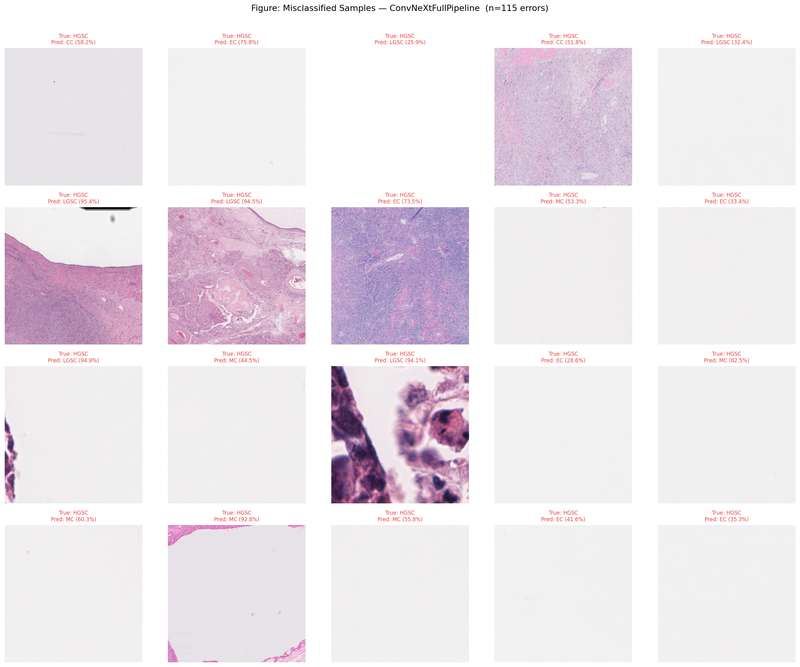

Saved: fig_failure_cases.png


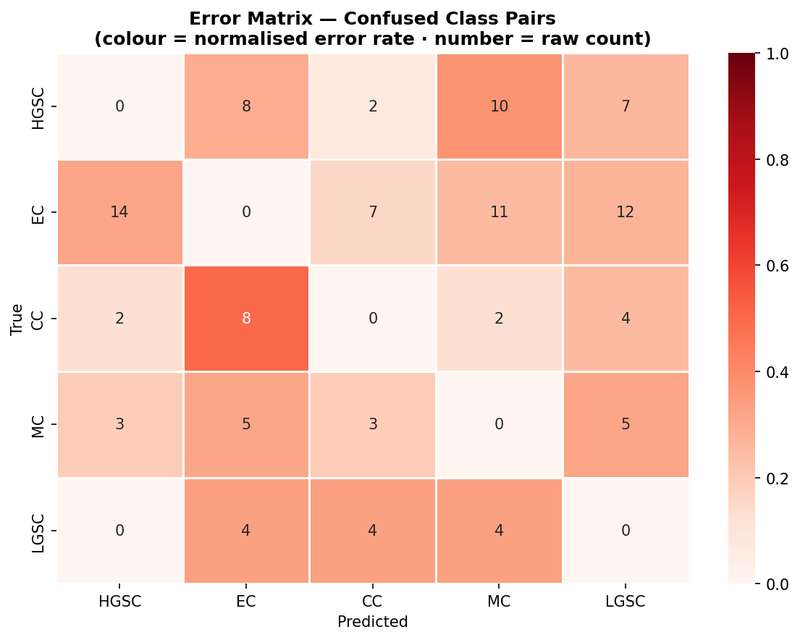

Saved: fig_error_matrix.png

  Cell 66 complete.


In [ ]:
# ── Cell 66: Failure Case Analysis ────────────────────────────────────────────
# Identifies the most confused class pairs from the best model.
# Shows a grid of misclassified images with true vs predicted labels.

BEST_MODEL.load_state_dict(
    torch.load(str(BEST_MODEL_CKPT), map_location=device)
)
BEST_MODEL.eval()

_fail_ds  = OvarianDataset(
    test_paths, test_labels,
    transform=WINNER_EVL_TF, pre_fn=WINNER_PRE_FN,
    input_size=WINNER_SIZE
)
_fail_ldr = make_loader(
    _fail_ds, batch_size=BASE_BATCH // 2, shuffle=False
)

_all_preds_f  = []
_all_labels_f = []
_all_probs_f  = []
_all_idxs     = []

_offset = 0
with torch.no_grad():
    for _imgs, _lbls in _fail_ldr:
        _imgs = _imgs.to(device)
        with torch.cuda.amp.autocast():
            _logits = BEST_MODEL(_imgs)
            _probs  = torch.softmax(_logits, dim=1)
            _preds  = _logits.argmax(1)
        _all_preds_f .extend(_preds.cpu().numpy())
        _all_labels_f.extend(_lbls.numpy())
        _all_probs_f .extend(_probs.cpu().numpy())
        _all_idxs    .extend(range(_offset,
                                    _offset + _lbls.size(0)))
        _offset += _lbls.size(0)

_all_preds_f  = np.array(_all_preds_f)
_all_labels_f = np.array(_all_labels_f)
_all_probs_f  = np.array(_all_probs_f)

# ── Confusion heatmap with error counts ──────────────────────────────────────
_cm = confusion_matrix(_all_labels_f, _all_preds_f)
_errors = _cm.copy()
np.fill_diagonal(_errors, 0)

print('\n' + '=' * 65)
print('  FAILURE CASE ANALYSIS')
print('=' * 65)
print('  Most confused pairs (true → predicted):')
print('  ' + '-' * 40)

_confused_pairs = []
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        if i != j and _errors[i, j] > 0:
            _confused_pairs.append((i, j, _errors[i, j]))

_confused_pairs.sort(key=lambda x: -x[2])
for true_c, pred_c, count in _confused_pairs[:5]:
    print(f'  {SUBTYPES[true_c]:<6} → {SUBTYPES[pred_c]:<6} : '
          f'{count} errors')
print('=' * 65)

# ── Misclassified image grid ───────────────────────────────────────────────────
_wrong_mask = _all_preds_f != _all_labels_f
_wrong_idxs = np.where(_wrong_mask)[0]

N_SHOW     = min(20, len(_wrong_idxs))
_cols      = 5
_rows_grid = N_SHOW // _cols

fig, axes = plt.subplots(_rows_grid, _cols,
                          figsize=(_cols * 3.5, _rows_grid * 3.5))
axes = axes.flatten()

for ax_idx, wrong_i in enumerate(_wrong_idxs[:N_SHOW]):
    img_path = test_paths[wrong_i]
    img = cv2.imread(str(img_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (224, 224), interpolation=cv2.INTER_AREA)

    true_lbl = SUBTYPES[_all_labels_f[wrong_i]]
    pred_lbl = SUBTYPES[_all_preds_f[wrong_i]]
    conf     = _all_probs_f[wrong_i][_all_preds_f[wrong_i]] * 100

    axes[ax_idx].imshow(img)
    axes[ax_idx].set_title(
        f'True: {true_lbl}\nPred: {pred_lbl} ({conf:.1f}%)',
        fontsize=8,
        color='#E84040'
    )
    axes[ax_idx].axis('off')

for ax in axes[N_SHOW:]:
    ax.axis('off')

plt.suptitle(
    f'Figure: Misclassified Samples — ConvNeXtFullPipeline  '
    f'(n={len(_wrong_idxs)} errors)',
    fontsize=13, y=1.01
)
plt.tight_layout()
plt.savefig(CHECKPOINT_DIR / 'fig_failure_cases.png',
            bbox_inches='tight', dpi=150)
plt.show()
print('Saved: fig_failure_cases.png')

# ── Per-pair confusion heatmap ────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 6))
_errors_norm = _errors.astype(float)
row_sums = _errors_norm.sum(axis=1, keepdims=True)
row_sums[row_sums == 0] = 1
_errors_norm = _errors_norm / row_sums

sns.heatmap(
    _errors_norm,
    annot=_errors,
    fmt='d',
    xticklabels=SUBTYPES,
    yticklabels=SUBTYPES,
    cmap='Reds',
    vmin=0, vmax=1,
    linewidths=0.5,
    ax=ax
)
ax.set_title('Error Matrix — Confused Class Pairs\n'
             '(colour = normalised error rate · number = raw count)',
             fontsize=12, fontweight='bold')
ax.set_xlabel('Predicted')
ax.set_ylabel('True')
plt.tight_layout()
plt.savefig(CHECKPOINT_DIR / 'fig_error_matrix.png',
            bbox_inches='tight', dpi=150)
plt.show()
print('Saved: fig_error_matrix.png')

del _fail_ds, _fail_ldr
torch.cuda.empty_cache()
print('\n  Cell 66 complete.')

  GRAD-CAM QUALITATIVE DISCUSSION

  [HGSC]
  High-Grade Serous Carcinoma — expected attention: papillary/solid nests, slit-like spaces, high nuclear pleomorphism. Confusion risk: LGSC (similar glandular pattern at low grade).

  [EC]
  Endometrioid Carcinoma — expected attention: back-to-back glands with squamous morules, villoglandular architecture. Confusion risk: HGSC at high grade.

  [CC]
  Clear Cell Carcinoma — expected attention: hobnail cells lining tubulo-cystic structures, clear cytoplasm. Confusion risk: EC.

  [MC]
  Mucinous Carcinoma — expected attention: mucin-filled glands, goblet cells, intestinal-type epithelium. Confusion risk: metastatic GI tumours.

  [LGSC]
  Low-Grade Serous Carcinoma — expected attention: micropapillary architecture, psammoma bodies, uniform nuclei. Confusion risk: HGSC.


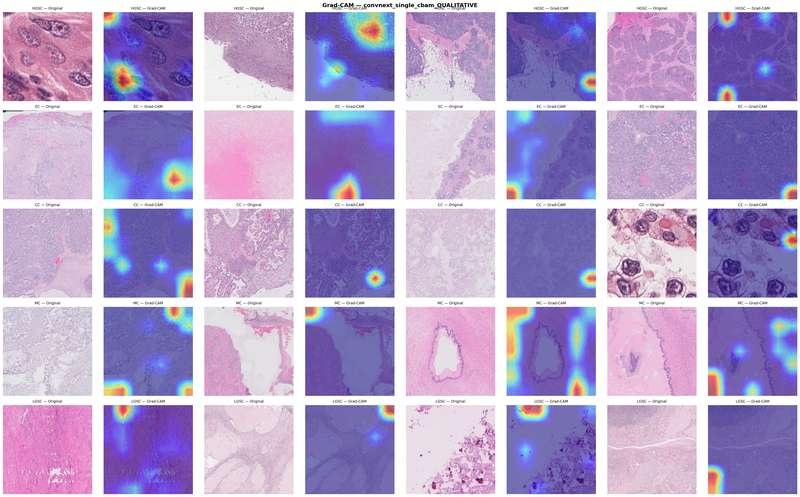

Saved: gradcam_convnext_single_cbam_QUALITATIVE.png

  Grad-CAM on most confused pairs:

  Pair: EC → HGSC  (14 errors)


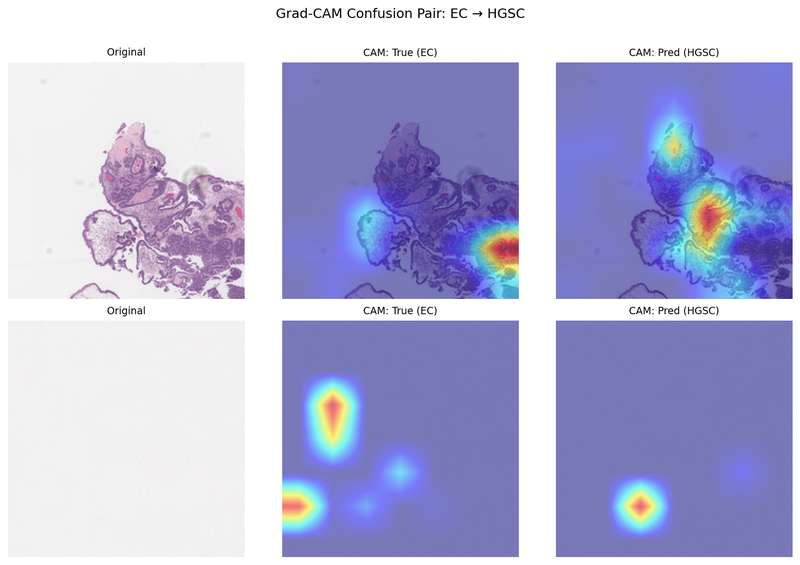

  Saved: fig_gradcam_pair_EC_HGSC.png

  Pair: EC → LGSC  (12 errors)


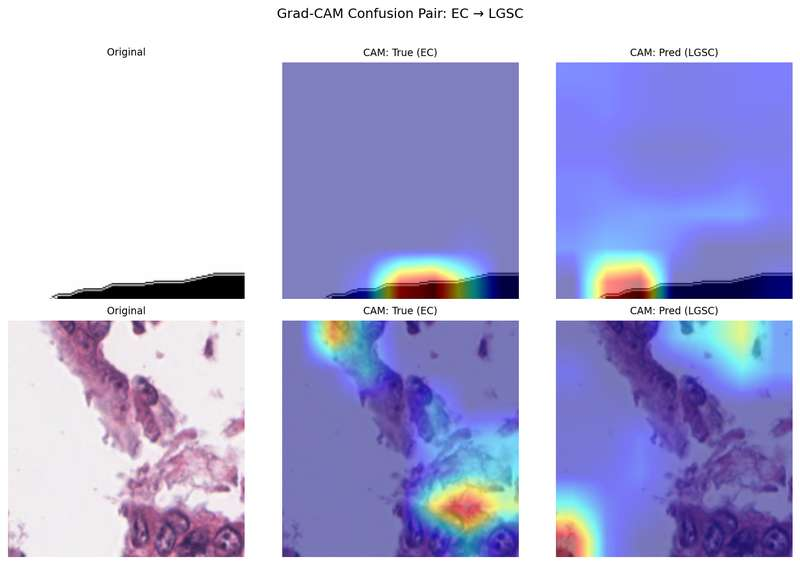

  Saved: fig_gradcam_pair_EC_LGSC.png

  Pair: EC → MC  (11 errors)


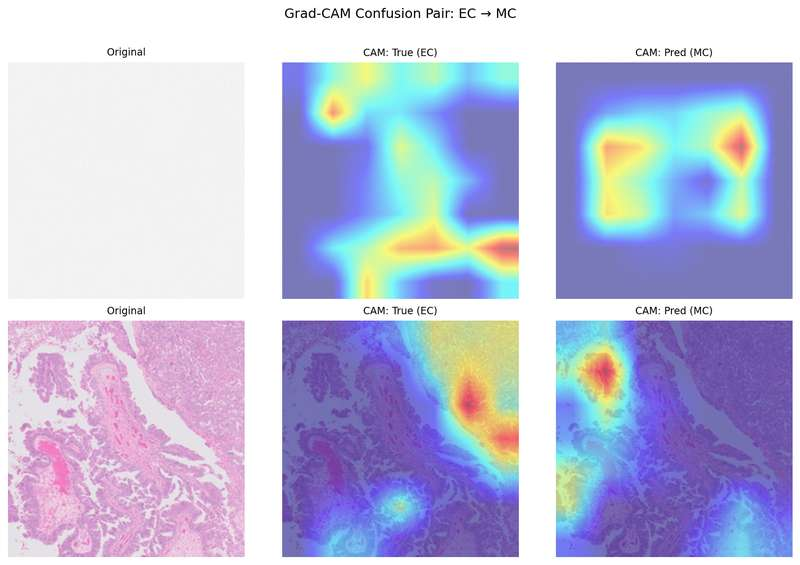

  Saved: fig_gradcam_pair_EC_MC.png

  Cell 67 complete.


In [ ]:
# ── Cell 67: Grad-CAM Qualitative Discussion ──────────────────────────────────

BEST_MODEL.load_state_dict(
    torch.load(str(BEST_MODEL_CKPT), map_location=device)
)
BEST_MODEL.eval()

_PATHOLOGY_NOTES = {
    'HGSC': (
        'High-Grade Serous Carcinoma — expected attention: '
        'papillary/solid nests, slit-like spaces, high nuclear pleomorphism. '
        'Confusion risk: LGSC (similar glandular pattern at low grade).'
    ),
    'EC': (
        'Endometrioid Carcinoma — expected attention: '
        'back-to-back glands with squamous morules, '
        'villoglandular architecture. '
        'Confusion risk: HGSC at high grade.'
    ),
    'CC': (
        'Clear Cell Carcinoma — expected attention: '
        'hobnail cells lining tubulo-cystic structures, '
        'clear cytoplasm. Confusion risk: EC.'
    ),
    'MC': (
        'Mucinous Carcinoma — expected attention: '
        'mucin-filled glands, goblet cells, '
        'intestinal-type epithelium. '
        'Confusion risk: metastatic GI tumours.'
    ),
    'LGSC': (
        'Low-Grade Serous Carcinoma — expected attention: '
        'micropapillary architecture, psammoma bodies, '
        'uniform nuclei. Confusion risk: HGSC.'
    ),
}

print('=' * 75)
print('  GRAD-CAM QUALITATIVE DISCUSSION')
print('=' * 75)
for sub, note in _PATHOLOGY_NOTES.items():
    print(f'\n  [{sub}]')
    print(f'  {note}')
print('=' * 75)

# ── Extended Grad-CAM — 4 samples per subtype ─────────────────────────────────
show_gradcam(
    model        = BEST_MODEL,
    test_root    = TEST_PATH,
    label        = f'{BEST_MODEL_KEY}_QUALITATIVE',
    target_layer = GRADCAM_TARGET_LAYER,
    n_per_class  = 4,
)

# ── Grad-CAM on top confused pairs ────────────────────────────────────────────
print('\n  Grad-CAM on most confused pairs:')
_top_pairs = _confused_pairs[:3]

_, _evl_tf  = make_transforms(WINNER_SIZE)
_gc         = GradCAM(BEST_MODEL, GRADCAM_TARGET_LAYER)

for true_c, pred_c, count in _top_pairs:
    true_sub = SUBTYPES[true_c]
    pred_sub = SUBTYPES[pred_c]
    print(f'\n  Pair: {true_sub} → {pred_sub}  ({count} errors)')

    _pair_idxs = [
        i for i in range(len(_all_preds_f))
        if _all_labels_f[i] == true_c
        and _all_preds_f[i] == pred_c
    ][:2]

    if not _pair_idxs:
        print('  No samples found for this pair — skipped.')
        continue

    fig, axes = plt.subplots(
        len(_pair_idxs), 3,
        figsize=(10.5, len(_pair_idxs) * 3.5)
    )
    if len(_pair_idxs) == 1:
        axes = [axes]

    for row_i, idx in enumerate(_pair_idxs):
        img_path = test_paths[idx]
        raw      = cv2.imread(str(img_path))
        raw      = cv2.cvtColor(raw, cv2.COLOR_BGR2RGB)
        raw_224  = cv2.resize(
            raw, (WINNER_SIZE, WINNER_SIZE),
            interpolation=cv2.INTER_AREA
        )

        tensor = _evl_tf(raw_224).unsqueeze(0).to(device)
        tensor.requires_grad_(True)

        with torch.enable_grad():
            cam_true = _gc.generate(tensor, true_c)
            cam_pred = _gc.generate(tensor, pred_c)

        for cam, title, col_idx in [
            (None,     'Original',               0),
            (cam_true, f'CAM: True ({true_sub})', 1),
            (cam_pred, f'CAM: Pred ({pred_sub})', 2),
        ]:
            ax = axes[row_i][col_idx]
            if cam is None:
                ax.imshow(raw_224)
            else:
                cam_r   = cv2.resize(cam, (WINNER_SIZE, WINNER_SIZE))
                heatmap = cv2.applyColorMap(
                    (cam_r * 255).astype(np.uint8), cv2.COLORMAP_JET
                )
                heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
                overlay = (0.5 * raw_224 +
                           0.5 * heatmap).astype(np.uint8)
                ax.imshow(overlay)
            ax.set_title(title, fontsize=9)
            ax.axis('off')

    plt.suptitle(
        f'Grad-CAM Confusion Pair: {true_sub} → {pred_sub}',
        fontsize=12, y=1.01
    )
    plt.tight_layout()
    fname = CHECKPOINT_DIR / \
        f'fig_gradcam_pair_{true_sub}_{pred_sub}.png'
    plt.savefig(fname, bbox_inches='tight', dpi=150)
    plt.show()
    print(f'  Saved: {fname.name}')

_gc.remove()
torch.cuda.empty_cache()
print('\n  Cell 67 complete.')

  LEARNING RATE FINDER — convnext_single_cbam
  Range  : 1e-7 → 1e-1
  Steps  : 100 mini-batches
  Purpose: Validate backbone_lr=2e-5 / head_lr=2e-4 choices


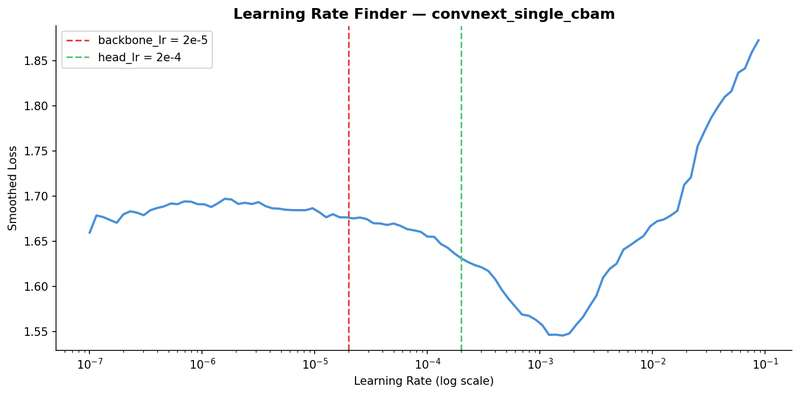

Saved: fig_lr_finder.png

  Cell 68 complete.


In [ ]:
# ── Cell 68: Learning Rate Finder ─────────────────────────────────────────────

print('=' * 65)
print(f'  LEARNING RATE FINDER — {BEST_MODEL_KEY}')
print('=' * 65)
print('  Range  : 1e-7 → 1e-1')
print('  Steps  : 100 mini-batches')
print('  Purpose: Validate backbone_lr=2e-5 / head_lr=2e-4 choices')
print('=' * 65)

_lr_model = BEST_MODEL_CLS().to(device)
_lr_model.train()

_lr_train_ds = OvarianDataset(
    train_paths, train_labels,
    transform  = make_transforms(WINNER_SIZE)[0],
    pre_fn     = WINNER_PRE_FN,
    input_size = WINNER_SIZE,
)
_lr_ldr       = make_loader(_lr_train_ds, batch_size=BASE_BATCH)
_lr_criterion = WINNER_CRITERION

_LR_START  = 1e-7
_LR_END    = 1e-1
_LR_STEPS  = 100
_lr_mult   = (_LR_END / _LR_START) ** (1 / _LR_STEPS)

_lr_optimizer = optim.AdamW(
    _lr_model.parameters(), lr=_LR_START, weight_decay=1e-4
)

_lrs, _losses = [], []
_smooth_loss  = 0.0
_best_loss    = float('inf')
_scaler_lr    = torch.cuda.amp.GradScaler()
_lr_iter      = iter(_lr_ldr)

for _step in range(_LR_STEPS):
    try:
        _imgs, _lbls = next(_lr_iter)
    except StopIteration:
        _lr_iter     = iter(_lr_ldr)
        _imgs, _lbls = next(_lr_iter)

    _imgs, _lbls = _imgs.to(device), _lbls.to(device)
    _lr_optimizer.zero_grad(set_to_none=True)

    with torch.cuda.amp.autocast():
        _out  = _lr_model(_imgs)
        _loss = _lr_criterion(_out, _lbls)

    _scaler_lr.scale(_loss).backward()
    _scaler_lr.step(_lr_optimizer)
    _scaler_lr.update()

    _smooth_loss = 0.05 * _loss.item() + 0.95 * _smooth_loss
    _corrected   = _smooth_loss / (1 - 0.95 ** (_step + 1))
    _current_lr  = _LR_START * (_lr_mult ** _step)
    _lrs.append(_current_lr)
    _losses.append(_corrected)

    if _corrected < _best_loss:
        _best_loss = _corrected
    if _corrected > 4 * _best_loss:
        print(f'  Loss diverged at step {_step}. Stopping.')
        break

    for pg in _lr_optimizer.param_groups:
        pg['lr'] = _LR_START * (_lr_mult ** (_step + 1))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(_lrs, _losses, color='#4A90D9', linewidth=2.0)
ax.set_xscale('log')
ax.set_xlabel('Learning Rate (log scale)')
ax.set_ylabel('Smoothed Loss')
ax.set_title(f'Learning Rate Finder — {BEST_MODEL_KEY}',
             fontsize=13, fontweight='bold')

for _lr_val, _label, _color in [
    (2e-5, 'backbone_lr = 2e-5', '#E84040'),
    (2e-4, 'head_lr = 2e-4',     '#50C878'),
]:
    ax.axvline(_lr_val, color=_color, linestyle='--',
               linewidth=1.5, label=_label)

ax.legend(fontsize=10)
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.savefig(CHECKPOINT_DIR / 'fig_lr_finder.png',
            bbox_inches='tight', dpi=150)
plt.show()
print('Saved: fig_lr_finder.png')

del _lr_model, _lr_train_ds, _lr_ldr
torch.cuda.empty_cache()
print('\n  Cell 68 complete.')

  CALIBRATION CURVE — convnext_single_cbam


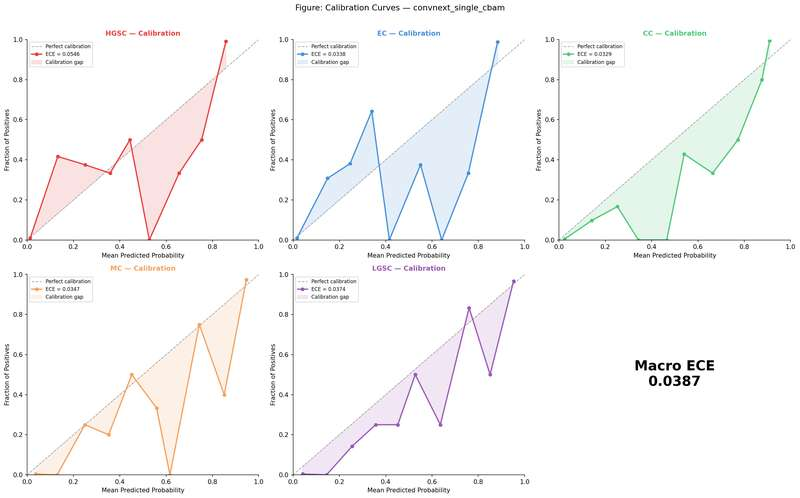

Saved: fig_calibration.png

  ECE SCORES
  HGSC   : 0.0546  [Acceptable]
  EC     : 0.0338  [Well calibrated]
  CC     : 0.0329  [Well calibrated]
  MC     : 0.0347  [Well calibrated]
  LGSC   : 0.0374  [Well calibrated]
  Macro  : 0.0387

  Cell 69 complete.


In [ ]:
# ── Cell 69: Calibration Curve ────────────────────────────────────────────────

from sklearn.calibration import calibration_curve

print('=' * 65)
print(f'  CALIBRATION CURVE — {BEST_MODEL_KEY}')
print('=' * 65)

_probs_final  = np.array(RESULTS_ARCH[BEST_MODEL_KEY]['probs'])
_labels_final = np.array(RESULTS_ARCH[BEST_MODEL_KEY]['labels'])
_labels_bin   = label_binarize(
    _labels_final, classes=list(range(NUM_CLASSES))
)

N_BINS = 10
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()
_ece_scores = {}

for i, sub in enumerate(SUBTYPES):
    _prob_pos = _probs_final[:, i]
    _true_bin = _labels_bin[:, i]

    _frac_pos, _mean_pred = calibration_curve(
        _true_bin, _prob_pos, n_bins=N_BINS
    )

    _bin_edges  = np.linspace(0, 1, N_BINS + 1)
    _ece        = 0.0
    for _lo, _hi in zip(_bin_edges[:-1], _bin_edges[1:]):
        _mask = (_prob_pos >= _lo) & (_prob_pos < _hi)
        if _mask.sum() == 0:
            continue
        _ece += (np.abs(_true_bin[_mask].mean() -
                        _prob_pos[_mask].mean()) *
                 _mask.sum() / len(_prob_pos))
    _ece_scores[sub] = _ece

    ax = axes[i]
    ax.plot([0, 1], [0, 1], color='#AAAAAA', linestyle='--',
            linewidth=1.2, label='Perfect calibration')
    ax.plot(_mean_pred, _frac_pos, color=PALETTE[sub],
            linewidth=2.0, marker='o', markersize=5,
            label=f'ECE = {_ece:.4f}')
    ax.fill_between(_mean_pred, _mean_pred, _frac_pos,
                    alpha=0.15, color=PALETTE[sub],
                    label='Calibration gap')
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xlabel('Mean Predicted Probability')
    ax.set_ylabel('Fraction of Positives')
    ax.set_title(f'{sub} — Calibration',
                 fontsize=11, fontweight='bold', color=PALETTE[sub])
    ax.legend(fontsize=8)
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)

_macro_ece = np.mean(list(_ece_scores.values()))
axes[-1].axis('off')
axes[-1].text(
    0.5, 0.5,
    f'Macro ECE\n{_macro_ece:.4f}',
    ha='center', va='center',
    fontsize=22, fontweight='bold',
    transform=axes[-1].transAxes
)

plt.suptitle(
    f'Figure: Calibration Curves — {BEST_MODEL_KEY}',
    fontsize=13, y=1.01
)
plt.tight_layout()
plt.savefig(CHECKPOINT_DIR / 'fig_calibration.png',
            bbox_inches='tight', dpi=150)
plt.show()
print('Saved: fig_calibration.png')

print('\n' + '=' * 65)
print('  ECE SCORES')
print('=' * 65)
for sub, ece in _ece_scores.items():
    quality = ('Well calibrated' if ece < 0.05 else
               'Acceptable'      if ece < 0.10 else
               'Overconfident — consider temperature scaling')
    print(f'  {sub:<6} : {ece:.4f}  [{quality}]')
print(f'  {"Macro":<6} : {_macro_ece:.4f}')
print('=' * 65)
print('\n  Cell 69 complete.')

  ENSEMBLE — TOP-3 MODELS  (soft voting)
  Top-3 models selected:
    convnext_single_cbam           Macro F1 = 0.9541  Ckpt: ✅
    convnext_multi_cbam            Macro F1 = 0.9472  Ckpt: ✅
    deit_s                         Macro F1 = 0.9416  Ckpt: ✅

  ENSEMBLE RESULTS
  Best single model (convnext_single_cbam) | Acc: 96.27%  F1: 0.9541
  Ensemble (top-3)              | Acc: 96.53%  F1: 0.9565
  Delta                         | Acc: +0.26%  F1: +0.0024
-----------------------------------------------------------------
  HGSC   F1 : 0.9806
  EC     F1 : 0.9615
  CC     F1 : 0.9718
  MC     F1 : 0.9412
  LGSC   F1 : 0.9272

              precision    recall  f1-score   support

        HGSC     0.9823    0.9790    0.9806      1188
          EC     0.9682    0.9550    0.9615       733
          CC     0.9745    0.9691    0.9718       551
          MC     0.9412    0.9412    0.9412       323
        LGSC     0.9013    0.9547    0.9272       287

    accuracy                         0.9653 

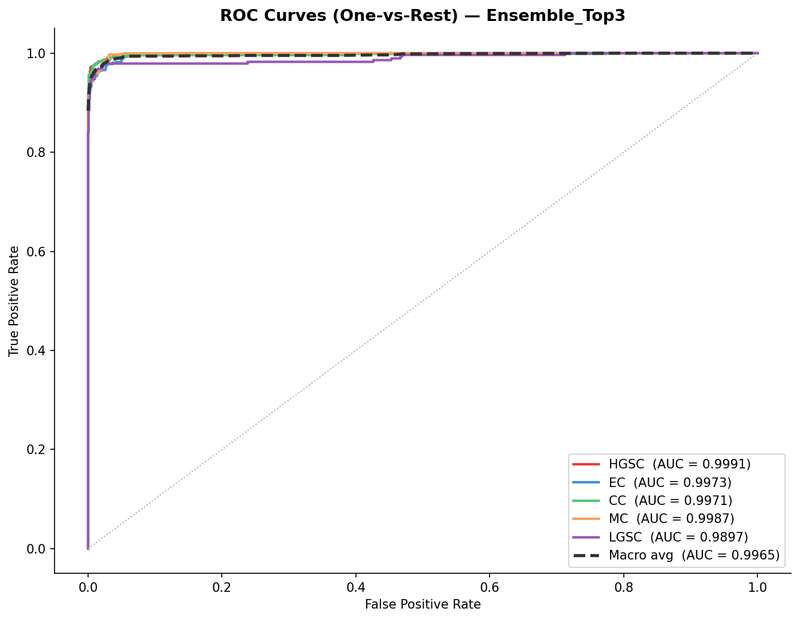

Saved: roc_Ensemble_Top3.png

  ROC-AUC SCORES — Ensemble_Top3
  HGSC   : 0.9991
  EC     : 0.9973
  CC     : 0.9971
  MC     : 0.9987
  LGSC   : 0.9897
  Macro  : 0.9965

  Cell 70 complete.


In [ ]:
# ── Cell 70: Ensemble — Top-3 Models ──────────────────────────────────────────

print('=' * 65)
print('  ENSEMBLE — TOP-3 MODELS  (soft voting)')
print('=' * 65)

_sorted_arch = sorted(
    RESULTS_ARCH.items(),
    key=lambda x: x[1].get('macro_f1', 0.0),
    reverse=True
)

# ── Filter to only models whose checkpoint exists on Drive ────────────────────
_available = [
    (k, v) for k, v in _sorted_arch
    if Path(str(v['ckpt'])).exists()
]

if len(_available) < 3:
    print(f'  WARNING: Only {len(_available)} checkpoints found on Drive.')
    print('  Ensemble requires at least 3. Available:')
    for k, v in _available:
        print(f'    {k}')
    print('\n  Skipping ensemble — not enough checkpoints.')
else:
    _top3_keys = [k for k, _ in _available[:3]]
    _top3_cls  = {
        'vgg16'                  : VGG16Classifier,
        'resnet50'               : ResNet50Classifier,
        'densenet121'            : DenseNet121Classifier,
        'efficientnet_b4'        : EfficientNetB4Classifier,
        'mobilenetv3'            : MobileNetV3Classifier,
        'vit_b16'                : ViTB16Classifier,
        'swin_t'                 : SwinTClassifier,
        'deit_s'                 : DeiTSClassifier,
        'convnext_vanilla'       : ConvNeXtVanilla,
        'convnext_single_cbam'   : ConvNeXtSingleCBAM,
        'convnext_multi_cbam'    : ConvNeXtMultiCBAM,
    }

    print(f'  Top-3 models selected:')
    for k in _top3_keys:
        print(f'    {k:<30} '
              f'Macro F1 = {RESULTS_ARCH[k]["macro_f1"]:.4f}  '
              f'Ckpt: ✅')
    print('=' * 65)

    _ens_models = []
    for key in _top3_keys:
        _m = _top3_cls[key]().to(device)
        _m.load_state_dict(
            torch.load(str(RESULTS_ARCH[key]['ckpt']),
                       map_location=device)
        )
        _m.eval()
        _ens_models.append(_m)

    _ens_ds  = OvarianDataset(
        test_paths, test_labels,
        transform=WINNER_EVL_TF, pre_fn=WINNER_PRE_FN,
        input_size=WINNER_SIZE
    )
    _ens_ldr = make_loader(
        _ens_ds, batch_size=BASE_BATCH // 2, shuffle=False
    )

    _ens_preds  = []
    _ens_labels = []
    _ens_probs  = []

    with torch.no_grad():
        for _imgs, _lbls in _ens_ldr:
            _imgs  = _imgs.to(device)
            _sum_p = torch.zeros(
                _lbls.size(0), NUM_CLASSES, device=device
            )
            for _m in _ens_models:
                with torch.cuda.amp.autocast():
                    _sum_p += torch.softmax(_m(_imgs), dim=1)
            _mean_p = _sum_p / len(_ens_models)
            _preds  = _mean_p.argmax(1)
            _ens_preds .extend(_preds.cpu().numpy())
            _ens_labels.extend(_lbls.numpy())
            _ens_probs .extend(_mean_p.cpu().numpy())

    _ens_acc = accuracy_score(_ens_labels, _ens_preds) * 100
    _ens_f1  = f1_score(_ens_labels, _ens_preds,
                         average='macro', zero_division=0)
    _ens_per = f1_score(_ens_labels, _ens_preds,
                         average=None,   zero_division=0)

    print('\n' + '=' * 65)
    print('  ENSEMBLE RESULTS')
    print('=' * 65)
    print(f'  Best single model ({BEST_MODEL_KEY}) | '
          f'Acc: {RESULTS_ARCH[BEST_MODEL_KEY]["val_acc"]:.2f}%  '
          f'F1: {RESULTS_ARCH[BEST_MODEL_KEY]["macro_f1"]:.4f}')
    print(f'  Ensemble (top-3)              | '
          f'Acc: {_ens_acc:.2f}%  F1: {_ens_f1:.4f}')
    print(f'  Delta                         | '
          f'Acc: {_ens_acc - RESULTS_ARCH[BEST_MODEL_KEY]["val_acc"]:+.2f}%  '
          f'F1: {_ens_f1 - RESULTS_ARCH[BEST_MODEL_KEY]["macro_f1"]:+.4f}')
    print('-' * 65)
    for sub, f in zip(SUBTYPES, _ens_per):
        print(f'  {sub:<6} F1 : {f:.4f}')
    print('=' * 65)

    print('\n' + classification_report(
        _ens_labels, _ens_preds,
        target_names=SUBTYPES, digits=4, zero_division=0
    ))

    plot_roc_auc(
        np.array(_ens_probs), _ens_labels,
        'Ensemble_Top3'
    )

    for _m in _ens_models:
        del _m
    del _ens_ds, _ens_ldr
    torch.cuda.empty_cache()

print('\n  Cell 70 complete.')

  t-SNE FEATURE SPACE VISUALISATION
  Available checkpoints : ['convnext_single_cbam', 'convnext_multi_cbam']
  Comparing : convnext_multi_cbam  vs  convnext_single_cbam
  Layer     : penultimate (post-pool, pre-classifier)
  Perplexity: 30  |  Iterations : 1000

  Extracting embeddings — convnext_multi_cbam...
  Extracting embeddings — convnext_single_cbam...

  Running t-SNE...


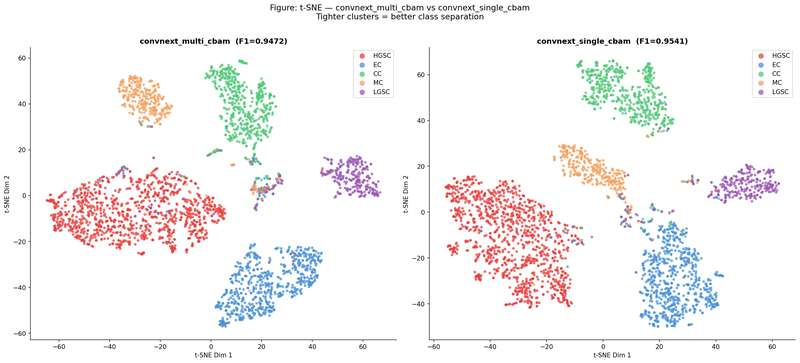

Saved: fig_tsne.png

  Cell 71 complete.


In [ ]:
# ── Cell 71: t-SNE Feature Space Visualisation ────────────────────────────────

from sklearn.manifold import TSNE

# ── Check which ConvNeXt checkpoints exist on Drive ───────────────────────────
_convnext_available = {
    k: RESULTS_ARCH[k]['ckpt']
    for k in ['convnext_vanilla', 'convnext_single_cbam', 'convnext_multi_cbam']
    if k in RESULTS_ARCH and Path(str(RESULTS_ARCH[k]['ckpt'])).exists()
}

print('=' * 65)
print('  t-SNE FEATURE SPACE VISUALISATION')
print('=' * 65)
print(f'  Available checkpoints : {list(_convnext_available.keys())}')

if len(_convnext_available) < 2:
    print('  Need at least 2 ConvNeXt checkpoints for comparison.')
    print('  Only 1 found — skipping t-SNE.')
    print('\n  Cell 71 skipped.')
else:
    # Compare vanilla vs best if both exist
    # Otherwise compare any two available
    _keys_sorted = sorted(
        _convnext_available.keys(),
        key=lambda k: RESULTS_ARCH[k]['macro_f1']
    )
    _compare_key_a = _keys_sorted[0]   # worst = baseline
    _compare_key_b = BEST_MODEL_KEY    # best

    # Fallback if best not in available
    if _compare_key_b not in _convnext_available:
        _compare_key_b = _keys_sorted[-1]

    _cls_map = {
        'convnext_vanilla'     : ConvNeXtVanilla,
        'convnext_single_cbam' : ConvNeXtSingleCBAM,
        'convnext_multi_cbam'  : ConvNeXtMultiCBAM,
    }

    print(f'  Comparing : {_compare_key_a}  vs  {_compare_key_b}')
    print(f'  Layer     : penultimate (post-pool, pre-classifier)')
    print(f'  Perplexity: 30  |  Iterations : 1000')
    print('=' * 65)

    def extract_embeddings(model, ckpt_path, loader):
        model.load_state_dict(
            torch.load(str(ckpt_path), map_location=device)
        )
        model.eval()
        _embeddings = []
        _labels     = []
        _feats      = []

        def _hook(module, inp, out):
            _feats.append(out.detach().cpu())

        _handle = model.head[-2].register_forward_hook(_hook)

        with torch.no_grad():
            for _imgs, _lbls in loader:
                _imgs = _imgs.to(device)
                with torch.cuda.amp.autocast():
                    _ = model(_imgs)
                _embeddings.append(_feats[-1])
                _labels.extend(_lbls.numpy())
                _feats.clear()

        _handle.remove()
        return torch.cat(_embeddings, dim=0).numpy(), np.array(_labels)

    _tsne_ds  = OvarianDataset(
        test_paths, test_labels,
        transform=WINNER_EVL_TF, pre_fn=WINNER_PRE_FN,
        input_size=WINNER_SIZE
    )
    _tsne_ldr = make_loader(
        _tsne_ds, batch_size=BASE_BATCH // 2, shuffle=False
    )

    print(f'\n  Extracting embeddings — {_compare_key_a}...')
    _model_a = _cls_map[_compare_key_a]().to(device)
    _emb_a, _lbl_a = extract_embeddings(
        _model_a,
        _convnext_available[_compare_key_a],
        _tsne_ldr
    )
    del _model_a
    torch.cuda.empty_cache()

    print(f'  Extracting embeddings — {_compare_key_b}...')
    _model_b = _cls_map[_compare_key_b]().to(device)
    _emb_b, _lbl_b = extract_embeddings(
        _model_b,
        _convnext_available[_compare_key_b],
        _tsne_ldr
    )
    del _model_b
    torch.cuda.empty_cache()

    print('\n  Running t-SNE...')
    _tsne    = TSNE(n_components=2, perplexity=30,
                    n_iter=1000, random_state=SEED, n_jobs=-1)
    _tsne_a  = _tsne.fit_transform(_emb_a)
    _tsne_b  = _tsne.fit_transform(_emb_b)

    fig, axes = plt.subplots(1, 2, figsize=(18, 8))

    _title_a = f'{_compare_key_a}  '  \
               f'(F1={RESULTS_ARCH[_compare_key_a]["macro_f1"]:.4f})'
    _title_b = f'{_compare_key_b}  '  \
               f'(F1={RESULTS_ARCH[_compare_key_b]["macro_f1"]:.4f})'

    for ax, tsne_coords, labels, title in zip(
        axes,
        [_tsne_a,   _tsne_b],
        [_lbl_a,    _lbl_b],
        [_title_a,  _title_b]
    ):
        for cls_idx, sub in enumerate(SUBTYPES):
            _mask = labels == cls_idx
            ax.scatter(
                tsne_coords[_mask, 0],
                tsne_coords[_mask, 1],
                c=PALETTE[sub], label=sub,
                s=18, alpha=0.75, edgecolors='none'
            )
        ax.set_title(title, fontsize=12, fontweight='bold')
        ax.legend(fontsize=10, markerscale=2)
        ax.set_xlabel('t-SNE Dim 1')
        ax.set_ylabel('t-SNE Dim 2')
        for spine in ['top', 'right']:
            ax.spines[spine].set_visible(False)

    plt.suptitle(
        f'Figure: t-SNE — {_compare_key_a} vs {_compare_key_b}\n'
        'Tighter clusters = better class separation',
        fontsize=13, y=1.01
    )
    plt.tight_layout()
    plt.savefig(CHECKPOINT_DIR / 'fig_tsne.png',
                bbox_inches='tight', dpi=150)
    plt.show()
    print('Saved: fig_tsne.png')

    del _tsne_ds, _tsne_ldr
    torch.cuda.empty_cache()
    print('\n  Cell 71 complete.')

## Section 8 - Final Evaluation

In [ ]:
# ── Count blank patches in test set ───────────────────────────────────────────
_blank_test  = [p for p in test_paths if not _has_tissue(p, 0.55)]
_tissue_test = [p for p in test_paths if _has_tissue(p, 0.55)]

print('=' * 55)
print('  TEST SET QUALITY ANALYSIS')
print('=' * 55)
print(f'  Total test images  : {len(test_paths)}')
print(f'  Tissue-rich        : {len(_tissue_test)}')
print(f'  Blank / low tissue : {len(_blank_test)}')
print(f'  Blank ratio        : '
      f'{len(_blank_test)/len(test_paths)*100:.1f}%')
print('=' * 55)

# Per class breakdown
print(f'\n  {"Subtype":<8}  {"Total":>7}  {"Blank":>7}  {"Blank%":>8}')
print('  ' + '-' * 38)
for idx, sub in enumerate(SUBTYPES):
    _sub_paths = [p for p, l in zip(test_paths, test_labels)
                  if l == idx]
    _sub_blank = [p for p in _sub_paths
                  if not _has_tissue(p, 0.55)]
    _pct = len(_sub_blank) / len(_sub_paths) * 100
    print(f'  {sub:<8}  {len(_sub_paths):>7}  '
          f'{len(_sub_blank):>7}  {_pct:>7.1f}%')
print('=' * 55)

  TEST SET QUALITY ANALYSIS
  Total test images  : 3082
  Tissue-rich        : 2538
  Blank / low tissue : 544
  Blank ratio        : 17.7%

  Subtype     Total    Blank    Blank%
  --------------------------------------
  HGSC         1188      152     12.8%
  EC            733      139     19.0%
  CC            551       67     12.2%
  MC            323      114     35.3%
  LGSC          287       72     25.1%


In [ ]:
# ── Clean train and test sets ─────────────────────────────────────────────────

print('Filtering blank patches from train and test sets...')

_clean_train = [
    (p, l) for p, l in zip(train_paths, train_labels)
    if _has_tissue(p, 0.55)
]
_clean_test  = [
    (p, l) for p, l in zip(test_paths, test_labels)
    if _has_tissue(p, 0.55)
]

train_paths_clean  = [x[0] for x in _clean_train]
train_labels_clean = [x[1] for x in _clean_train]
test_paths_clean   = [x[0] for x in _clean_test]
test_labels_clean  = [x[1] for x in _clean_test]

TRAIN_COUNTS_CLEAN = [
    sum(1 for l in train_labels_clean if l == i)
    for i in range(NUM_CLASSES)
]

print('\n' + '=' * 65)
print('  DATASET AFTER BLANK PATCH REMOVAL')
print('=' * 65)
print(f'  {"Subtype":<8}  '
      f'{"Train (old)":>12}  {"Train (new)":>12}  '
      f'{"Test (old)":>11}  {"Test (new)":>11}')
print('  ' + '-' * 60)
for i, sub in enumerate(SUBTYPES):
    _old_tr = TRAIN_COUNTS[i]
    _new_tr = TRAIN_COUNTS_CLEAN[i]
    _old_te = sum(1 for l in test_labels  if l == i)
    _new_te = sum(1 for l in test_labels_clean if l == i)
    print(f'  {sub:<8}  '
          f'{_old_tr:>12}  {_new_tr:>12}  '
          f'{_old_te:>11}  {_new_te:>11}')
print('  ' + '-' * 60)
print(f'  {"TOTAL":<8}  '
      f'{len(train_paths):>12}  {len(train_paths_clean):>12}  '
      f'{len(test_paths):>11}  {len(test_paths_clean):>11}')
print('=' * 65)

# ── Imbalance check ───────────────────────────────────────────────────────────
print(f'\n  {"Subtype":<8}  {"Old":>7}  {"New":>7}  {"Lost":>6}  {"Lost%":>7}')
print('  ' + '-' * 42)
for sub, old, new in zip(SUBTYPES, TRAIN_COUNTS, TRAIN_COUNTS_CLEAN):
    diff = old - new
    pct  = diff / old * 100
    print(f'  {sub:<8}  {old:>7}  {new:>7}  {diff:>6}  {pct:>6.1f}%')
print('  ' + '-' * 42)
_new_ratio = max(TRAIN_COUNTS_CLEAN) / min(TRAIN_COUNTS_CLEAN)
_old_ratio = max(TRAIN_COUNTS)       / min(TRAIN_COUNTS)
print(f'  Imbalance ratio before : {_old_ratio:.2f}x')
print(f'  Imbalance ratio after  : {_new_ratio:.2f}x')
print('=' * 65)
print('Cleaning complete — test_paths_clean and train_paths_clean ready.')

Filtering blank patches from train and test sets...

  DATASET AFTER BLANK PATCH REMOVAL
  Subtype    Train (old)   Train (new)   Test (old)   Test (new)
  ------------------------------------------------------------
  HGSC             12019         10513         1188         1036
  EC                7421          6166          733          594
  CC                5579          4835          551          484
  MC                3276          2224          323          209
  LGSC              2908          2097          287          215
  ------------------------------------------------------------
  TOTAL            31203         25835         3082         2538

  Subtype       Old      New    Lost    Lost%
  ------------------------------------------
  HGSC        12019    10513    1506    12.5%
  EC           7421     6166    1255    16.9%
  CC           5579     4835     744    13.3%
  MC           3276     2224    1052    32.1%
  LGSC         2908     2097     811    27.9%
  ------

Evaluating on clean test set...

  convnext_single_cbam_clean_test
              precision    recall  f1-score   support

        HGSC     0.9942    0.9952    0.9947      1036
          EC     0.9983    0.9815    0.9898       594
          CC     0.9938    1.0000    0.9969       484
          MC     0.9811    0.9952    0.9881       209
        LGSC     0.9817    0.9953    0.9885       215

    accuracy                         0.9929      2538
   macro avg     0.9898    0.9934    0.9916      2538
weighted avg     0.9930    0.9929    0.9929      2538



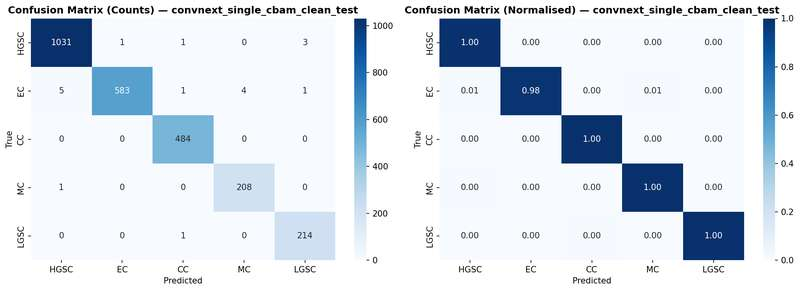

Saved: confusion_convnext_single_cbam_clean_test.png

  ACCURACY COMPARISON — DIRTY vs CLEAN TEST SET
  Val Acc  (all patches)    : 96.27%
  Val Acc  (tissue only)    : 99.29%
  Delta                     : +3.02%
-----------------------------------------------------------------
  Macro F1 (all patches)    : 0.9541
  Macro F1 (tissue only)    : 0.9916
  Delta                     : +0.0375


In [ ]:
# ── Option A: Re-evaluate best model on clean test set ────────────────────────

_clean_test_ds  = OvarianDataset(
    test_paths_clean, test_labels_clean,
    transform  = WINNER_EVL_TF,
    pre_fn     = WINNER_PRE_FN,
    input_size = WINNER_SIZE,
)
_clean_test_ldr = make_loader(
    _clean_test_ds, batch_size=BASE_BATCH // 2, shuffle=False
)

print('Evaluating on clean test set...')
_clean_eval = evaluate(
    BEST_MODEL, _clean_test_ldr,
    BEST_MODEL_CKPT,
    f'{BEST_MODEL_KEY}_clean_test'
)

print('\n' + '=' * 65)
print('  ACCURACY COMPARISON — DIRTY vs CLEAN TEST SET')
print('=' * 65)
print(f'  Val Acc  (all patches)    : '
      f'{RESULTS_ARCH[BEST_MODEL_KEY]["val_acc"]:.2f}%')
print(f'  Val Acc  (tissue only)    : {_clean_eval["val_acc"]:.2f}%')
print(f'  Delta                     : '
      f'{_clean_eval["val_acc"] - RESULTS_ARCH[BEST_MODEL_KEY]["val_acc"]:+.2f}%')
print('-' * 65)
print(f'  Macro F1 (all patches)    : '
      f'{RESULTS_ARCH[BEST_MODEL_KEY]["macro_f1"]:.4f}')
print(f'  Macro F1 (tissue only)    : {_clean_eval["macro_f1"]:.4f}')
print(f'  Delta                     : '
      f'{_clean_eval["macro_f1"] - RESULTS_ARCH[BEST_MODEL_KEY]["macro_f1"]:+.4f}')
print('=' * 65)

del _clean_test_ds, _clean_test_ldr
torch.cuda.empty_cache()

  RE-EVALUATION ON CLEAN TEST SET  (tissue ratio ≥ 0.55)
  Test images : 2538 (from 3082 total, 544 blank removed)

  Loading : vgg16
  vgg16                           Acc: 98.15%  F1: 0.9821

  Loading : resnet50
  resnet50                        Acc: 97.28%  F1: 0.9694

  Loading : densenet121
  densenet121                     Acc: 97.60%  F1: 0.9722

  Loading : efficientnet_b4
  efficientnet_b4                 Acc: 95.31%  F1: 0.9537

  Loading : mobilenetv3
  mobilenetv3                     Acc: 98.15%  F1: 0.9804
  vit_b16                        — checkpoint not found, skipped.
  swin_t                         — checkpoint not found, skipped.

  Loading : deit_s
  deit_s                          Acc: 98.62%  F1: 0.9860
  convnext_vanilla               — checkpoint not found, skipped.

  Loading : convnext_single_cbam
  convnext_single_cbam            Acc: 99.29%  F1: 0.9916

  Loading : convnext_multi_cbam
  convnext_multi_cbam             Acc: 98.78%  F1: 0.9868


  MASTER COMPA

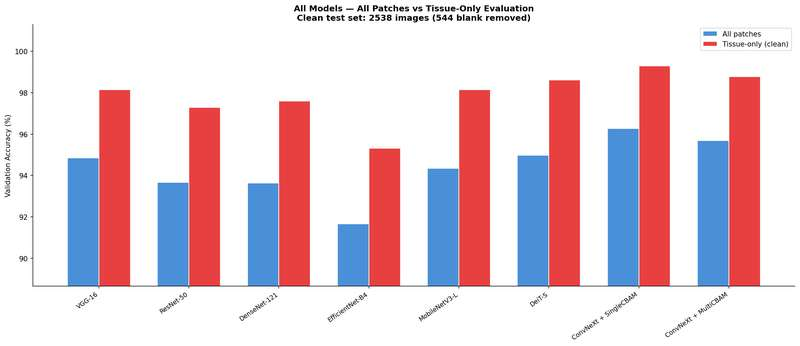

Saved: fig_clean_vs_dirty_comparison.png

  Re-evaluation complete.
  RESULTS_ARCH_CLEAN populated for 8 models.


In [ ]:
# ── Cell: Full Re-evaluation on Clean Test Set ────────────────────────────────
# Loads every saved checkpoint and evaluates on tissue-rich patches only.
# No retraining. Results saved to RESULTS_ARCH_CLEAN.

_all_model_cls = {
    'vgg16'                : VGG16Classifier,
    'resnet50'             : ResNet50Classifier,
    'densenet121'          : DenseNet121Classifier,
    'efficientnet_b4'      : EfficientNetB4Classifier,
    'mobilenetv3'          : MobileNetV3Classifier,
    'vit_b16'              : ViTB16Classifier,
    'swin_t'               : SwinTClassifier,
    'deit_s'               : DeiTSClassifier,
    'convnext_vanilla'     : ConvNeXtVanilla,
    'convnext_single_cbam' : ConvNeXtSingleCBAM,
    'convnext_multi_cbam'  : ConvNeXtMultiCBAM,
}

# ── Clean test loader ─────────────────────────────────────────────────────────
_clean_ds  = OvarianDataset(
    test_paths_clean, test_labels_clean,
    transform  = WINNER_EVL_TF,
    pre_fn     = WINNER_PRE_FN,
    input_size = WINNER_SIZE,
)
_clean_ldr = make_loader(
    _clean_ds, batch_size=BASE_BATCH // 2, shuffle=False
)

RESULTS_ARCH_CLEAN = {}

print('=' * 75)
print('  RE-EVALUATION ON CLEAN TEST SET  (tissue ratio ≥ 0.55)')
print(f'  Test images : {len(test_paths_clean)} '
      f'(from {len(test_paths)} total, '
      f'{len(test_paths)-len(test_paths_clean)} blank removed)')
print('=' * 75)

for key, cls in _all_model_cls.items():

    # Skip if not in RESULTS_ARCH
    if key not in RESULTS_ARCH:
        print(f'  {key:<30} — not in RESULTS_ARCH, skipped.')
        continue

    # Skip if checkpoint missing
    _ckpt = RESULTS_ARCH[key]['ckpt']
    if not Path(str(_ckpt)).exists():
        print(f'  {key:<30} — checkpoint not found, skipped.')
        continue

    print(f'\n  Loading : {key}')
    _m = cls().to(device)
    _m.load_state_dict(torch.load(str(_ckpt), map_location=device))
    _m.eval()

    _all_preds  = []
    _all_labels = []
    _all_probs  = []

    with torch.no_grad():
        for _imgs, _lbls in _clean_ldr:
            _imgs = _imgs.to(device)
            with torch.cuda.amp.autocast():
                _logits = _m(_imgs)
                _probs  = torch.softmax(_logits, dim=1)
                _preds  = _logits.argmax(1)
            _all_preds .extend(_preds.cpu().numpy())
            _all_labels.extend(_lbls.numpy())
            _all_probs .extend(_probs.cpu().numpy())

    _acc      = accuracy_score(_all_labels, _all_preds) * 100
    _macro_f1 = f1_score(_all_labels, _all_preds,
                          average='macro', zero_division=0)
    _per_f1   = f1_score(_all_labels, _all_preds,
                          average=None,   zero_division=0)

    RESULTS_ARCH_CLEAN[key] = {
        'val_acc'      : _acc,
        'macro_f1'     : _macro_f1,
        'per_class_f1' : dict(zip(SUBTYPES, _per_f1)),
        'probs'        : np.array(_all_probs),
        'labels'       : _all_labels,
        'preds'        : _all_preds,
    }

    print(f'  {key:<30}  '
          f'Acc: {_acc:.2f}%  '
          f'F1: {_macro_f1:.4f}')

    del _m
    torch.cuda.empty_cache()

# ── Master comparison table ───────────────────────────────────────────────────
print('\n\n' + '=' * 80)
print('  MASTER COMPARISON — ALL PATCHES vs TISSUE-ONLY')
print('=' * 80)
print(f'  {"Model":<28}  {"Acc (all)":>10}  {"Acc (clean)":>12}  '
      f'{"ΔAcc":>7}  {"F1 (all)":>9}  {"F1 (clean)":>11}  {"ΔF1":>7}')
print('  ' + '-' * 76)

_arch_display = {
    'vgg16'                : 'VGG-16',
    'resnet50'             : 'ResNet-50',
    'densenet121'          : 'DenseNet-121',
    'efficientnet_b4'      : 'EfficientNet-B4',
    'mobilenetv3'          : 'MobileNetV3-L',
    'vit_b16'              : 'ViT-B/16',
    'swin_t'               : 'Swin-T',
    'deit_s'               : 'DeiT-S',
    'convnext_vanilla'     : 'ConvNeXt Vanilla',
    'convnext_single_cbam' : 'ConvNeXt + SingleCBAM',
    'convnext_multi_cbam'  : 'ConvNeXt + MultiCBAM',
}

_rows_clean = []
for key, name in _arch_display.items():
    if key not in RESULTS_ARCH or key not in RESULTS_ARCH_CLEAN:
        continue
    _old_acc = RESULTS_ARCH[key]['val_acc']
    _new_acc = RESULTS_ARCH_CLEAN[key]['val_acc']
    _old_f1  = RESULTS_ARCH[key]['macro_f1']
    _new_f1  = RESULTS_ARCH_CLEAN[key]['macro_f1']
    _rows_clean.append({
        'Model'       : name,
        'Key'         : key,
        'Acc (all)'   : round(_old_acc, 2),
        'Acc (clean)' : round(_new_acc, 2),
        'ΔAcc'        : round(_new_acc - _old_acc, 2),
        'F1 (all)'    : round(_old_f1,  4),
        'F1 (clean)'  : round(_new_f1,  4),
        'ΔF1'         : round(_new_f1 - _old_f1, 4),
    })
    print(f'  {name:<28}  '
          f'{_old_acc:>10.2f}  {_new_acc:>12.2f}  '
          f'{_new_acc - _old_acc:>+7.2f}  '
          f'{_old_f1:>9.4f}  {_new_f1:>11.4f}  '
          f'{_new_f1 - _old_f1:>+7.4f}')

print('=' * 80)

# ── Save to CSV ───────────────────────────────────────────────────────────────
df_clean = pd.DataFrame(_rows_clean).drop(columns=['Key'])
df_clean.to_csv(
    CHECKPOINT_DIR / 'master_results_clean_test.csv', index=False
)
print('Saved: master_results_clean_test.csv')

# ── Bar chart comparison ──────────────────────────────────────────────────────
_names    = [r['Model']       for r in _rows_clean]
_accs_old = [r['Acc (all)']   for r in _rows_clean]
_accs_new = [r['Acc (clean)'] for r in _rows_clean]

x   = np.arange(len(_names))
w   = 0.35
fig, ax = plt.subplots(figsize=(16, 7))

_bars1 = ax.bar(x - w/2, _accs_old, w,
                label='All patches',
                color='#4A90D9', edgecolor='white')
_bars2 = ax.bar(x + w/2, _accs_new, w,
                label='Tissue-only (clean)',
                color='#E84040', edgecolor='white')

ax.set_xticks(x)
ax.set_xticklabels(_names, rotation=35, ha='right', fontsize=9)
ax.set_ylabel('Validation Accuracy (%)')
ax.set_title(
    'All Models — All Patches vs Tissue-Only Evaluation\n'
    f'Clean test set: {len(test_paths_clean)} images '
    f'({len(test_paths)-len(test_paths_clean)} blank removed)',
    fontsize=12, fontweight='bold'
)
ax.legend(fontsize=10)
ax.set_ylim(
    min(_accs_old) - 3,
    max(_accs_new) + 2
)
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.savefig(CHECKPOINT_DIR / 'fig_clean_vs_dirty_comparison.png',
            bbox_inches='tight', dpi=150)
plt.show()
print('Saved: fig_clean_vs_dirty_comparison.png')

del _clean_ds, _clean_ldr
torch.cuda.empty_cache()
print('\n  Re-evaluation complete.')
print(f'  RESULTS_ARCH_CLEAN populated for '
      f'{len(RESULTS_ARCH_CLEAN)} models.')

In [ ]:
# ── Recompute Eff-Num weights from clean train counts ─────────────────────────

_beta          = 0.9999
_samples_clean = np.array(TRAIN_COUNTS_CLEAN, dtype=float)
_eff_num_clean = 1.0 - np.power(_beta, _samples_clean)
_weights_clean = (1.0 - _beta) / _eff_num_clean
_weights_clean = _weights_clean / _weights_clean.sum() * NUM_CLASSES

EFF_NUM_WEIGHTS_CLEAN = torch.FloatTensor(_weights_clean).to(device)

WINNER_CRITERION_CLEAN = nn.CrossEntropyLoss(
    weight=EFF_NUM_WEIGHTS_CLEAN, label_smoothing=0.1
)

print('=' * 55)
print('  EFF-NUM WEIGHTS — CLEAN TRAIN SET')
print('=' * 55)
for sub, w in zip(SUBTYPES, _weights_clean):
    print(f'  {sub:<6} : {w:.4f}')
print('=' * 55)
print('  WINNER_CRITERION_CLEAN ready.')

  EFF-NUM WEIGHTS — CLEAN TRAIN SET
  HGSC   : 0.4625
  EC     : 0.6537
  CC     : 0.7847
  MC     : 1.5087
  LGSC   : 1.5903
  WINNER_CRITERION_CLEAN ready.


  MULTI-SEED EVALUATION — convnext_single_cbam
  Seeds      : [42, 123, 7]
  Train set  : clean (25835 images)
  Test set   : clean (2538 images)

... [epoch-by-epoch training log truncated for GitHub] ...

  Ep  39/100 | Loss:0.5141 | Train:99.15% | Val:97.64% | LR:7.65e-04 | Best:98.35% | No improve: 1/10 | 57.9s
  Ep  40/100 | Loss:0.5135 | Train:99.18% | Val:97.44% | LR:7.50e-04 | Best:98.35% | No improve: 2/10 | 57.7s
  Ep  41/100 | Loss:0.5140 | Train:99.13% | Val:97.87% | LR:7.35e-04 | Best:98.35% | No improve: 3/10 | 57.7s
  Ep  42/100 | Loss:0.5119 | Train:99.16% | Val:98.38% | LR:7.19e-04 | Best:98.38% | 58.6s
  Ep  43/100 | Loss:0.5092 | Train:99.33% | Val:98.19% | LR:7.03e-04 | Best:98.38% | No improve: 1/10 | 58.3s
  Ep  44/100 | Loss:0.5083 | Train:99.33% | Val:98.23% | LR:6.87e-04 | Best:98.38% | No improve: 2/10 | 57.6s
  Ep  45/100 | Loss:0.5079 | Train:99.43% | Val:98.15% | LR:6.71e-04 | Best:98.38% | No improve: 3/10 | 57.8s
  Ep  46/100 | Loss:0.5096 | Train:99.28% 

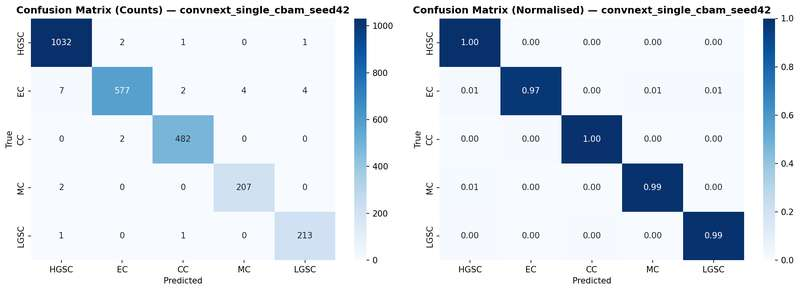

Saved: confusion_convnext_single_cbam_seed42.png

  ── Seed 123 ──

  convnext_single_cbam_seed123  |  100 ep  |  88.8M params

... [epoch-by-epoch training log truncated for GitHub] ...

  Ep  59/100 | Loss:0.5010 | Train:99.71% | Val:98.58% | LR:4.30e-04 | Best:98.66% | No improve: 5/10 | 58.4s
  Ep  60/100 | Loss:0.5011 | Train:99.71% | Val:98.27% | LR:4.13e-04 | Best:98.66% | No improve: 6/10 | 58.2s
  Ep  61/100 | Loss:0.4983 | Train:99.75% | Val:98.78% | LR:3.96e-04 | Best:98.78% | 59.1s
  Ep  62/100 | Loss:0.4991 | Train:99.74% | Val:98.66% | LR:3.79e-04 | Best:98.78% | No improve: 1/10 | 58.3s
  Ep  63/100 | Loss:0.4970 | Train:99.87% | Val:98.62% | LR:3.62e-04 | Best:98.78% | No improve: 2/10 | 58.2s
  Ep  64/100 | Loss:0.4969 | Train:99.84% | Val:99.01% | LR:3.45e-04 | Best:99.01% | 58.9s
  Ep  65/100 | Loss:0.4991 | Train:99.75% | Val:98.54% | LR:3.29e-04 | Best:99.01% | No improve: 1/10 | 58.2s
  Ep  66/100 | Loss:0.4974 | Train:99.84% | Val:98.50% | LR:3.13e-04 | Best:99.0

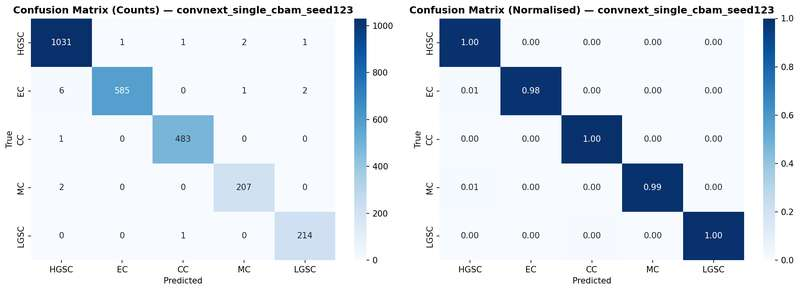

Saved: confusion_convnext_single_cbam_seed123.png

  ── Seed 7 ──

  convnext_single_cbam_seed7  |  100 ep  |  88.8M params
  Criterion : CrossEntropyLoss
  Train     : 25835  |  Test : 2538
  Ep   1/100 | Loss:1.3945 | Train:49.12% | Val:62.88% | LR:6.35e-05 | Best:62.88% | 60.3s
  Ep   2/100 | Loss:1.1156 | Train:65.27% | Val:77.46% | LR:1.32e-04 | Best:77.46% | 59.4s
  Ep   3/100 | Loss:0.9507 | Train:75.41% | Val:81.80% | LR:2.38e-04 | Best:81.80% | 58.7s
  Ep   4/100 | Loss:0.8429 | Train:81.75% | Val:84.32% | LR:3.72e-04 | Best:84.32% | 58.6s
  Ep   5/100 | Loss:0.7751 | Train:85.62% | Val:90.23% | LR:5.20e-04 | Best:90.23% | 58.7s
  Ep   6/100 | Loss:0.7250 | Train:88.04% | Val:92.08% | LR:6.69e-04 | Best:92.08% | 58.7s
  Ep   7/100 | Loss:0.6857 | Train:90.45% | Val:92.16% | LR:8.02e-04 | Best:92.16% | 58.6s
  Ep   8/100 | Loss:0.6535 | Train:91.79% | Val:89.91% | LR:9.09e-04 | Best:92.16% | No improve: 1/10 | 58.1s
  Ep   9/100 | Loss:0.6360 | Train:92.70% | Val:94.92% | LR:9.

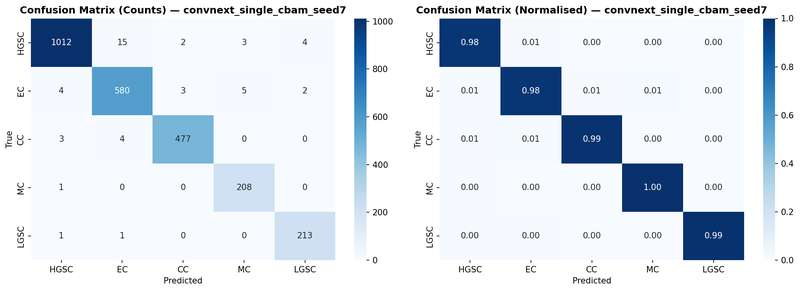

Saved: confusion_convnext_single_cbam_seed7.png

  MULTI-SEED RESULTS  (clean test set)
  Seed       Val Acc (%)    Macro F1
  ----------------------------------------
  42               98.94      0.9878
  123              99.29      0.9921
  7                98.11      0.9807
  ----------------------------------------
  Mean             98.78      0.9868
  Std               0.50      0.0047
  95% CI    ±      0.97  ±  0.0092


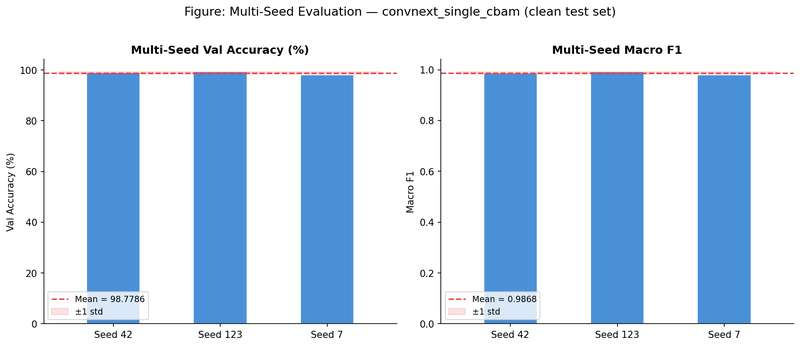

Saved: fig_multiseed.png

  Cell 63 complete.


In [ ]:
# ── Cell 63: Multi-Seed Evaluation (Clean Data) ───────────────────────────────

EVAL_SEEDS    = [42, 123, 7]
_seed_results = []

print('=' * 65)
print(f'  MULTI-SEED EVALUATION — {BEST_MODEL_KEY}')
print('=' * 65)
print(f'  Seeds      : {EVAL_SEEDS}')
print(f'  Train set  : clean ({len(train_paths_clean)} images)')
print(f'  Test set   : clean ({len(test_paths_clean)} images)')
print(f'  Epochs     : {EPOCHS}  |  Patience : {PATIENCE}')
print('=' * 65)

for _seed in EVAL_SEEDS:
    print(f'\n  ── Seed {_seed} ──')

    random.seed(_seed)
    np.random.seed(_seed)
    torch.manual_seed(_seed)
    torch.cuda.manual_seed_all(_seed)

    _model_seed = BEST_MODEL_CLS().to(device)

    _train_ds_seed = OvarianDataset(
        train_paths_clean, train_labels_clean,
        transform  = make_transforms(WINNER_SIZE)[0],
        pre_fn     = WINNER_PRE_FN,
        input_size = WINNER_SIZE,
    )
    _test_ds_seed = OvarianDataset(
        test_paths_clean, test_labels_clean,
        transform  = WINNER_EVL_TF,
        pre_fn     = WINNER_PRE_FN,
        input_size = WINNER_SIZE,
    )

    _sampler_seed = (
        make_weighted_sampler(train_labels_clean)
        if WINNER_USE_ROS else None
    )
    _batch_seed   = BASE_BATCH if WINNER_SIZE < 384 else BASE_BATCH // 2

    _train_ldr_seed = make_loader(
        _train_ds_seed, batch_size=_batch_seed,
        sampler=_sampler_seed
    )
    _test_ldr_seed  = make_loader(
        _test_ds_seed, batch_size=_batch_seed, shuffle=False
    )

    _result = train_model(
        model        = _model_seed,
        train_loader = _train_ldr_seed,
        test_loader  = _test_ldr_seed,
        epochs       = EPOCHS,
        label        = f'{BEST_MODEL_KEY}_seed{_seed}',
        criterion    = WINNER_CRITERION_CLEAN,
        backbone_lr  = 2e-5,
        head_lr      = 2e-4,
        patience     = PATIENCE,
    )

    _eval = evaluate(
        _model_seed, _test_ldr_seed,
        _result['ckpt'],
        f'{BEST_MODEL_KEY}_seed{_seed}'
    )
    _result.update(_eval)
    _seed_results.append(_result)

    del _model_seed
    del _train_ds_seed, _test_ds_seed
    del _train_ldr_seed, _test_ldr_seed
    torch.cuda.empty_cache()

# Restore main seed
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

_accs = [r['val_acc']  for r in _seed_results]
_f1s  = [r['macro_f1'] for r in _seed_results]

print('\n' + '=' * 65)
print('  MULTI-SEED RESULTS  (clean test set)')
print('=' * 65)
print(f'  {"Seed":<8}  {"Val Acc (%)":>12}  {"Macro F1":>10}')
print('  ' + '-' * 40)
for _seed, r in zip(EVAL_SEEDS, _seed_results):
    print(f'  {_seed:<8}  {r["val_acc"]:>12.2f}  {r["macro_f1"]:>10.4f}')
print('  ' + '-' * 40)
print(f'  {"Mean":<8}  {np.mean(_accs):>12.2f}  {np.mean(_f1s):>10.4f}')
print(f'  {"Std":<8}  {np.std(_accs):>12.2f}  {np.std(_f1s):>10.4f}')
print(f'  {"95% CI":<8}  '
      f'±{1.96 * np.std(_accs):>10.2f}  '
      f'±{1.96 * np.std(_f1s):>8.4f}')
print('=' * 65)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, vals, metric in zip(
    axes,
    [_accs, _f1s],
    ['Val Accuracy (%)', 'Macro F1']
):
    ax.bar(
        [f'Seed {s}' for s in EVAL_SEEDS],
        vals, color='#4A90D9', edgecolor='white', width=0.5
    )
    ax.axhline(np.mean(vals), color='#E84040', linestyle='--',
               linewidth=1.5, label=f'Mean = {np.mean(vals):.4f}')
    ax.fill_between(
        [-0.5, len(EVAL_SEEDS) - 0.5],
        np.mean(vals) - np.std(vals),
        np.mean(vals) + np.std(vals),
        alpha=0.15, color='#E84040', label='±1 std'
    )
    ax.set_ylabel(metric)
    ax.set_title(f'Multi-Seed {metric}', fontsize=12, fontweight='bold')
    ax.legend(fontsize=9)
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)

plt.suptitle(
    f'Figure: Multi-Seed Evaluation — {BEST_MODEL_KEY} (clean test set)',
    fontsize=13, y=1.02
)
plt.tight_layout()
plt.savefig(CHECKPOINT_DIR / 'fig_multiseed.png',
            bbox_inches='tight', dpi=150)
plt.show()
print('Saved: fig_multiseed.png')
print('\n  Cell 63 complete.')

  5-FOLD STRATIFIED CV — convnext_single_cbam
  Total images : 28373  (tissue-rich only)
  Folds        : 5
  Criterion    : CrossEntropyLoss

... [epoch-by-epoch training log truncated for GitHub] ...

  Ep  61/100 | Loss:0.5005 | Train:99.73% | Val:98.38% | LR:3.96e-04 | Best:98.70% | No improve: 2/10 | 53.4s
  Ep  62/100 | Loss:0.4997 | Train:99.78% | Val:98.73% | LR:3.79e-04 | Best:98.73% | 54.0s
  Ep  63/100 | Loss:0.4984 | Train:99.78% | Val:98.56% | LR:3.62e-04 | Best:98.73% | No improve: 1/10 | 53.6s
  Ep  64/100 | Loss:0.4981 | Train:99.79% | Val:98.19% | LR:3.45e-04 | Best:98.73% | No improve: 2/10 | 53.4s
  Ep  65/100 | Loss:0.4985 | Train:99.79% | Val:98.52% | LR:3.29e-04 | Best:98.73% | No improve: 3/10 | 53.5s
  Ep  66/100 | Loss:0.4973 | Train:99.88% | Val:98.75% | LR:3.13e-04 | Best:98.75% | 54.2s
  Ep  67/100 | Loss:0.4977 | Train:99.85% | Val:98.59% | LR:2.97e-04 | Best:98.75% | No improve: 1/10 | 53.5s
  Ep  68/100 | Loss:0.4985 | Train:99.81% | Val:98.38% | LR:2.81e

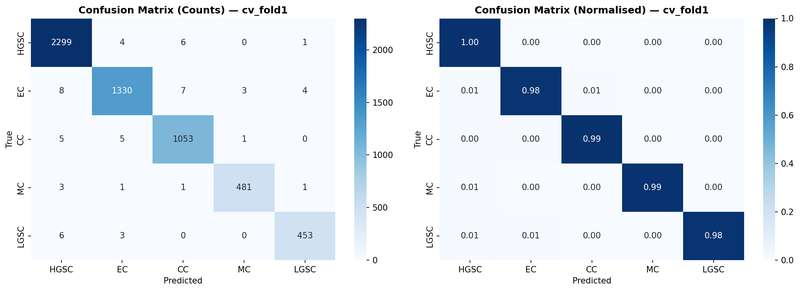

Saved: confusion_cv_fold1.png

  ── Fold 2/5 ──
  Train: 22698  |  Val: 5675


... [epoch-by-epoch training log truncated for GitHub] ...

  Ep  27/100 | Loss:0.5311 | Train:98.32% | Val:97.00% | LR:9.14e-04 | Best:97.60% | No improve: 4/10 | 53.0s
  Ep  28/100 | Loss:0.5312 | Train:98.27% | Val:96.93% | LR:9.04e-04 | Best:97.60% | No improve: 5/10 | 53.3s
  Ep  29/100 | Loss:0.5265 | Train:98.58% | Val:96.81% | LR:8.94e-04 | Best:97.60% | No improve: 6/10 | 53.2s
  Ep  30/100 | Loss:0.5276 | Train:98.49% | Val:96.78% | LR:8.83e-04 | Best:97.60% | No improve: 7/10 | 53.4s
  Ep  31/100 | Loss:0.5266 | Train:98.58% | Val:97.69% | LR:8.72e-04 | Best:97.69% | 54.1s
  Ep  32/100 | Loss:0.5234 | Train:98.63% | Val:97.67% | LR:8.60e-04 | Best:97.69% | No improve: 1/10 | 53.5s
  Ep  33/100 | Loss:0.5207 | Train:98.74% | Val:97.99% | LR:8.47e-04 | Best:97.99% | 54.5s
  Ep  34/100 | Loss:0.5185 | Train:98.89% | Val:97.66% | LR:8.35e-04 | Best:97.99% | No improve: 1/10 | 53.1s
  Ep  35/100 | Loss

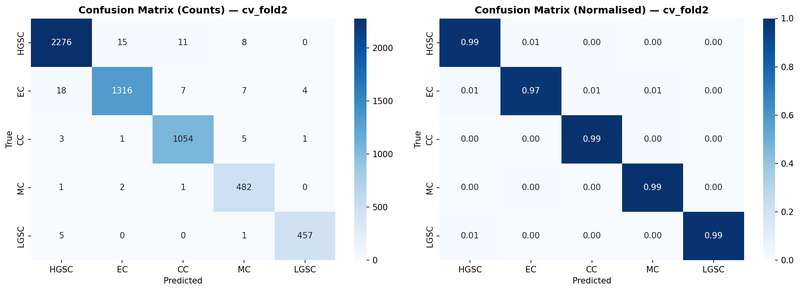

Saved: confusion_cv_fold2.png

  ── Fold 3/5 ──
  Train: 22698  |  Val: 5675

  cv_fold3  |  100 ep  |  88.8M params
  Criterion : CrossEntropyLoss
  Train     : 22698  |  Test : 5675
  Ep   1/100 | Loss:1.4152 | Train:47.76% | Val:59.31% | LR:6.35e-05 | Best:59.31% | 55.5s
  Ep   2/100 | Loss:1.1361 | Train:64.50% | Val:72.60% | LR:1.32e-04 | Best:72.60% | 54.1s
  Ep   3/100 | Loss:0.9775 | Train:73.60% | Val:79.61% | LR:2.38e-04 | Best:79.61% | 54.3s
  Ep   4/100 | Loss:0.8680 | Train:80.48% | Val:83.65% | LR:3.72e-04 | Best:83.65% | 54.1s
  Ep   5/100 | Loss:0.7933 | Train:84.52% | Val:87.95% | LR:5.20e-04 | Best:87.95% | 54.3s
  Ep   6/100 | Loss:0.7416 | Train:87.59% | Val:92.02% | LR:6.69e-04 | Best:92.02% | 54.3s
  Ep   7/100 | Loss:0.6974 | Train:89.74% | Val:91.95% | LR:8.02e-04 | Best:92.02% | No improve: 1/10 | 53.8s
  Ep   8/100 | Loss:0.6655 | Train:91.30% | Val:92.79% | LR:9.09e-04 | Best:92.79% | 53.8s
  Ep   9/100 | Loss:0.6434 | Train:92.45% | Val:92.04% | LR:9.77e-04 

In [ ]:
# ── Cell 64: 5-Fold Stratified Cross-Validation (Clean Data) ──────────────────

from sklearn.model_selection import StratifiedKFold

N_FOLDS        = 5
_skf           = StratifiedKFold(n_splits=N_FOLDS, shuffle=True,
                                  random_state=SEED)
_all_paths_cv  = np.array(train_paths_clean + test_paths_clean)
_all_labels_cv = np.array(train_labels_clean + test_labels_clean)
_cv_results    = []

print('=' * 65)
print(f'  5-FOLD STRATIFIED CV — {BEST_MODEL_KEY}')
print('=' * 65)
print(f'  Total images : {len(_all_paths_cv)}  (tissue-rich only)')
print(f'  Folds        : {N_FOLDS}')
print(f'  Criterion    : {WINNER_CRITERION_CLEAN.__class__.__name__}')
print('=' * 65)

for fold_idx, (train_idx, val_idx) in enumerate(
    _skf.split(_all_paths_cv, _all_labels_cv), start=1
):
    print(f'\n  ── Fold {fold_idx}/{N_FOLDS} ──')
    print(f'  Train: {len(train_idx)}  |  Val: {len(val_idx)}')

    _fold_train_paths  = list(_all_paths_cv[train_idx])
    _fold_train_labels = list(_all_labels_cv[train_idx])
    _fold_val_paths    = list(_all_paths_cv[val_idx])
    _fold_val_labels   = list(_all_labels_cv[val_idx])

    _fold_train_ds = OvarianDataset(
        _fold_train_paths, _fold_train_labels,
        transform  = make_transforms(WINNER_SIZE)[0],
        pre_fn     = WINNER_PRE_FN,
        input_size = WINNER_SIZE,
    )
    _fold_val_ds = OvarianDataset(
        _fold_val_paths, _fold_val_labels,
        transform  = WINNER_EVL_TF,
        pre_fn     = WINNER_PRE_FN,
        input_size = WINNER_SIZE,
    )

    _fold_sampler = (
        make_weighted_sampler(_fold_train_labels)
        if WINNER_USE_ROS else None
    )
    _fold_batch   = BASE_BATCH if WINNER_SIZE < 384 else BASE_BATCH // 2

    _fold_train_ldr = make_loader(
        _fold_train_ds, batch_size=_fold_batch,
        sampler=_fold_sampler
    )
    _fold_val_ldr   = make_loader(
        _fold_val_ds, batch_size=_fold_batch, shuffle=False
    )

    _fold_model = BEST_MODEL_CLS().to(device)
    _fold_res   = train_model(
        model        = _fold_model,
        train_loader = _fold_train_ldr,
        test_loader  = _fold_val_ldr,
        epochs       = EPOCHS,
        label        = f'cv_fold{fold_idx}',
        criterion    = WINNER_CRITERION_CLEAN,
        backbone_lr  = 2e-5,
        head_lr      = 2e-4,
        patience     = PATIENCE,
    )

    _fold_eval = evaluate(
        _fold_model, _fold_val_ldr,
        _fold_res['ckpt'],
        f'cv_fold{fold_idx}'
    )
    _fold_res.update(_fold_eval)
    _cv_results.append(_fold_res)

    del _fold_model, _fold_train_ds, _fold_val_ds
    del _fold_train_ldr, _fold_val_ldr
    torch.cuda.empty_cache()

_cv_accs = [r['val_acc']  for r in _cv_results]
_cv_f1s  = [r['macro_f1'] for r in _cv_results]

print('\n' + '=' * 65)
print('  5-FOLD CV RESULTS  (clean test set)')
print('=' * 65)
print(f'  {"Fold":<8}  {"Val Acc (%)":>12}  {"Macro F1":>10}')
print('  ' + '-' * 40)
for i, r in enumerate(_cv_results, 1):
    print(f'  {i:<8}  {r["val_acc"]:>12.2f}  {r["macro_f1"]:>10.4f}')
print('  ' + '-' * 40)
print(f'  {"Mean":<8}  {np.mean(_cv_accs):>12.2f}  {np.mean(_cv_f1s):>10.4f}')
print(f'  {"Std":<8}  {np.std(_cv_accs):>12.2f}  {np.std(_cv_f1s):>10.4f}')
print(f'  {"95% CI":<8}  '
      f'±{1.96 * np.std(_cv_accs) / np.sqrt(N_FOLDS):>8.2f}  '
      f'±{1.96 * np.std(_cv_f1s)  / np.sqrt(N_FOLDS):>6.4f}')
print('=' * 65)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, vals, metric in zip(
    axes,
    [_cv_accs, _cv_f1s],
    ['Val Accuracy (%)', 'Macro F1']
):
    ax.bar(
        [f'Fold {i}' for i in range(1, N_FOLDS + 1)],
        vals, color='#50C878', edgecolor='white', width=0.5
    )
    ax.axhline(np.mean(vals), color='#E84040', linestyle='--',
               linewidth=1.5, label=f'Mean = {np.mean(vals):.4f}')
    ax.fill_between(
        [-0.5, N_FOLDS - 0.5],
        np.mean(vals) - np.std(vals),
        np.mean(vals) + np.std(vals),
        alpha=0.15, color='#E84040', label='±1 std'
    )
    ax.set_ylabel(metric)
    ax.set_title(f'5-Fold CV — {metric}',
                 fontsize=12, fontweight='bold')
    ax.legend(fontsize=9)
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)

plt.suptitle(
    f'Figure: 5-Fold Stratified CV — {BEST_MODEL_KEY} (clean data)',
    fontsize=13, y=1.02
)
plt.tight_layout()
plt.savefig(CHECKPOINT_DIR / 'fig_cv_results.png',
            bbox_inches='tight', dpi=150)
plt.show()
print('Saved: fig_cv_results.png')
print('\n  Cell 64 complete.')